# MLB Statcast: Comprehensive Baseball Analytics & Predictive Modeling

*A reproducible, sample-window study of pitching, hitting, pitch selection, and predictive reliability (2015–2026).*

**Observed populations:** August 10–16 in each year from 2015 through 2026 (332,598 historical pitches), plus a separate May 1–14 analysis for 2024 and 2025 (109,346 pitches). These are sampled weeks, **not full MLB seasons**.

**Validation status:** Model comparisons using 2025 and 2026 were consulted during prior development cycles and are reported as retrospective/exploratory evaluations, not untouched tests. Measured release, trajectory, and plate-location inputs are not fully known before a pitch is thrown.

**Submission materials:** The HTML research report is the primary narrative; this fully executed notebook is the technical evidence and reproducible analytical appendix.

## Research roadmap

The technical analyses are organized into six divisions. The companion report selects the strongest figures and findings rather than reproducing every subgroup table.

| Division | Focus | Evidence |
|---|---|---|
| I — Pitch data and physics | Eligibility, data quality, repertoire | Coverage, pitch movement and Whiff rates |
| II — Hitting and game context | Plate discipline, BBE, situations | Chase, contact, hard-hit, count and sequence |
| III — Predictive research | Algorithms, calibration and uncertainty | Brier, PR-AUC, baseline and subgroup diagnostics |
| IV — Historical study | 2015–2026 annual observation windows | Pitch and hitter trends, longitudinal samples |
| V — Longitudinal modeling | Drift, ablation, robustness | Time-ordered validation, exploratory 2026 results |
| VI — Final research audit | Denominator and calibration checks | Executed evidence ledger and sensitivity analysis |

**Evidence rule:** Report each result with its sampling window, eligible denominator, and uncertainty where appropriate.


**Reproducibility:** This copy includes the user's complete executed notebook results. Re-running requires the accompanying `src/pipeline.py`, requirements, and network access or previously cached Statcast downloads. Historical analysis functions are embedded in the notebook; the early analyses rely on the `src` module. Local output paths are resolved from the selected project root.


### Study design and limitations

The historical comparisons use August 10–16 for each of 2015–2026; the earlier detailed analysis uses May 1–14 of 2024 and 2025. All quoted performance values refer to these observation windows, not full seasons. The 2025 and 2026 results have been inspected during earlier iterations and are **retrospective evaluations**, not untouched prospective tests. Post-release inputs support descriptive probability models but not a pre-release tactical recommendation engine.

The HTML manuscript is the primary submission narrative; this executed notebook documents the complete analytical methods and supporting evidence.


## 1 | Data, Sampling, and Reproducibility
**Research question:** What exactly is observed and measured? Confirm event denominators and compare raw and cleaned coverage before evaluating any baseball performance indicator.

In [1]:
from pathlib import Path
import os
import sys

WINDOWS_PROJECT_ROOT = Path(r"I:\Potforlio\MLB Analytics")
candidates = [
    WINDOWS_PROJECT_ROOT,
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent,
    Path.cwd() / "MLB_Statcast_Submission_Reviewed_Final",
    Path.cwd().parent / "MLB_Statcast_Submission_Reviewed_Final",
]
ROOT = next((p.resolve() for p in candidates if (p / "src" / "pipeline.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError(
        "Cannot find src/pipeline.py. Extract the complete project ZIP, then open "
        "the project root in VS Code; do not run a copied notebook alone."
    )
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)


Project root: I:\Potforlio\MLB Analytics


In [2]:
%pip install -q numpy pandas matplotlib seaborn scipy scikit-learn statsmodels pybaseball pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from IPython.display import display, Image
from src.pipeline import download, clean, sequencing
sns.set_theme(style='whitegrid')
RANDOM_STATE=42; SAMPLE_MODE=True; MIN_N=100; MIN_SWINGS=30
FIGDIR=ROOT/'outputs'/'submission_figures'; FIGDIR.mkdir(parents=True,exist_ok=True)
REPORTDIR=ROOT/'outputs'/'submission_tables'; REPORTDIR.mkdir(parents=True,exist_ok=True)
def publish(fig, name):
    path=FIGDIR/f'{name}.png'; fig.savefig(path,dpi=180,bbox_inches='tight')
    display(Image(filename=str(path)))
    plt.close(fig)
    return path
print('Figure output:',FIGDIR)

Figure output: I:\Potforlio\MLB Analytics\outputs\submission_figures


In [4]:
RANGES = ({2024:('2024-05-01','2024-05-14'),2025:('2025-05-01','2025-05-14')} if SAMPLE_MODE else {2024:('2024-03-20','2024-09-30'),2025:('2025-03-18','2025-09-29')})
raw=pd.concat([download(start,end) for start,end in RANGES.values()],ignore_index=True)
df=clean(raw).copy()
df['game_date']=pd.to_datetime(df['game_date'])
if 'season' not in df: df['season']=df['game_date'].dt.year
assert set([2024,2025]).issubset(set(df.season.dropna().astype(int)))
print(f'Pitches: {len(df):,} | Games: {df.game_pk.nunique():,} | Pitchers: {df.pitcher.nunique():,} | Batters: {df.batter.nunique():,}')

Pitches: 109,346 | Games: 376 | Pitchers: 640 | Batters: 563


In [5]:
key=['game_pk','at_bat_number','pitch_number']
assert not df.duplicated(key).any(), 'Duplicate pitch keys'
required=['pitch_type','pitcher','batter','stand','p_throws','balls','strikes','plate_x','plate_z','release_speed']
missing=[col for col in required if col not in df]
assert not missing, f'Missing required fields: {missing}'
quality=pd.DataFrame({'missing_pct':df.isna().mean().mul(100),'non_null':df.notna().sum()}).sort_values('missing_pct',ascending=False)
display(quality.head(25))
coverage=df.groupby('season').agg(pitches=('game_pk','size'),games=('game_pk','nunique'),pitchers=('pitcher','nunique'),batters=('batter','nunique'),first_date=('game_date','min'),last_date=('game_date','max'))
display(coverage);coverage.to_csv(REPORTDIR/'coverage.csv')

,missing_pct,non_null
spin_rate_deprecated,100.000000,0
break_angle_deprecated,100.000000,0
spin_dir,100.000000,0
break_length_deprecated,100.000000,0
umpire,100.000000,0
tfs_zulu_deprecated,100.000000,0
tfs_deprecated,100.000000,0
sv_id,100.000000,0
on_3b,90.860205,9994
miss_distance,89.624678,11345


,pitches,games,pitchers,batters,first_date,last_date
season,,,,,,
2024,54000,186,451,433,2024-05-01,2024-05-14
2025,55346,190,457,433,2025-05-01,2025-05-14


In [6]:
def pick_field(*choices):
    return next((x for x in choices if x in df.columns), None)
for new, source in [('swing_ind', 'swing'), ('whiff_ind', 'whiff')]:
    if source not in df:
        raise KeyError(f'Missing required pipeline field: {source}')
    df[new] = pd.to_numeric(df[source], errors='coerce')
if 'csw' in df:
    df['csw_ind'] = pd.to_numeric(df['csw'], errors='coerce')
if 'zone' in df.columns:
    z = pd.to_numeric(df['zone'], errors='coerce')
    df['zone_known'] = z.notna()
    df['in_zone'] = z.between(1, 9)
else:
    top = pd.to_numeric(df['sz_top'], errors='coerce') if 'sz_top' in df else pd.Series(3.5, index=df.index)
    bottom = pd.to_numeric(df['sz_bot'], errors='coerce') if 'sz_bot' in df else pd.Series(1.5, index=df.index)
    x = pd.to_numeric(df['plate_x'], errors='coerce')
    y = pd.to_numeric(df['plate_z'], errors='coerce')
    df['zone_known'] = x.notna() & y.notna() & top.notna() & bottom.notna()
    df['in_zone'] = x.abs().le(0.83) & y.ge(bottom) & y.le(top)
df['chase_event'] = (df['zone_known'] & ~df['in_zone'] & df['swing_ind'].eq(1)).astype(int)
df['contact_event'] = (df['swing_ind'].eq(1) & df['whiff_ind'].eq(0)).astype(int)
df['count_state'] = df['balls'].astype('Int64').astype(str) + '-' + df['strikes'].astype('Int64').astype(str)
for a, b in [('release_speed', 'velocity'), ('release_spin_rate', 'spin'),
             ('launch_speed', 'exit_velocity'), ('launch_angle', 'launch_angle_clean')]:
    if a in df:
        df[b] = pd.to_numeric(df[a], errors='coerce')
        df[a] = df[b]
if 'type' not in df:
    raise KeyError('Statcast type (X = ball in play) must be retained in cleaned data for official BBE analyses')
df['is_bbe'] = df['type'].eq('X')
df['hard_hit'] = (df['launch_speed'].ge(95) & df['is_bbe']).where(df['is_bbe'] & df['launch_speed'].notna())
assert (df['whiff_ind'].fillna(0) <= df['swing_ind'].fillna(0)).all()
print('Zone records available:', int(df['zone_known'].sum()), '/', len(df))
print('Tracked in-play BBE:', int(df['hard_hit'].notna().sum()))


Zone records available: 109346 / 109346
Tracked in-play BBE: 19288


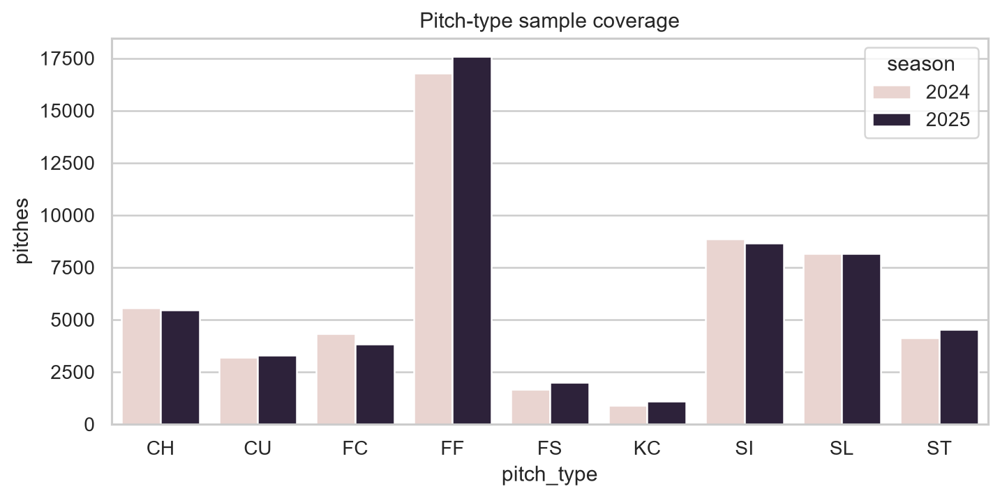

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/01_pitch_coverage.png')

In [7]:
fig,ax=plt.subplots(figsize=(9,4));x=df.groupby(['season','pitch_type']).size().rename('pitches').reset_index();top=df.pitch_type.value_counts().head(9).index
sns.barplot(data=x[x.pitch_type.isin(top)],x='pitch_type',y='pitches',hue='season',ax=ax);ax.set_title('Pitch-type sample coverage');publish(fig,'01_pitch_coverage')

### Data completeness audit | Raw versus cleaned pitch records

This is a **data-quality check**, not a baseball performance chart. For `launch_speed`, availability is reported specifically for balls in play rather than for all pitches. Cleaning can change completeness, so the audit shows both source and cleaned frames.

In [8]:
fields = ['release_speed', 'release_spin_rate', 'plate_x', 'plate_z']
quality_rows = []
for stage, frame in [('raw', raw), ('clean', df)]:
    for field in fields:
        if field in frame:
            quality_rows.append({
                'dataset': stage, 'field': field,
                'n_eligible': len(frame), 'n_observed': int(frame[field].notna().sum()),
                'coverage_pct': round(100 * frame[field].notna().mean(), 2)
            })
    if {'type', 'launch_speed'}.issubset(frame.columns):
        bbe_source = frame.loc[frame['type'].eq('X')]
        quality_rows.append({
            'dataset': stage, 'field': 'launch_speed | in-play BBE',
            'n_eligible': len(bbe_source),
            'n_observed': int(bbe_source['launch_speed'].notna().sum()),
            'coverage_pct': round(100 * bbe_source['launch_speed'].notna().mean(), 2) if len(bbe_source) else np.nan
        })
completeness = pd.DataFrame(quality_rows)
display(completeness)
completeness.to_csv(REPORTDIR / 'raw_clean_completeness.csv', index=False)


,dataset,field,n_eligible,n_observed,coverage_pct
0,raw,release_speed,109692,109359,99.70
1,raw,release_spin_rate,109692,109296,99.64
2,raw,plate_x,109692,109346,99.68
3,raw,plate_z,109692,109346,99.68
4,raw,launch_speed | in-play BBE,19348,19288,99.69
5,clean,release_speed,109346,109332,99.99
6,clean,release_spin_rate,109346,109285,99.94
7,clean,plate_x,109346,109346,100.00
8,clean,plate_z,109346,109346,100.00
9,clean,launch_speed | in-play BBE,19348,19288,99.69


**Quality gate:** If a physical field is fully observed after cleaning, a 100% bar chart contains no useful comparison and is intentionally omitted. `launch_speed` completeness uses in-play BBE as the denominator. For all pitch outcomes, use the original sample definition and document any filters.

**Interpretation checklist:** compare coverage before interpreting rates. The two-week default sample is for debugging, not seasonal rankings.

## 2 | Pitch Design & Effectiveness
**Question:** how do velocity, spin, movement, location, and repertoire relate to observed outcomes? Comparison is descriptive, not causal.

In [9]:
def rates(g):
    swings = float(g.swing_ind.sum())
    n = len(g)
    whiffs = float(g.whiff_ind.sum())
    out = g.loc[g.zone_known & ~g.in_zone]
    return pd.Series({
        'pitches': n, 'swings': swings, 'whiffs': whiffs,
        'whiff_per_swing': whiffs / swings if swings else np.nan,
        'swing_rate': swings / n if n else np.nan,
        'chase_rate': out.swing_ind.mean() if len(out) else np.nan,
        'contact_rate': 1 - whiffs / swings if swings else np.nan,
        'velocity': g.velocity.mean() if 'velocity' in g else np.nan,
        'spin': g.spin.mean() if 'spin' in g else np.nan
    })
pitch_rates = df.groupby(['season', 'pitch_type']).apply(rates, include_groups=False).reset_index()
display(pitch_rates.query('pitches >= @MIN_N').round(3).head(25))
pitch_rates.to_csv(REPORTDIR / 'pitch_rates.csv', index=False)


,season,pitch_type,pitches,swings,whiffs,whiff_per_swing,swing_rate,chase_rate,contact_rate,velocity,spin
0,2024,CH,5558.0,2764.0,742.0,0.268,0.497,0.330,0.732,85.506,1782.086
2,2024,CU,3201.0,1343.0,361.0,0.269,0.420,0.293,0.731,79.454,2579.918
5,2024,FC,4344.0,2143.0,465.0,0.217,0.493,0.274,0.783,89.504,2412.728
6,2024,FF,16805.0,8157.0,1544.0,0.189,0.485,0.230,0.811,94.163,2296.139
8,2024,FS,1663.0,863.0,281.0,0.326,0.519,0.365,0.674,86.455,1279.788
9,2024,KC,890.0,409.0,139.0,0.340,0.460,0.348,0.660,82.125,2434.762
12,2024,SI,8867.0,3997.0,448.0,0.112,0.451,0.253,0.888,93.217,2145.342
13,2024,SL,8172.0,4042.0,1323.0,0.327,0.495,0.327,0.673,85.727,2420.897
14,2024,ST,4130.0,1812.0,533.0,0.294,0.439,0.300,0.706,81.872,2542.984
15,2024,SV,294.0,107.0,28.0,0.262,0.364,0.258,0.738,80.925,2410.190


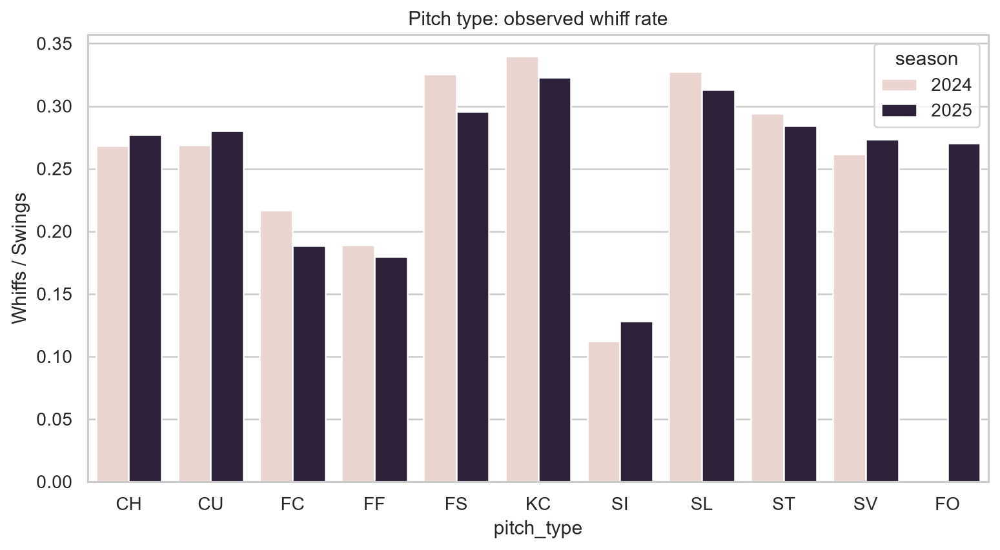

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/02_whiff_by_pitch.png')

In [10]:
x=pitch_rates.query('pitches>=@MIN_N');fig,ax=plt.subplots(figsize=(10,5));sns.barplot(data=x,x='pitch_type',y='whiff_per_swing',hue='season',ax=ax);ax.set(ylabel='Whiffs / Swings',title='Pitch type: observed whiff rate');publish(fig,'02_whiff_by_pitch')

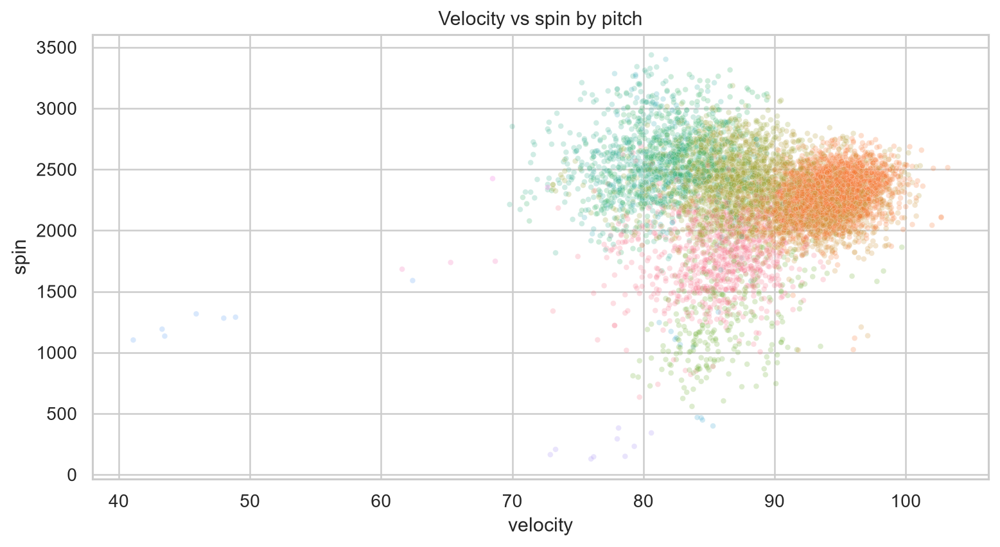

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/03_velocity_spin.png')

In [11]:
x=df.dropna(subset=['velocity','spin']).sample(n=min(len(df.dropna(subset=['velocity','spin'])),8000),random_state=42)
fig,ax=plt.subplots(figsize=(10,5));sns.scatterplot(data=x,x='velocity',y='spin',hue='pitch_type',alpha=.23,s=12,legend=False,ax=ax);ax.set(title='Velocity vs spin by pitch');publish(fig,'03_velocity_spin')

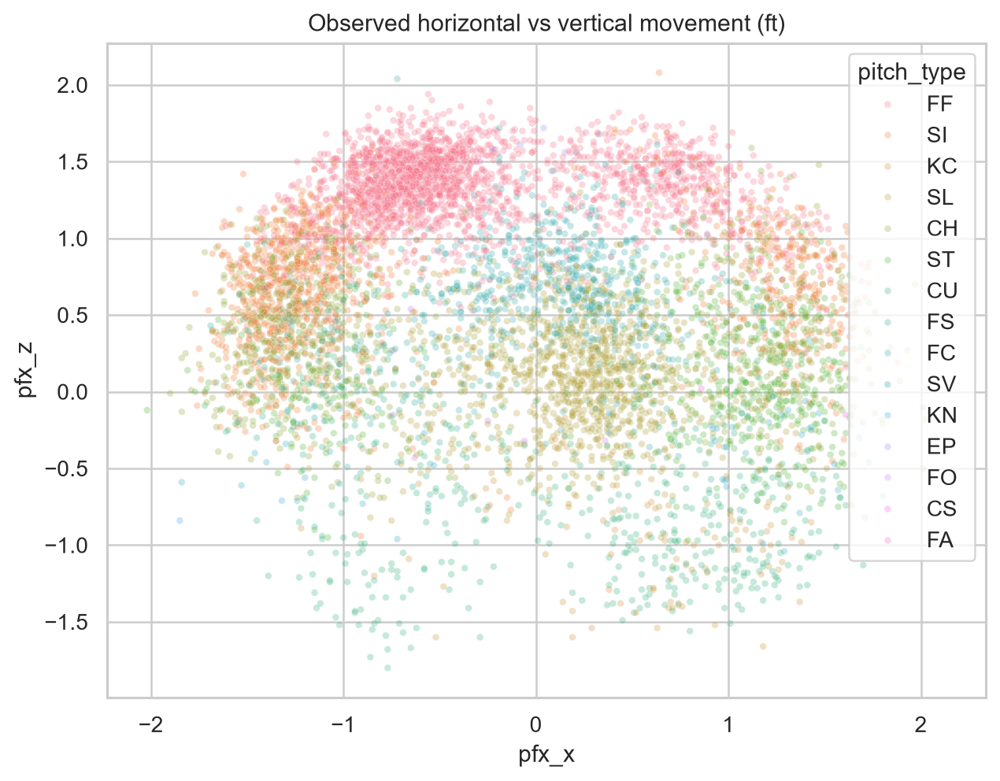

In [12]:
if {'pfx_x','pfx_z'}.issubset(df):
    x=df[['pfx_x','pfx_z','pitch_type']].dropna();x=x.sample(n=min(len(x),7000),random_state=42)
    fig,ax=plt.subplots(figsize=(8,6));sns.scatterplot(data=x,x='pfx_x',y='pfx_z',hue='pitch_type',s=12,alpha=.28,ax=ax);ax.set(title='Observed horizontal vs vertical movement (ft)');publish(fig,'04_pitch_movement')

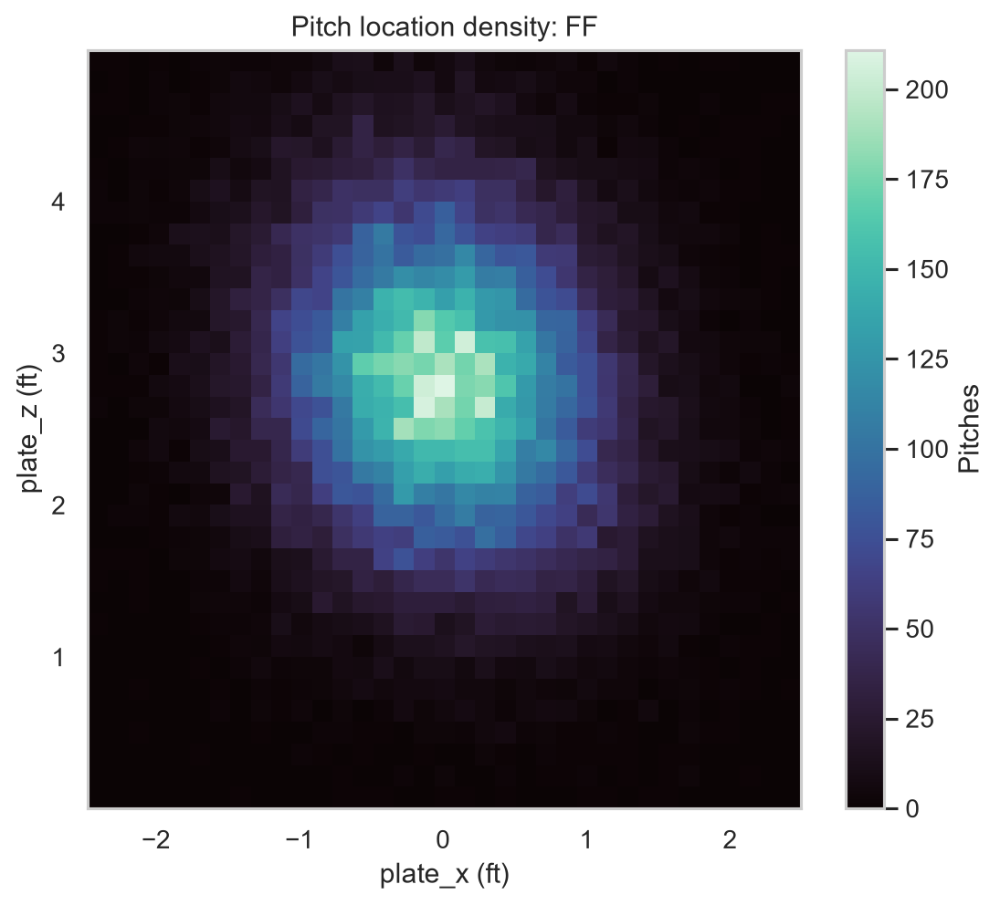

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/05_location_density.png')

In [13]:
top_pitch=df.pitch_type.value_counts().index[0]
x=df.loc[df.pitch_type.eq(top_pitch)&df.plate_x.between(-2.5,2.5)&df.plate_z.between(0,5)]
fig,ax=plt.subplots(figsize=(7,6));hb=ax.hist2d(x.plate_x,x.plate_z,bins=35,cmap='mako');fig.colorbar(hb[3],ax=ax,label='Pitches');ax.set(title=f'Pitch location density: {top_pitch}',xlabel='plate_x (ft)',ylabel='plate_z (ft)');publish(fig,'05_location_density')

,entropy,pitches,types
pitcher,,,
607625,2.058390,577,10
608331,1.854092,500,7
547179,1.846787,548,7
592836,1.845445,365,7
543243,1.803395,533,7
607259,1.767357,263,6
694973,1.756493,364,7
607536,1.747372,240,6
656605,1.744083,487,7


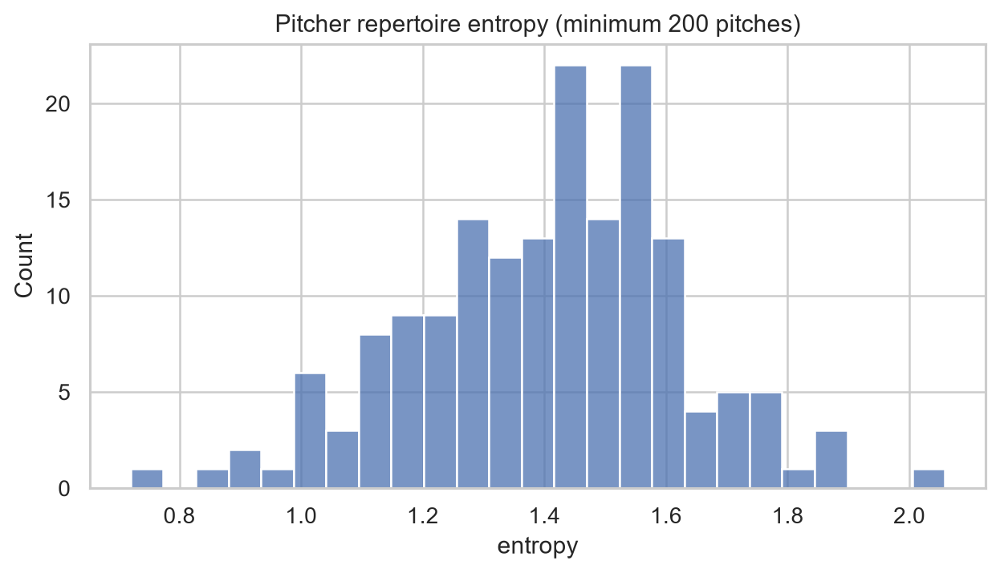

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/06_repertoire_entropy.png')

In [14]:
pcount=df.groupby(['pitcher','pitch_type']).size().rename('n').reset_index()
pcount['share']=pcount.n/pcount.groupby('pitcher').n.transform('sum')
entropy=pcount.assign(term=lambda x:-x.share*np.log(x.share)).groupby('pitcher').agg(entropy=('term','sum'),pitches=('n','sum'),types=('pitch_type','nunique')).query('pitches>=200')
display(entropy.sort_values('entropy',ascending=False).head(15))
fig,ax=plt.subplots(figsize=(8,4));sns.histplot(data=entropy,x='entropy',bins=25,ax=ax);ax.set(title='Pitcher repertoire entropy (minimum 200 pitches)');publish(fig,'06_repertoire_entropy')

### Repertoire concentration and diversity
A repertoire with many observed pitch types may be concentrated in one dominant pitch. Shannon entropy and effective pitch count summarize repertoire balance and should be calculated within pitcher-season observations.

,season,pitcher,pitches,pitch_types,entropy,dominant_share,effective_pitch_types
210,2024,656302,313,6,1.093,0.450,2.985
531,2025,607200,303,5,1.364,0.353,3.911
274,2024,663903,302,4,1.001,0.483,2.720
270,2024,663776,300,6,1.433,0.313,4.191
690,2025,666200,300,5,1.511,0.330,4.533
22,2024,519242,295,4,1.232,0.386,3.428
517,2025,605135,295,7,1.383,0.492,3.985
313,2024,668881,294,4,0.894,0.602,2.446
99,2024,605400,294,5,1.554,0.310,4.728
384,2024,677960,293,4,1.285,0.447,3.615


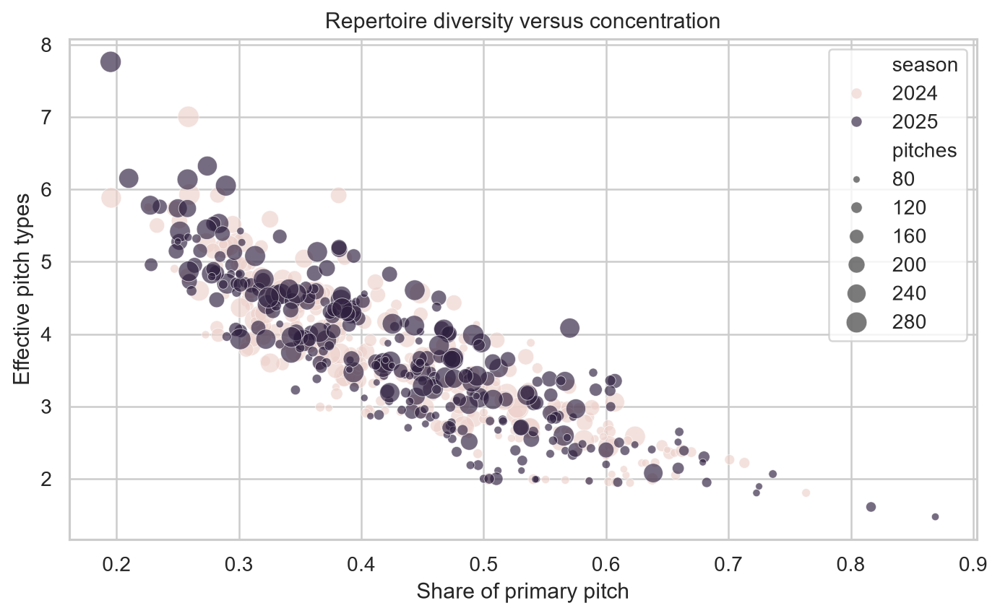

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/repertoire_diversity.png')

In [15]:
mix = df.groupby(['season','pitcher','pitch_type']).size().rename('n').reset_index()
mix['total'] = mix.groupby(['season','pitcher'])['n'].transform('sum')
mix['share'] = mix['n'] / mix['total']
mix['ent_term'] = -mix['share'] * np.log(mix['share'])
repertoire = mix.groupby(['season','pitcher']).agg(
    pitches=('n','sum'), pitch_types=('pitch_type','nunique'),
    entropy=('ent_term','sum'), dominant_share=('share','max')
).reset_index()
repertoire['effective_pitch_types'] = np.exp(repertoire['entropy'])
repertoire = repertoire.query('pitches >= 80')
display(repertoire.sort_values('pitches', ascending=False).head(15).round(3))
fig, ax = plt.subplots(figsize=(9,5))
sns.scatterplot(data=repertoire,x='dominant_share',y='effective_pitch_types',hue='season',size='pitches',sizes=(15,150),alpha=.65,ax=ax)
ax.set(xlabel='Share of primary pitch',ylabel='Effective pitch types',title='Repertoire diversity versus concentration')
publish(fig,'repertoire_diversity')

### Arm-side movement normalization
Horizontal movement direction depends on pitcher throwing hand. Plot raw and arm-side-oriented movement to compare shape across left- and right-handed pitchers without interpreting the sign as quality.

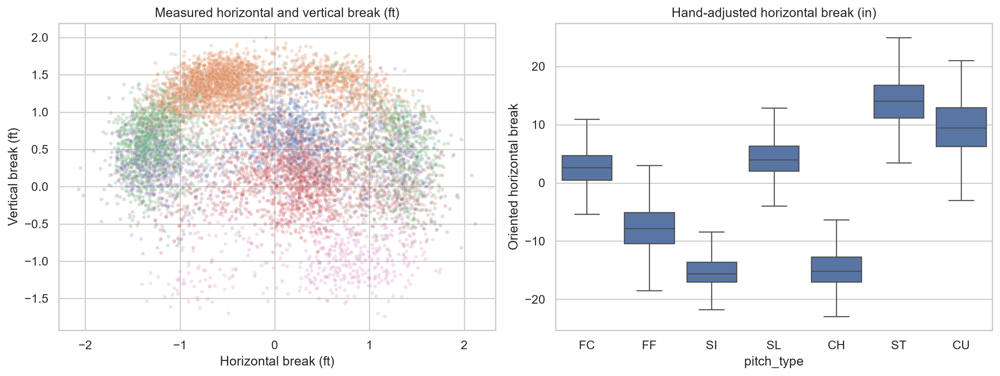

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/arm_side_movement.png')

In [16]:
move=df[['pitch_type','p_throws','pfx_x','pfx_z','release_speed']].dropna().copy()
move=move[move.p_throws.isin(['L','R'])]
move['armside_x_in']=move.pfx_x*12*np.where(move.p_throws.eq('L'),-1,1)
major=df.pitch_type.value_counts().head(7).index
move=move[move.pitch_type.isin(major)]
x=move.sample(n=min(9000,len(move)),random_state=42)
fig,axes=plt.subplots(1,2,figsize=(13,5))
sns.scatterplot(data=x,x='pfx_x',y='pfx_z',hue='pitch_type',alpha=.25,s=12,ax=axes[0],legend=False)
axes[0].set(title='Measured horizontal and vertical break (ft)',xlabel='Horizontal break (ft)',ylabel='Vertical break (ft)')
sns.boxplot(data=move.sample(n=min(9000,len(move)),random_state=42),x='pitch_type',y='armside_x_in',showfliers=False,ax=axes[1])
axes[1].set(title='Hand-adjusted horizontal break (in)',ylabel='Oriented horizontal break')
fig.tight_layout();publish(fig,'arm_side_movement')

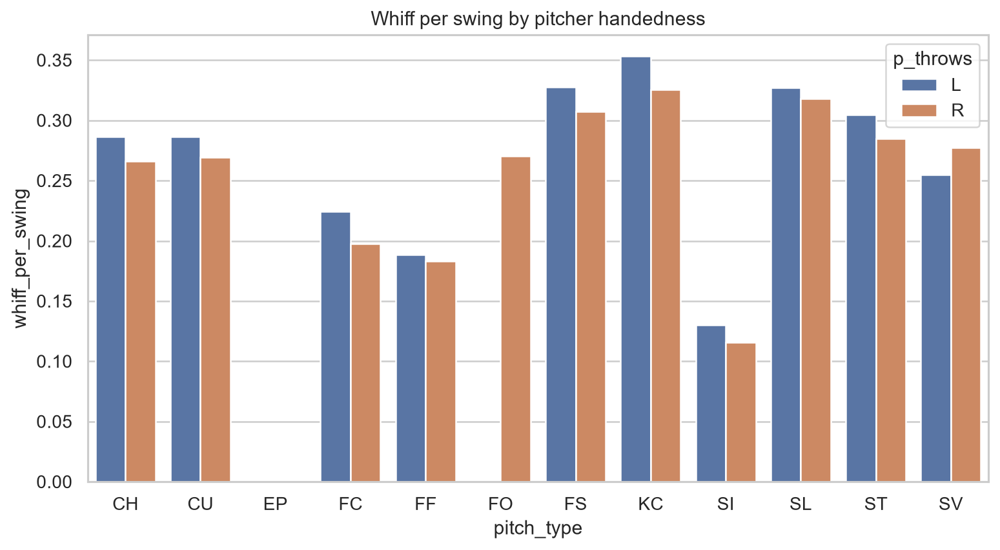

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/07_pitch_hand_split.png')

In [17]:
x=df.groupby(['pitch_type','p_throws']).apply(rates,include_groups=False).reset_index().query('swings>=@MIN_SWINGS')
fig,ax=plt.subplots(figsize=(10,5));sns.barplot(data=x,x='pitch_type',y='whiff_per_swing',hue='p_throws',ax=ax);ax.set(title='Whiff per swing by pitcher handedness');publish(fig,'07_pitch_hand_split')

### Pitcher-level design, consistency and repertoire

,pitcher,pitch_type,n,velocity_mean,velocity_sd,spin_mean,spin_sd
1146,656302,SL,297,88.08,1.36,2793.15,96.38
2,434378,FF,276,93.78,1.07,2416.40,80.94
1697,668881,FF,273,97.90,1.55,2397.93,82.60
2259,680730,FF,266,92.62,1.05,2174.66,66.01
1478,663855,SI,241,95.73,2.10,1900.74,103.40
2152,676962,FF,240,95.74,1.30,2230.83,78.38
1538,664285,SI,240,93.06,1.81,2157.56,94.91
1144,656302,FF,240,97.05,0.99,2575.02,110.23
572,607074,FF,240,94.66,1.33,2360.93,83.84
1916,671096,FF,226,92.53,0.96,2226.37,76.14


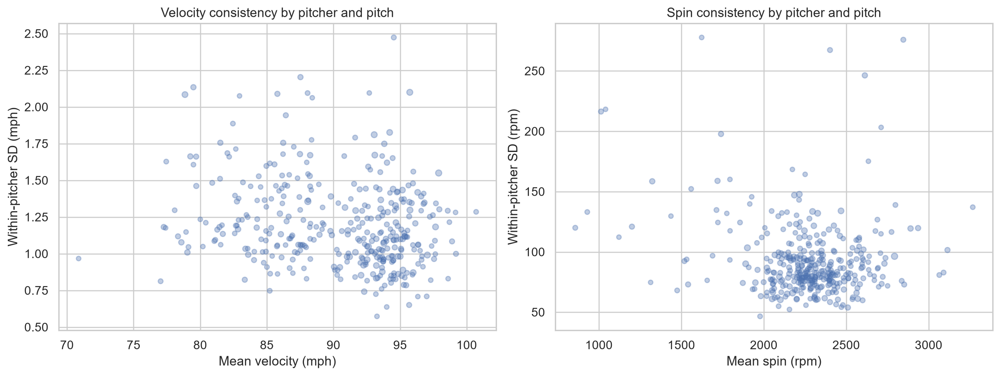

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/pitcher_physical_consistency.png')

In [18]:
physical = (df.groupby(['pitcher', 'pitch_type'])
    .agg(n=('pitch_type', 'size'), velocity_mean=('release_speed', 'mean'),
         velocity_sd=('release_speed', 'std'), spin_mean=('release_spin_rate', 'mean'),
         spin_sd=('release_spin_rate', 'std'))
    .reset_index())
physical = physical.query('n >= 80').copy()
display(physical.sort_values('n', ascending=False).head(20).round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
x = physical[physical['velocity_mean'].notna() & physical['velocity_sd'].notna()]
axes[0].scatter(x['velocity_mean'], x['velocity_sd'], s=np.sqrt(x['n'])*2, alpha=.35)
axes[0].set(xlabel='Mean velocity (mph)', ylabel='Within-pitcher SD (mph)', title='Velocity consistency by pitcher and pitch')
x = physical[physical['spin_mean'].notna() & physical['spin_sd'].notna()]
axes[1].scatter(x['spin_mean'], x['spin_sd'], s=np.sqrt(x['n'])*2, alpha=.35)
axes[1].set(xlabel='Mean spin (rpm)', ylabel='Within-pitcher SD (rpm)', title='Spin consistency by pitcher and pitch')
fig.tight_layout()
publish(fig, 'pitcher_physical_consistency')


,pitch_type,season,n,whiffs,swings,whiff_rate
18,KC,2024,890,139,409,0.339853
25,SL,2024,8172,1323,4042,0.327313
16,FS,2024,1663,281,863,0.325608
19,KC,2025,1115,156,483,0.322981
26,SL,2025,8152,1249,3987,0.313268
17,FS,2025,2010,308,1041,0.295869
27,ST,2024,4130,533,1812,0.294150
28,ST,2025,4542,572,2011,0.284436
5,CU,2025,3318,380,1357,0.280029
1,CH,2025,5464,762,2748,0.277293


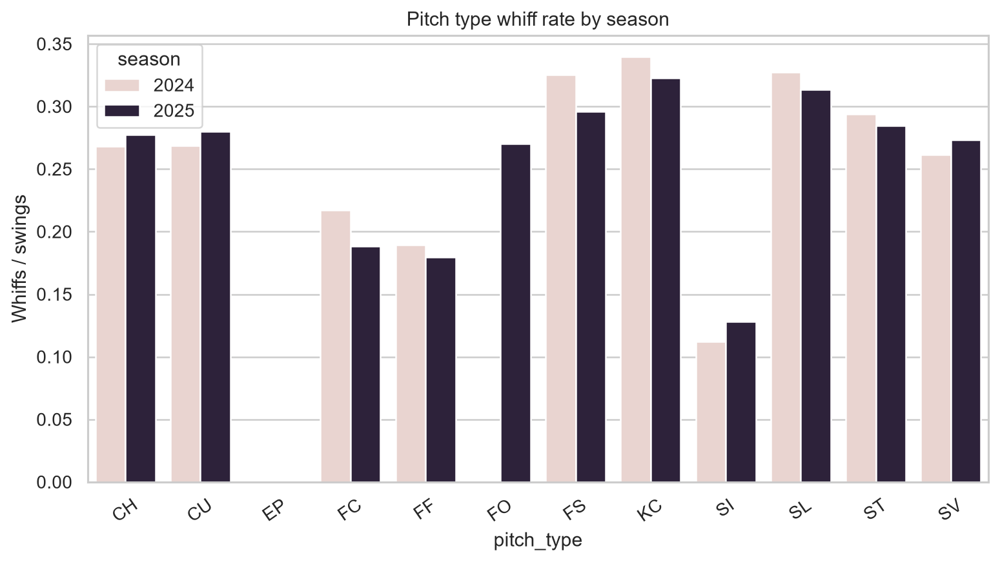

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/pitch_whiff_split_season.png')

In [19]:
group='season'
x=df.groupby(['pitch_type',group]).agg(n=('whiff_ind','size'),whiffs=('whiff_ind','sum'),swings=('swing_ind','sum')).reset_index()
x['whiff_rate']=x.whiffs/x.swings.replace(0,np.nan)
x=x.query('swings>=30');display(x.sort_values('whiff_rate',ascending=False).head(12))
fig,ax=plt.subplots(figsize=(10,5))
sns.barplot(data=x,x='pitch_type',y='whiff_rate',hue=group,ax=ax)
ax.set(title='Pitch type whiff rate by season',ylabel='Whiffs / swings')
plt.xticks(rotation=35);publish(fig,'pitch_whiff_split_season')

,pitch_type,stand,n,whiffs,swings,whiff_rate
19,KC,R,1025,166,480,0.345833
27,SL,R,10302,1610,4988,0.322775
17,FS,R,1458,251,783,0.320562
26,SL,L,6022,962,3041,0.316343
18,KC,L,980,129,412,0.313107
16,FS,L,2215,338,1121,0.301517
29,ST,R,5758,771,2629,0.293267
15,FO,R,60,10,35,0.285714
1,CH,R,5465,798,2810,0.283986
30,SV,L,261,30,107,0.280374


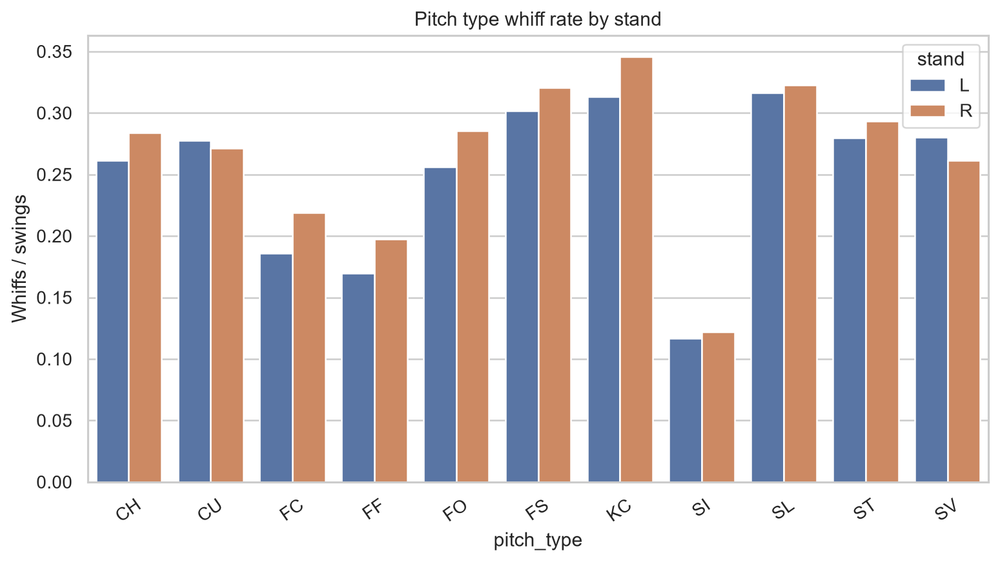

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/pitch_whiff_split_stand.png')

In [20]:
group='stand'
x=df.groupby(['pitch_type',group]).agg(n=('whiff_ind','size'),whiffs=('whiff_ind','sum'),swings=('swing_ind','sum')).reset_index()
x['whiff_rate']=x.whiffs/x.swings.replace(0,np.nan)
x=x.query('swings>=30');display(x.sort_values('whiff_rate',ascending=False).head(12))
fig,ax=plt.subplots(figsize=(10,5))
sns.barplot(data=x,x='pitch_type',y='whiff_rate',hue=group,ax=ax)
ax.set(title='Pitch type whiff rate by stand',ylabel='Whiffs / swings')
plt.xticks(rotation=35);publish(fig,'pitch_whiff_split_stand')

,pitch_type,balls,n,whiffs,swings,whiff_rate
36,KC,0,997,134,368,0.364130
49,SL,0,7591,1121,3150,0.355873
59,SV,2,85,15,43,0.348837
38,KC,2,302,57,167,0.341317
32,FS,0,1501,209,650,0.321538
53,ST,0,4161,497,1564,0.317775
33,FS,1,1326,229,721,0.317614
50,SL,1,5058,834,2678,0.311426
34,FS,2,669,126,426,0.295775
0,CH,0,4559,574,1946,0.294964


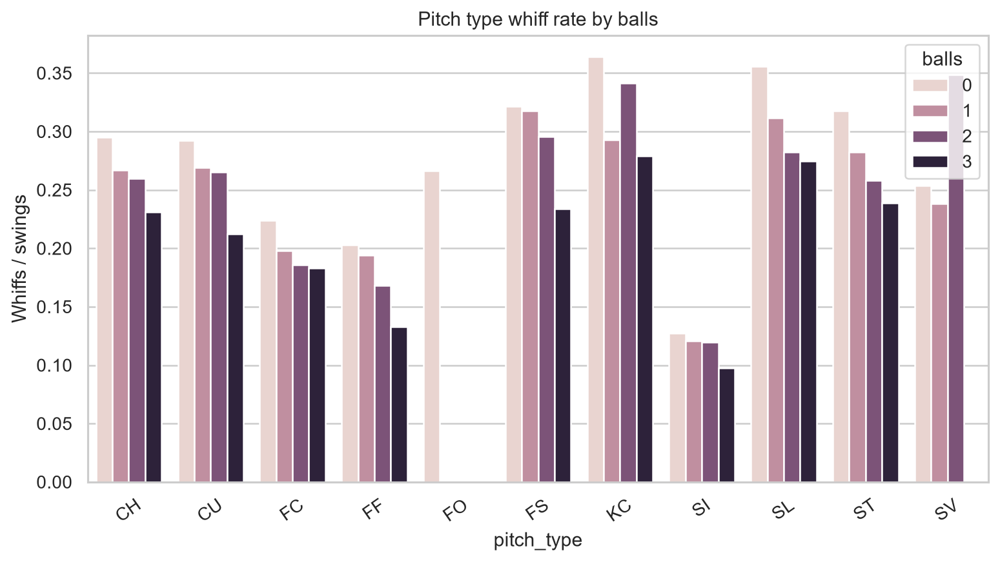

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/pitch_whiff_split_balls.png')

In [21]:
group='balls'
x=df.groupby(['pitch_type',group]).agg(n=('whiff_ind','size'),whiffs=('whiff_ind','sum'),swings=('swing_ind','sum')).reset_index()
x['whiff_rate']=x.whiffs/x.swings.replace(0,np.nan)
x=x.query('swings>=30');display(x.sort_values('whiff_rate',ascending=False).head(12))
fig,ax=plt.subplots(figsize=(10,5))
sns.barplot(data=x,x='pitch_type',y='whiff_rate',hue=group,ax=ax)
ax.set(title='Pitch type whiff rate by balls',ylabel='Whiffs / swings')
plt.xticks(rotation=35);publish(fig,'pitch_whiff_split_balls')

# Division II — Hitting, Contact Quality & Game Context

*This division contains detailed technical experiments; the submission report selects the most defensible results.*

## 3 | Hitter Decision-Making & Pitch-Type Weaknesses
**Question:** which hitters swing outside the zone, make contact, and display stable pitch-type weaknesses? Small samples are screened and intervals should accompany rankings.

In [22]:
batter=df.groupby('batter').apply(rates,include_groups=False).reset_index();batter=batter.query('pitches>=@MIN_N').copy()
display(batter.sort_values('pitches',ascending=False).head(15).round(3));batter.to_csv(REPORTDIR/'batter_discipline.csv',index=False)

,batter,pitches,swings,whiffs,whiff_per_swing,swing_rate,chase_rate,contact_rate,velocity,spin
252,663993,508.0,206.0,30.0,0.146,0.406,0.252,0.854,89.507,2221.581
99,608070,489.0,218.0,25.0,0.115,0.446,0.255,0.885,88.672,2250.172
242,663697,472.0,192.0,38.0,0.198,0.407,0.185,0.802,89.578,2284.966
276,665742,470.0,166.0,32.0,0.193,0.353,0.164,0.807,89.026,2293.364
385,672580,467.0,183.0,33.0,0.180,0.392,0.214,0.820,89.544,2257.747
479,682998,464.0,213.0,37.0,0.174,0.459,0.282,0.826,89.752,2189.634
451,681082,461.0,194.0,21.0,0.108,0.421,0.255,0.892,90.280,2248.451
179,646240,458.0,241.0,63.0,0.261,0.526,0.279,0.739,90.449,2284.124
473,682829,456.0,193.0,63.0,0.326,0.423,0.258,0.674,87.837,2105.989
31,543760,455.0,245.0,55.0,0.224,0.538,0.300,0.776,88.203,2233.848


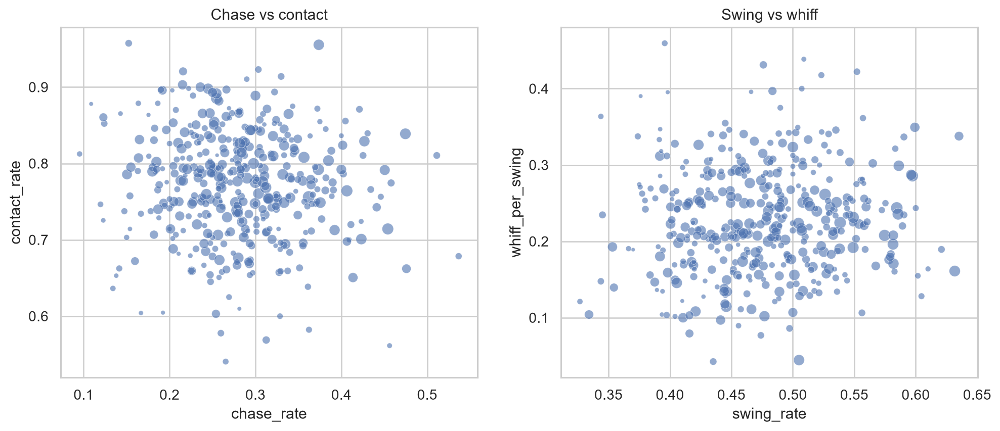

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/08_batter_plate_discipline.png')

In [23]:
fig,axes=plt.subplots(1,2,figsize=(13,5));sns.scatterplot(data=batter,x='chase_rate',y='contact_rate',size='swings',sizes=(10,90),alpha=.6,legend=False,ax=axes[0]);sns.scatterplot(data=batter,x='swing_rate',y='whiff_per_swing',size='swings',sizes=(10,90),alpha=.6,legend=False,ax=axes[1]);axes[0].set_title('Chase vs contact');axes[1].set_title('Swing vs whiff');publish(fig,'08_batter_plate_discipline')

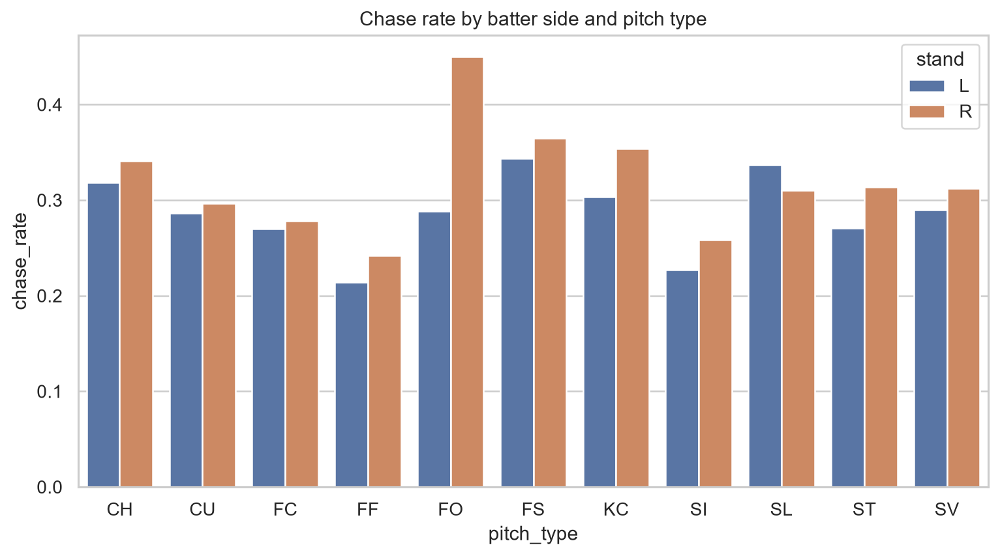

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/09_hitter_chase.png')

In [24]:
x=df.groupby(['stand','pitch_type']).apply(rates,include_groups=False).reset_index().query('swings>=@MIN_SWINGS')
fig,ax=plt.subplots(figsize=(10,5));sns.barplot(data=x,x='pitch_type',y='chase_rate',hue='stand',ax=ax);ax.set(title='Chase rate by batter side and pitch type');publish(fig,'09_hitter_chase')

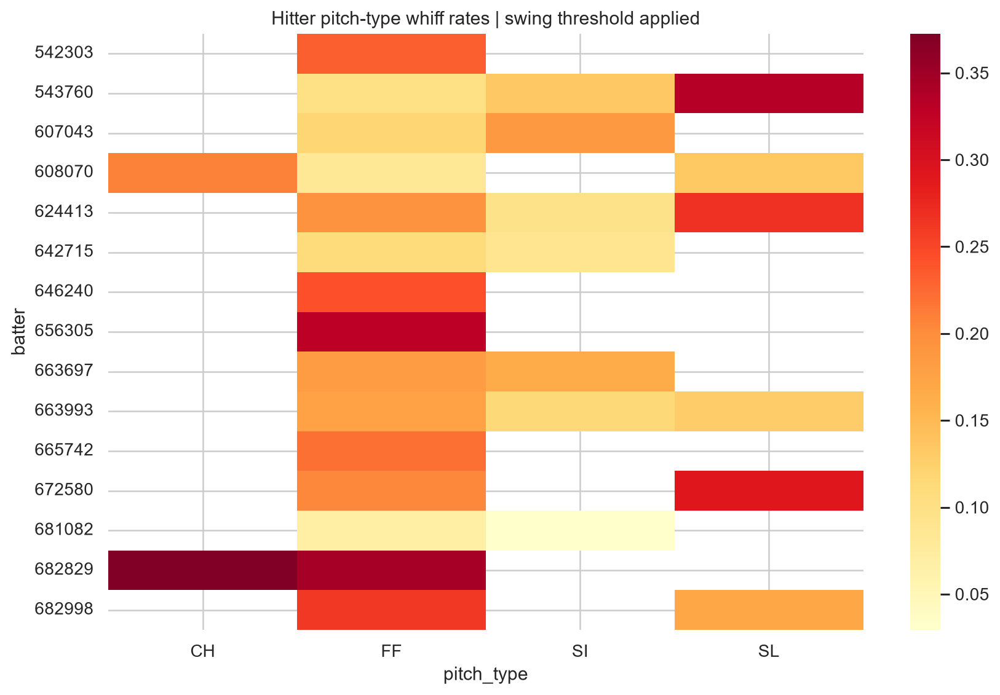

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/10_batter_pitch_heatmap.png')

In [25]:
bp=df.groupby(['batter','pitch_type']).apply(rates,include_groups=False).reset_index().query('swings>=@MIN_SWINGS');topb=batter.sort_values('pitches',ascending=False).head(15).batter
heat=bp[bp.batter.isin(topb)].pivot(index='batter',columns='pitch_type',values='whiff_per_swing')
fig,ax=plt.subplots(figsize=(11,7));sns.heatmap(heat,annot=False,cmap='YlOrRd',ax=ax);ax.set(title='Hitter pitch-type whiff rates | swing threshold applied');publish(fig,'10_batter_pitch_heatmap')

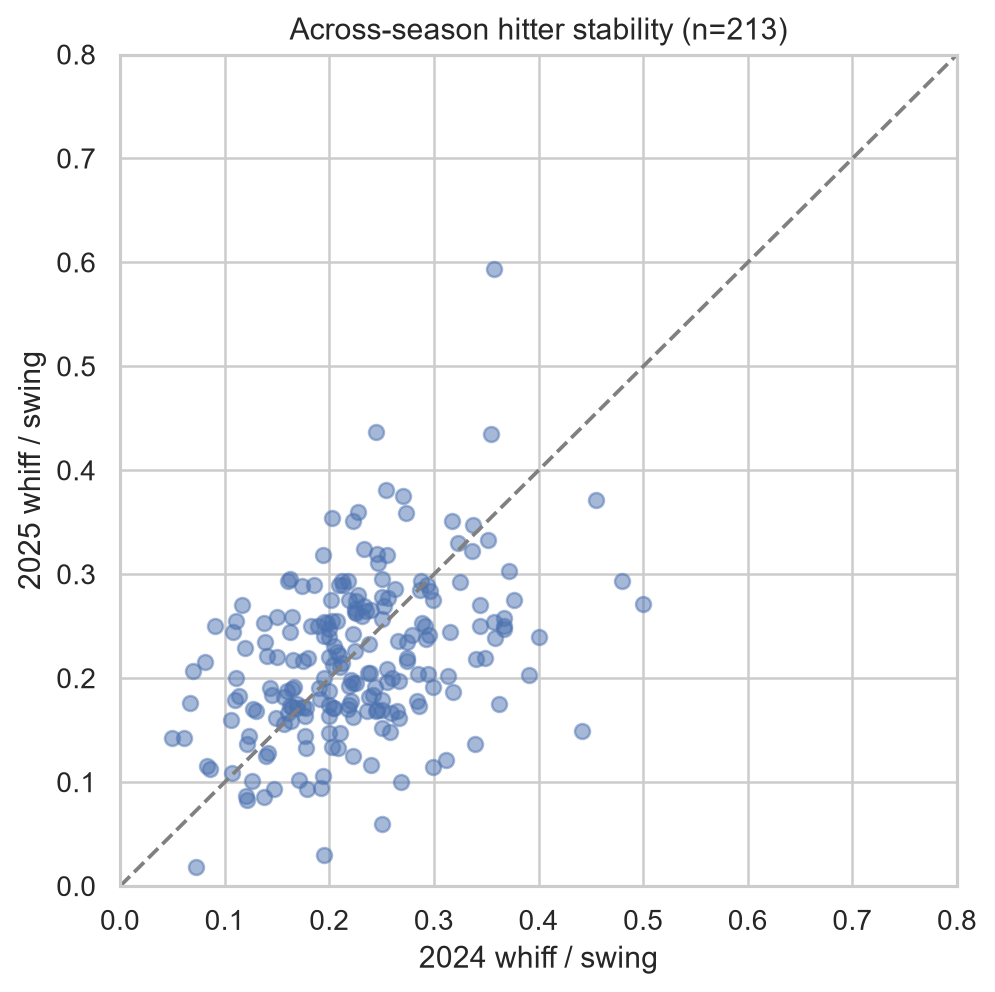

Correlation: 0.4017883291205307


In [26]:
by_year=df.groupby(['batter','season']).apply(rates,include_groups=False).reset_index().query('swings>=@MIN_SWINGS');wide=by_year.pivot(index='batter',columns='season',values='whiff_per_swing').dropna()
fig,ax=plt.subplots(figsize=(6,6));ax.scatter(wide[2024],wide[2025],alpha=.5);ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlim=(0,.8),ylim=(0,.8),xlabel='2024 whiff / swing',ylabel='2025 whiff / swing',title=f'Across-season hitter stability (n={len(wide)})');publish(fig,'11_hitter_stability')
print('Correlation:',wide[2024].corr(wide[2025]) if len(wide)>2 else 'insufficient samples')

### Hitter discipline joint profile
The scatterplot compares two distinct behaviors rather than repeating one rate in multiple leaderboards. Require a minimum of swings and out-of-zone opportunities to avoid unstable individual ranks.

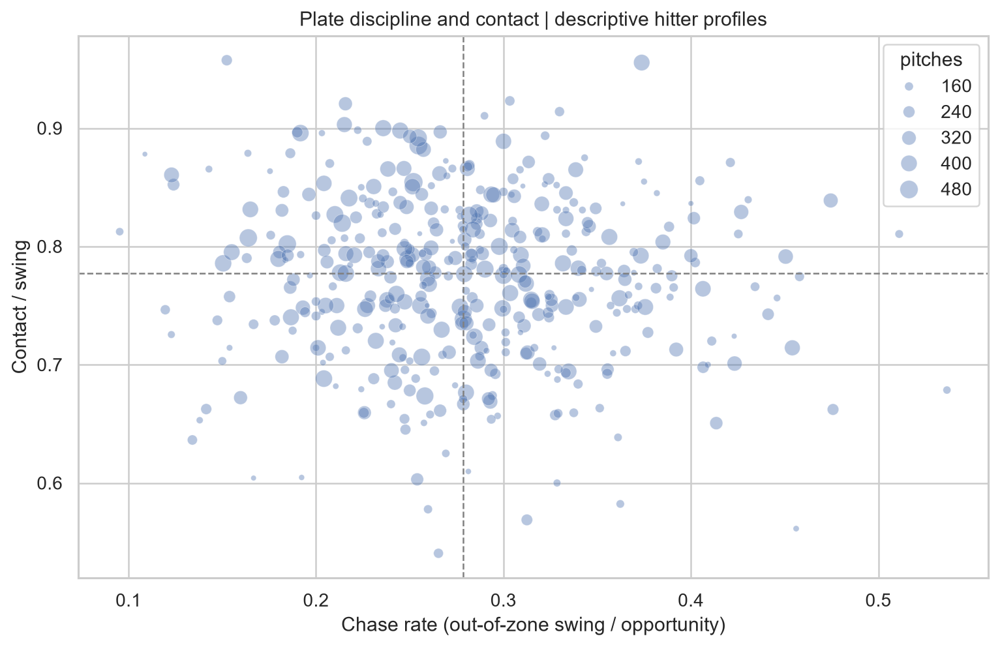

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/hitter_plate_discipline_joint.png')

In [27]:
hitter_valid = (df.groupby('batter').agg(
    pitches=('swing_ind','size'),swings=('swing_ind','sum'),
    outside=('zone_known',lambda x: int(x.sum()))
).reset_index())
discipline = batter.merge(hitter_valid[['batter','swings']],on='batter',how='left',suffixes=('','_verified'))
discipline = discipline.query('pitches >= 100 and swings >= 30').dropna(subset=['chase_rate','contact_rate'])
fig,ax=plt.subplots(figsize=(10,6))
sns.scatterplot(data=discipline,x='chase_rate',y='contact_rate',size='pitches',sizes=(10,130),alpha=.4,ax=ax)
ax.axvline(discipline.chase_rate.median(),ls='--',lw=1,color='gray')
ax.axhline(discipline.contact_rate.median(),ls='--',lw=1,color='gray')
ax.set(xlabel='Chase rate (out-of-zone swing / opportunity)',ylabel='Contact / swing',title='Plate discipline and contact | descriptive hitter profiles')
publish(fig,'hitter_plate_discipline_joint')

### Bayesian-shrunk hitter whiff profiles
For individual batters, sparse rates are noisy. A Beta prior centered on the dataset-level observed whiff-per-swing prevalence shrinks estimates toward the shared mean; it is a descriptive ranking with explicit sensitivity to prior strength.

,batter,swings,whiffs,raw_whiff,posterior_whiff
31,543760,245,55,0.224,0.225
56,592206,242,59,0.244,0.239
179,646240,241,63,0.261,0.253
175,645277,231,48,0.208,0.213
461,681624,229,54,0.236,0.233
419,677594,229,53,0.231,0.230
180,647304,224,43,0.192,0.201
20,521692,224,64,0.286,0.270
424,677951,219,49,0.224,0.224
50,572233,219,55,0.251,0.245


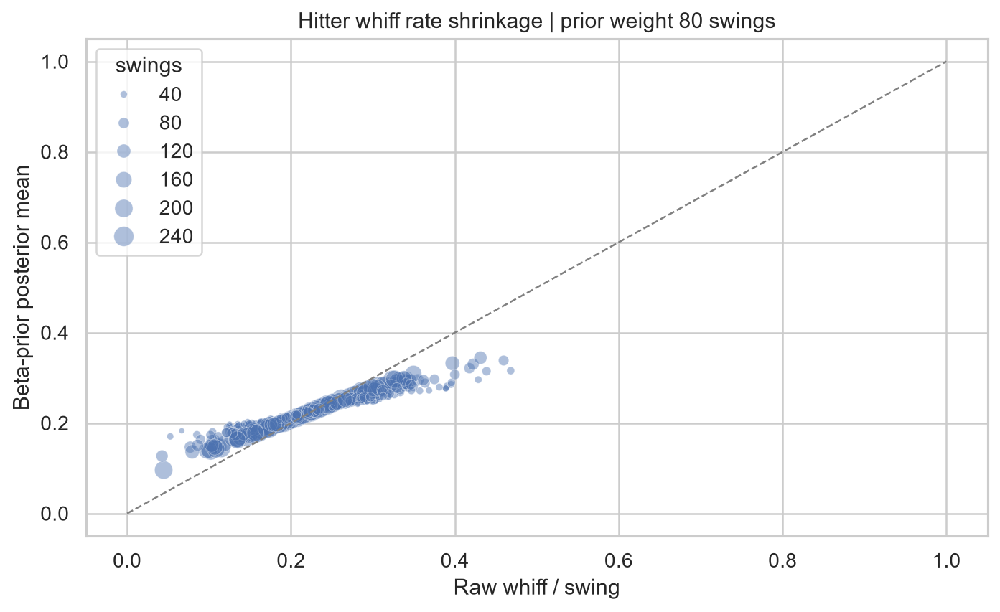

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/hitter_whiff_shrinkage.png')

In [28]:
hitter_events=(df[df.swing_ind.eq(1)].groupby('batter')
               .agg(swings=('whiff_ind','size'),whiffs=('whiff_ind','sum')).reset_index())
league_rate=df.loc[df.swing_ind.eq(1),'whiff_ind'].mean()
prior_strength=80
hitter_events['raw_whiff']=hitter_events.whiffs/hitter_events.swings
hitter_events['posterior_whiff']=(hitter_events.whiffs+prior_strength*league_rate)/(hitter_events.swings+prior_strength)
eligible=hitter_events.query('swings>=30').copy()
display(eligible.sort_values('swings',ascending=False).head(15).round(3))
fig,ax=plt.subplots(figsize=(9,5))
sns.scatterplot(data=eligible,x='raw_whiff',y='posterior_whiff',size='swings',sizes=(10,125),alpha=.45,ax=ax)
ax.plot([0,1],[0,1],'--',lw=1,color='gray')
ax.set(xlabel='Raw whiff / swing',ylabel='Beta-prior posterior mean',title='Hitter whiff rate shrinkage | prior weight 80 swings')
publish(fig,'hitter_whiff_shrinkage')

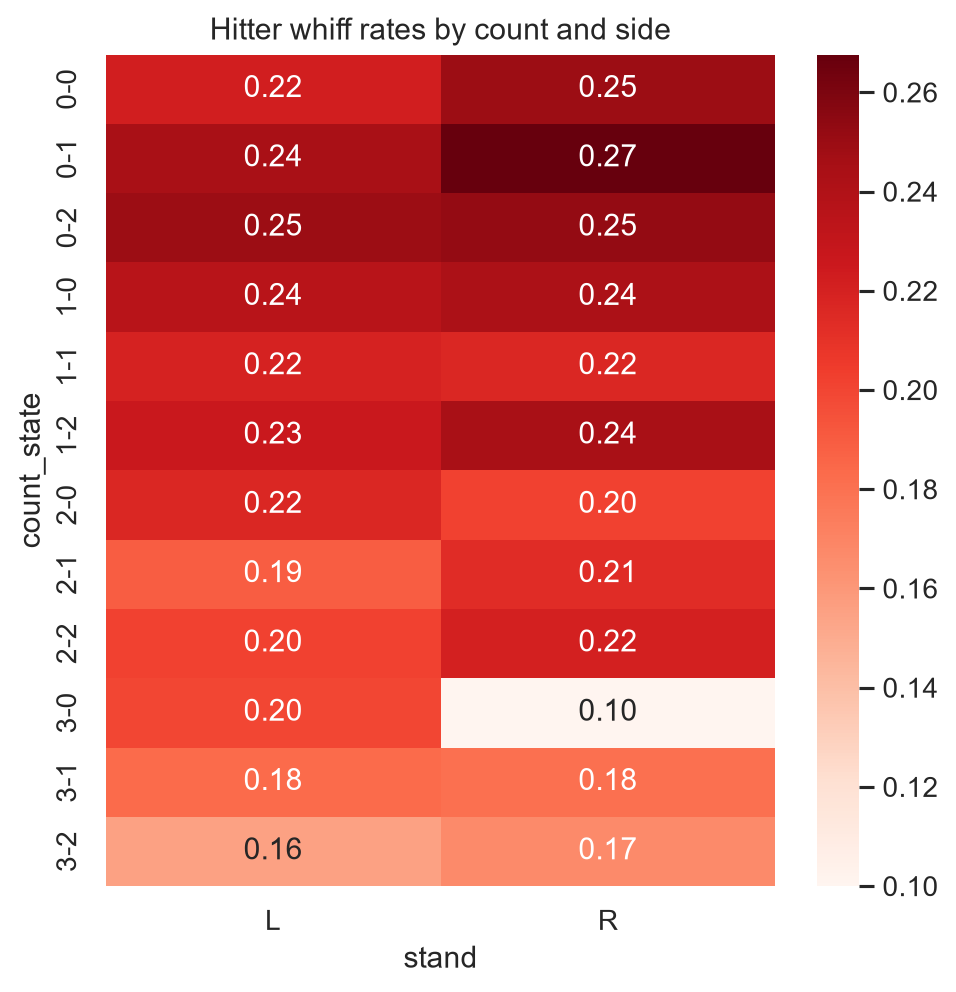

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/12_count_by_side.png')

In [29]:
x=df.groupby(['count_state','stand']).apply(rates,include_groups=False).reset_index().query('swings>=@MIN_SWINGS')
mat=x.pivot(index='count_state',columns='stand',values='whiff_per_swing');fig,ax=plt.subplots(figsize=(6,6));sns.heatmap(mat,annot=True,fmt='.2f',cmap='Reds',ax=ax);ax.set(title='Hitter whiff rates by count and side');publish(fig,'12_count_by_side')

**Interpretation guidance:** chase rate is out-of-zone swings divided by out-of-zone pitches; contact rate is contact divided by swings. Low-usage pitch types should not be labelled a stable hitter weakness.

### Expanded hitter profiles and pitch-type vulnerability

,batter,pitch_type,n,swings,whiffs,whiff_rate
1861,656941,SL,53,24,10,0.416667
276,543760,ST,42,22,9,0.409091
510,592206,SL,83,44,17,0.386364
3778,677951,CH,52,26,10,0.384615
1489,642715,SL,49,21,8,0.380952
511,592206,ST,66,37,14,0.378378
275,543760,SL,97,48,16,0.333333
1755,656305,FF,174,82,27,0.329268
1490,642715,ST,51,28,9,0.321429
268,543760,CH,60,28,9,0.321429


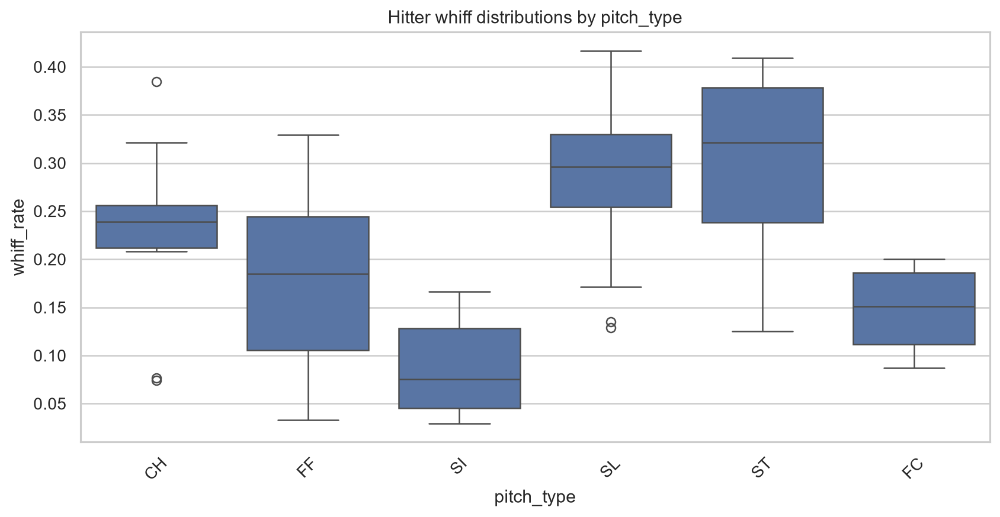

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/hitter_whiff_pitch_type.png')

In [30]:
group='pitch_type'
x=df.groupby(['batter',group]).agg(n=('swing_ind','size'),swings=('swing_ind','sum'),whiffs=('whiff_ind','sum')).reset_index()
x=x.query('n>=40 and swings>=20').copy();x['whiff_rate']=x.whiffs/x.swings
leaders=x.groupby('batter').n.sum().nlargest(15).index
x=x[x.batter.isin(leaders)]
display(x.sort_values('whiff_rate',ascending=False).head(15))
fig,ax=plt.subplots(figsize=(11,5))
sns.boxplot(data=x,x=group,y='whiff_rate',ax=ax)
ax.set(title='Hitter whiff distributions by pitch_type')
plt.xticks(rotation=45);publish(fig,'hitter_whiff_pitch_type')

,batter,p_throws,n,swings,whiffs,whiff_rate
924,682829,R,273,109,36,0.330275
46,542303,R,338,149,49,0.328859
923,682829,L,183,84,27,0.321429
386,656305,R,366,164,47,0.286585
356,646240,R,293,150,40,0.266667
188,607043,L,79,38,10,0.263158
256,624413,L,111,58,15,0.258621
355,646240,L,165,91,23,0.252747
62,543760,R,309,173,43,0.248555
326,642715,L,72,33,8,0.242424


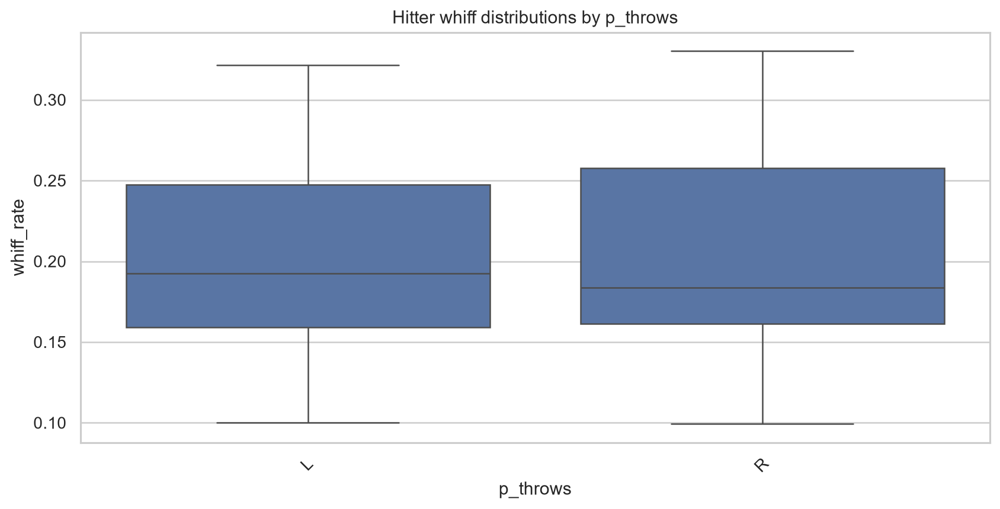

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/hitter_whiff_p_throws.png')

In [31]:
group='p_throws'
x=df.groupby(['batter',group]).agg(n=('swing_ind','size'),swings=('swing_ind','sum'),whiffs=('whiff_ind','sum')).reset_index()
x=x.query('n>=40 and swings>=20').copy();x['whiff_rate']=x.whiffs/x.swings
leaders=x.groupby('batter').n.sum().nlargest(15).index
x=x[x.batter.isin(leaders)]
display(x.sort_values('whiff_rate',ascending=False).head(15))
fig,ax=plt.subplots(figsize=(11,5))
sns.boxplot(data=x,x=group,y='whiff_rate',ax=ax)
ax.set(title='Hitter whiff distributions by p_throws')
plt.xticks(rotation=45);publish(fig,'hitter_whiff_p_throws')

## 4 | Quality of Contact | Verified BBE denominator

**Research question:** how does contact quality vary by pitch type, handedness matchup, count and year? `Hard-hit` means exit velocity ≥ 95 mph **among in-play balls with tracked exit velocity**, not among all pitches or all tracked fouls. Coverage can be incomplete and conditioning on contact introduces selection effects.


In [32]:
if {'type', 'launch_speed', 'launch_angle'}.issubset(df.columns):
    bbe_all = df.loc[df['type'].eq('X')].copy()
    bbe_all['launch_speed'] = pd.to_numeric(bbe_all['launch_speed'], errors='coerce')
    bbe_all['launch_angle'] = pd.to_numeric(bbe_all['launch_angle'], errors='coerce')
    batted = bbe_all.dropna(subset=['launch_speed']).copy()
    batted['hard_hit'] = batted['launch_speed'].ge(95)
    audit = pd.DataFrame([
        {'sample': 'All pitches', 'n': len(df)},
        {'sample': 'In-play BBE (type X)', 'n': len(bbe_all)},
        {'sample': 'Tracked in-play BBE with exit velocity', 'n': len(batted)},
    ])
    display(audit)
    print('Hard-hit / tracked in-play BBE:', round(100 * batted['hard_hit'].mean(), 2), '%')
else:
    batted = pd.DataFrame()
    print('Required Statcast ball-in-play fields unavailable.')


,sample,n
0,All pitches,109346
1,In-play BBE (type X),19348
2,Tracked in-play BBE with exit velocity,19288


Hard-hit / tracked in-play BBE: 40.63 %


### BBE measurement and denominator diagnostic
Statcast `type='X'` denotes a ball put in play. This analysis intentionally excludes tracked foul balls, unlike a broad `launch_speed.notna()` filter. The denominator is tracked in-play events; rates can differ from external public dashboards when coverage or event filters differ.

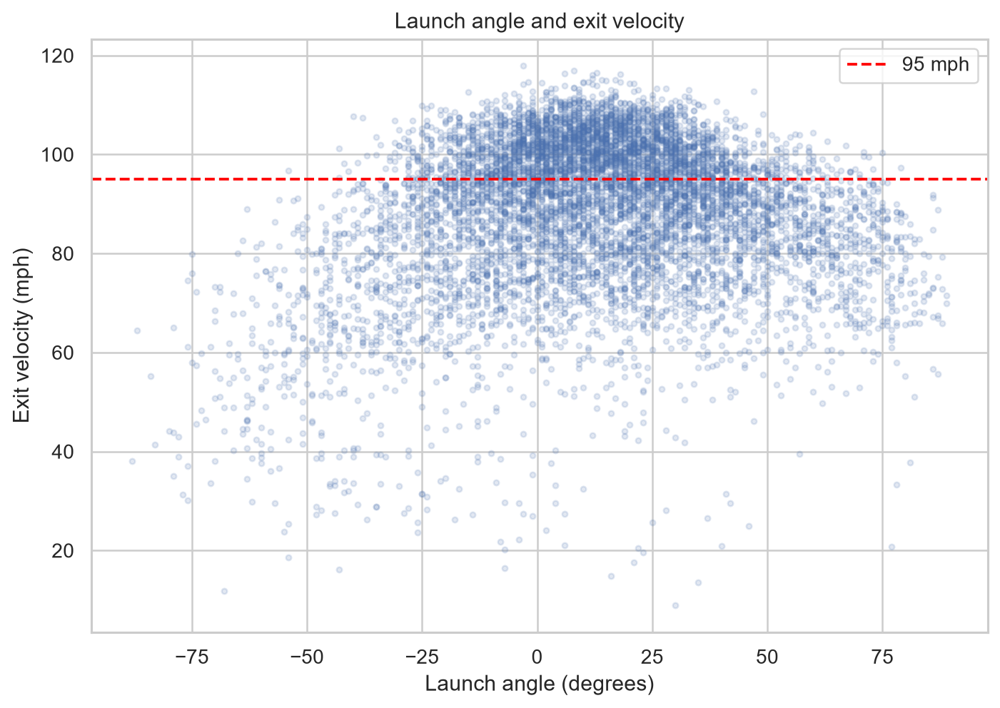

In [33]:
if len(batted):
    fig,ax=plt.subplots(figsize=(9,6));x=batted.sample(n=min(len(batted),8000),random_state=42)
    ax.scatter(x.launch_angle,x.launch_speed,alpha=.16,s=9);ax.axhline(95,color='red',linestyle='--',label='95 mph');ax.set(title='Launch angle and exit velocity',xlabel='Launch angle (degrees)',ylabel='Exit velocity (mph)');ax.legend();publish(fig,'13_batted_ball_scatter')

,n,hard_hit_rate,avg_ev
pitch_type,,,
FF,5590,0.463327,90.978390
SI,3644,0.447859,89.646076
SL,2776,0.366715,87.457853
CH,2164,0.337800,86.896904
FC,1549,0.409942,89.004584
ST,1402,0.303138,85.444080
CU,1005,0.376119,88.294527
FS,677,0.372230,87.202068
KC,295,0.372881,87.418644


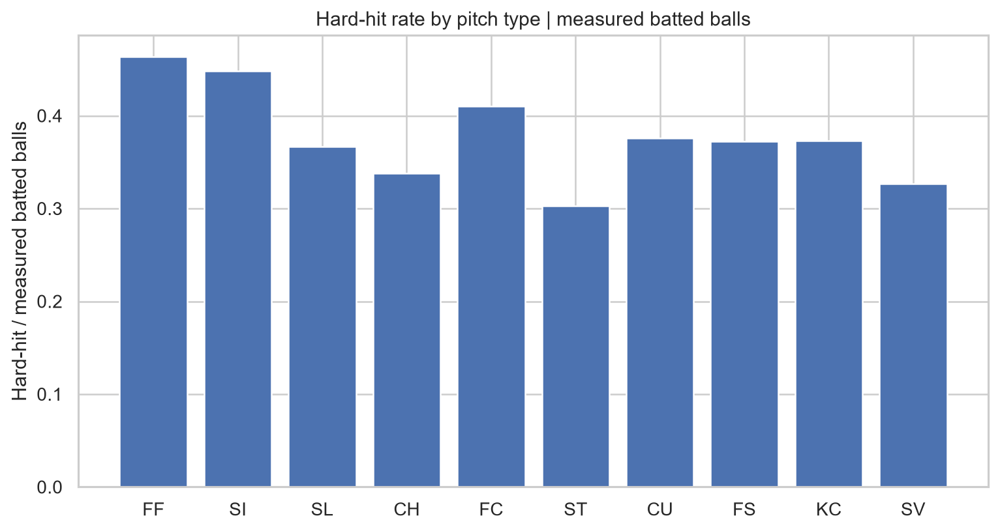

In [34]:
if len(batted):
    q=batted.groupby('pitch_type').agg(n=('hard_hit','size'),hard_hit_rate=('hard_hit','mean'),avg_ev=('launch_speed','mean')).query('n>=30').sort_values('n',ascending=False);display(q)
    fig,ax=plt.subplots(figsize=(10,5));ax.bar(q.index,q.hard_hit_rate);ax.set(title='Hard-hit rate by pitch type | measured batted balls',ylabel='Hard-hit / measured batted balls');publish(fig,'14_hard_hit_pitch')

,n,hard_hit_rate,mean_ev
batter,,,
695578,39,0.692308,92.261538
665742,76,0.657895,96.892105
621439,32,0.656250,94.812500
660271,66,0.651515,98.096970
663527,24,0.625000,95.666667
691176,24,0.625000,94.058333
592450,66,0.621212,98.324242
646240,66,0.621212,95.727273
673357,26,0.615385,96.896154


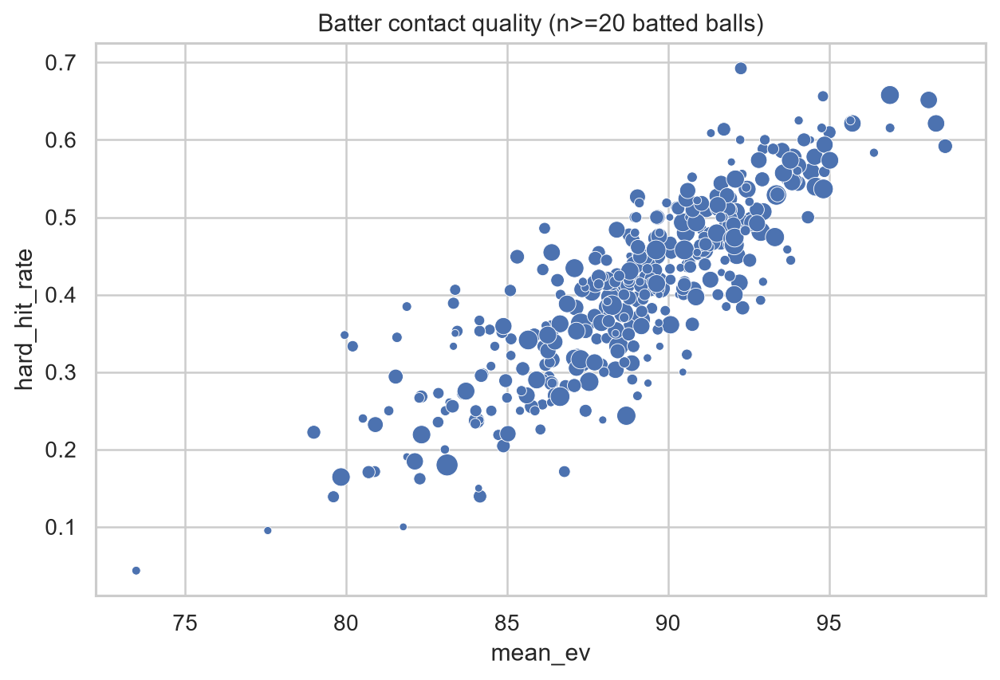

In [35]:
if len(batted):
    batter_quality=batted.groupby('batter').agg(n=('hard_hit','size'),hard_hit_rate=('hard_hit','mean'),mean_ev=('launch_speed','mean')).query('n>=20');display(batter_quality.sort_values('hard_hit_rate',ascending=False).head(15))
    fig,ax=plt.subplots(figsize=(8,5));sns.scatterplot(data=batter_quality,x='mean_ev',y='hard_hit_rate',size='n',sizes=(15,120),legend=False,ax=ax);ax.set(title='Batter contact quality (n>=20 batted balls)');publish(fig,'15_batter_quality')

### Contact-quality synthesis

The redundant handedness, season, balls and strikes bar charts are replaced by cross-classified rates with uncertainty, a count × pitch-type heatmap, and paired distributions. Differences are **descriptive**, not adjustments for player composition or pitch selection.


,pitch_type,n,ev,angle,hard_hit
0,CH,2164,86.897,9.570,0.338
2,CU,1005,88.295,11.529,0.376
5,FC,1549,89.005,15.053,0.410
6,FF,5590,90.978,19.546,0.463
8,FS,677,87.202,6.176,0.372
9,KC,295,87.419,4.549,0.373
11,SI,3644,89.646,4.520,0.448
12,SL,2776,87.458,12.625,0.367
13,ST,1402,85.444,17.780,0.303
14,SV,98,88.841,17.582,0.327


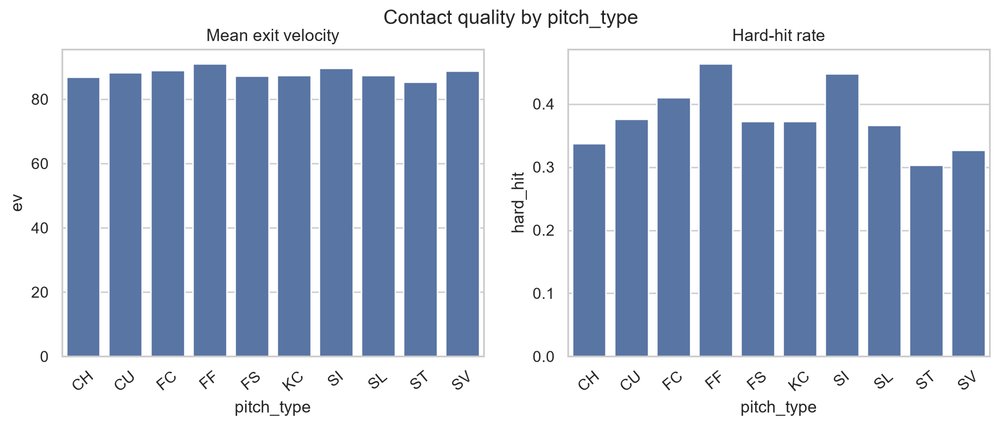

In [36]:
group='pitch_type'
if len(batted):
    x=batted.groupby(group).agg(n=('launch_speed','size'),ev=('launch_speed','mean'),angle=('launch_angle','mean'),hard_hit=('hard_hit','mean')).reset_index().query('n>=30')
    display(x.round(3))
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    sns.barplot(data=x,x=group,y='ev',ax=axes[0]);sns.barplot(data=x,x=group,y='hard_hit',ax=axes[1])
    axes[0].set_title('Mean exit velocity');axes[1].set_title('Hard-hit rate');fig.suptitle('Contact quality by pitch_type')
    for ax in axes: ax.tick_params(axis='x',rotation=40)
    publish(fig,'contact_quality_pitch_type')

### Batter–pitcher handedness matchups | 95% Wilson intervals
Grouping only by batter or pitcher handedness can conceal a matchup interaction. This plot compares the four handedness combinations, subject to a minimum tracked-BBE count.

,stand,p_throws,n,hard_hits,mean_ev,rate,low,high,matchup
0,L,L,1401,493,86.384,0.352,0.327,0.377,Batter L / Pitcher L
1,L,R,6896,2875,89.548,0.417,0.405,0.429,Batter L / Pitcher R
2,R,L,3532,1473,89.006,0.417,0.401,0.433,Batter R / Pitcher L
3,R,R,7459,2996,88.589,0.402,0.391,0.413,Batter R / Pitcher R


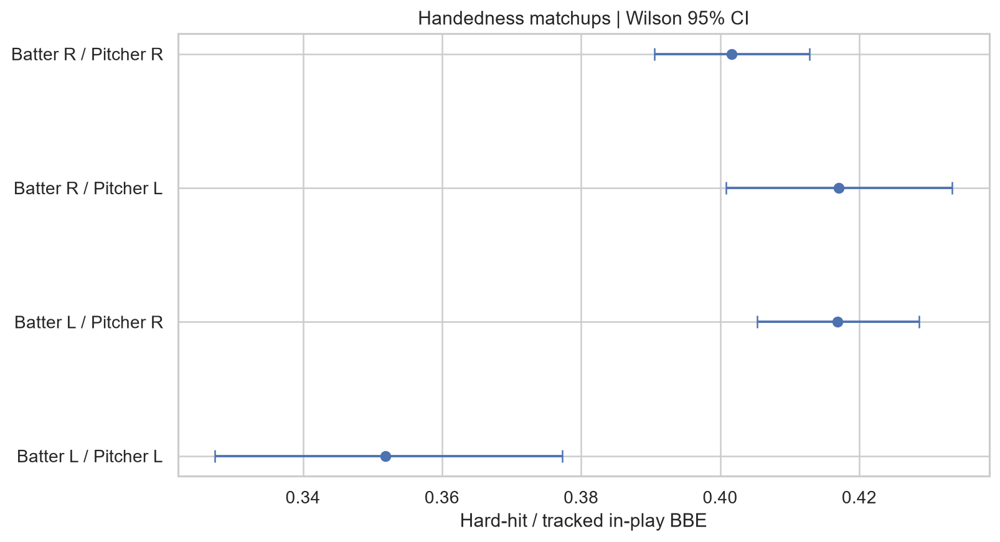

In [37]:
from statsmodels.stats.proportion import proportion_confint
if not batted.empty:
    matchups = (batted.groupby(['stand','p_throws']).agg(
        n=('hard_hit','size'), hard_hits=('hard_hit','sum'), mean_ev=('launch_speed','mean')
    ).reset_index().query('n >= 50').copy())
    if not matchups.empty:
        lo, hi = proportion_confint(matchups['hard_hits'],matchups['n'],alpha=.05,method='wilson')
        matchups['rate'] = matchups['hard_hits']/matchups['n']
        matchups['low'],matchups['high'] = lo,hi
        matchups['matchup'] = 'Batter '+matchups.stand+' / Pitcher '+matchups.p_throws
        display(matchups.round(3))
        fig,ax=plt.subplots(figsize=(9,5))
        y=np.arange(len(matchups))
        ax.errorbar(matchups['rate'],y,xerr=[matchups['rate']-matchups['low'],matchups['high']-matchups['rate']],fmt='o',capsize=4)
        ax.set_yticks(y,matchups['matchup'])
        ax.set(xlabel='Hard-hit / tracked in-play BBE',title='Handedness matchups | Wilson 95% CI')
        fig.tight_layout()
        publish(fig,'contact_quality_handedness_ci')

### Count × pitch family contact quality
A heatmap replaces two separate balls/strikes bar charts. Blank cells lack adequate tracked BBE; this is not evidence of zero hard-hit probability.

,pitch_type,count_state,n,hard_hits,rate
55,FF,0-0,1083,513,0.474
103,SI,0-0,806,382,0.474
63,FF,2-2,607,250,0.412
60,FF,1-2,576,233,0.405
66,FF,3-2,565,259,0.458
56,FF,0-1,539,239,0.443
59,FF,1-1,509,239,0.470
58,FF,1-0,492,261,0.530
115,SL,0-0,426,178,0.418
104,SI,0-1,417,169,0.405


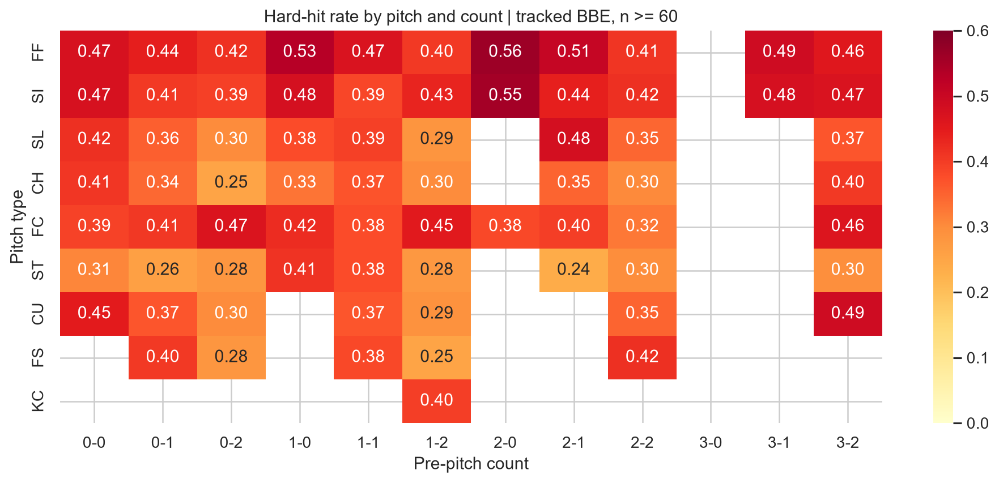

In [38]:
if not batted.empty:
    ct=batted.groupby(['pitch_type','count_state']).agg(
        n=('hard_hit','size'),hard_hits=('hard_hit','sum')).reset_index()
    ct['rate']=ct.hard_hits/ct.n
    ct.loc[ct.n < 60,'rate']=np.nan
    key_types=batted.pitch_type.value_counts().head(9).index
    mat=ct[ct.pitch_type.isin(key_types)].pivot(index='pitch_type',columns='count_state',values='rate')
    col_order=[f'{b}-{s}' for b in range(4) for s in range(3)]
    mat=mat.reindex(index=key_types,columns=col_order)
    display(ct.query('n>=60').sort_values('n',ascending=False).head(20).round(3))
    fig,ax=plt.subplots(figsize=(13,5))
    sns.heatmap(mat,annot=True,fmt='.2f',cmap='YlOrRd',vmin=0,vmax=.6,ax=ax)
    ax.set(title='Hard-hit rate by pitch and count | tracked BBE, n >= 60',xlabel='Pre-pitch count',ylabel='Pitch type')
    publish(fig,'contact_quality_count_pitch_heatmap')

### Season-wise contact distributions
A mean can hide the shape of the launch-speed distribution. These are comparisons of two observed May windows when `SAMPLE_MODE=True`, not full-season league changes.

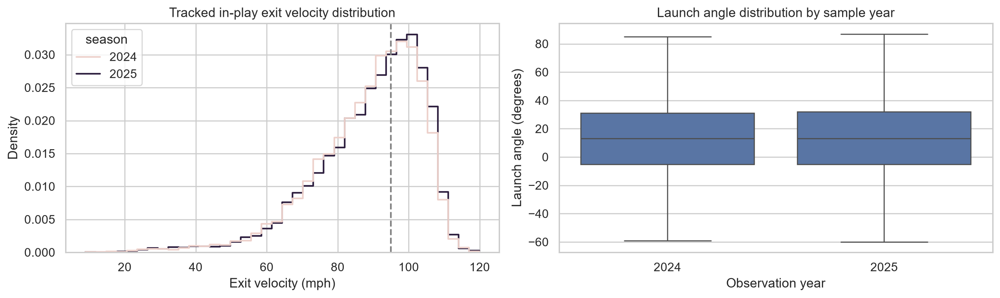

In [39]:
if not batted.empty:
    draw=batted.sample(n=min(len(batted),14000),random_state=42)
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    sns.histplot(data=draw,x='launch_speed',hue='season',stat='density',common_norm=False,
                 element='step',fill=False,bins=38,ax=axes[0])
    axes[0].axvline(95,ls='--',color='gray',label='95 mph')
    axes[0].set(title='Tracked in-play exit velocity distribution',xlabel='Exit velocity (mph)')
    sns.boxplot(data=draw,x='season',y='launch_angle',showfliers=False,ax=axes[1])
    axes[1].set(title='Launch angle distribution by sample year',xlabel='Observation year',ylabel='Launch angle (degrees)')
    fig.tight_layout()
    publish(fig,'contact_quality_year_distributions')

### BBE scatter by launch speed and angle
A two-dimensional batted-ball view can reveal contact regimes missed by aggregated bar charts. Only points with both measured exit velocity and launch angle are used for this chart.

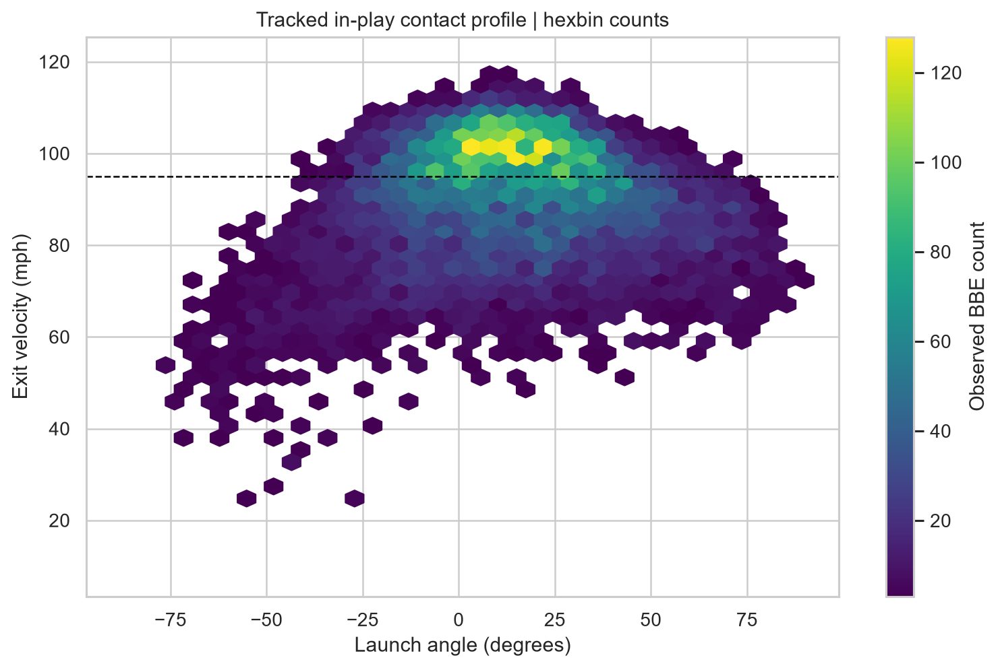

In [40]:
if not batted.empty:
    x=batted.dropna(subset=['launch_angle']).sample(n=min(len(batted.dropna(subset=['launch_angle'])),14000),random_state=42)
    fig,ax=plt.subplots(figsize=(10,6))
    hb=ax.hexbin(x.launch_angle,x.launch_speed,gridsize=38,mincnt=3,cmap='viridis')
    ax.axhline(95,ls='--',color='black',lw=1)
    ax.set(xlabel='Launch angle (degrees)',ylabel='Exit velocity (mph)',title='Tracked in-play contact profile | hexbin counts')
    fig.colorbar(hb,ax=ax,label='Observed BBE count')
    publish(fig,'bbe_ev_angle_hexbin')

### Hitter vs pitcher contact allowed (tracked BBE)
Rank eligible hitters and pitchers separately. Each statistic is conditioned on a ball being put in play and measured, not the frequency of hard-hit contact per plate appearance.

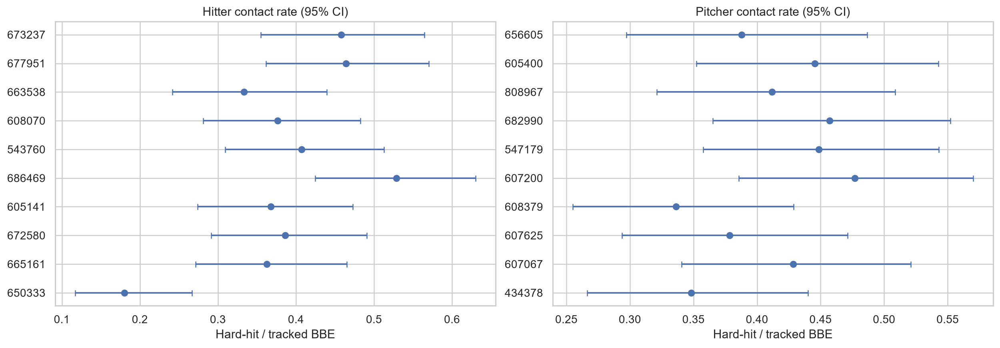

In [41]:
if not batted.empty:
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    for ax,entity,label in [(axes[0],'batter','Hitter'),(axes[1],'pitcher','Pitcher')]:
        t=batted.groupby(entity).agg(n=('hard_hit','size'),k=('hard_hit','sum')).query('n>=40').copy()
        if t.empty:
            ax.text(.5,.5,'Insufficient sample',ha='center',transform=ax.transAxes)
            continue
        t['rate']=t.k/t.n
        lo,hi=proportion_confint(t.k,t.n,method='wilson');t['low']=lo;t['high']=hi
        t=t.sort_values('n',ascending=False).head(10)
        y=np.arange(len(t));ax.errorbar(t.rate,y,xerr=[t.rate-t.low,t.high-t.rate],fmt='o',capsize=3)
        ax.set_yticks(y,t.index.astype(str));ax.set(xlabel='Hard-hit / tracked BBE',title=f'{label} contact rate (95% CI)')
    fig.tight_layout();publish(fig,'hitter_pitcher_hard_hit_ci')

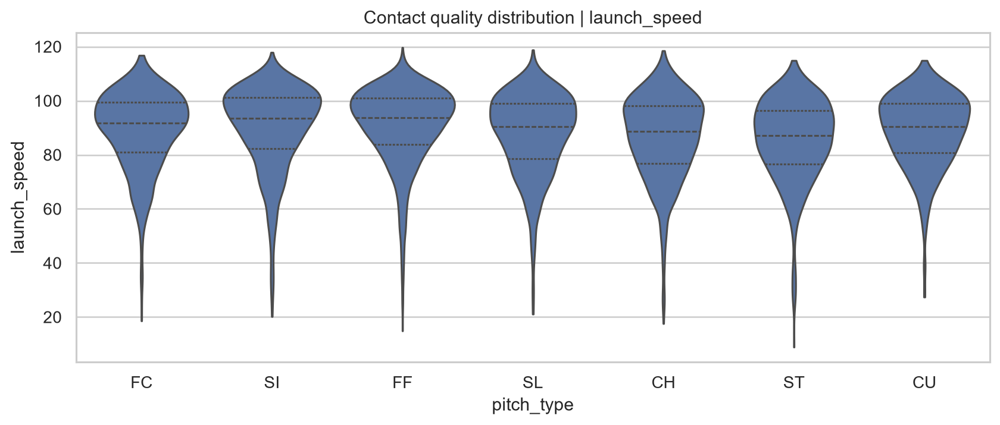

In [42]:
field='launch_speed'
if len(batted):
    x=batted[[field,'pitch_type']].dropna()
    keep=x.pitch_type.value_counts().head(7).index
    x=x[x.pitch_type.isin(keep)].sample(n=min(10000,len(x)),random_state=42)
    fig,ax=plt.subplots(figsize=(11,4));sns.violinplot(data=x,x='pitch_type',y=field,inner='quart',cut=0,ax=ax)
    ax.set(title='Contact quality distribution | launch_speed')
    publish(fig,'batted_violin_launch_speed')

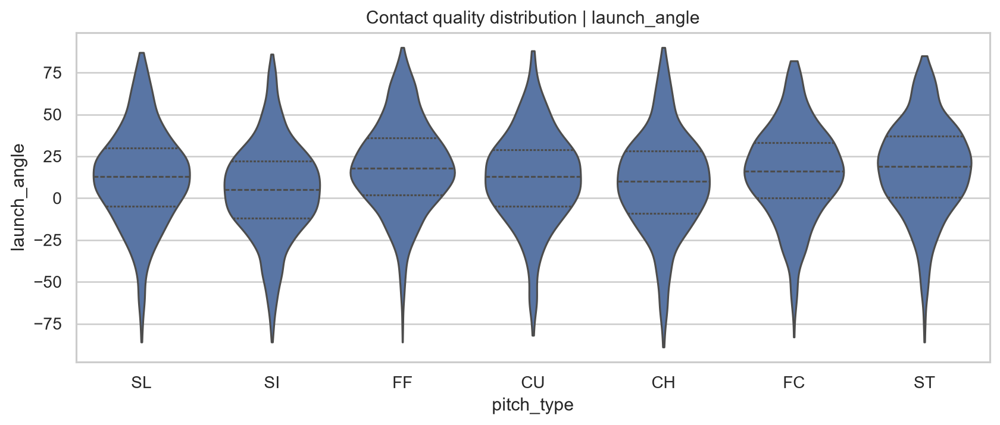

In [43]:
field='launch_angle'
if len(batted):
    x=batted[[field,'pitch_type']].dropna()
    keep=x.pitch_type.value_counts().head(7).index
    x=x[x.pitch_type.isin(keep)].sample(n=min(10000,len(x)),random_state=42)
    fig,ax=plt.subplots(figsize=(11,4));sns.violinplot(data=x,x='pitch_type',y=field,inner='quart',cut=0,ax=ax)
    ax.set(title='Contact quality distribution | launch_angle')
    publish(fig,'batted_violin_launch_angle')

## 5 | Situational Pitching & Within-PA Sequencing
**Question:** what pitch combinations are observed within plate appearances? Selection is contextual, and raw transition percentages must not be interpreted as causal effects.

In [44]:
seq=sequencing(df)
print('Sequenced observations:',len(seq));display(seq.head(3))

Sequenced observations: 81085


,pitch_type,game_date,release_speed,release_pos_x,release_pos_z,player_name,batter,pitcher,events,description,...,count_state,velocity,spin,exit_velocity,launch_angle_clean,is_bbe,hard_hit,previous_pitch,previous_velocity,velocity_delta
26252,SL,2024-05-08,82.8,2.00,5.95,"Parker, Mitchell",683002,680730,NaN,ball,...,0-1,82.8,2255.0,NaN,NaN,False,NaN,FF,93.6,-10.8
26253,FF,2024-05-08,93.7,1.81,6.05,"Parker, Mitchell",683002,680730,NaN,ball,...,1-1,93.7,2302.0,NaN,NaN,False,NaN,SL,82.8,10.9
26254,FF,2024-05-08,93.8,1.72,6.08,"Parker, Mitchell",683002,680730,single,hit_into_play,...,2-1,93.8,2349.0,99.4,-2.0,True,True,FF,93.7,0.1


### Pitch usage conditional on count
A sequencing model should explicitly account for the count-dependent pitch mix. This plot captures the observed choice distribution, not an optimal recommendation.

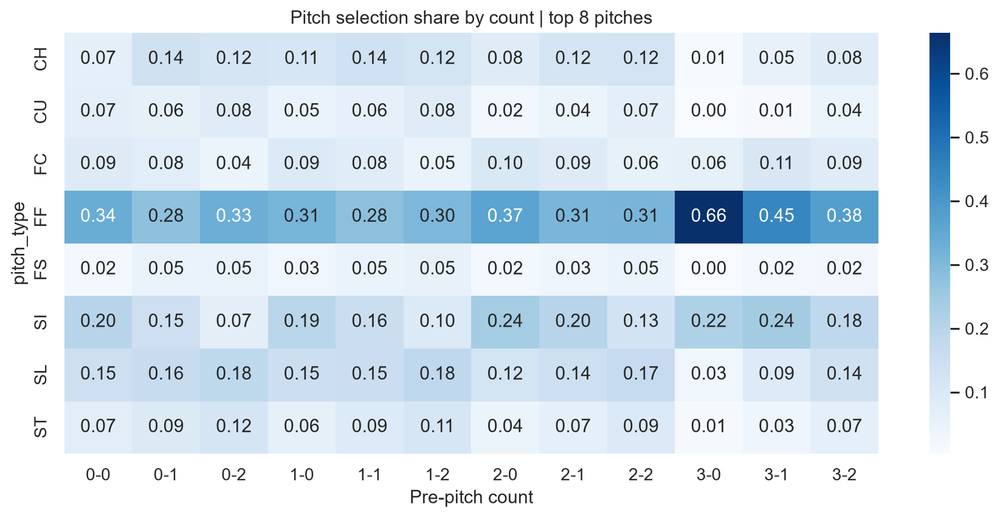

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/count_pitch_usage_share.png')

In [45]:
use=df.groupby(['count_state','pitch_type']).size().rename('n').reset_index()
top_types=df.pitch_type.value_counts().head(8).index
use=use[use.pitch_type.isin(top_types)]
mat=use.pivot(index='pitch_type',columns='count_state',values='n').fillna(0)
mat=mat.div(mat.sum(axis=0).replace(0,np.nan),axis=1)
order=[f'{b}-{s}' for b in range(4) for s in range(3)]
fig,ax=plt.subplots(figsize=(12,5))
sns.heatmap(mat.reindex(columns=order),cmap='Blues',annot=True,fmt='.2f',ax=ax)
ax.set(title='Pitch selection share by count | top 8 pitches',xlabel='Pre-pitch count')
publish(fig,'count_pitch_usage_share')

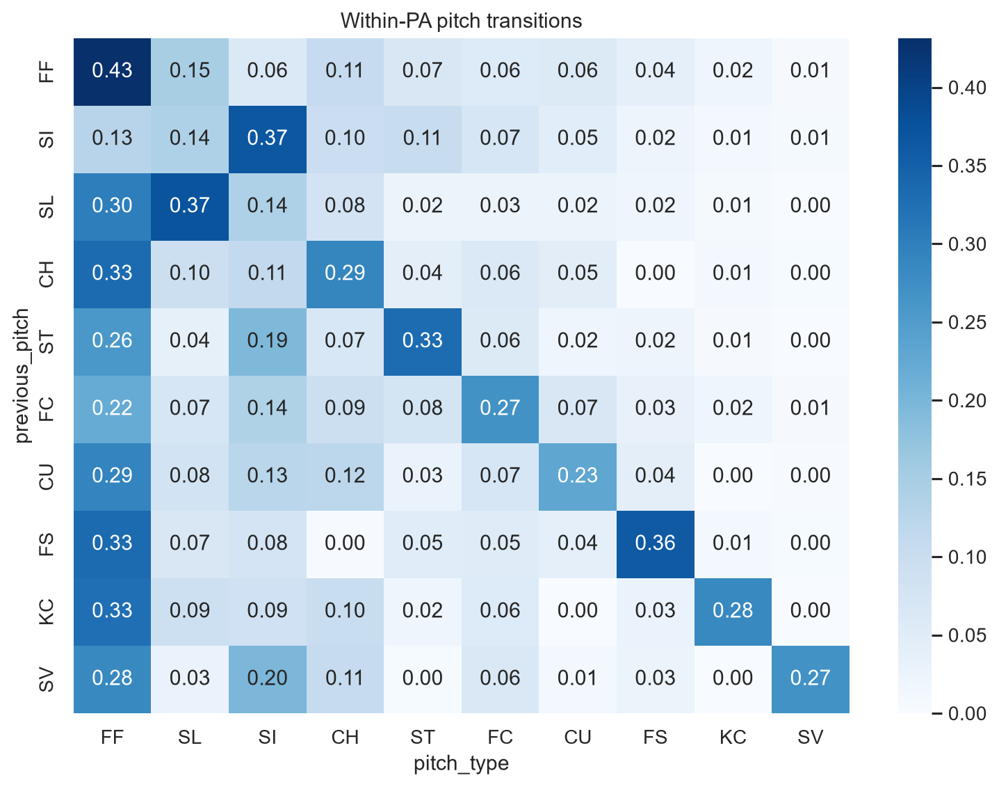

In [46]:
if {'previous_pitch','pitch_type'}.issubset(seq.columns):
    mat=pd.crosstab(seq.previous_pitch,seq.pitch_type)
    keep=mat.sum(1).nlargest(10).index;keep2=mat.sum(0).nlargest(10).index
    fraction=mat.loc[keep,keep2].div(mat.loc[keep].sum(1),axis=0)
    fig,ax=plt.subplots(figsize=(10,7));sns.heatmap(fraction,annot=True,fmt='.2f',cmap='Blues',ax=ax);ax.set(title='Within-PA pitch transitions');publish(fig,'16_pitch_transitions')

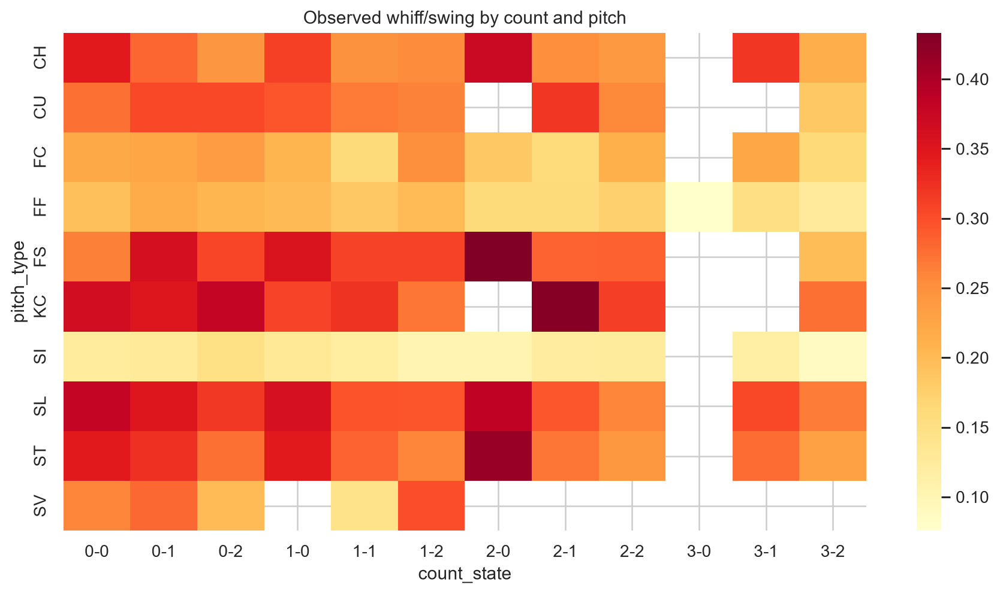

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/17_pitch_count_heatmap.png')

In [47]:
x=df.groupby(['count_state','pitch_type']).apply(rates,include_groups=False).reset_index().query('swings>=@MIN_SWINGS')
heat=x.pivot(index='pitch_type',columns='count_state',values='whiff_per_swing')
order=[f'{b}-{s}' for b in range(4) for s in range(3)]
fig,ax=plt.subplots(figsize=(12,6));sns.heatmap(heat.reindex(columns=order),cmap='YlOrRd',annot=False,ax=ax);ax.set(title='Observed whiff/swing by count and pitch');publish(fig,'17_pitch_count_heatmap')

In [48]:
if {'previous_pitch','pitch_type','whiff'}.issubset(seq):
    trans=seq.groupby(['previous_pitch','pitch_type']).agg(n=('whiff','size'),whiff_per_pitch=('whiff','mean')).query('n>=100').sort_values('n',ascending=False)
    display(trans.head(25));trans.to_csv(REPORTDIR/'sequence_transition_outcomes.csv')

n  whiff_per_pitch
previous_pitch pitch_type                        
FF             FF          11110         0.098650
SI             SI           4647         0.061330
SL             SL           4486         0.193714
FF             SL           3845         0.144083
SL             FF           3647         0.104744
FF             CH           2787         0.129530
CH             FF           2669         0.095167
               CH           2341         0.145664
ST             ST           2161         0.144378
SI             SL           1773         0.152848
SL             SI           1703         0.061069
FF             ST           1693         0.139398
ST             FF           1682         0.092747
FC             FC           1639         0.112264
SI             FF           1630         0.108589
FF             SI           1604         0.062968
               CU           1498         0.118825
CU             FF           1471         0.093814
FF             FC           1437         0.109951
FC             FF           1354         0.079025
SI             ST           1345         0.127138
ST             SI           1268         0.085962
SI             CH           1221         0.128583
CU             CU           1159         0.138913
FF             FS           1031         0.154219

### Pitch-transition conditional whiff rates
Separate pitch selection frequencies from **whiffs per swing** after specific pitch transitions, and mask insufficient observations.

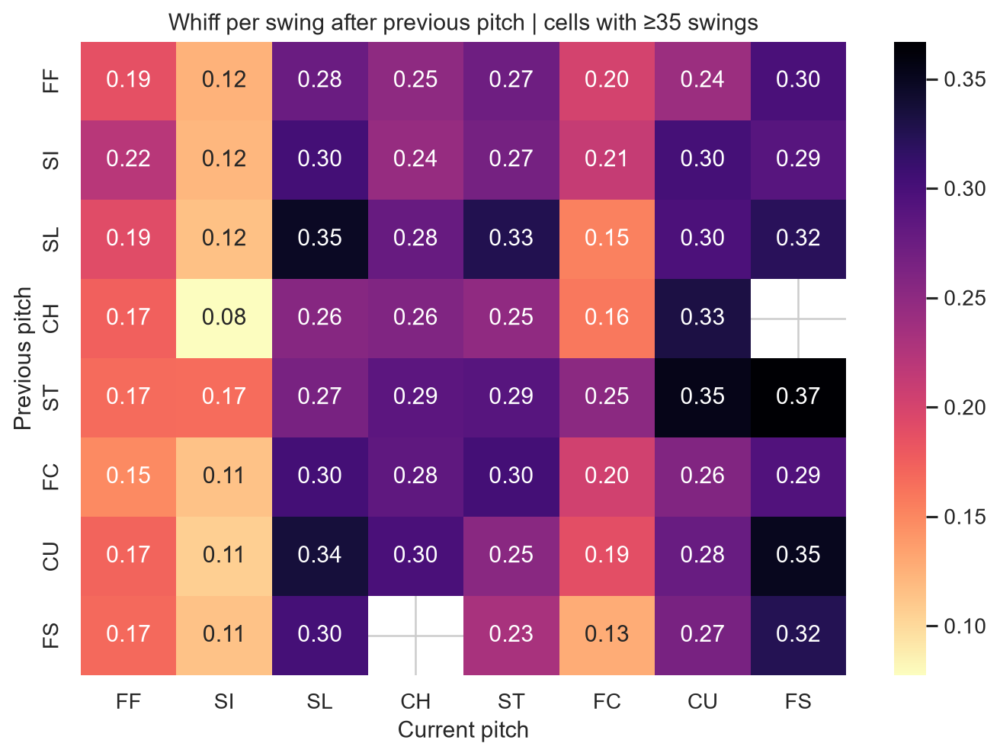

In [49]:
if {'previous_pitch','pitch_type','swing_ind','whiff_ind'}.issubset(seq.columns):
    s=seq.loc[seq.previous_pitch.notna() & seq.swing_ind.eq(1)].copy()
    rates_seq=s.groupby(['previous_pitch','pitch_type']).agg(n=('whiff_ind','size'),whiffs=('whiff_ind','sum')).reset_index()
    rates_seq['rate']=rates_seq.whiffs/rates_seq.n
    rates_seq.loc[rates_seq.n<35,'rate']=np.nan
    primary=df.pitch_type.value_counts().head(8).index
    rates_seq=rates_seq[rates_seq.previous_pitch.isin(primary)&rates_seq.pitch_type.isin(primary)]
    mat=rates_seq.pivot(index='previous_pitch',columns='pitch_type',values='rate').reindex(index=primary,columns=primary)
    fig,ax=plt.subplots(figsize=(9,6))
    sns.heatmap(mat,cmap='magma_r',annot=True,fmt='.2f',ax=ax)
    ax.set(title='Whiff per swing after previous pitch | cells with ≥35 swings',xlabel='Current pitch',ylabel='Previous pitch')
    publish(fig,'sequence_whiff_per_swing')

,n,avg_delta_re
pitch_type,,
CH,11022,0.001936
CU,6519,0.004987
FC,8182,-0.003089
FF,34391,-0.000708
FO,144,-0.010146
FS,3673,-0.002079
KC,2005,-0.009337
SI,17537,-0.002328
SL,16324,-0.003086


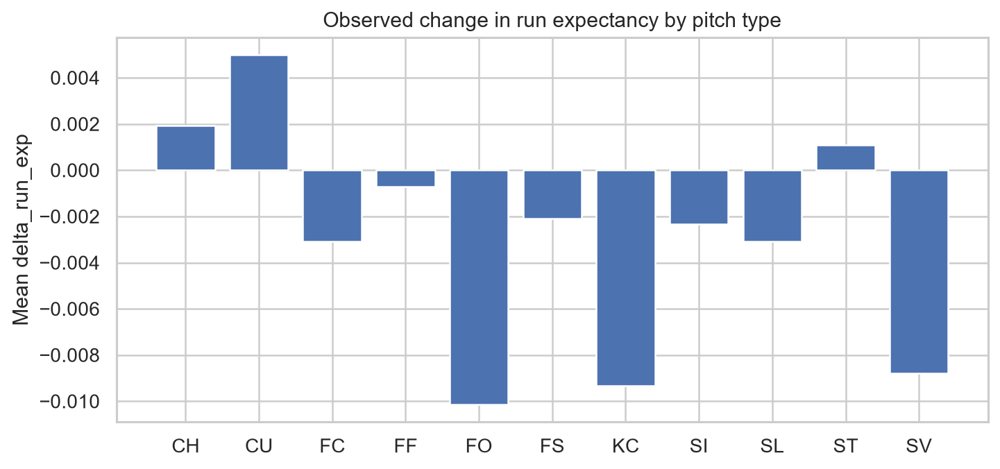

In [50]:
if 'delta_run_exp' in df:
    d=df.copy();d['delta_run_exp']=pd.to_numeric(d.delta_run_exp,errors='coerce')
    q=d.groupby('pitch_type').agg(n=('delta_run_exp','count'),avg_delta_re=('delta_run_exp','mean')).query('n>=100')
    display(q)
    fig,ax=plt.subplots(figsize=(9,4));ax.bar(q.index,q.avg_delta_re);ax.set(title='Observed change in run expectancy by pitch type',ylabel='Mean delta_run_exp');publish(fig,'18_observed_run_expectancy')

### Pitch sequences and situation decomposition

,count_state,pitch_type,n,whiffs,swings,whiff_rate
6,0-0,FF,9241,603,3121,0.193207
12,0-0,SI,5483,212,1715,0.123615
13,0-0,SL,4021,516,1359,0.379691
22,0-1,FF,3824,409,1875,0.218133
54,1-0,FF,3262,286,1427,0.200420
84,1-2,FF,3124,367,1846,0.198808
69,1-1,FF,2991,307,1671,0.183722
126,2-2,FF,2693,310,1783,0.173864
5,0-0,FC,2384,182,828,0.219807
38,0-2,FF,2381,256,1249,0.204964


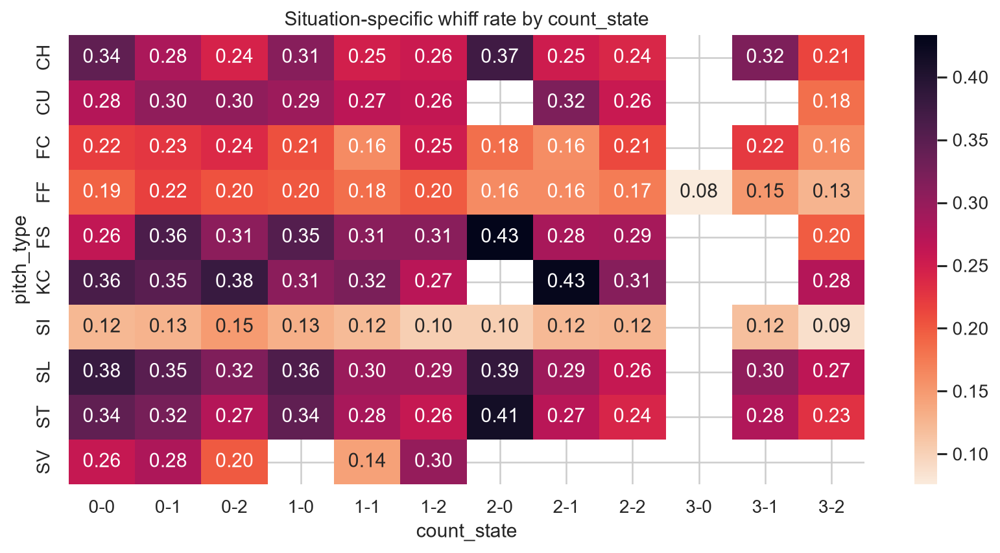

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/situation_heatmap_count_state.png')

In [51]:
group='count_state'
x=df.groupby([group,'pitch_type']).agg(n=('whiff_ind','size'),whiffs=('whiff_ind','sum'),swings=('swing_ind','sum')).reset_index().query('n>=40')
x['whiff_rate']=x.whiffs/x.swings.replace(0,np.nan)
x.loc[x.swings<30,'whiff_rate']=np.nan
mat=x.pivot(index='pitch_type',columns=group,values='whiff_rate')
display(x.sort_values('n',ascending=False).head(10))
fig,ax=plt.subplots(figsize=(11,5));sns.heatmap(mat,annot=True,fmt='.2f',cmap='rocket_r',ax=ax)
ax.set(title='Situation-specific whiff rate by count_state')
publish(fig,'situation_heatmap_count_state')

,stand,pitch_type,n,whiffs,swings,whiff_rate
23,R,FF,18111,1760,8911,0.197509
6,L,FF,16280,1306,7708,0.169434
29,R,SI,11390,635,5213,0.121811
30,R,SL,10302,1610,4988,0.322775
12,L,SI,6147,318,2726,0.116654
13,L,SL,6022,962,3041,0.316343
31,R,ST,5758,771,2629,0.293267
0,L,CH,5557,706,2702,0.261288
17,R,CH,5465,798,2810,0.283986
22,R,FC,4339,470,2145,0.219114


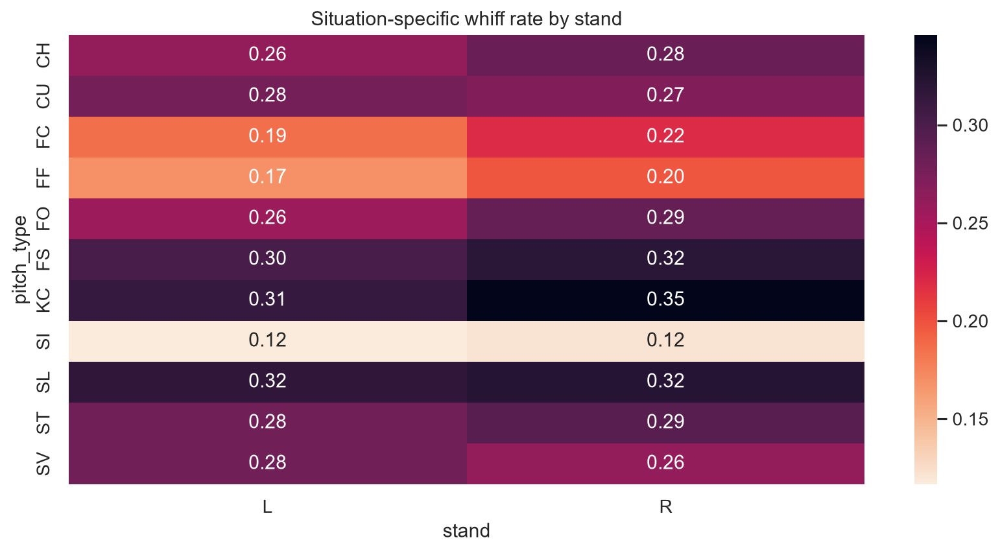

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/situation_heatmap_stand.png')

In [52]:
group='stand'
x=df.groupby([group,'pitch_type']).agg(n=('whiff_ind','size'),whiffs=('whiff_ind','sum'),swings=('swing_ind','sum')).reset_index().query('n>=40')
x['whiff_rate']=x.whiffs/x.swings.replace(0,np.nan)
x.loc[x.swings<30,'whiff_rate']=np.nan
mat=x.pivot(index='pitch_type',columns=group,values='whiff_rate')
display(x.sort_values('n',ascending=False).head(10))
fig,ax=plt.subplots(figsize=(11,5));sns.heatmap(mat,annot=True,fmt='.2f',cmap='rocket_r',ax=ax)
ax.set(title='Situation-specific whiff rate by stand')
publish(fig,'situation_heatmap_stand')

,p_throws,pitch_type,n,whiffs,swings,whiff_rate
20,R,FF,25688,2259,12334,0.183152
26,R,SI,12565,654,5641,0.115937
27,R,SL,12479,1954,6141,0.318189
6,L,FF,8703,807,4285,0.188331
14,R,CH,7362,971,3652,0.265882
28,R,ST,6708,845,2969,0.284608
19,R,FC,6409,627,3170,0.197792
10,L,SI,4972,299,2298,0.130113
16,R,CU,4652,511,1897,0.269373
11,L,SL,3845,618,1888,0.327331


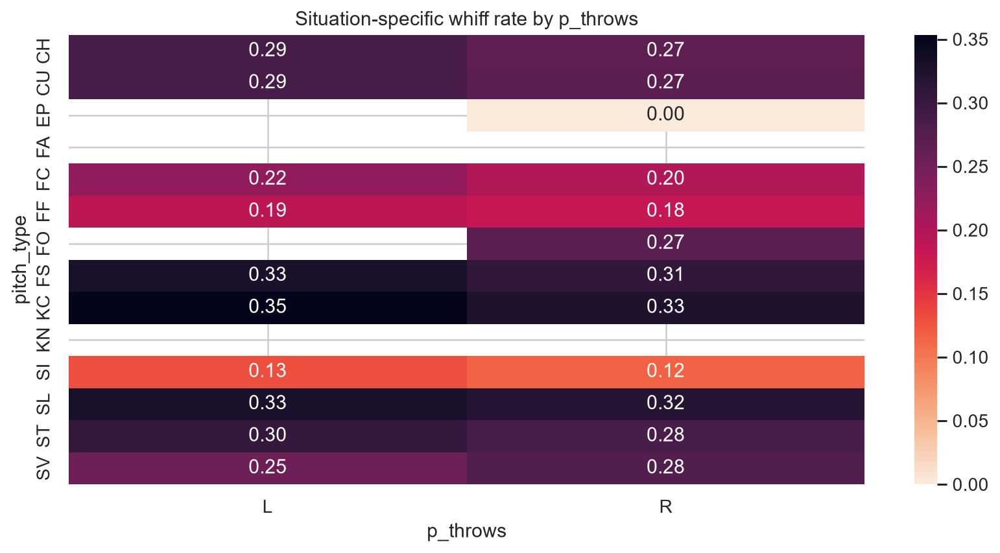

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/situation_heatmap_p_throws.png')

In [53]:
group='p_throws'
x=df.groupby([group,'pitch_type']).agg(n=('whiff_ind','size'),whiffs=('whiff_ind','sum'),swings=('swing_ind','sum')).reset_index().query('n>=40')
x['whiff_rate']=x.whiffs/x.swings.replace(0,np.nan)
x.loc[x.swings<30,'whiff_rate']=np.nan
mat=x.pivot(index='pitch_type',columns=group,values='whiff_rate')
display(x.sort_values('n',ascending=False).head(10))
fig,ax=plt.subplots(figsize=(11,5));sns.heatmap(mat,annot=True,fmt='.2f',cmap='rocket_r',ax=ax)
ax.set(title='Situation-specific whiff rate by p_throws')
publish(fig,'situation_heatmap_p_throws')

,season,pitch_type,n,whiffs,swings,whiff_rate
22,2025,FF,17586,1522,8462,0.179863
6,2024,FF,16805,1544,8157,0.189285
12,2024,SI,8867,448,3997,0.112084
27,2025,SI,8670,505,3942,0.128108
13,2024,SL,8172,1323,4042,0.327313
28,2025,SL,8152,1249,3987,0.313268
0,2024,CH,5558,742,2764,0.268452
16,2025,CH,5464,762,2748,0.277293
29,2025,ST,4542,572,2011,0.284436
5,2024,FC,4344,465,2143,0.216986


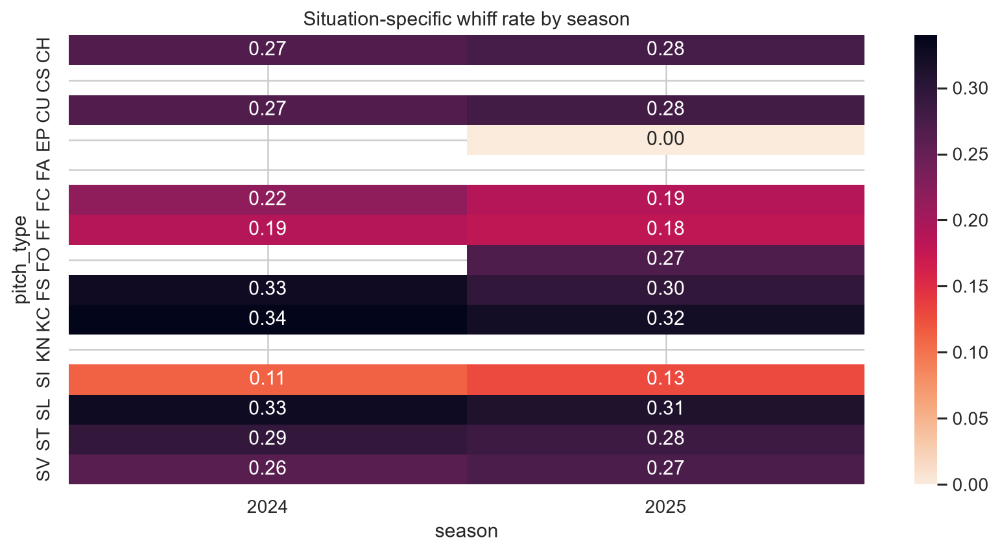

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/situation_heatmap_season.png')

In [54]:
group='season'
x=df.groupby([group,'pitch_type']).agg(n=('whiff_ind','size'),whiffs=('whiff_ind','sum'),swings=('swing_ind','sum')).reset_index().query('n>=40')
x['whiff_rate']=x.whiffs/x.swings.replace(0,np.nan)
x.loc[x.swings<30,'whiff_rate']=np.nan
mat=x.pivot(index='pitch_type',columns=group,values='whiff_rate')
display(x.sort_values('n',ascending=False).head(10))
fig,ax=plt.subplots(figsize=(11,5));sns.heatmap(mat,annot=True,fmt='.2f',cmap='rocket_r',ax=ax)
ax.set(title='Situation-specific whiff rate by season')
publish(fig,'situation_heatmap_season')

## 6 | Inference and Uncertainty
**Question:** how precise are descriptive rates, and which contrasts remain meaningful under resampling? Tests are exploratory and do not identify intervention effects.

,pitch_type,swings,whiff_per_swing,ci_low,ci_high
22,FF,8462.0,0.179863,0.171826,0.188191
27,SI,3942.0,0.128108,0.118035,0.138904
28,SL,3987.0,0.313268,0.299057,0.327839
16,CH,2748.0,0.277293,0.260875,0.294332
29,ST,2011.0,0.284436,0.265143,0.304550
21,FC,1901.0,0.188322,0.171382,0.206519
18,CU,1357.0,0.280029,0.256786,0.304515
24,FS,1041.0,0.295869,0.268934,0.324306
25,KC,483.0,0.322981,0.282817,0.365939
30,SV,172.0,0.273256,0.212157,0.344262


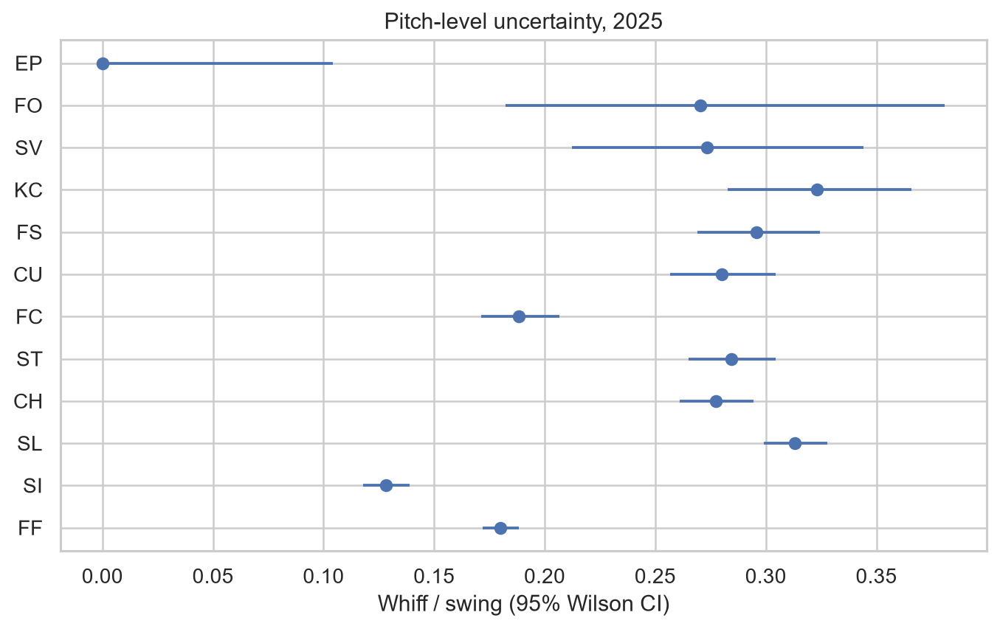

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/19_pitch_rate_ci.png')

In [55]:
from statsmodels.stats.proportion import proportion_confint
p=pitch_rates.copy();p['ci_low'],p['ci_high']=proportion_confint(p.whiffs.astype(int),p.swings.clip(lower=1).astype(int),alpha=.05,method='wilson');p.loc[p.swings.eq(0),['ci_low','ci_high']]=np.nan
selected=p.query('swings>=@MIN_SWINGS & season==2025').sort_values('pitches',ascending=False).head(12);display(selected[['pitch_type','swings','whiff_per_swing','ci_low','ci_high']])
fig,ax=plt.subplots(figsize=(9,5));y=np.arange(len(selected));ax.errorbar(selected.whiff_per_swing,y,xerr=[selected.whiff_per_swing-selected.ci_low,selected.ci_high-selected.whiff_per_swing],fmt='o');ax.set_yticks(y,selected.pitch_type);ax.set(xlabel='Whiff / swing (95% Wilson CI)',title='Pitch-level uncertainty, 2025');publish(fig,'19_pitch_rate_ci')

In [56]:
contingency=pd.crosstab(df.pitch_type,df.whiff_ind).loc[lambda x:x.sum(axis=1)>=MIN_N]
chi2,pvalue,dof,expected=stats.chi2_contingency(contingency)
print({'chi_square':chi2,'p_value':pvalue,'df':dof,'n':int(contingency.to_numpy().sum())})
print('Association only; repeated pitches and pitcher differences violate simple independence assumptions.')

{'chi_square': np.float64(1342.79437388631), 'p_value': np.float64(2.219241830230239e-282), 'df': 10, 'n': 109118}
Association only; repeated pitches and pitcher differences violate simple independence assumptions.


In [57]:
sub=df[['game_pk','pitch_type','swing_ind','whiff_ind']].dropna();top2=df.pitch_type.value_counts().head(2).index.tolist();sub=sub[sub.pitch_type.isin(top2)]
agg=sub.groupby(['game_pk','pitch_type']).agg(swings=('swing_ind','sum'),whiffs=('whiff_ind','sum')).reset_index()
games=agg.game_pk.unique();rng=np.random.default_rng(42);diff=[]
for _ in range(250):
    sampled=rng.choice(games,len(games),replace=True);counts=pd.Series(sampled).value_counts()
    z=agg.join(counts.rename('w'),on='game_pk').dropna(subset=['w']);z['ws']=z.swings*z.w;z['ww']=z.whiffs*z.w
    r=z.groupby('pitch_type')[['ws','ww']].sum()
    if all(k in r.index for k in top2) and r.loc[top2,'ws'].min()>0:
        diff.append(r.loc[top2[0],'ww']/r.loc[top2[0],'ws']-r.loc[top2[1],'ww']/r.loc[top2[1],'ws'])
print('Observed comparison:',top2,'| Game bootstrap 95% CI:',np.quantile(diff,[.025,.975]) if diff else None)

Observed comparison: ['FF', 'SI'] | Game bootstrap 95% CI: [0.05479694 0.07424507]


### Statistical evidence | effect size before significance
At large pitch counts, a trivial association can have a tiny p-value. Cramér's V reports relative association size, and these tests remain descriptive because pitches are clustered within pitchers, batters and games.

In [58]:
if {'pitch_type','whiff_ind'}.issubset(df):
    tabs=pd.crosstab(df.pitch_type,df.whiff_ind)
    tabs=tabs.loc[tabs.sum(axis=1).ge(100)]
    chi2,p,dof,expected=stats.chi2_contingency(tabs)
    n=tabs.to_numpy().sum()
    cramers_v=np.sqrt(chi2/(n*max(1,min(tabs.shape)-1)))
    display(pd.DataFrame([{'test':'Pitch type vs whiff per pitch','N':n,'chi_square':chi2,'p_value':p,'cramers_v':cramers_v}]).round(5))

,test,N,chi_square,p_value,cramers_v
0,Pitch type vs whiff per pitch,109118,1342.79437,0.0,0.11093


### Observed count-contact tradeoff
Compare hard-hit confidence intervals across 12 ball–strike states. This is a joint-state descriptive comparison instead of separate balls and strikes charts.

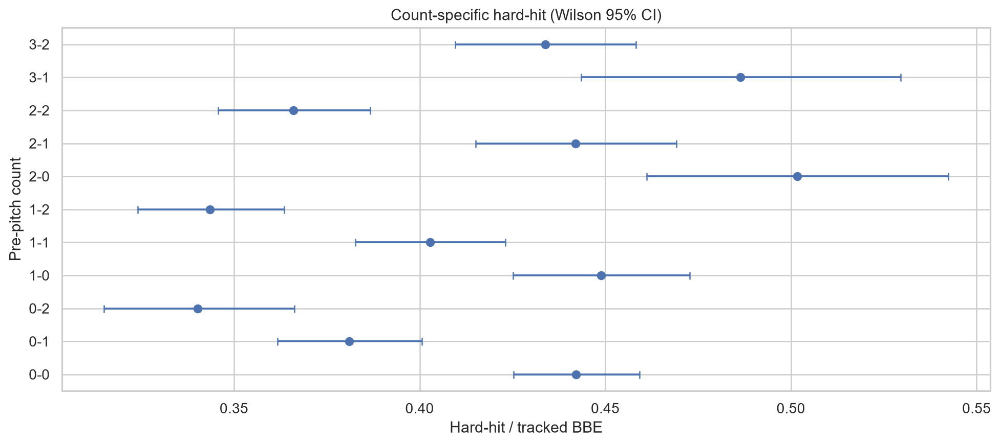

In [59]:
if not batted.empty:
    counts=batted.groupby('count_state').agg(n=('hard_hit','size'),k=('hard_hit','sum')).reset_index().query('n>=60').copy()
    counts['rate']=counts.k/counts.n
    lo,hi=proportion_confint(counts.k,counts.n,method='wilson')
    counts['low'],counts['high']=lo,hi
    counts['ball']=counts.count_state.str.split('-').str[0].astype(int)
    counts['strike']=counts.count_state.str.split('-').str[1].astype(int)
    counts=counts.sort_values(['ball','strike'])
    fig,ax=plt.subplots(figsize=(11,5))
    y=np.arange(len(counts))
    ax.errorbar(counts.rate,y,xerr=[counts.rate-counts.low,counts.high-counts.rate],fmt='o',capsize=3)
    ax.set_yticks(y,counts.count_state);ax.set(xlabel='Hard-hit / tracked BBE',ylabel='Pre-pitch count',title='Count-specific hard-hit (Wilson 95% CI)')
    fig.tight_layout();publish(fig,'count_hard_hit_wilson_ci')

### Robustness and uncertainty: additional confidence intervals

# Division III — Prediction, Inference & Calibration

*This division contains detailed technical experiments; the submission report selects the most defensible results.*

## 7 | Predictive Modeling and Generalization

**Research question:** can physically measured pitch features predict a whiff? Model candidates are compared on the same **chronological 2024 validation set**, then the selected algorithm is refit on 2024 observations and retrospectively evaluated on the 2025 period. Predictors include measured release and location features; these are **post-release descriptive models**, not guaranteed pre-pitch decisions. Model selection uses lowest validation Brier score (probability accuracy).

In [60]:
feature_cols = [x for x in ['pitch_type','stand','p_throws','release_speed','release_spin_rate',
                            'pfx_x','pfx_z','plate_x','plate_z','balls','strikes'] if x in df]
cat = [x for x in ['pitch_type','stand','p_throws'] if x in feature_cols]
num = [x for x in feature_cols if x not in cat]
base = df.dropna(subset=['pitch_type','stand','p_throws','game_date','whiff_ind']).copy()
train_all = base[base.season.eq(2024)].sort_values('game_date').copy()
hold = base[base.season.eq(2025)].sort_values('game_date').copy()
unique_days = train_all['game_date'].drop_duplicates().sort_values()
if len(unique_days) < 5:
    raise ValueError('Too few training dates for a chronological validation split')
cutoff = unique_days.iloc[max(0, int(len(unique_days)*0.75) - 1)]
tr = train_all.loc[train_all.game_date.le(cutoff)].copy()
va = train_all.loc[train_all.game_date.gt(cutoff)].copy()
assert len(tr) and len(va) and len(hold)
assert tr.game_date.max() < va.game_date.min()
print('Train', len(tr), '| Validate', len(va), '| Holdout', len(hold), '| Cutoff', cutoff.date())


Train 36810 | Validate 17190 | Holdout 55346 | Cutoff 2024-05-10


In [61]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB

def make_preprocess():
    return ColumnTransformer([
        ('cat', Pipeline([
            ('imp', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat),
        ('num', Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('scale', StandardScaler())
        ]), num)
    ], sparse_threshold=0)

models = {
    'Prevalence': DummyClassifier(strategy='prior'),
    'Logistic': LogisticRegression(max_iter=800),
    'RandomForest': RandomForestClassifier(n_estimators=120, max_depth=12, min_samples_leaf=12, n_jobs=-1, random_state=42),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=120, max_depth=12, min_samples_leaf=12, n_jobs=-1, random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=120, max_leaf_nodes=20, random_state=42),
    'SGDLogistic': SGDClassifier(loss='log_loss', alpha=0.0005, random_state=42),
    'GradientBoosting': GradientBoostingClassifier(n_estimators=80, learning_rate=.07, max_depth=2, subsample=.8, min_samples_leaf=30, random_state=42)
}

def score(y, p):
    y = np.asarray(y, dtype=int)
    p = np.clip(np.asarray(p, dtype=float), 1e-7, 1-1e-7)
    return {
        'ROC_AUC': roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan,
        'PR_AUC': average_precision_score(y, p),
        'Brier': brier_score_loss(y, p),
        'LogLoss': log_loss(y, p, labels=[0, 1])
    }
fits, validation_rows = {}, []
for name, est in models.items():
    obj = Pipeline([('prep', make_preprocess()), ('model', est)])
    obj.fit(tr[feature_cols], tr.whiff_ind.astype(int))
    prob = obj.predict_proba(va[feature_cols])[:, 1]
    fits[name] = obj
    validation_rows.append({'model': name, **score(va.whiff_ind, prob)})
validation = pd.DataFrame(validation_rows).sort_values('Brier').reset_index(drop=True)
display(validation.round(4))
validation.to_csv(REPORTDIR/'validation_metrics.csv', index=False)


,model,ROC_AUC,PR_AUC,Brier,LogLoss
0,HistGradientBoosting,0.7275,0.2175,0.0911,0.3116
1,RandomForest,0.7118,0.2187,0.0915,0.3171
2,GradientBoosting,0.6869,0.2007,0.0930,0.3248
3,ExtraTrees,0.6753,0.1899,0.0936,0.3271
4,Logistic,0.6239,0.1530,0.0951,0.3343
5,SGDLogistic,0.6196,0.1538,0.0952,0.3348
6,Prevalence,0.5000,0.1086,0.0968,0.3435


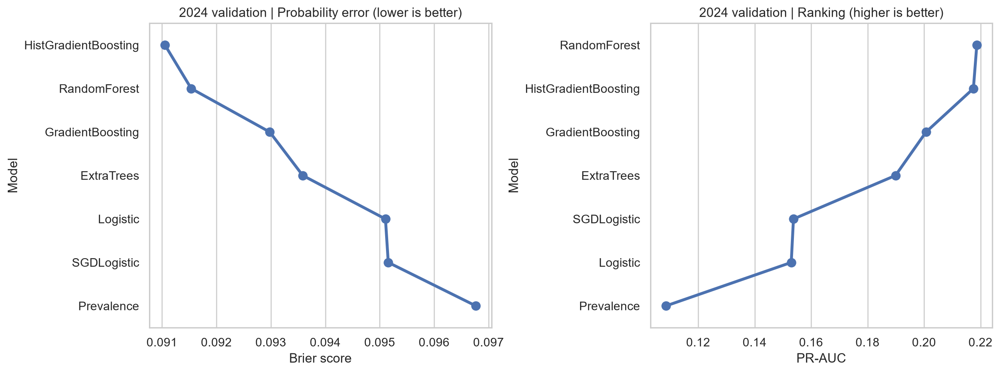

Selected based only on 2024 validation Brier: HistGradientBoosting


In [62]:
selected_name = validation.iloc[0]['model']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order = validation.sort_values('Brier')['model']
sns.pointplot(data=validation, x='Brier', y='model', order=order, ax=axes[0])
axes[0].set(title='2024 validation | Probability error (lower is better)', xlabel='Brier score', ylabel='Model')
order_pr = validation.sort_values('PR_AUC', ascending=False)['model']
sns.pointplot(data=validation, x='PR_AUC', y='model', order=order_pr, ax=axes[1])
axes[1].set(title='2024 validation | Ranking (higher is better)', xlabel='PR-AUC', ylabel='Model')
fig.tight_layout()
publish(fig, 'model_comparison_validation_all')
print('Selected based only on 2024 validation Brier:', selected_name)


**Model selection gate:** All candidate algorithms above are compared using the **same 2024 date-based validation set**. The 2025 evaluation below follows model selection on 2024 data. This 2025 period was subsequently viewed in repeated research iterations and must now be described as **retrospective**. Candidate differences on a two-week sample may be unstable.

In [63]:
final=Pipeline([('prep',make_preprocess()),('model',models[selected_name])]);final.fit(train_all[feature_cols],train_all.whiff_ind.astype(int))
hold_p=final.predict_proba(hold[feature_cols])[:,1];hold_y=hold.whiff_ind.astype(int).to_numpy();baseline=np.full(len(hold_y),train_all.whiff_ind.mean())
hold_metrics=pd.DataFrame([{'model':'Selected '+selected_name,**score(hold_y,hold_p)},{'model':'Train prevalence baseline',**score(hold_y,baseline)}]);display(hold_metrics);hold_metrics.to_csv(REPORTDIR/'holdout_metrics.csv',index=False)

,model,ROC_AUC,PR_AUC,Brier,LogLoss
0,Selected HistGradientBoosting,0.732864,0.226949,0.088679,0.305264
1,Train prevalence baseline,0.500000,0.106313,0.095016,0.338765


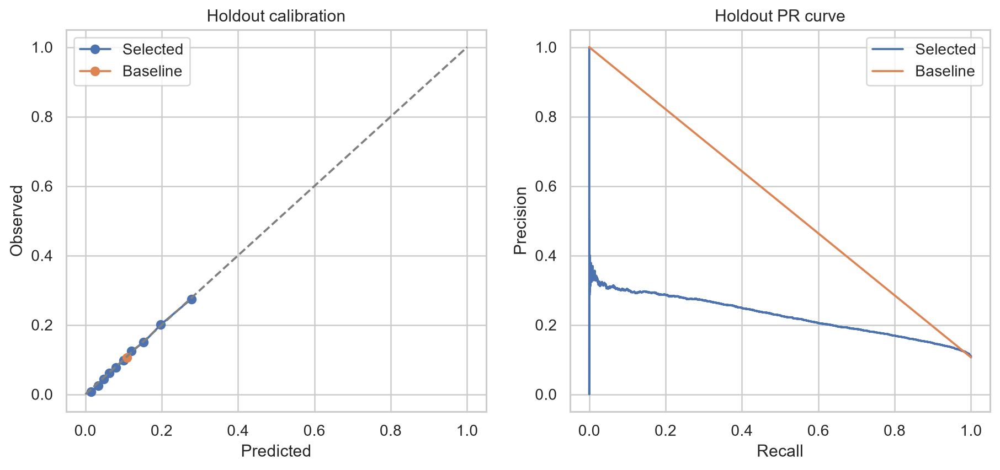

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/21_calibration_pr.png')

In [64]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for label,p in [('Selected',hold_p),('Baseline',baseline)]:
    obs,pred=calibration_curve(hold_y,p,n_bins=10,strategy='quantile');axes[0].plot(pred,obs,'o-',label=label)
    prec,rec,_=precision_recall_curve(hold_y,p);axes[1].plot(rec,prec,label=label)
axes[0].plot([0,1],[0,1],'--',color='gray');axes[0].set(xlabel='Predicted',ylabel='Observed',title='Holdout calibration');axes[1].set(xlabel='Recall',ylabel='Precision',title='Holdout PR curve')
for ax in axes:ax.legend()
publish(fig,'21_calibration_pr')

In [65]:
monitor=hold[['pitch_type','stand','p_throws','balls','strikes']].copy()
monitor['y']=hold_y
monitor['pred']=hold_p
monitor['sq_err']=(monitor.y-monitor.pred)**2
for group in ['pitch_type','stand','p_throws','balls','strikes']:
    z=monitor.groupby(group).agg(n=('y','size'),observed=('y','mean'),predicted=('pred','mean'),brier=('sq_err','mean')).query('n>=100').sort_values('n',ascending=False)
    display(z.head(15))


,n,observed,predicted,brier
pitch_type,,,,
FF,17586,0.086546,0.095241,0.074640
SI,8670,0.058247,0.053877,0.053599
SL,8152,0.153214,0.155481,0.121016
CH,5464,0.139458,0.128283,0.113217
ST,4542,0.125936,0.130832,0.105389
FC,3838,0.093278,0.106529,0.083875
CU,3318,0.114527,0.115170,0.092536
FS,2010,0.153234,0.153250,0.120466
KC,1115,0.139910,0.136927,0.105270


,n,observed,predicted,brier
stand,,,,
R,30952,0.110655,0.111060,0.092245
L,24394,0.100803,0.106257,0.084155


,n,observed,predicted,brier
p_throws,,,,
R,41707,0.104443,0.108951,0.087390
L,13639,0.112032,0.108919,0.092622


,n,observed,predicted,brier
balls,,,,
0,25193,0.095701,0.103648,0.080583
1,16348,0.116100,0.116205,0.096115
2,9272,0.121872,0.115708,0.100270
3,4533,0.098169,0.098343,0.083151


,n,observed,predicted,brier
strikes,,,,
0,22212,0.078066,0.086817,0.067507
1,16816,0.118875,0.117832,0.097254
2,16318,0.131818,0.129900,0.108663


### Segment-level calibration audit
This single heatmap replaces five near-duplicate scatterplots, some containing only two points. Values are predicted minus observed whiff rate; positive values denote overprediction.

,group,n,observed,predicted,brier,segment,calibration_gap
15,0,25193,0.0957,0.1036,0.0806,balls,0.0079
16,1,16348,0.1161,0.1162,0.0961,balls,0.0001
17,2,9272,0.1219,0.1157,0.1003,balls,-0.0062
18,3,4533,0.0982,0.0983,0.0832,balls,0.0002
14,R,41707,0.1044,0.1090,0.0874,p_throws,0.0045
13,L,13639,0.1120,0.1089,0.0926,p_throws,-0.0031
3,FF,17586,0.0865,0.0952,0.0746,pitch_type,0.0087
7,SI,8670,0.0582,0.0539,0.0536,pitch_type,-0.0044
8,SL,8152,0.1532,0.1555,0.1210,pitch_type,0.0023
0,CH,5464,0.1395,0.1283,0.1132,pitch_type,-0.0112


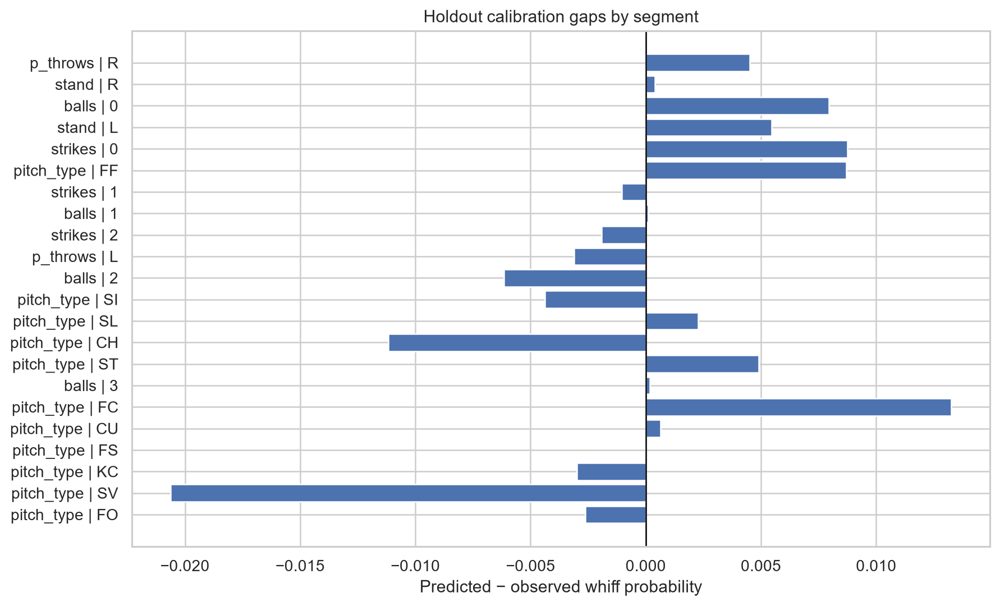

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/holdout_segment_calibration_gaps.png')

In [66]:
monitor_long=[]
for col in ['pitch_type','stand','p_throws','balls','strikes']:
    t=monitor.groupby(col).agg(n=('y','size'),observed=('y','mean'),predicted=('pred','mean'),brier=('sq_err','mean')).reset_index()
    t=t.rename(columns={col:'group'})
    t['segment']=col
    t['group']=t['group'].astype(str)
    monitor_long.append(t.query('n>=100'))
monitor_table=pd.concat(monitor_long,ignore_index=True)
monitor_table['calibration_gap']=monitor_table.predicted-monitor_table.observed
display(monitor_table.sort_values(['segment','n'],ascending=[True,False]).head(40).round(4))
segments=monitor_table.copy()
segments['label']=segments.segment+' | '+segments.group
segments=segments.sort_values('n',ascending=False).head(28)
fig,ax=plt.subplots(figsize=(10, max(5,len(segments)*.28)))
y=np.arange(len(segments))
ax.barh(y,segments.calibration_gap)
ax.set_yticks(y,segments.label)
ax.axvline(0,color='black',lw=1)
ax.invert_yaxis()
ax.set(xlabel='Predicted − observed whiff probability',title='Holdout calibration gaps by segment')
fig.tight_layout()
publish(fig,'holdout_segment_calibration_gaps')

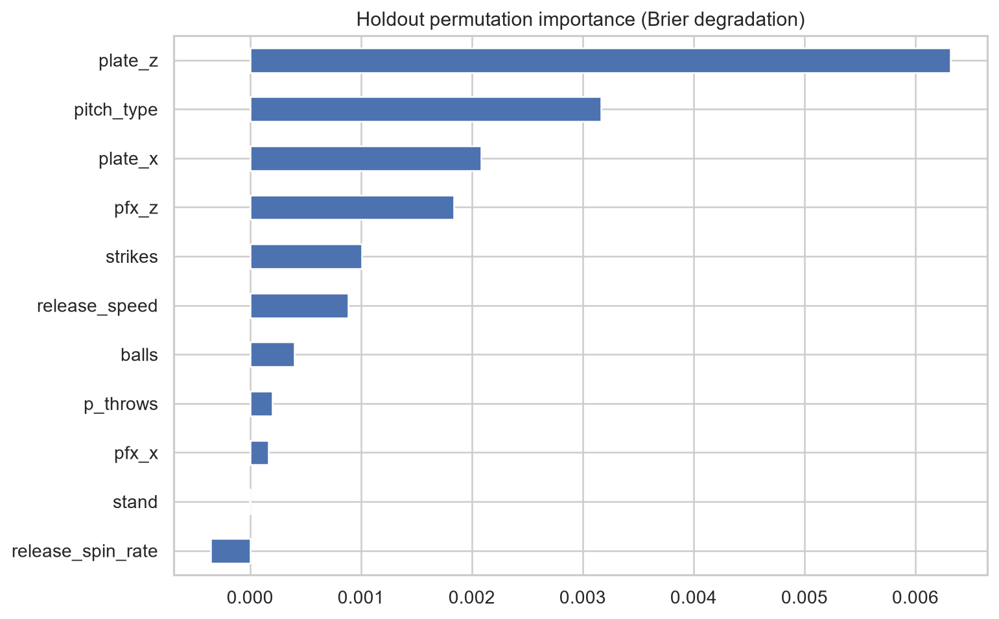

In [67]:
if selected_name!='Prevalence':
    sample=hold.sample(n=min(len(hold),1500),random_state=42)
    importance=permutation_importance(final,sample[feature_cols],sample.whiff_ind.astype(int),n_repeats=3,scoring='neg_brier_score',random_state=42,n_jobs=1)
    imp=pd.Series(importance.importances_mean,index=feature_cols).sort_values()
    fig,ax=plt.subplots(figsize=(9,6));imp.plot.barh(ax=ax);ax.set(title='Holdout permutation importance (Brier degradation)');publish(fig,'22_feature_importance')

### Restricted-information benchmark | Pre-pitch-only features
To estimate what a team could know **before pitch release**, exclude actual release, movement, and plate-crossing measurements. This separate benchmark is deliberately fitted without altering selection of the primary descriptive model.

In [68]:
premove_cols=[c for c in ['pitch_type','stand','p_throws','balls','strikes'] if c in df]
premove_cat=[c for c in ['pitch_type','stand','p_throws'] if c in premove_cols]
premove_num=[c for c in premove_cols if c not in premove_cat]
preprocessor_pre=ColumnTransformer([
    ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),
                     ('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),premove_cat),
    ('num',Pipeline([('imputer',SimpleImputer(strategy='median')),
                     ('scale',StandardScaler())]),premove_num)
])
pre_model=Pipeline([('prep',preprocessor_pre),('model',LogisticRegression(max_iter=800))])
pre_model.fit(train_all[premove_cols],train_all.whiff_ind.astype(int))
pre_p=pre_model.predict_proba(hold[premove_cols])[:,1]
display(pd.DataFrame([
    {'model':'Primary measured-pitch model',**score(hold_y,hold_p)},
    {'model':'Pre-pitch covariates logistic',**score(hold_y,pre_p)},
    {'model':'Training prevalence',**score(hold_y,baseline)}
]).round(4))
print('Pitch type itself may not be known before the pitcher makes the choice; pre-pitch here refers to model covariates, not the pitcher’s private intention.')

,model,ROC_AUC,PR_AUC,Brier,LogLoss
0,Primary measured-pitch model,0.7329,0.2269,0.0887,0.3053
1,Pre-pitch covariates logistic,0.6139,0.1453,0.0937,0.3314
2,Training prevalence,0.5000,0.1063,0.0950,0.3388


Pitch type itself may not be known before the pitcher makes the choice; pre-pitch here refers to model covariates, not the pitcher’s private intention.


### 7.1 | Independent target: swing decision
A batter swing model and a whiff-on-pitch model answer different questions. This secondary model is trained separately and evaluated with the same chronological design.

In [69]:
swing_model=Pipeline([('prep',make_preprocess()),('model',LogisticRegression(max_iter=800))]);swing_model.fit(tr[feature_cols],tr.swing_ind.astype(int))
swing_validation=score(va.swing_ind.astype(int),swing_model.predict_proba(va[feature_cols])[:,1]);display(pd.DataFrame([swing_validation]))
swing_model.fit(train_all[feature_cols],train_all.swing_ind.astype(int));swing_p=swing_model.predict_proba(hold[feature_cols])[:,1];display(pd.DataFrame([{'outcome':'Swing',**score(hold.swing_ind.astype(int),swing_p)}]))

,ROC_AUC,PR_AUC,Brier,LogLoss
0,0.643528,0.586222,0.234405,0.661278


,outcome,ROC_AUC,PR_AUC,Brier,LogLoss
0,Swing,0.639646,0.583343,0.234998,0.662595


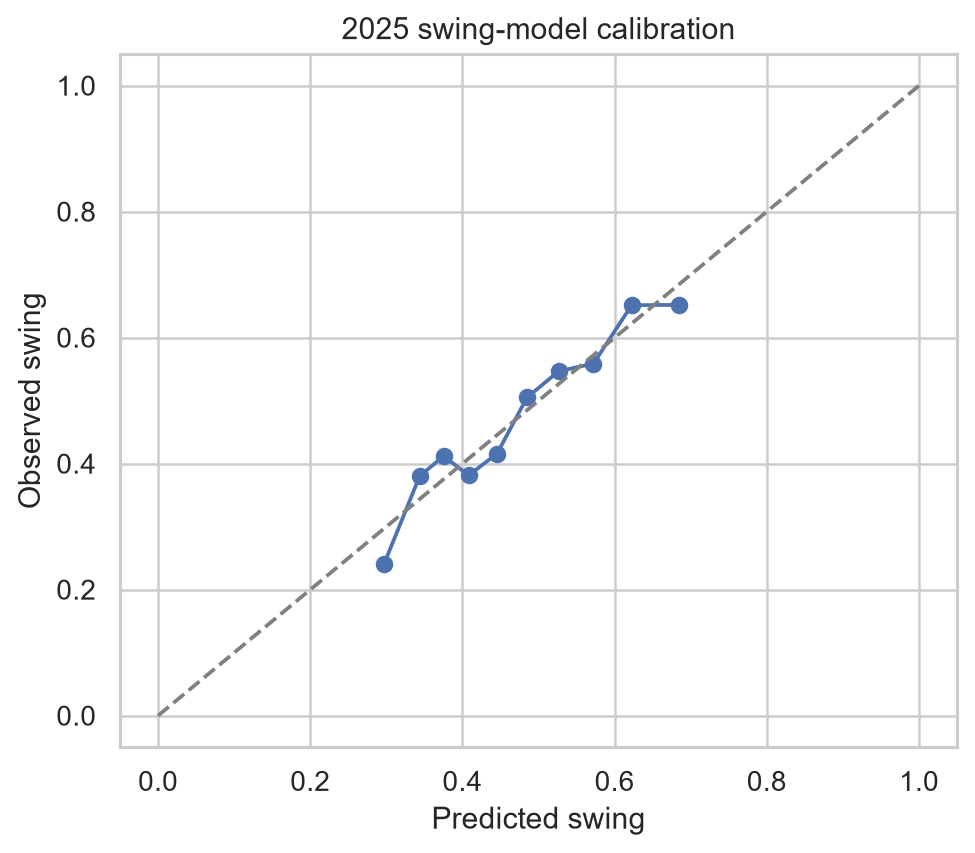

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/23_swing_calibration.png')

In [70]:
obs,pred=calibration_curve(hold.swing_ind.astype(int),swing_p,n_bins=10,strategy='quantile');fig,ax=plt.subplots(figsize=(6,5));ax.plot(pred,obs,'o-');ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='Predicted swing',ylabel='Observed swing',title='2025 swing-model calibration');publish(fig,'23_swing_calibration')

### Conditional hard-hit model | Only tracked BBE
Hard-hit is conditioned on putting the ball in play; it is a **different target** and must never be combined with whiff-per-pitch without an explicit sequential outcome model. Logistic regression is a transparent baseline and seasons remain separated.

In [71]:
if not batted.empty and batted.season.nunique()==2:
    contact_features=[v for v in ['pitch_type','stand','p_throws','release_speed','release_spin_rate','balls','strikes'] if v in batted]
    contact_cat=[v for v in ['pitch_type','stand','p_throws'] if v in contact_features]
    contact_num=[v for v in contact_features if v not in contact_cat]
    contact_pre=ColumnTransformer([
        ('cat',Pipeline([('fill',SimpleImputer(strategy='most_frequent')),
                         ('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),contact_cat),
        ('num',Pipeline([('fill',SimpleImputer(strategy='median')),
                         ('scale',StandardScaler())]),contact_num)
    ])
    train_bbe=batted[batted.season.eq(2024)]
    test_bbe=batted[batted.season.eq(2025)]
    if len(train_bbe)>100 and len(test_bbe)>100 and train_bbe.hard_hit.nunique()==2:
        contact_model=Pipeline([('prep',contact_pre),('model',LogisticRegression(max_iter=900))])
        contact_model.fit(train_bbe[contact_features],train_bbe.hard_hit.astype(int))
        p=contact_model.predict_proba(test_bbe[contact_features])[:,1]
        base_p=np.full(len(test_bbe),train_bbe.hard_hit.mean())
        display(pd.DataFrame([
            {'target':'BBE conditional hard-hit','model':'Logistic',**score(test_bbe.hard_hit.astype(int),p)},
            {'target':'BBE conditional hard-hit','model':'Train prevalence',**score(test_bbe.hard_hit.astype(int),base_p)}
        ]).round(4))

,target,model,ROC_AUC,PR_AUC,Brier,LogLoss
0,BBE conditional hard-hit,Logistic,0.5714,0.4875,0.2414,0.6761
1,BBE conditional hard-hit,Train prevalence,0.5000,0.4222,0.2450,0.6832


### Additional model diagnostics: segment-level reliability

# 9 | Advanced Research: Player, Pitch, Game and Model Reliability

**Scope:** These supplemental studies replace repeated one-variable charts with distinct baseball questions. All graphs are displayed inline **and** saved through `publish(fig, name)`. Descriptive differences are not causal effects. Analyses which rely on optional Statcast columns skip explicitly if those fields are missing.

In [72]:
from scipy.stats import beta as beta_dist
from sklearn.metrics import confusion_matrix
ADVANCED_DIR = ROOT / 'outputs' / 'advanced_research'
ADVANCED_DIR.mkdir(parents=True, exist_ok=True)

def export_table(frame, name):
    path = ADVANCED_DIR / f'{name}.csv'
    frame.to_csv(path, index=False)
    return path

def wilson_table(frame, group_cols, outcome, min_n=40):
    tab = (frame.groupby(group_cols, observed=True)[outcome]
           .agg(n='size', k='sum').reset_index())
    tab = tab.loc[tab.n >= min_n].copy()
    if len(tab):
        lo, hi = proportion_confint(tab.k.astype(int), tab.n.astype(int), method='wilson')
        tab['rate'] = tab.k/tab.n
        tab['lower'], tab['upper'] = lo, hi
    return tab

print('Extended research tables:', ADVANCED_DIR)

Extended research tables: I:\Potforlio\MLB Analytics\outputs\advanced_research


## 9.1 | Observation coverage and denominator audit
**Question:** are EV and pitch-location comparisons based on comparable populations? The audit distinguishes all pitches, balls in play, and tracked balls in play.

In [73]:
denom_audit = pd.DataFrame([
    {'population':'All cleaned pitches', 'n':len(df)},
    {'population':'Swing opportunities', 'n':int(df.swing_ind.eq(1).sum())},
    {'population':'Outside-zone pitches with known zone', 'n':int((df.zone_known & ~df.in_zone).sum())},
    {'population':'In-play events', 'n':int(df.is_bbe.sum())},
    {'population':'Tracked in-play events', 'n':int(len(batted))},
    {'population':'Tracked in-play events with launch angle', 'n':int(batted.launch_angle.notna().sum())}
])
display(denom_audit)
export_table(denom_audit, 'population_denominators')
if 'launch_speed' in raw:
    raw_bbe=raw.loc[raw.type.eq('X')].copy()
    print('Raw BBE EV coverage:', round(raw_bbe.launch_speed.notna().mean()*100,2), '%')

,population,n
0,All cleaned pitches,109346
1,Swing opportunities,51923
2,Outside-zone pitches with known zone,54509
3,In-play events,19348
4,Tracked in-play events,19288
5,Tracked in-play events with launch angle,19287


Raw BBE EV coverage: 99.69 %


## 9.2 | Velocity, spin and within-pitcher relative performance
**Question:** do pitches thrown faster than a pitcher’s *own* typical velocity have different outcomes? This avoids confusing naturally hard throwers with within-pitcher variation.

,speed_band,n,k,rate,lower,upper
0,"(-20.001, -2.0]",1456,294,0.202,0.182,0.223
1,"(-2.0, -1.0]",4277,876,0.205,0.193,0.217
2,"(-1.0, 0.0]",9854,2092,0.212,0.204,0.220
3,"(0.0, 1.0]",10735,2464,0.230,0.222,0.238
4,"(1.0, 2.0]",5387,1344,0.249,0.238,0.261
5,"(2.0, 20.0]",1605,456,0.284,0.263,0.307


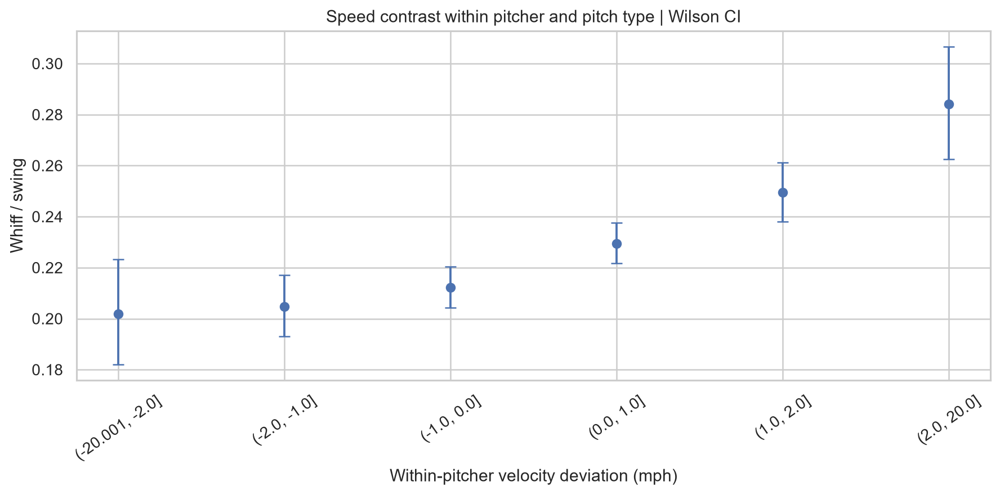

In [74]:
within = df[['pitcher','pitch_type','release_speed','swing_ind','whiff_ind']].copy()
within['release_speed'] = pd.to_numeric(within.release_speed,errors='coerce')
within = within.dropna(subset=['release_speed'])
stats_within = (within.groupby(['pitcher','pitch_type']).release_speed
                .agg(['size','mean','std']).rename(columns={'size':'n'}))
within = within.join(stats_within,on=['pitcher','pitch_type'])
within = within.loc[(within.n>=50)&within['std'].gt(0.2)].copy()
within['speed_relative_mph'] = within.release_speed-within['mean']
within['speed_band'] = pd.cut(within.speed_relative_mph,[-20,-2,-1,0,1,2,20],include_lowest=True)
x=wilson_table(within.loc[within.swing_ind.eq(1)],['speed_band'],'whiff_ind',min_n=80)
if not x.empty:
    display(x.round(3)); export_table(x,'within_pitcher_speed_whiff')
    fig,ax=plt.subplots(figsize=(10,5));ax.errorbar(range(len(x)),x.rate,yerr=[x.rate-x.lower,x.upper-x.rate],fmt='o',capsize=4)
    ax.set_xticks(range(len(x)),x.speed_band.astype(str),rotation=35)
    ax.set(ylabel='Whiff / swing',xlabel='Within-pitcher velocity deviation (mph)',title='Speed contrast within pitcher and pitch type | Wilson CI')
    fig.tight_layout();publish(fig,'advanced_within_pitcher_speed_whiff')

## 9.3 | Observed pitch physics: velocity–movement profiles
**Question:** does horizontal break change with velocity *within the same pitch type*? Pitch movement is conditional on throwing arm and repertoire.

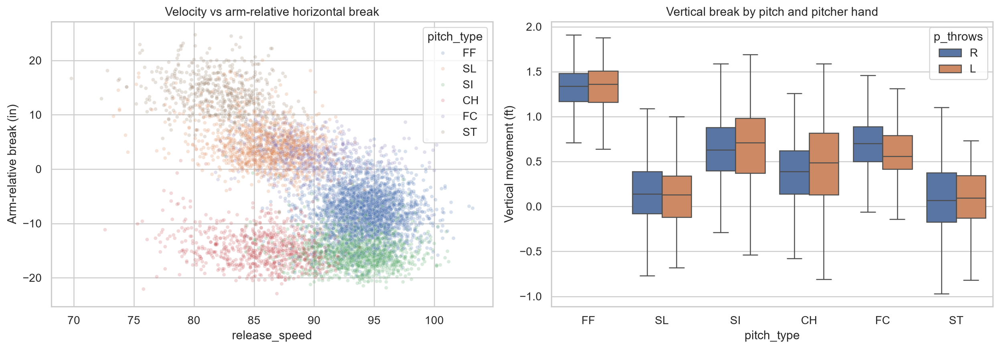

In [75]:
phys = df[['pitch_type','p_throws','release_speed','pfx_x','pfx_z']].copy()
for col in ['release_speed','pfx_x','pfx_z']:
    phys[col]=pd.to_numeric(phys[col],errors='coerce')
phys=phys.dropna().loc[lambda x:x.p_throws.isin(['L','R'])]
phys['arm_side_break_in']=phys.pfx_x*12*np.where(phys.p_throws.eq('R'),1,-1)
major=phys.pitch_type.value_counts().head(6).index
small=phys.loc[phys.pitch_type.isin(major)]
if len(small):
    x=small.sample(min(7000,len(small)),random_state=42)
    fig,axes=plt.subplots(1,2,figsize=(14,5))
    sns.scatterplot(data=x,x='release_speed',y='arm_side_break_in',hue='pitch_type',alpha=.22,s=13,ax=axes[0])
    sns.boxplot(data=x,x='pitch_type',y='pfx_z',hue='p_throws',showfliers=False,ax=axes[1])
    axes[0].set(title='Velocity vs arm-relative horizontal break',ylabel='Arm-relative break (in)')
    axes[1].set(title='Vertical break by pitch and pitcher hand',ylabel='Vertical movement (ft)')
    fig.tight_layout();publish(fig,'advanced_physics_profiles')

## 9.4 | Pitcher game workload and velocity drift
**Question:** does observed release speed change from early to late pitches **within a game**? The observation is a fatigue proxy, not evidence of injury or physiologic fatigue.

,workload_band,n,mean_delta,std,se
0,"(0, 15]",14895,0.165,1.013,0.008
1,"(15, 30]",14895,0.098,0.969,0.008
2,"(30, 45]",12959,0.057,0.981,0.009
3,"(45, 60]",11462,-0.030,1.017,0.010
4,"(60, 75]",10624,-0.198,1.055,0.010
5,"(75, 90]",8206,-0.221,1.070,0.012
6,"(90, 2000]",2533,-0.155,1.098,0.022


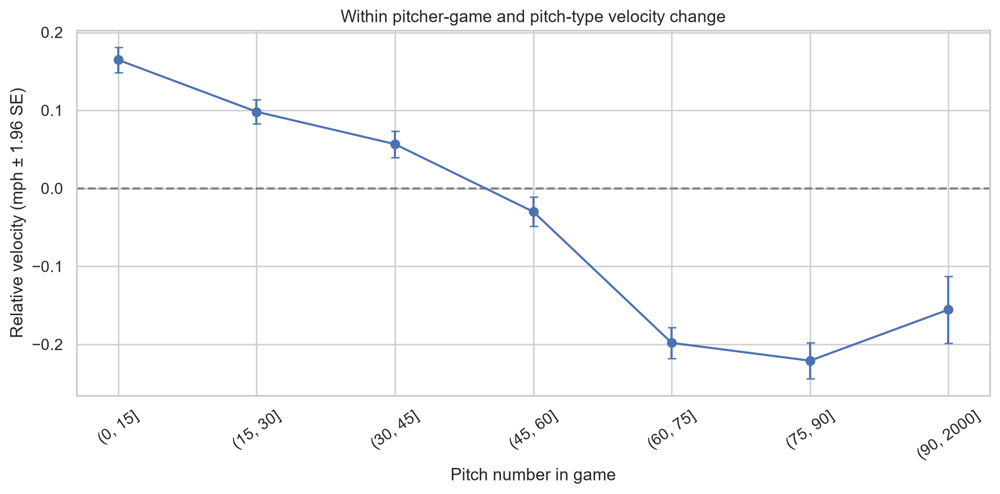

In [76]:
keys=['game_pk','pitcher','at_bat_number','pitch_number','release_speed','pitch_type']
if all(c in df for c in keys):
    workload=df[keys].dropna(subset=['release_speed']).sort_values(['game_pk','pitcher','at_bat_number','pitch_number']).copy()
    workload['pitch_in_game']=workload.groupby(['game_pk','pitcher']).cumcount()+1
    workload['workload_band']=pd.cut(workload.pitch_in_game,[0,15,30,45,60,75,90,2000],right=True)
    workload['pitcher_game_key']=workload.game_pk.astype(str)+'_'+workload.pitcher.astype(str)
    n_game=workload.groupby('pitcher_game_key').pitch_in_game.transform('max')
    workload=workload.loc[n_game>=30].copy()
    group=workload.groupby(['pitcher_game_key','pitch_type']).release_speed.transform('mean')
    workload['velocity_delta']=workload.release_speed-group
    agg=(workload.groupby('workload_band',observed=True)
         .agg(n=('velocity_delta','size'),mean_delta=('velocity_delta','mean'),std=('velocity_delta','std')).reset_index())
    agg['se']=agg['std']/np.sqrt(agg.n)
    display(agg.round(3));export_table(agg,'within_game_velocity_drift')
    fig,ax=plt.subplots(figsize=(10,5)); ax.errorbar(range(len(agg)),agg.mean_delta,yerr=1.96*agg.se,fmt='o-',capsize=3)
    ax.set_xticks(range(len(agg)),agg.workload_band.astype(str),rotation=35)
    ax.axhline(0,ls='--',color='gray')
    ax.set(title='Within pitcher-game and pitch-type velocity change',xlabel='Pitch number in game',ylabel='Relative velocity (mph ± 1.96 SE)')
    fig.tight_layout();publish(fig,'advanced_velocity_workload')

## 9.5 | Game-level changes in pitch selection
**Question:** do pitchers shift from fastballs to off-speed pitches as an outing progresses? Rates use *all observed pitches* by workload bin; early/late contributions are not matched to identical pitchers.

band,"(0, 25]","(25, 50]","(50, 75]","(75, 100]","(100, 2000]"
pitch_type,,,,,
CH,0.084,0.116,0.123,0.124,0.090
FC,0.074,0.078,0.075,0.073,0.061
FF,0.325,0.313,0.299,0.287,0.337
SI,0.168,0.152,0.151,0.154,0.169
SL,0.165,0.131,0.129,0.136,0.163
ST,0.081,0.078,0.077,0.077,0.052


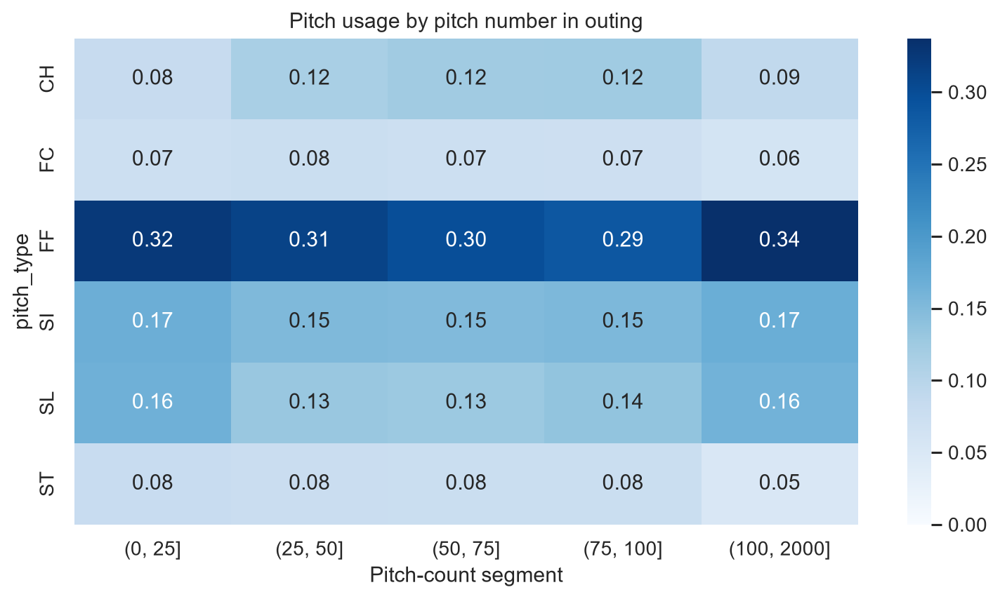

In [77]:
if 'workload' in globals() and len(workload):
    all_pitch_counts = df[['game_pk','pitcher','pitch_type','at_bat_number','pitch_number']].sort_values(['game_pk','pitcher','at_bat_number','pitch_number']).copy()
    all_pitch_counts['pitch_in_game']=all_pitch_counts.groupby(['game_pk','pitcher']).cumcount()+1
    all_pitch_counts['band']=pd.cut(all_pitch_counts.pitch_in_game,[0,25,50,75,100,2000],right=True)
    leaders=df.pitch_type.value_counts().head(6).index
    agg=all_pitch_counts.groupby(['band','pitch_type'],observed=True).size().rename('n').reset_index()
    agg=agg.loc[agg.pitch_type.isin(leaders)]
    totals=all_pitch_counts.groupby('band',observed=True).size()
    agg['share']=agg.n/agg.band.map(totals).astype(float)
    display(agg.pivot(index='pitch_type',columns='band',values='share').round(3))
    mat=agg.pivot(index='pitch_type',columns='band',values='share')
    fig,ax=plt.subplots(figsize=(10,5));sns.heatmap(mat,annot=True,fmt='.2f',cmap='Blues',vmin=0,ax=ax)
    ax.set(title='Pitch usage by pitch number in outing',xlabel='Pitch-count segment');publish(fig,'advanced_game_usage')

## 10 | Hitter Decision-Making, Zone Control and Matchups

### 10.1 | Swing probability by physical pitch location
**Question:** how does observed swing probability change across horizontal and vertical location? Cells below the minimum count are suppressed.

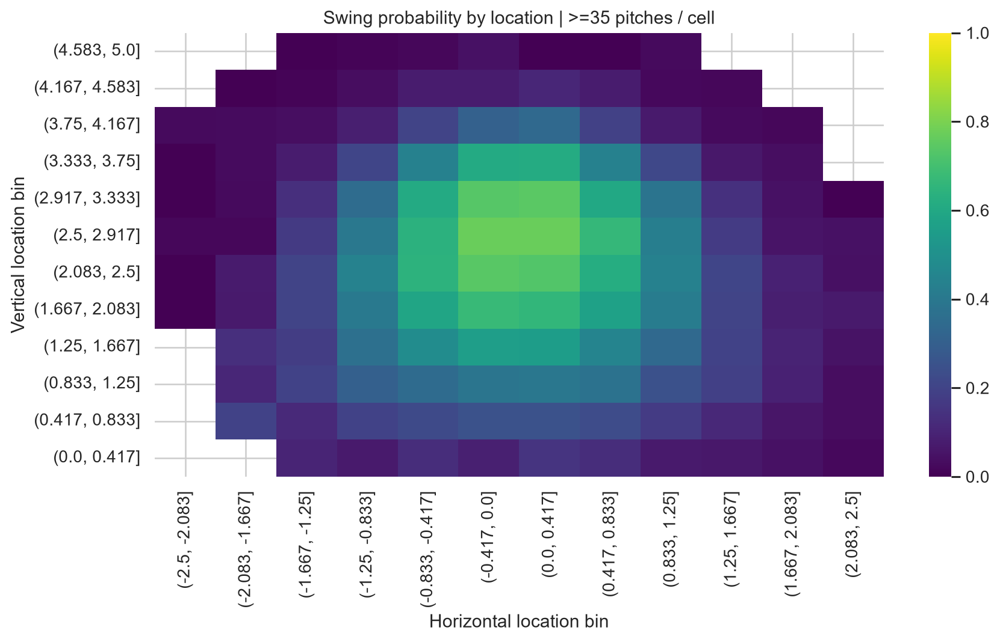

In [78]:
loc=df.loc[df.plate_x.between(-2.5,2.5)&df.plate_z.between(0,5)].copy()
loc['x_bin']=pd.cut(loc.plate_x,np.linspace(-2.5,2.5,13))
loc['z_bin']=pd.cut(loc.plate_z,np.linspace(0,5,13))
zone_rate=(loc.groupby(['z_bin','x_bin'],observed=True).swing_ind
           .agg(n='size',swing='mean').reset_index())
zone_rate.loc[zone_rate.n<35,'swing']=np.nan
mat=zone_rate.pivot(index='z_bin',columns='x_bin',values='swing')
if mat.notna().any().any():
    fig,ax=plt.subplots(figsize=(10,6))
    sns.heatmap(mat.iloc[::-1],cmap='viridis',vmin=0,vmax=1,ax=ax)
    ax.set(title='Swing probability by location | >=35 pitches / cell',xlabel='Horizontal location bin',ylabel='Vertical location bin')
    fig.tight_layout();publish(fig,'advanced_location_swing_probability')

### 10.2 | Conditional whiff location and opportunity control
**Question:** where do swings miss the ball? Conditioning on swung pitches avoids confusing locations that rarely attract swings with genuinely difficult-to-contact locations.

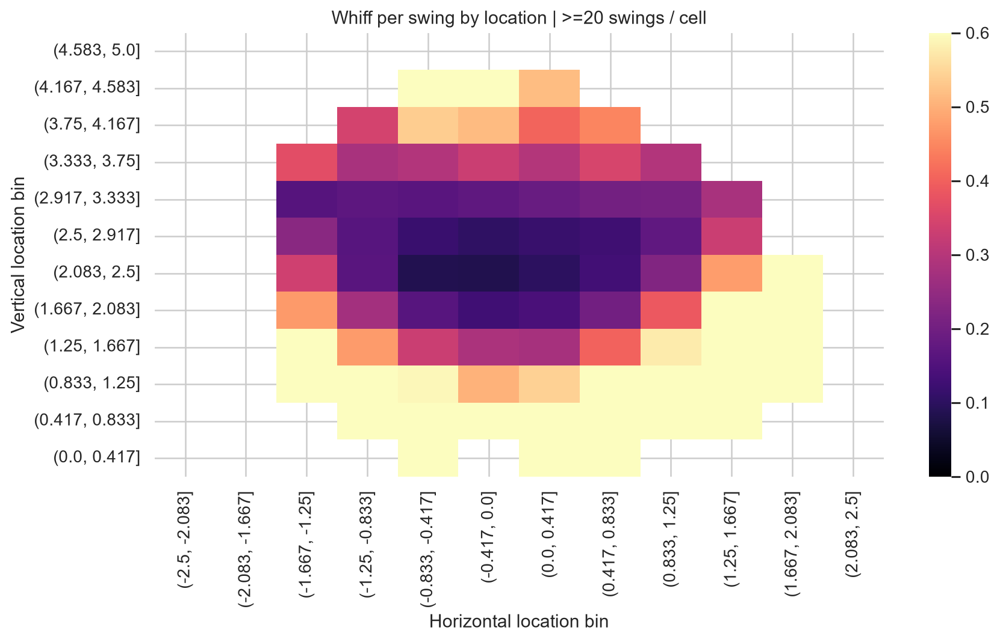

In [79]:
swing_loc=loc.loc[loc.swing_ind.eq(1)].copy()
whiff_loc=(swing_loc.groupby(['z_bin','x_bin'],observed=True).whiff_ind
           .agg(n='size',rate='mean').reset_index())
whiff_loc.loc[whiff_loc.n<20,'rate']=np.nan
mat=whiff_loc.pivot(index='z_bin',columns='x_bin',values='rate')
if mat.notna().any().any():
    fig,ax=plt.subplots(figsize=(10,6));sns.heatmap(mat.iloc[::-1],cmap='magma',vmin=0,vmax=.6,ax=ax)
    ax.set(title='Whiff per swing by location | >=20 swings / cell',xlabel='Horizontal location bin',ylabel='Vertical location bin')
    fig.tight_layout();publish(fig,'advanced_location_whiff_given_swing')

### 10.3 | Chase distance beyond the strike zone
A single chase rate can hide how far outside the plate the pitch crossed. This proxy uses `plate_x` and `plate_z` with batter-specific vertical bounds when available.

,distance_band,n,k,rate,lower,upper
0,"(-0.001, 0.25]",14687,6534,0.445,0.437,0.453
1,"(0.25, 0.5]",14801,4957,0.335,0.327,0.343
2,"(0.5, 0.75]",10077,2252,0.223,0.215,0.232
3,"(0.75, 1.0]",6491,978,0.151,0.142,0.160
4,"(1.0, 1.5]",6022,504,0.084,0.077,0.091
5,"(1.5, 10.0]",2431,70,0.029,0.023,0.036


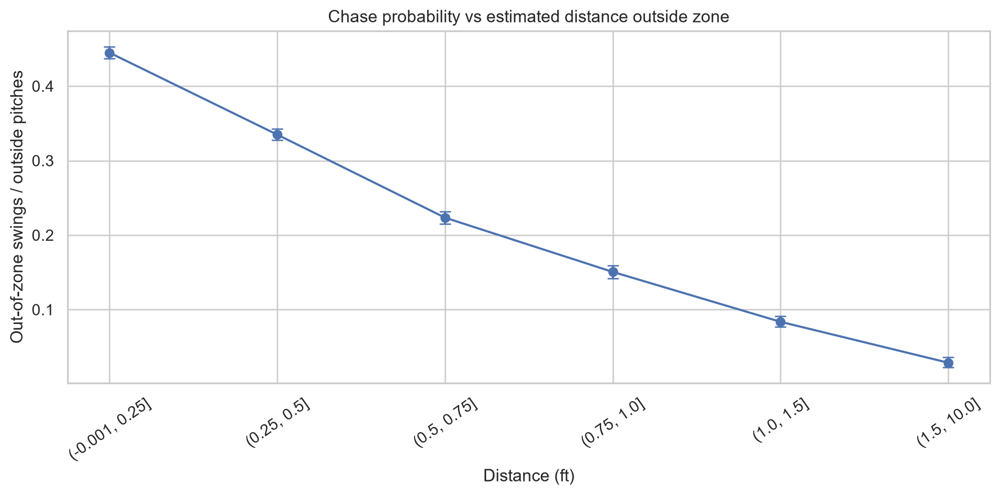

In [80]:
outside=df.loc[df.zone_known & ~df.in_zone].copy()
xp=pd.to_numeric(outside.plate_x,errors='coerce').abs()
ztop=pd.to_numeric(outside['sz_top'],errors='coerce') if 'sz_top' in outside else pd.Series(3.5,index=outside.index)
zbot=pd.to_numeric(outside['sz_bot'],errors='coerce') if 'sz_bot' in outside else pd.Series(1.5,index=outside.index)
zp=pd.to_numeric(outside.plate_z,errors='coerce')
outside['approx_zone_distance']=np.maximum.reduce([np.maximum(xp-.83,0),np.maximum(zbot-zp,0),np.maximum(zp-ztop,0)])
outside=outside.replace([np.inf,-np.inf],np.nan).dropna(subset=['approx_zone_distance'])
outside['distance_band']=pd.cut(outside.approx_zone_distance,[0,.25,.5,.75,1,1.5,10],include_lowest=True)
t=wilson_table(outside,['distance_band'],'swing_ind',min_n=60)
if len(t):
    display(t.round(3));export_table(t,'chase_distance')
    fig,ax=plt.subplots(figsize=(10,5));ax.errorbar(range(len(t)),t.rate,yerr=[t.rate-t.lower,t.upper-t.rate],fmt='o-',capsize=4)
    ax.set_xticks(range(len(t)),t.distance_band.astype(str),rotation=35)
    ax.set(title='Chase probability vs estimated distance outside zone',ylabel='Out-of-zone swings / outside pitches',xlabel='Distance (ft)')
    fig.tight_layout();publish(fig,'advanced_chase_distance')

### 10.4 | Hitter–pitcher handedness and count interactions
**Question:** how do handedness pairs differ at zero, one or two strikes? No causal matchup conclusion follows from the descriptive aggregate.

,matchup,strikes,n,k,rate,lower,upper
0,L batter / L pitcher,0,1088,249,0.229,0.205,0.255
1,L batter / L pitcher,1,1268,303,0.239,0.216,0.263
2,L batter / L pitcher,2,1414,335,0.237,0.215,0.260
3,L batter / R pitcher,0,5406,1217,0.225,0.214,0.236
4,L batter / R pitcher,1,6281,1359,0.216,0.206,0.227
5,L batter / R pitcher,2,6913,1406,0.203,0.194,0.213
6,R batter / L pitcher,0,2802,652,0.233,0.217,0.249
7,R batter / L pitcher,1,3192,735,0.230,0.216,0.245
8,R batter / L pitcher,2,3567,815,0.228,0.215,0.243
9,R batter / R pitcher,0,5853,1444,0.247,0.236,0.258


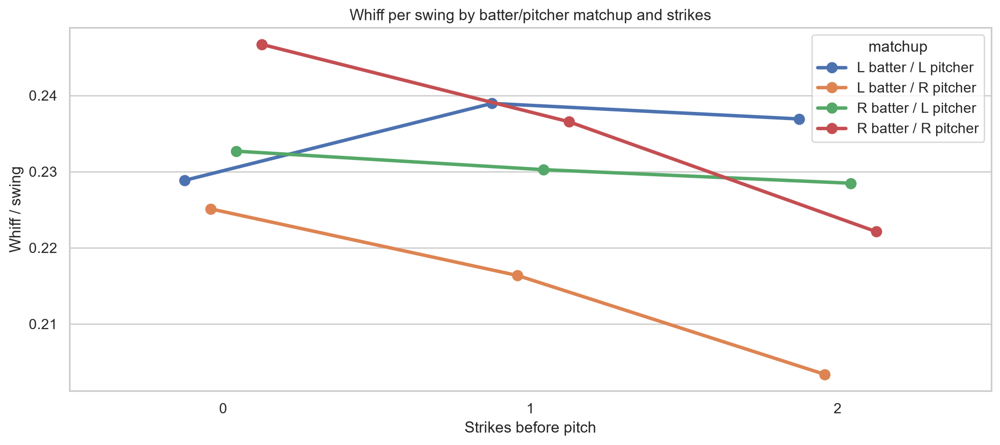

In [81]:
pair=df.loc[df.stand.isin(['L','R'])&df.p_throws.isin(['L','R'])].copy()
pair['matchup']=pair.stand+' batter / '+pair.p_throws+' pitcher'
mat=wilson_table(pair.loc[pair.swing_ind.eq(1)],['matchup','strikes'],'whiff_ind',min_n=120)
if len(mat):
    display(mat.round(3));export_table(mat,'handedness_count_whiff')
    fig,ax=plt.subplots(figsize=(11,5));sns.pointplot(data=mat,x='strikes',y='rate',hue='matchup',dodge=.25,ax=ax,errorbar=None)
    ax.set(title='Whiff per swing by batter/pitcher matchup and strikes',ylabel='Whiff / swing',xlabel='Strikes before pitch')
    fig.tight_layout();publish(fig,'advanced_handedness_count')

### 10.5 | First-pitch approach and outcomes
**Question:** what happens at `0-0`? Separate swing decisions, called strikes, and contact; do not interpret first-pitch hit quality as an unconditional plate appearance outcome.

,season,stand,pitches,swing_rate,called_strike_rate,inplay_rate
0,2024,L,5964,0.311,0.299,0.111
1,2024,R,7925,0.326,0.304,0.115
2,2025,L,6235,0.311,0.293,0.114
3,2025,R,8100,0.330,0.302,0.126


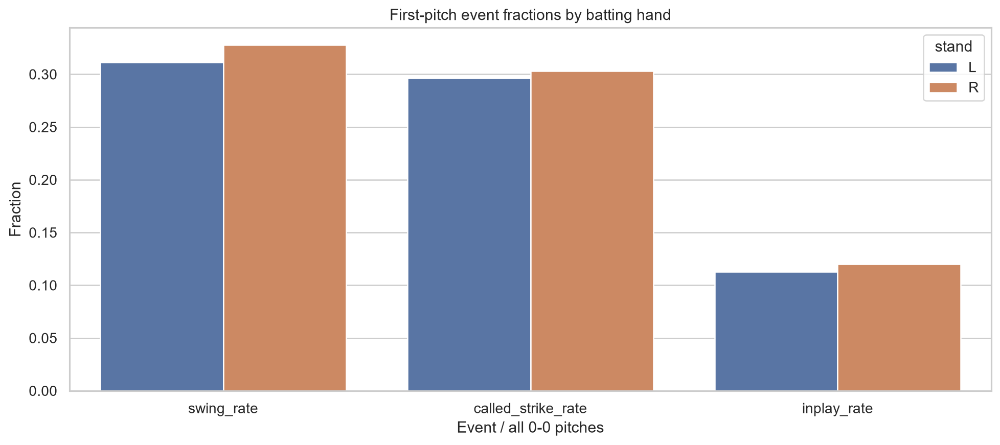

In [82]:
first=df.loc[df.balls.eq(0)&df.strikes.eq(0)].copy()
first['called_strike_event']=first.description.eq('called_strike') if 'description' in first else False
first['inplay_event']=first.is_bbe.astype(int)
first_table=(first.groupby(['season','stand'])
             .agg(pitches=('game_pk','size'),swing_rate=('swing_ind','mean'),called_strike_rate=('called_strike_event','mean'),inplay_rate=('inplay_event','mean')).reset_index())
display(first_table.round(3));export_table(first_table,'first_pitch_approach')
if len(first_table):
    melted=first_table.melt(id_vars=['season','stand','pitches'],value_vars=['swing_rate','called_strike_rate','inplay_rate'],var_name='event',value_name='rate')
    fig,ax=plt.subplots(figsize=(11,5));sns.barplot(data=melted,x='event',y='rate',hue='stand',ax=ax,errorbar=None)
    ax.set(title='First-pitch event fractions by batting hand',xlabel='Event / all 0-0 pitches',ylabel='Fraction')
    fig.tight_layout();publish(fig,'advanced_first_pitch_approach')

## 11 | Contact Quality and Run Outcomes

### 11.1 | Barrel-like contact using Statcast launch category
Only where supplied, `launch_speed_angle` is treated as a **source-provided classification**. Category 6 is the Statcast barrel class; missing classifications are not negatives.

,pitch_type,n,k,rate,lower,upper
6,FF,5590,587,0.105,0.097,0.113
11,SI,3644,241,0.066,0.059,0.075
12,SL,2775,226,0.081,0.072,0.092
0,CH,2164,168,0.078,0.067,0.090
5,FC,1549,124,0.080,0.068,0.095
13,ST,1402,108,0.077,0.064,0.092
2,CU,1005,83,0.083,0.067,0.101
8,FS,677,40,0.059,0.044,0.079
9,KC,295,12,0.041,0.023,0.070


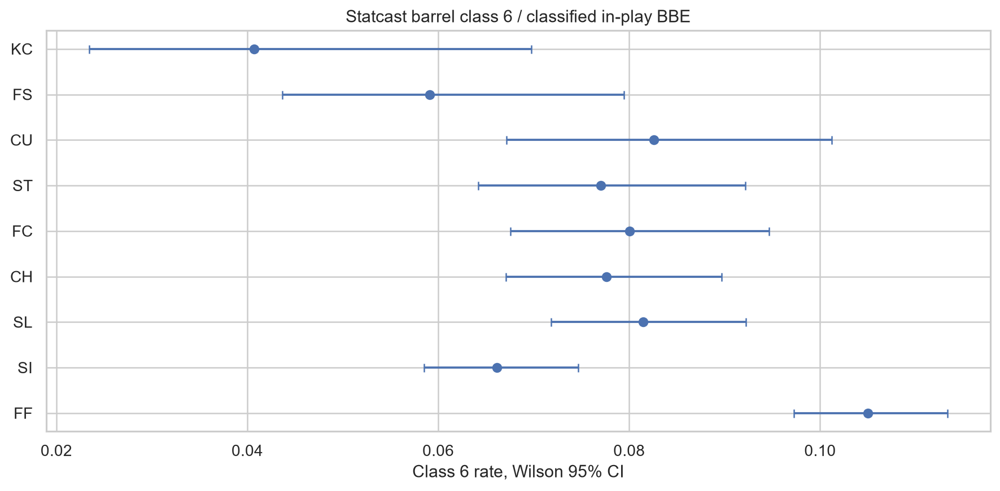

In [83]:
if 'launch_speed_angle' in batted:
    contact=batted.copy()
    contact['contact_class']=pd.to_numeric(contact.launch_speed_angle,errors='coerce')
    contact=contact.dropna(subset=['contact_class'])
    contact['barrel_class6']=contact.contact_class.eq(6).astype(int)
    t=wilson_table(contact,['pitch_type'],'barrel_class6',min_n=120)
    t=t.sort_values('n',ascending=False).head(9)
    if len(t):
        display(t.round(3));export_table(t,'barrel_class_pitch_type')
        fig,ax=plt.subplots(figsize=(10,5));ax.errorbar(t.rate,range(len(t)),xerr=[t.rate-t.lower,t.upper-t.rate],fmt='o',capsize=3)
        ax.set_yticks(range(len(t)),t.pitch_type);ax.set(title='Statcast barrel class 6 / classified in-play BBE',xlabel='Class 6 rate, Wilson 95% CI')
        fig.tight_layout();publish(fig,'advanced_barrel_class')
else:
    print('Source classification launch_speed_angle unavailable; skipped.')

### 11.2 | Expected contact quality (xwOBAcon) by pitch type
Statcast estimated wOBA using speed/angle is only recorded for eligible batted events. This is an observed contact-quality statistic, not an expected run value of **all pitches**.

,pitch_type,n,mean_xwoba,median_xwoba
6,FF,5568,0.3974,0.2800
11,SI,3624,0.3610,0.2500
12,SL,2764,0.3650,0.2435
0,CH,2158,0.3520,0.2240
5,FC,1542,0.3767,0.2560
13,ST,1395,0.3510,0.2230
2,CU,1004,0.3761,0.2635
8,FS,672,0.3502,0.2520
9,KC,292,0.3266,0.2390


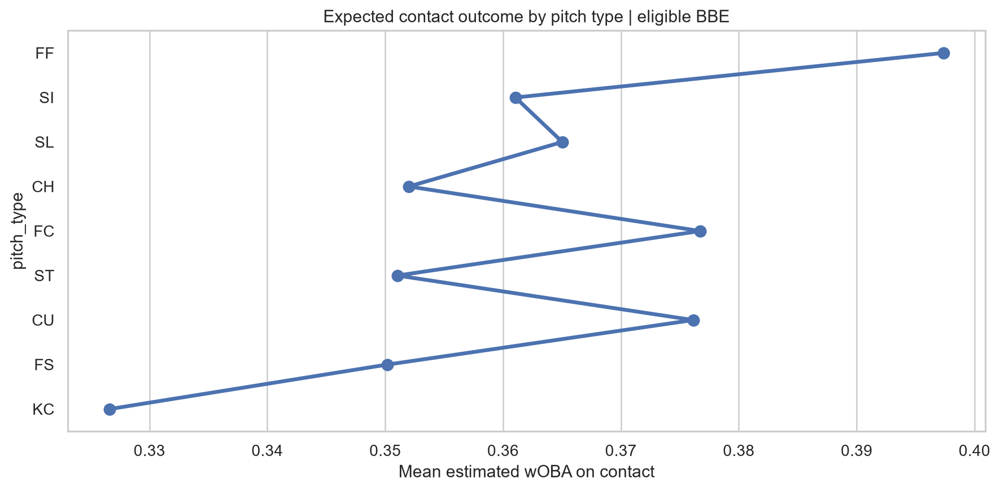

In [84]:
if 'estimated_woba_using_speedangle' in batted:
    x=batted.copy()
    x['xwoba_contact']=pd.to_numeric(x.estimated_woba_using_speedangle,errors='coerce')
    x=x.loc[x.xwoba_contact.between(0,2)].copy()
    t=(x.groupby('pitch_type').agg(n=('xwoba_contact','size'),mean_xwoba=('xwoba_contact','mean'),median_xwoba=('xwoba_contact','median')).reset_index().query('n>=100'))
    t=t.sort_values('n',ascending=False).head(10)
    if len(t):
        display(t.round(4));export_table(t,'xwoba_contact_pitch')
        fig,ax=plt.subplots(figsize=(10,5));sns.pointplot(data=t,x='mean_xwoba',y='pitch_type',ax=ax,errorbar=None)
        ax.set(title='Expected contact outcome by pitch type | eligible BBE',xlabel='Mean estimated wOBA on contact')
        fig.tight_layout();publish(fig,'advanced_xwoba_contact')
else:
    print('Statcast estimated_woba_using_speedangle not in data.')

### 11.3 | Batted-ball launch regimes by count
**Question:** how often does observed contact produce ground-ball-like, low-line-drive-like and elevated trajectories? These are angle bins, **not** official outcome labels.

count_state,0-0,0-1,0-2,1-0,1-1,1-2,2-0,2-1,2-2,3-0,3-1,3-2
angle_regime,,,,,,,,,,,,
Below 0°,0.316,0.327,0.341,0.279,0.307,0.336,0.306,0.292,0.327,0.317,0.250,0.278
0–10°,0.138,0.157,0.138,0.145,0.156,0.148,0.142,0.145,0.150,0.146,0.161,0.146
10–25°,0.213,0.222,0.237,0.213,0.210,0.216,0.227,0.239,0.213,0.220,0.229,0.230
25–50°,0.238,0.208,0.206,0.249,0.230,0.217,0.230,0.220,0.214,0.220,0.219,0.248
Above 50°,0.095,0.086,0.078,0.114,0.098,0.083,0.095,0.104,0.096,0.098,0.141,0.098


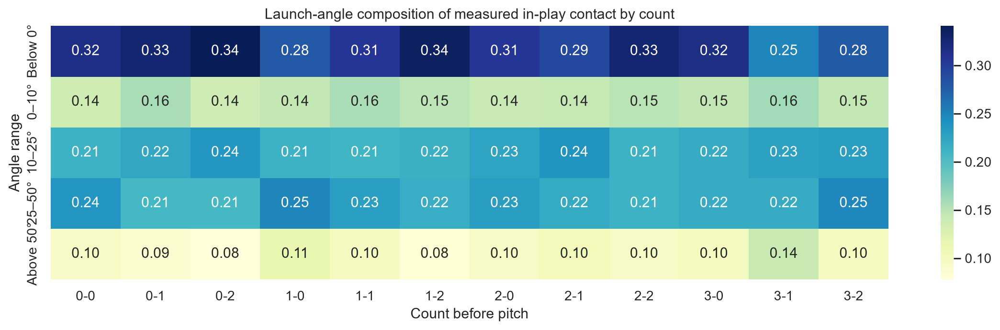

In [85]:
angles=batted.loc[batted.launch_angle.notna()].copy()
angles['angle_regime']=pd.cut(angles.launch_angle,[-100,0,10,25,50,100],labels=['Below 0°','0–10°','10–25°','25–50°','Above 50°'])
counts=(angles.groupby(['count_state','angle_regime'],observed=True).size().rename('n').reset_index())
mat=counts.pivot(index='angle_regime',columns='count_state',values='n').fillna(0)
col_order=[f'{b}-{s}' for b in range(4) for s in range(3)]
mat=mat.reindex(columns=col_order,fill_value=0)
mat=mat.div(mat.sum(axis=0).replace(0,np.nan),axis=1)
if mat.notna().any().any():
    display(mat.round(3));fig,ax=plt.subplots(figsize=(13,4));sns.heatmap(mat,annot=True,fmt='.2f',cmap='YlGnBu',ax=ax)
    ax.set(title='Launch-angle composition of measured in-play contact by count',xlabel='Count before pitch',ylabel='Angle range')
    fig.tight_layout();publish(fig,'advanced_angle_regimes')

### 11.4 | In-play probability and conditional hard-hit are different stages
Probability of a tracked hard hit **per pitch** can be decomposed into reaching a tracked BBE and the conditional hard-hit rate. Missing tracked EV is excluded from the conditional denominator and shown separately.

In [86]:
stage=(df.groupby(['season','pitch_type'])
       .agg(pitches=('is_bbe','size'),bbe=('is_bbe','sum'),tracked_bbe=('hard_hit','count'),hard_hits=('hard_hit','sum')).reset_index())
stage['bbe_per_pitch']=stage.bbe/stage.pitches
stage['ev_coverage']=stage.tracked_bbe/stage.bbe.replace(0,np.nan)
stage['hard_hit_given_tracked_bbe']=stage.hard_hits/stage.tracked_bbe.replace(0,np.nan)
stage['tracked_hard_hit_per_pitch']=stage.hard_hits/stage.pitches
stage=stage.query('pitches>=300').copy()
display(stage.sort_values(['season','pitches'],ascending=[True,False]).round(3).head(20))
export_table(stage,'contact_outcome_stages')

,season,pitch_type,pitches,bbe,tracked_bbe,hard_hits,bbe_per_pitch,ev_coverage,hard_hit_given_tracked_bbe,tracked_hard_hit_per_pitch
6,2024,FF,16805,2683,2678,1205,0.160,0.998,0.449963,0.071705
12,2024,SI,8867,1856,1846,813,0.209,0.995,0.440412,0.091688
13,2024,SL,8172,1376,1372,473,0.168,0.997,0.344752,0.057881
0,2024,CH,5558,1100,1098,344,0.198,0.998,0.313297,0.061893
5,2024,FC,4344,797,797,306,0.183,1.000,0.38394,0.070442
14,2024,ST,4130,665,664,176,0.161,0.998,0.26506,0.042615
2,2024,CU,3201,515,513,191,0.161,0.996,0.37232,0.059669
8,2024,FS,1663,308,306,116,0.185,0.994,0.379085,0.069753
9,2024,KC,890,127,126,46,0.143,0.992,0.365079,0.051685
22,2025,FF,17586,2920,2912,1385,0.166,0.997,0.475618,0.078756


WindowsPath('I:/Potforlio/MLB Analytics/outputs/advanced_research/contact_outcome_stages.csv')

## 12 | Situations, Repertoire and Within-PA Sequencing

### 12.1 | Base occupancy and number of outs
Statcast `on_1b`, `on_2b`, `on_3b` store runner IDs, not numeric flags. The proportion is conditioned on observed pitches, not matched game situations.

,runners_on,outs_when_up,n,k,rate
0,0,0,12469,2615,0.210
1,0,1,9289,2133,0.230
2,0,2,7546,1751,0.232
3,1,0,3839,830,0.216
4,1,1,5330,1246,0.234
5,1,2,6205,1476,0.238
6,2,0,1138,238,0.209
7,2,1,2234,517,0.231
8,2,2,2650,652,0.246
9,3,0,193,51,0.264


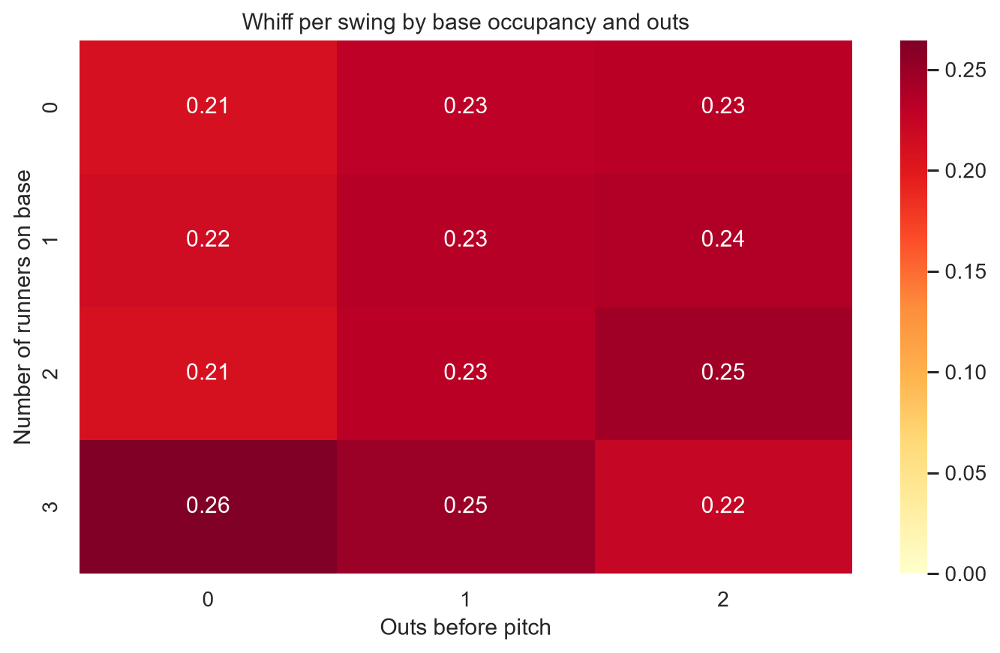

In [87]:
runners=['on_1b','on_2b','on_3b']
if all(c in df for c in runners) and 'outs_when_up' in df:
    situ=df.copy()
    situ['runners_on']=situ[runners].notna().sum(axis=1)
    out_rate=(situ.loc[situ.swing_ind.eq(1)].groupby(['runners_on','outs_when_up'])
              .whiff_ind.agg(n='size',k='sum').reset_index())
    out_rate['rate']=out_rate.k/out_rate.n
    out_rate.loc[out_rate.n<70,'rate']=np.nan
    mat=out_rate.pivot(index='runners_on',columns='outs_when_up',values='rate')
    display(out_rate.round(3))
    if mat.notna().any().any():
        fig,ax=plt.subplots(figsize=(8,5));sns.heatmap(mat,annot=True,fmt='.2f',cmap='YlOrRd',vmin=0,ax=ax)
        ax.set(title='Whiff per swing by base occupancy and outs',xlabel='Outs before pitch',ylabel='Number of runners on base')
        fig.tight_layout();publish(fig,'advanced_runner_outs_whiff')
else:
    print('Runner and out fields missing; skip base/out analysis.')

### 12.2 | Pitch-to-pitch velocity contrast and whiff response
Transitions are computed within the same plate appearance. The quantity measures association conditional on a swing, **not** the effect of switching pitches.

,contrast_bin,n,k,rate,lower,upper
0,"(-30, -12]",2068,584,0.282,0.263,0.302
1,"(-12, -7]",5623,1566,0.278,0.267,0.290
2,"(-7, -3]",3962,987,0.249,0.236,0.263
3,"(-3, 3]",19210,4319,0.225,0.219,0.231
4,"(3, 7]",3876,758,0.196,0.183,0.208
5,"(7, 12]",5745,993,0.173,0.163,0.183
6,"(12, 30]",2360,383,0.162,0.148,0.178


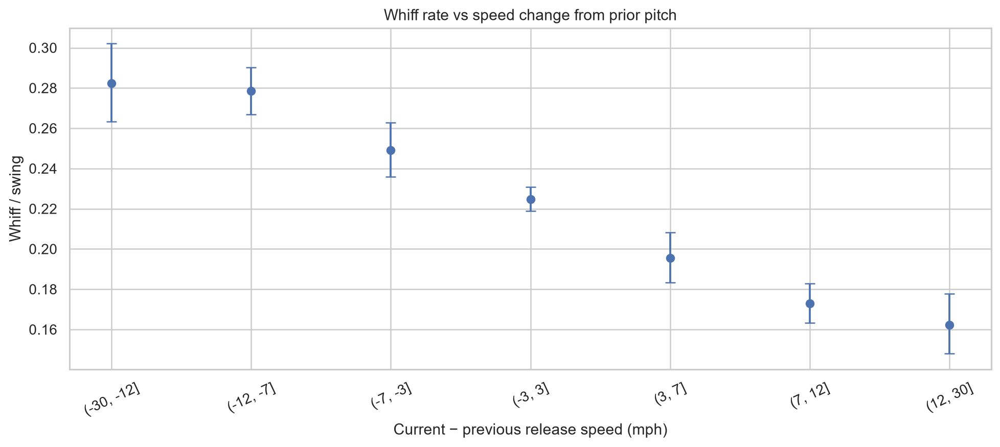

In [88]:
seqkeys=['game_pk','at_bat_number','pitch_number','release_speed','pitch_type']
if all(c in df for c in seqkeys):
    seq_new=df.sort_values(['game_pk','at_bat_number','pitch_number']).copy()
    by_pa=seq_new.groupby(['game_pk','at_bat_number'],sort=False)
    seq_new['prev_speed']=by_pa.release_speed.shift(1)
    seq_new['prev_pitch']=by_pa.pitch_type.shift(1)
    seq_new['speed_contrast']=pd.to_numeric(seq_new.release_speed,errors='coerce')-pd.to_numeric(seq_new.prev_speed,errors='coerce')
    sq=seq_new.loc[seq_new.prev_pitch.notna()&seq_new.swing_ind.eq(1)&seq_new.speed_contrast.between(-30,30)].copy()
    sq['contrast_bin']=pd.cut(sq.speed_contrast,[-30,-12,-7,-3,3,7,12,30])
    t=wilson_table(sq,['contrast_bin'],'whiff_ind',min_n=100)
    if len(t):
        display(t.round(3));export_table(t,'sequencing_speed_contrast')
        fig,ax=plt.subplots(figsize=(11,5));ax.errorbar(range(len(t)),t.rate,yerr=[t.rate-t.lower,t.upper-t.rate],fmt='o',capsize=4)
        ax.set_xticks(range(len(t)),t.contrast_bin.astype(str),rotation=25)
        ax.set(title='Whiff rate vs speed change from prior pitch',xlabel='Current − previous release speed (mph)',ylabel='Whiff / swing')
        fig.tight_layout();publish(fig,'advanced_sequencing_speed_contrast')

### 12.3 | Same pitch vs changed pitch within the plate appearance
Control descriptively for the present ball–strike count. A changed-pitch indicator has no causal interpretation because context also changes.

,count_state,pitch_changed,n,k,rate,lower,upper
0,0-1,Repeat,2542,664,0.261,0.245,0.279
1,0-1,Switch,4349,1115,0.256,0.244,0.270
2,0-2,Repeat,1452,406,0.280,0.257,0.303
3,0-2,Switch,2323,542,0.233,0.217,0.251
4,1-0,Repeat,1828,409,0.224,0.205,0.243
5,1-0,Switch,2667,668,0.250,0.234,0.267
6,1-1,Repeat,2132,471,0.221,0.204,0.239
7,1-1,Switch,3836,829,0.216,0.203,0.229
8,1-2,Repeat,1994,525,0.263,0.244,0.283
9,1-2,Switch,4102,917,0.224,0.211,0.237


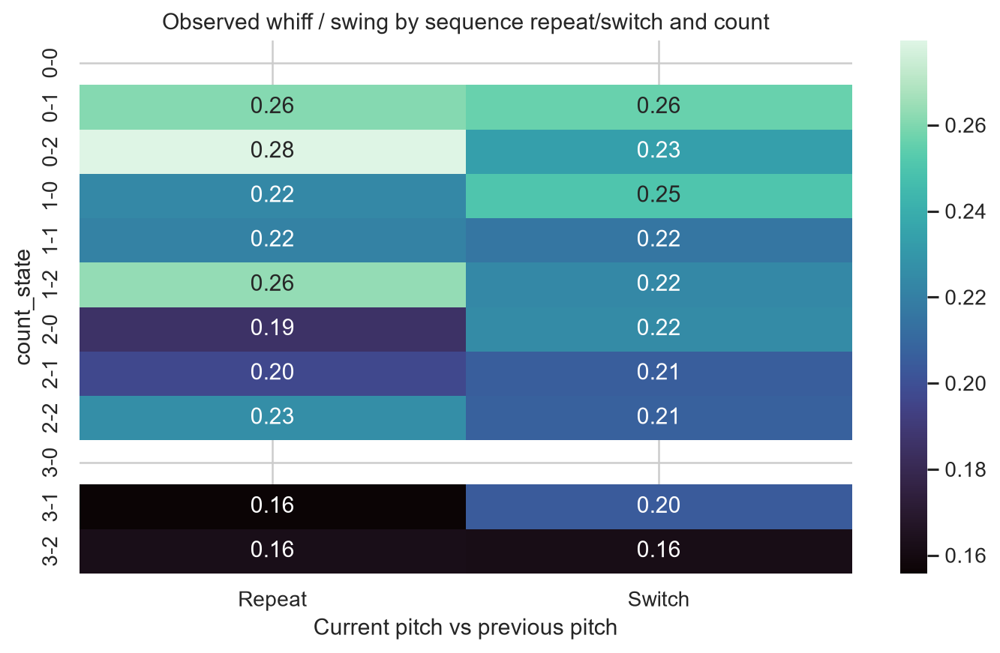

In [89]:
if 'seq_new' in globals() and len(seq_new):
    s=seq_new.loc[seq_new.prev_pitch.notna()&seq_new.swing_ind.eq(1)].copy()
    s['pitch_changed']=np.where(s.pitch_type.eq(s.prev_pitch),'Repeat','Switch')
    t=wilson_table(s,['count_state','pitch_changed'],'whiff_ind',min_n=100)
    if len(t):
        mat=t.pivot(index='count_state',columns='pitch_changed',values='rate')
        order=[f'{b}-{s}' for b in range(4) for s in range(3)]
        mat=mat.reindex(order)
        display(t.round(3));fig,ax=plt.subplots(figsize=(8,5));sns.heatmap(mat,annot=True,fmt='.2f',cmap='mako',ax=ax)
        ax.set(title='Observed whiff / swing by sequence repeat/switch and count',xlabel='Current pitch vs previous pitch')
        fig.tight_layout();publish(fig,'advanced_repeat_switch_count')

### 12.4 | Batter–pitcher direct matchups and sample sizes
Repeated observations between the same two players can be sparse and highly dependent. Results are exported with denominators and deliberately **not ranked** by observed rate.

In [90]:
encounter=(df.groupby(['batter','pitcher'])
          .agg(pitches=('whiff_ind','size'),swings=('swing_ind','sum'),whiffs=('whiff_ind','sum')).reset_index())
encounter['whiff_per_swing']=encounter.whiffs/encounter.swings.replace(0,np.nan)
print('Distinct observed batter-pitcher pairs:',len(encounter))
print('Pairs with >=10 swings:',int(encounter.swings.ge(10).sum()))
display(encounter.sort_values('pitches',ascending=False).head(15).round(3))
export_table(encounter,'batter_pitcher_encounters')

Distinct observed batter-pitcher pairs: 16411
Pairs with >=10 swings: 213


,batter,pitcher,pitches,swings,whiffs,whiff_per_swing
12624,677800,657746,36,15,3,0.200
3082,608070,647336,32,10,2,0.200
14182,682998,673540,31,14,3,0.214
3943,624413,668678,31,15,4,0.267
9960,668930,592791,31,11,0,0.000
8548,665742,668678,30,8,0,0.000
5388,646240,663978,30,10,2,0.200
8714,665833,607067,29,12,5,0.417
9662,668227,657376,29,13,4,0.308
5731,650489,665152,29,16,5,0.312


WindowsPath('I:/Potforlio/MLB Analytics/outputs/advanced_research/batter_pitcher_encounters.csv')

## 13 | Temporal Robustness and Statistical Modeling

### 13.1 | Matched-pitcher velocity shifts across observed years
Changes in league composition can create Simpson's paradox. Compare only pitchers appearing in both 2024 and 2025, with adequate pitch-type-specific sample.

Eligible matched pitcher/pitch-type pairs: 323


,velocity_change
count,323.000
mean,-0.043
std,1.213
min,-3.319
25%,-0.933
50%,-0.082
75%,0.754
max,4.337


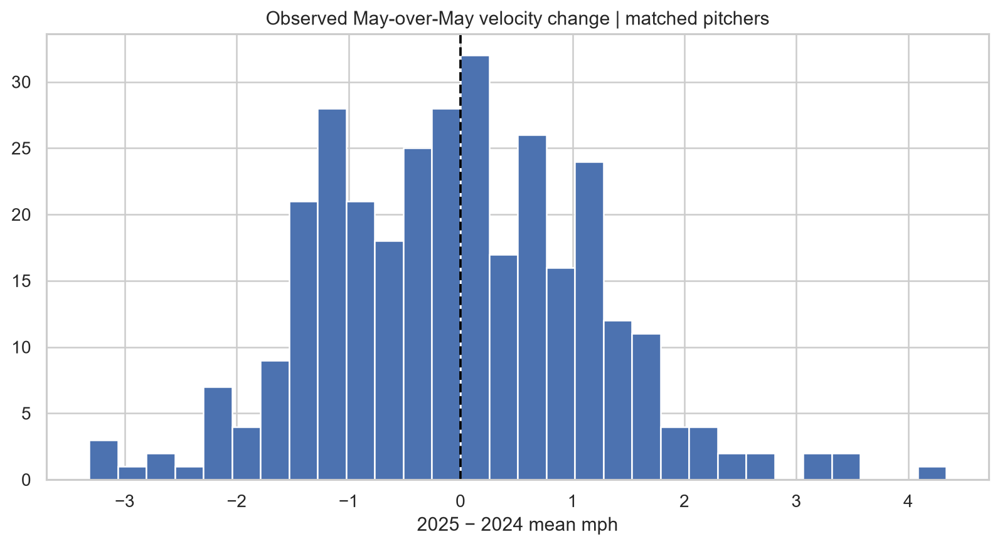

In [91]:
p=df.groupby(['pitcher','pitch_type','season']).release_speed.agg(n='count',mean='mean').reset_index()
wide=p.pivot(index=['pitcher','pitch_type'],columns='season',values=['n','mean'])
if (('n',2024) in wide.columns) and (('n',2025) in wide.columns):
    matched=wide.loc[(wide[('n',2024)]>=30)&(wide[('n',2025)]>=30)].copy()
    matched['change_mph']=matched[('mean',2025)]-matched[('mean',2024)]
    print('Eligible matched pitcher/pitch-type pairs:',len(matched))
    if len(matched):
        display(matched['change_mph'].describe().to_frame('velocity_change').round(3))
        fig,ax=plt.subplots(figsize=(9,5));ax.hist(matched['change_mph'].dropna(),bins=30)
        ax.axvline(0,color='black',ls='--');ax.set(title='Observed May-over-May velocity change | matched pitchers',xlabel='2025 − 2024 mean mph')
        fig.tight_layout();publish(fig,'advanced_matched_velocity')

### 13.2 | Pitch usage distribution shift between windows
Jensen–Shannon divergence summarizes league-level pitch mix changes, which may reflect pitcher sample composition rather than player adaptation.

Pitch-mix Jensen-Shannon divergence (bits): 0.00321


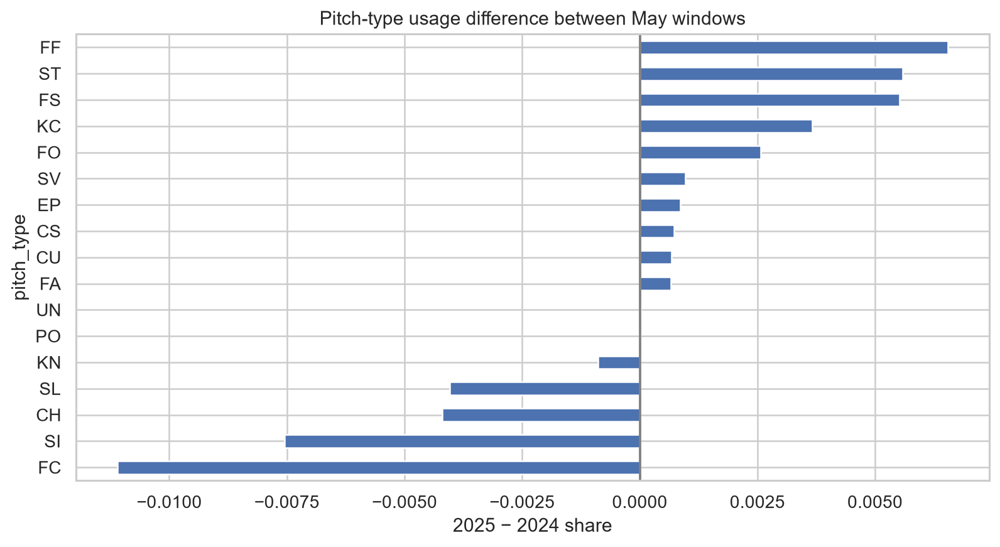

In [92]:
from scipy.spatial.distance import jensenshannon
mix_year=pd.crosstab(df.pitch_type,df.season).reindex(columns=[2024,2025],fill_value=0)
shares=mix_year.div(mix_year.sum(axis=0),axis=1)
if shares.shape[1]==2 and shares.sum().min()>0:
    js=float(jensenshannon(shares[2024],shares[2025],base=2)**2)
    print('Pitch-mix Jensen-Shannon divergence (bits):',round(js,5))
    fig,ax=plt.subplots(figsize=(9,5));d=(shares[2025]-shares[2024]).sort_values()
    d.plot.barh(ax=ax);ax.axvline(0,color='gray');ax.set(title='Pitch-type usage difference between May windows',xlabel='2025 − 2024 share')
    fig.tight_layout();publish(fig,'advanced_pitch_mix_shift')

### 13.3 | Game-cluster bootstrap for held-out probability performance
**Uncertainty question:** how stable are Brier Score and PR-AUC if entire games, rather than individual pitches, are resampled? This estimates variability in the fixed test predictions; it does not retrain the model.

,Brier,PR_AUC,ROC_AUC
low_95,0.0866,0.2174,0.7263
median,0.0884,0.2268,0.7330
high_95,0.0907,0.2367,0.7388


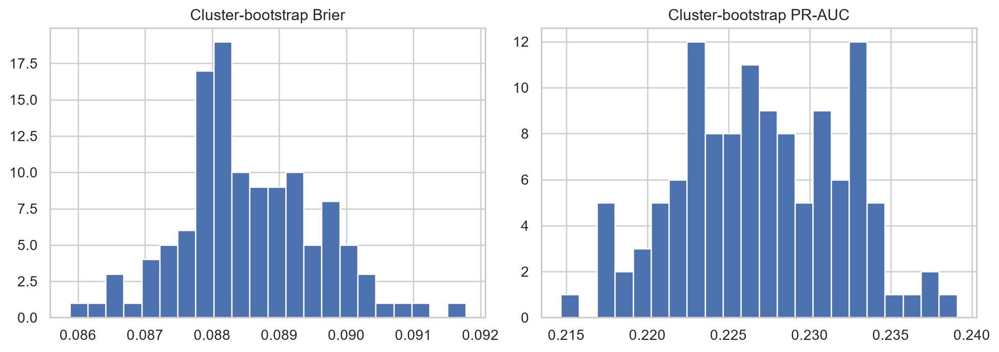

In [93]:
if 'hold' in globals() and len(hold)>100 and 'hold_p' in globals():
    performance=pd.DataFrame({'game_pk':hold.game_pk.to_numpy(),'y':np.asarray(hold_y,dtype=int),'p':np.asarray(hold_p,dtype=float)})
    game_indices=performance.groupby('game_pk').indices
    games=np.array(list(game_indices.keys()))
    rng=np.random.default_rng(42)
    bootstrap=[]
    for _ in range(120):
        sample_games=rng.choice(games,size=len(games),replace=True)
        idx=np.concatenate([game_indices[g] for g in sample_games])
        yy=performance.y.to_numpy()[idx]
        pp=performance.p.to_numpy()[idx]
        if len(np.unique(yy))==2:
            bootstrap.append({'Brier':brier_score_loss(yy,pp),'PR_AUC':average_precision_score(yy,pp),'ROC_AUC':roc_auc_score(yy,pp)})
    boot=pd.DataFrame(bootstrap)
    if len(boot):
        ci=boot.quantile([.025,.5,.975]).rename(index={.025:'low_95',.5:'median',.975:'high_95'})
        display(ci.round(4));export_table(ci.reset_index().rename(columns={'index':'quantile'}),'holdout_game_bootstrap')
        fig,axes=plt.subplots(1,2,figsize=(11,4))
        axes[0].hist(boot.Brier.dropna(),bins=22);axes[1].hist(boot.PR_AUC.dropna(),bins=22)
        axes[0].set(title='Cluster-bootstrap Brier');axes[1].set(title='Cluster-bootstrap PR-AUC')
        fig.tight_layout();publish(fig,'advanced_holdout_cluster_bootstrap')

### 13.4 | Group-robust logistic inference (2024 training only)
A clustered-binomial GLM estimates adjusted associations; with within-game correlated pitches the standard errors are clustered on `game_pk`. This is **not a causal model** and should be considered exploratory.

In [94]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
cols=['whiff_ind','swing_ind','pitch_type','stand','p_throws','balls','strikes','release_speed','game_pk']
reg=df.loc[df.season.eq(2024)&df.swing_ind.eq(1),cols].dropna().copy()
reg=reg.loc[reg.pitch_type.isin(reg.pitch_type.value_counts().head(5).index)]
if len(reg)>15000:
    reg=reg.sample(n=15000,random_state=42)
if len(reg)>300 and reg.whiff_ind.nunique()==2:
    formula='whiff_ind ~ C(pitch_type) + C(stand) + C(p_throws) + balls + strikes + release_speed'
    try:
        fitted=smf.glm(formula,data=reg,family=sm.families.Binomial()).fit(cov_type='cluster',cov_kwds={'groups':reg.game_pk},maxiter=100)
        t=pd.DataFrame({'coef':fitted.params,'se_cluster':fitted.bse,'odds_ratio':np.exp(fitted.params),'p_value':fitted.pvalues})
        display(t.round(4));export_table(t.reset_index().rename(columns={'index':'term'}),'clustered_glm_whiff')
    except Exception as exc:
        print('Grouped GLM not fitted:',str(exc)[:250])
else:
    print('Not enough eligible swinging pitches for clustered GLM.')

,coef,se_cluster,odds_ratio,p_value
Intercept,-4.1454,0.6929,0.0158,0.0000
C(pitch_type)[T.FC],-0.4966,0.0952,0.6086,0.0000
C(pitch_type)[T.FF],-0.8010,0.1025,0.4489,0.0000
C(pitch_type)[T.SI],-1.4019,0.1013,0.2461,0.0000
C(pitch_type)[T.SL],0.2403,0.0800,1.2716,0.0027
C(stand)[T.R],0.1164,0.0442,1.1234,0.0085
C(p_throws)[T.R],-0.1022,0.0489,0.9028,0.0366
balls,-0.1077,0.0243,0.8979,0.0000
strikes,-0.1289,0.0305,0.8791,0.0000
release_speed,0.0396,0.0081,1.0404,0.0000


### 13.5 | Temporal validation learning curve using only 2024
A restricted-model learning curve illustrates training-data requirements without reusing 2025 outcomes to choose a model. The logistic benchmark keeps computation tractable.

,training_pitches,fraction,ROC_AUC,PR_AUC,Brier,LogLoss
0,9202,0.25,0.6125,0.1491,0.0955,0.3362
1,18405,0.50,0.6209,0.1496,0.0952,0.3348
2,27607,0.75,0.6225,0.1513,0.0952,0.3346
3,36810,1.00,0.6239,0.1530,0.0951,0.3343


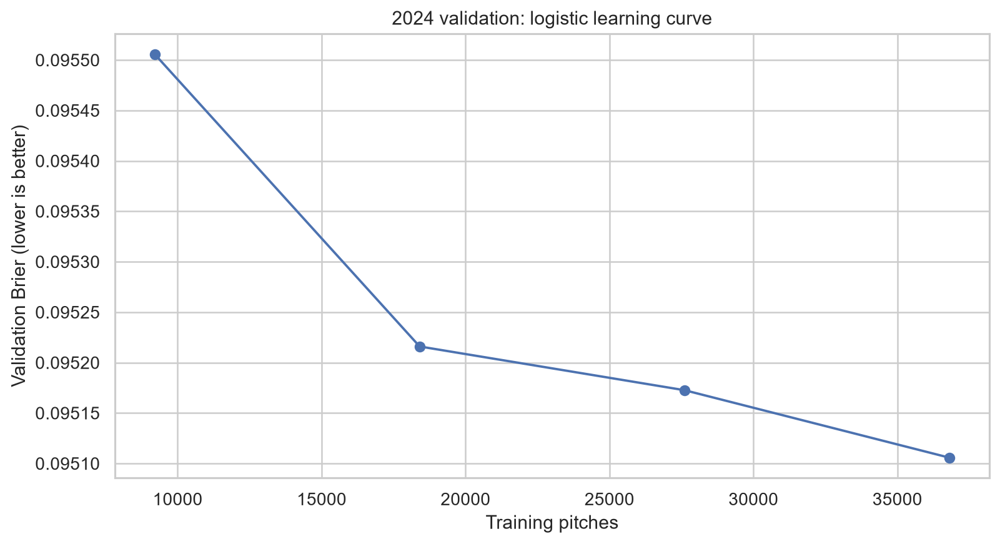

In [95]:
if 'tr' in globals() and 'va' in globals() and len(tr)>1000:
    fractions=[.25,.5,.75,1.0]
    rows=[]
    for frac in fractions:
        k=max(300,int(len(tr)*frac))
        subset=tr.iloc[-k:]
        obj=Pipeline([('prep',make_preprocess()),('model',LogisticRegression(max_iter=700))])
        obj.fit(subset[feature_cols],subset.whiff_ind.astype(int))
        pred=obj.predict_proba(va[feature_cols])[:,1]
        rows.append({'training_pitches':len(subset),'fraction':frac,**score(va.whiff_ind,pred)})
    learning=pd.DataFrame(rows)
    display(learning.round(4));export_table(learning,'validation_learning_curve')
    fig,ax=plt.subplots(figsize=(9,5));ax.plot(learning.training_pitches,learning.Brier,'o-')
    ax.set(title='2024 validation: logistic learning curve',xlabel='Training pitches',ylabel='Validation Brier (lower is better)')
    fig.tight_layout();publish(fig,'advanced_learning_curve')

### 13.6 | Data-shift diagnostic and prediction drift
A feature distribution can change across years even if predictive ranking remains stable. Only observed 2024/2025 data windows are compared.

In [96]:
shift_rows=[]
for fld in ['release_speed','release_spin_rate','plate_x','plate_z']:
    if fld in df:
        for season in [2024,2025]:
            sample=pd.to_numeric(df.loc[df.season.eq(season),fld],errors='coerce').dropna()
            shift_rows.append({'field':fld,'season':season,'n':len(sample),'mean':sample.mean(),'sd':sample.std(),'p10':sample.quantile(.1),'p90':sample.quantile(.9)})
shift=pd.DataFrame(shift_rows)
display(shift.round(3));export_table(shift,'physical_covariate_shift')

,field,season,n,mean,sd,p10,p90
0,release_speed,2024,53999,89.119,5.773,81.100,95.900
1,release_speed,2025,55333,89.342,5.992,81.200,96.200
2,release_spin_rate,2024,53951,2251.933,362.735,1831.000,2652.000
3,release_spin_rate,2025,55334,2270.589,365.626,1850.000,2668.000
4,plate_x,2024,54000,0.061,0.832,-1.001,1.117
5,plate_x,2025,55346,0.046,0.827,-0.999,1.104
6,plate_z,2024,54000,2.273,0.955,1.059,3.474
7,plate_z,2025,55346,2.312,0.951,1.107,3.507


WindowsPath('I:/Potforlio/MLB Analytics/outputs/advanced_research/physical_covariate_shift.csv')

## 14 | New Prediction Tasks and Diagnostics

### 14.1 | Conditional whiff **given a swing**
The original model predicts a whiff **per pitch**, combining swing decisions and contact. A new classifier models the probability of missing **among actual swings**, which is a different target.

In [97]:
from sklearn.ensemble import GradientBoostingClassifier
sw_train=train_all.loc[train_all.swing_ind.eq(1)].copy()
sw_hold=hold.loc[hold.swing_ind.eq(1)].copy()
if min(len(sw_train),len(sw_hold))>1000 and sw_train.whiff_ind.nunique()==2:
    conditional_models={
        'ConditionalLogistic':LogisticRegression(max_iter=900),
        'ConditionalGradientBoosting':HistGradientBoostingClassifier(max_iter=90,max_leaf_nodes=16,random_state=42)
    }
    conditional_scores=[]
    for name,est in conditional_models.items():
        pipeline=Pipeline([('prep',make_preprocess()),('model',est)])
        pipeline.fit(sw_train[feature_cols],sw_train.whiff_ind.astype(int))
        probs=pipeline.predict_proba(sw_hold[feature_cols])[:,1]
        conditional_scores.append({'model':name,**score(sw_hold.whiff_ind,probs)})
    conditional_scores.append({'model':'Train swing-whiff prevalence',**score(sw_hold.whiff_ind,np.full(len(sw_hold),sw_train.whiff_ind.mean()))})
    display(pd.DataFrame(conditional_scores).round(4))

,model,ROC_AUC,PR_AUC,Brier,LogLoss
0,ConditionalLogistic,0.6451,0.4563,0.1615,0.5055
1,ConditionalGradientBoosting,0.7713,0.5739,0.1364,0.4344
2,Train swing-whiff prevalence,0.5000,0.2241,0.1739,0.5321


### 14.2 | Chase probability on out-of-zone pitches
Out-of-zone locations, not all pitches, are the appropriate exposure set. The model uses only **measured pitch characteristics** and evaluates a chronologically later season.

In [98]:
chase_features=[f for f in feature_cols if f in df]
ch_train=train_all.loc[train_all.zone_known & ~train_all.in_zone].copy()
ch_hold=hold.loc[hold.zone_known & ~hold.in_zone].copy()
if len(ch_train)>500 and len(ch_hold)>500 and ch_train.swing_ind.nunique()==2:
    chase_model=Pipeline([('prep',make_preprocess()),('model',LogisticRegression(max_iter=800))])
    chase_model.fit(ch_train[chase_features],ch_train.swing_ind.astype(int))
    chase_pred=chase_model.predict_proba(ch_hold[chase_features])[:,1]
    display(pd.DataFrame([
        {'model':'ChaseLogistic',**score(ch_hold.swing_ind,chase_pred)},
        {'model':'ChaseTrainPrevalence',**score(ch_hold.swing_ind,np.full(len(ch_hold),ch_train.swing_ind.mean()))}
    ]).round(4))

,model,ROC_AUC,PR_AUC,Brier,LogLoss
0,ChaseLogistic,0.6392,0.383,0.1915,0.5672
1,ChaseTrainPrevalence,0.5000,0.278,0.2007,0.5911


### 14.3 | Hard-hit prediction: linear vs boosted nonlinear model
Both models use **only tracked in-play BBE**, and 2024 training / 2025 evaluation. This exercise is descriptive, not a causal quality-of-contact optimizer.

In [99]:
if 'batted' in globals() and not batted.empty:
    h_features=[f for f in ['pitch_type','stand','p_throws','release_speed','release_spin_rate','balls','strikes','pfx_x','pfx_z'] if f in batted]
    cat_h=[f for f in ['pitch_type','stand','p_throws'] if f in h_features]
    num_h=[f for f in h_features if f not in cat_h]
    hprep=ColumnTransformer([
        ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('enc',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat_h),
        ('num',Pipeline([('imp',SimpleImputer(strategy='median')),('std',StandardScaler())]),num_h)
    ])
    btr=batted.loc[batted.season.eq(2024)].copy();bte=batted.loc[batted.season.eq(2025)].copy()
    if len(btr)>500 and len(bte)>500 and btr.hard_hit.nunique()==2:
        contact_rows=[]
        for name,est in [('Logistic',LogisticRegression(max_iter=700)),('HistGradientBoosting',HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=14,random_state=42))]:
            pipe=Pipeline([('prep',hprep),('model',est)])
            pipe.fit(btr[h_features],btr.hard_hit.astype(int))
            pred=pipe.predict_proba(bte[h_features])[:,1]
            contact_rows.append({'model':name,**score(bte.hard_hit,pred)})
        contact_rows.append({'model':'Prevalence',**score(bte.hard_hit,np.full(len(bte),btr.hard_hit.mean()))})
        display(pd.DataFrame(contact_rows).round(4))

,model,ROC_AUC,PR_AUC,Brier,LogLoss
0,Logistic,0.5758,0.4926,0.2407,0.6745
1,HistGradientBoosting,0.5651,0.4711,0.2433,0.6802
2,Prevalence,0.5000,0.4222,0.2450,0.6832


### 14.4 | Holdout calibration by pitching hand and pitch type
Calibrated ranking is not guaranteed by a good ROC-AUC. Display bins and **sample sizes**; never treat a small group's calibration gap as bias without uncertainty.

,p_throws,pitch_type,n,observed,predicted,calibration_gap
20,R,FF,13411,0.082,0.097,0.014
25,R,SI,6260,0.056,0.052,-0.004
26,R,SL,6108,0.156,0.155,-0.001
6,L,FF,4175,0.101,0.091,-0.010
14,R,CH,3723,0.136,0.126,-0.010
27,R,ST,3578,0.125,0.132,0.006
19,R,FC,3018,0.091,0.106,0.014
10,L,SI,2410,0.065,0.059,-0.006
16,R,CU,2358,0.106,0.113,0.007
11,L,SL,2044,0.144,0.158,0.014


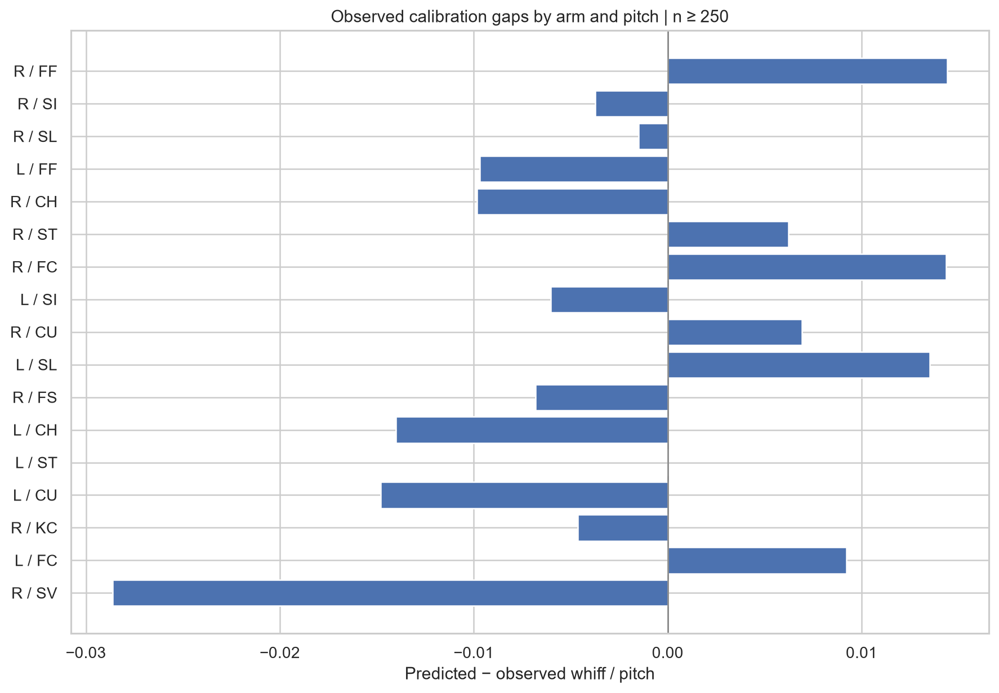

In [100]:
if 'monitor' in globals() and len(monitor):
    cal=monitor.groupby(['p_throws','pitch_type']).agg(n=('y','size'),observed=('y','mean'),predicted=('pred','mean')).reset_index()
    cal=cal.loc[cal.n>=250].copy()
    cal['calibration_gap']=cal.predicted-cal.observed
    cal=cal.sort_values('n',ascending=False).head(20)
    display(cal.round(3));export_table(cal,'holdout_pitch_arm_calibration')
    if len(cal):
        cal['label']=cal.p_throws.astype(str)+' / '+cal.pitch_type.astype(str)
        fig,ax=plt.subplots(figsize=(10,7));ax.barh(cal.label,cal.calibration_gap)
        ax.axvline(0,color='gray',lw=1);ax.invert_yaxis()
        ax.set(title='Observed calibration gaps by arm and pitch | n ≥ 250',xlabel='Predicted − observed whiff / pitch')
        fig.tight_layout();publish(fig,'advanced_arm_pitch_calibration')

## 15 | Research Synthesis and Submission Evidence

In [101]:
summary = pd.DataFrame([
    {'metric':'Pitches','value':len(df)},
    {'metric':'Games','value':df.game_pk.nunique()},
    {'metric':'Pitchers','value':df.pitcher.nunique()},
    {'metric':'Batters','value':df.batter.nunique()},
    {'metric':'BBE tracked','value':len(batted)},
    {'metric':'Hard-hit / tracked BBE','value':round(batted.hard_hit.mean(),4) if len(batted) else np.nan},
    {'metric':'Selected model','value':selected_name},
    {'metric':'Holdout Brier','value':float(hold_metrics.loc[0,'Brier'])},
    {'metric':'Holdout PR-AUC','value':float(hold_metrics.loc[0,'PR_AUC'])}
])
display(summary)
export_table(summary,'study_summary')
print('Supplementary figures:',len(list(FIGDIR.glob('advanced_*.png'))))
print('Reminder: outputs reflect selected May observation windows unless SAMPLE_MODE=False.')

,metric,value
0,Pitches,109346
1,Games,376
2,Pitchers,640
3,Batters,563
4,BBE tracked,19288
5,Hard-hit / tracked BBE,0.4063
6,Selected model,HistGradientBoosting
7,Holdout Brier,0.088679
8,Holdout PR-AUC,0.226949


Supplementary figures: 20
Reminder: outputs reflect selected May observation windows unless SAMPLE_MODE=False.


### Research interpretation and submission boundary

The findings in this notebook concern explicitly defined **sample windows**. To claim full-season statistics, rerun with `SAMPLE_MODE=False` and `HISTORY_MODE='full'`, validate all twelve seasons, and regenerate the corresponding report. For a sample-window research submission, report the actual dates, denominators and retrospective model status without extrapolation.


# 17 | Independent Evidence & Advanced Modeling

**Motivation.** This section complements Parts 1–16 without duplicating the basic per-pitch, per-hitter and repertoire summaries. It focuses on data eligibility, lineup composition, hitter selectivity, pitch-level uncertainty, contact predictions, temporal robustness and what the selected model can and cannot generalize to. All reported results are **observational**. Do not infer causal pitch-selection effects from these comparisons.

**Definitions.** Whiff per swing = whiffs / swings. Chase = swings on measured pitches outside the zone / measured pitches outside the zone. Hard hit = EV ≥ 95 mph among in-play BBE with measured EV. Unless explicitly noted, season labels refer to the two May 1–14 observation windows when `SAMPLE_MODE=True`.

In [102]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.base import clone
from statsmodels.stats.proportion import proportion_confint

EVIDENCE_DIR = ROOT / 'outputs' / 'research_v2'
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

def save_evidence(frame, name):
    frame.to_csv(EVIDENCE_DIR / f'{name}.csv', index=False)
    return frame

def safe_div(numerator, denominator):
    return np.divide(numerator, denominator, out=np.full_like(np.asarray(numerator, dtype=float), np.nan), where=np.asarray(denominator) != 0)

print('Additional research output:', EVIDENCE_DIR)


Additional research output: I:\Potforlio\MLB Analytics\outputs\research_v2


## 17.1 | Population selection and recording availability

**Research question:** does the exit-velocity-tracked population represent all balls in play equally across pitch types? Distinguish missing observations from legitimate unavailable outcomes. The measured BBE population is a *selected subset* of all pitches, not a random sample.

,season,pitch_type,pitches,bbe,tracked,bbe_per_pitch,ev_coverage_given_bbe
6,2024,FF,16805,2683,2678,0.160,0.998
12,2024,SI,8867,1856,1846,0.209,0.995
13,2024,SL,8172,1376,1372,0.168,0.997
0,2024,CH,5558,1100,1098,0.198,0.998
5,2024,FC,4344,797,797,0.183,1.000
14,2024,ST,4130,665,664,0.161,0.998
2,2024,CU,3201,515,513,0.161,0.996
8,2024,FS,1663,308,306,0.185,0.994
9,2024,KC,890,127,126,0.143,0.992
22,2025,FF,17586,2920,2912,0.166,0.997


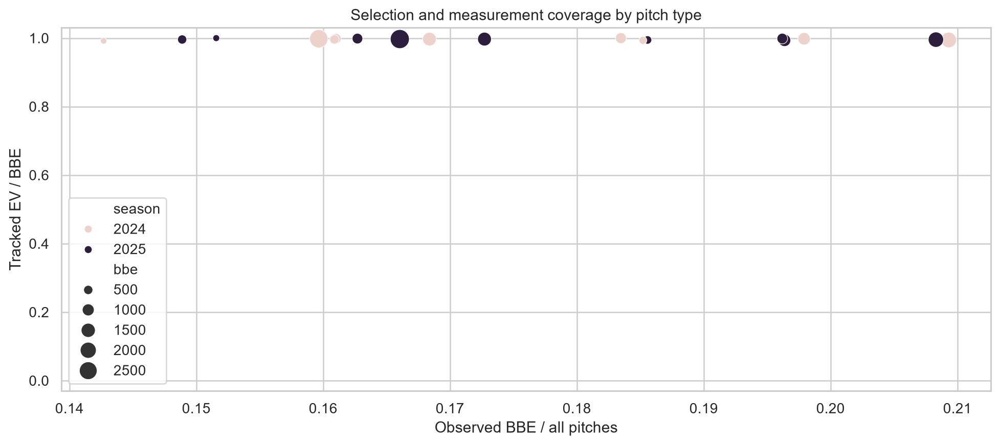

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/v2_tracking_selection.png')

In [103]:
population = df.copy()
population['tracked_ev_bbe'] = population['type'].eq('X') & population['launch_speed'].notna()
population['bbe_flag'] = population['type'].eq('X')
recording = population.groupby(['season', 'pitch_type'], observed=True).agg(
    pitches=('pitch_type', 'size'), bbe=('bbe_flag', 'sum'), tracked=('tracked_ev_bbe', 'sum')
).reset_index()
recording['bbe_per_pitch'] = safe_div(recording.bbe, recording.pitches)
recording['ev_coverage_given_bbe'] = safe_div(recording.tracked, recording.bbe)
recording = save_evidence(recording, 'bbes_tracking_coverage')
display(recording.query('bbe >= 50').sort_values(['season', 'bbe'], ascending=[True, False]).head(25).round(3))
fig, ax = plt.subplots(figsize=(11, 5))
view = recording.query('bbe >= 80').sort_values('bbe', ascending=False)
sns.scatterplot(data=view, x='bbe_per_pitch', y='ev_coverage_given_bbe', hue='season', size='bbe', sizes=(25, 220), ax=ax)
ax.set(xlabel='Observed BBE / all pitches', ylabel='Tracked EV / BBE', title='Selection and measurement coverage by pitch type')
ax.set_ylim(-.03, 1.03)
fig.tight_layout(); publish(fig, 'v2_tracking_selection')


## 17.2 | Hitter selectivity: chase and zone-swing are different skills

**Research question:** which batters avoid chasing without giving up too many swings at pitches inside the zone? Only hitters meeting the minimum exposure thresholds appear. Note that the `zone` field represents a location classification; it is not a human umpire's called-strike label.

Qualified hitters: 428


,batter,pitches,swings,out_pitches,in_n,in_swings,out_n,out_swings,zone_swing_rate,chase_rate
547,700337,146,64,63,83,58,63,6,0.699,0.095
151,641658,100,41,46,54,36,46,5,0.667,0.109
438,680474,187,71,92,95,60,92,11,0.632,0.120
130,624415,136,51,57,79,44,57,7,0.557,0.123
264,664774,364,129,179,185,107,179,22,0.578,0.123
246,663757,256,88,121,135,73,121,15,0.541,0.124
177,645444,97,33,47,50,27,47,6,0.540,0.128
304,666397,192,66,97,95,53,97,13,0.558,0.134
339,669234,89,35,44,45,29,44,6,0.644,0.136
493,686555,125,49,58,67,41,58,8,0.612,0.138


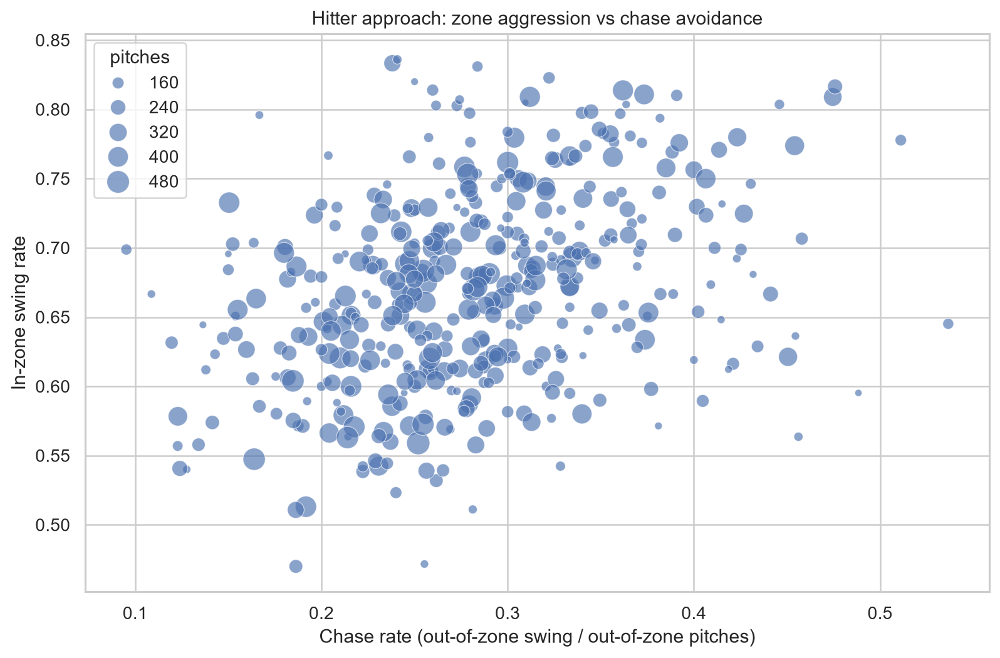

In [104]:
zone_eligible = df.loc[df.zone_known & df.stand.isin(['L', 'R'])].copy()
zone_eligible['outside'] = ~zone_eligible.in_zone
selectivity = zone_eligible.groupby('batter').agg(
    pitches=('swing_ind', 'size'), swings=('swing_ind', 'sum'),
    out_pitches=('outside', 'sum')
).reset_index()
inside = zone_eligible.loc[zone_eligible.in_zone].groupby('batter').swing_ind.agg(in_n='size', in_swings='sum')
outside = zone_eligible.loc[~zone_eligible.in_zone].groupby('batter').swing_ind.agg(out_n='size', out_swings='sum')
selectivity = selectivity.join(inside, on='batter').join(outside, on='batter')
selectivity['zone_swing_rate'] = safe_div(selectivity.in_swings, selectivity.in_n)
selectivity['chase_rate'] = safe_div(selectivity.out_swings, selectivity.out_n)
selectivity = save_evidence(selectivity, 'hitter_selectivity')
qualified = selectivity.query('in_n >= 40 and out_n >= 40').copy()
print('Qualified hitters:', len(qualified))
display(qualified.sort_values('chase_rate').head(12).round(3))
if not qualified.empty:
    fig, ax = plt.subplots(figsize=(9, 6))
    sns.scatterplot(data=qualified, x='chase_rate', y='zone_swing_rate', size='pitches', sizes=(20, 220), alpha=.65, ax=ax)
    ax.set(xlabel='Chase rate (out-of-zone swing / out-of-zone pitches)', ylabel='In-zone swing rate', title='Hitter approach: zone aggression vs chase avoidance')
    fig.tight_layout(); publish(fig, 'v2_hitter_selectivity')


## 17.3 | Count-conditioned hitter discipline

**Research question:** does chase rise as a hitter approaches two strikes? Report counts and Wilson intervals to prevent small groups from appearing definitive. Differences may reflect pitch selection, pitcher behavior, and selection into the count.

,season,count_group,n,k,rate,low,high
0,2024,0 strikes,9682,1665,0.1720,0.1646,0.1796
1,2024,1 strike,8149,2418,0.2967,0.2869,0.3067
2,2024,2 strikes,9366,3619,0.3864,0.3766,0.3963
3,2025,0 strikes,9800,1652,0.1686,0.1613,0.1761
4,2025,1 strike,8258,2409,0.2917,0.2820,0.3016
5,2025,2 strikes,9254,3532,0.3817,0.3718,0.3916


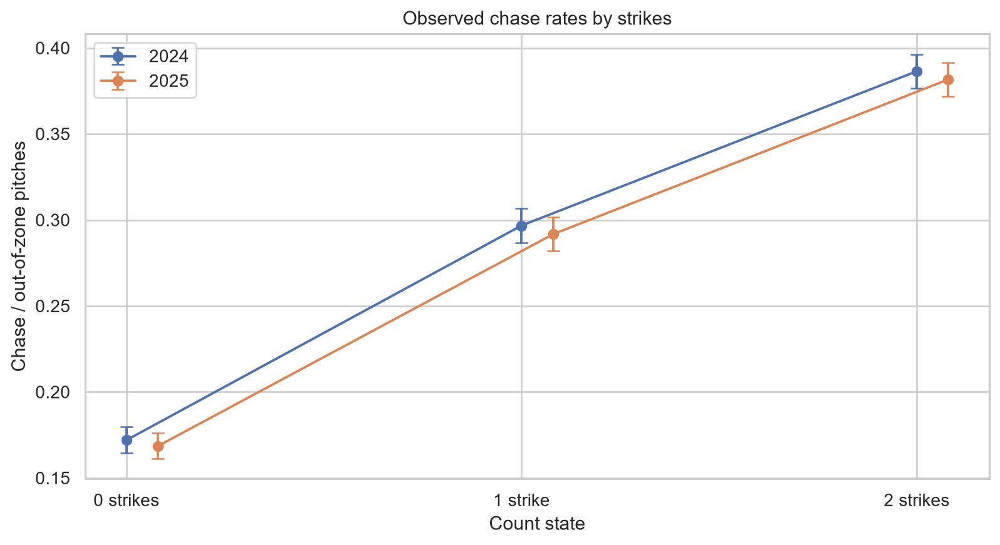

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/v2_count_chase_ci.png')

In [105]:
outside = df.loc[df.zone_known & ~df.in_zone].copy()
outside['count_group'] = np.select([outside.strikes.eq(0), outside.strikes.eq(1), outside.strikes.eq(2)], ['0 strikes', '1 strike', '2 strikes'], default='Unknown')
count_chase = outside.groupby(['season', 'count_group'], observed=True).swing_ind.agg(n='size', k='sum').reset_index()
count_chase['rate'] = safe_div(count_chase.k, count_chase.n)
count_chase['low'], count_chase['high'] = proportion_confint(count_chase.k, count_chase.n, method='wilson')
save_evidence(count_chase, 'count_chase_wilson')
display(count_chase.round(4))
fig, ax = plt.subplots(figsize=(9, 5))
for season, part in count_chase.groupby('season'):
    part = part.set_index('count_group').reindex(['0 strikes', '1 strike', '2 strikes']).dropna(subset=['rate'])
    xx=np.arange(len(part)) + (int(season)-2024)*.08
    ax.errorbar(xx, part.rate, yerr=[part.rate-part.low, part.high-part.rate], fmt='o-', capsize=4, label=str(season))
ax.set_xticks(np.arange(3)); ax.set_xticklabels(['0 strikes', '1 strike', '2 strikes'])
ax.set(title='Observed chase rates by strikes', xlabel='Count state', ylabel='Chase / out-of-zone pitches')
ax.legend(); fig.tight_layout(); publish(fig, 'v2_count_chase_ci')


# 18 | Pitcher/Batter Heterogeneity and Context

Heterogeneity is an important confounder: league-average pitch results may change simply because different players and pitch types are represented in each window. These analyses are **within the available May observations**.

,pitcher,swings,raw_whiff_rate,count_standardized_rate
9,656302,293,0.369,0.370
8,641927,284,0.271,0.273
14,808967,279,0.262,0.260
5,605400,276,0.185,0.185
3,547179,267,0.225,0.223
7,608379,258,0.167,0.168
0,434378,257,0.191,0.190
12,669373,257,0.374,0.372
2,543243,257,0.226,0.228
1,519242,251,0.339,0.342


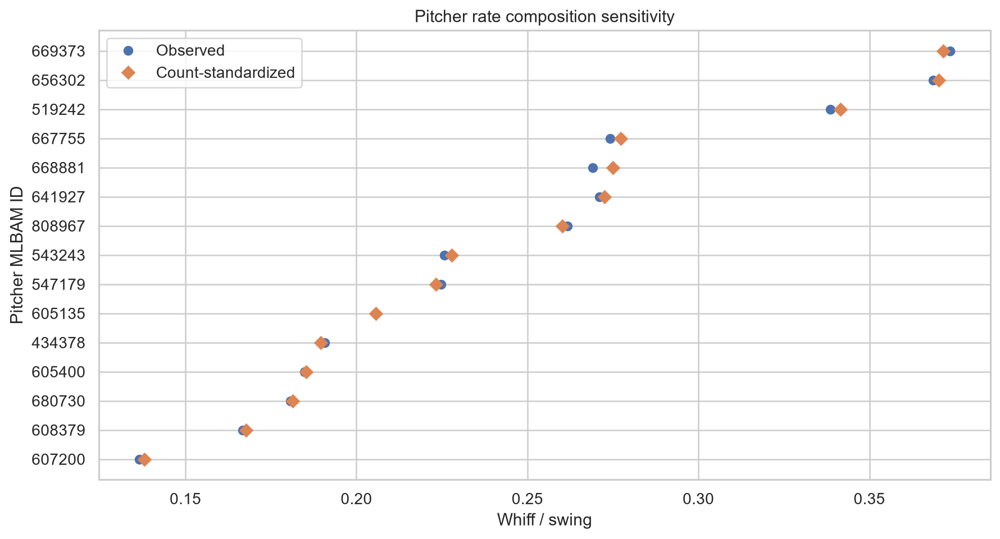

In [106]:
qs = df.loc[df.swing_ind.eq(1) & df.strikes.isin([0, 1, 2])].copy()
reference = qs.strikes.value_counts(normalize=True).reindex([0, 1, 2]).fillna(0)
players = qs.groupby('pitcher').size().loc[lambda x: x >= 100].nlargest(15).index
adjusted=[]
for pitcher, part in qs.loc[qs.pitcher.isin(players)].groupby('pitcher'):
    counts=part.groupby('strikes').whiff_ind.agg(n='size', rate='mean').reindex([0, 1, 2])
    if counts.n.fillna(0).ge(15).all():
        adjusted.append({'pitcher':int(pitcher), 'swings':len(part), 'raw_whiff_rate':float(part.whiff_ind.mean()),
                         'count_standardized_rate':float((counts.rate * reference).sum())})
adj_pitcher=pd.DataFrame(adjusted, columns=['pitcher', 'swings', 'raw_whiff_rate', 'count_standardized_rate'])
save_evidence(adj_pitcher, 'pitcher_count_standardization')
display(adj_pitcher.sort_values('swings', ascending=False).round(3))
if len(adj_pitcher):
    p=adj_pitcher.sort_values('count_standardized_rate')
    fig, ax=plt.subplots(figsize=(10, max(4, .3*len(p)+1)))
    yy=np.arange(len(p)); ax.plot(p.raw_whiff_rate, yy, 'o', label='Observed')
    ax.plot(p.count_standardized_rate, yy, 'D', label='Count-standardized')
    ax.set_yticks(yy); ax.set_yticklabels(p.pitcher.astype(str))
    ax.set(xlabel='Whiff / swing', ylabel='Pitcher MLBAM ID', title='Pitcher rate composition sensitivity')
    ax.legend(); fig.tight_layout(); publish(fig, 'v2_pitcher_count_adjusted')


## 18.1 | Matched player sensitivity across years

Calculate rates only for batters who are observed in both periods. Paired differences are **not** player development estimates; they describe 14-day snapshots, subject to opponent quality and sampling error.

season,batter,2024,2025,difference_2025_minus_2024
count,199.0000,199.0000,199.0000,199.0000
mean,642217.7337,0.2210,0.2180,-0.0030
std,52159.1667,0.0764,0.0704,0.0809
min,455117.0000,0.0492,0.0189,-0.2922
25%,621529.5000,0.1677,0.1709,-0.0559
50%,663697.0000,0.2184,0.2162,0.0022
75%,671735.5000,0.2592,0.2634,0.0503
max,808982.0000,0.4800,0.4366,0.1924


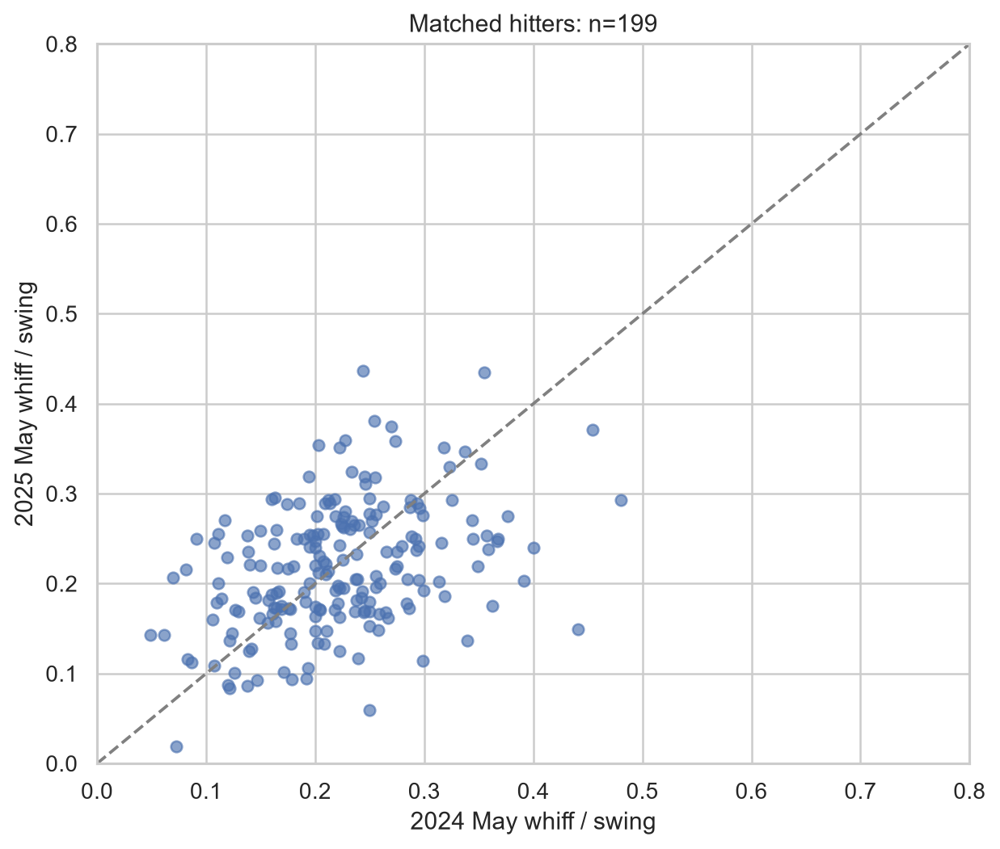

In [107]:
sw = df.loc[df.swing_ind.eq(1)].groupby(['batter', 'season']).whiff_ind.agg(n='size', rate='mean').reset_index()
wide_n=sw.pivot(index='batter',columns='season',values='n')
wide_rate=sw.pivot(index='batter',columns='season',values='rate')
if {2024,2025}.issubset(wide_n.columns):
    matched = wide_rate.loc[wide_n[2024].ge(35) & wide_n[2025].ge(35), [2024,2025]].dropna().copy()
    matched['difference_2025_minus_2024'] = matched[2025]-matched[2024]
    matched=save_evidence(matched.reset_index(), 'matched_hitter_whiff_windows')
    display(matched.describe(include='all').round(4))
    if len(matched)>4:
        fig,ax=plt.subplots(figsize=(7,6))
        ax.scatter(matched[2024],matched[2025],alpha=.65,s=30)
        ax.plot([0,1],[0,1],'--',color='grey')
        ax.set(xlim=(0,.8),ylim=(0,.8), xlabel='2024 May whiff / swing',ylabel='2025 May whiff / swing',title=f'Matched hitters: n={len(matched)}')
        fig.tight_layout(); publish(fig,'v2_matched_hitter_whiff')
else:
    print('Paired batter analysis requires both periods.')


## 18.2 | First-pitch decision states

The 0–0 count is a controlled comparison point, though not identical in all contextual conditions. Compare whether the first pitch is swung at, taken for a called strike, or put into play; categories are not necessarily exhaustive.

,season,stand,n,swing_rate,called_strike_rate,bbe_rate
0,2024,L,5964,0.311,0.299,0.111
1,2024,R,7925,0.326,0.304,0.115
2,2025,L,6235,0.311,0.293,0.114
3,2025,R,8100,0.330,0.302,0.126


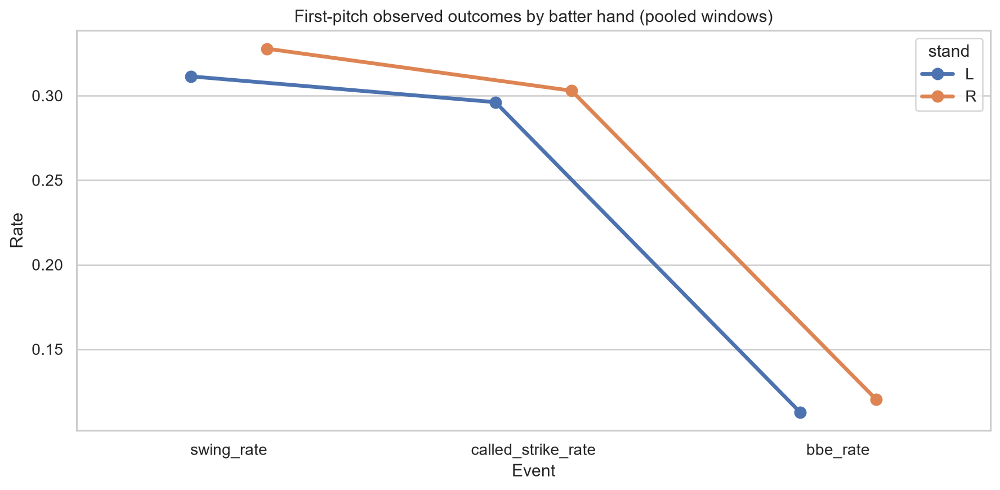

In [108]:
first=df.loc[df.balls.eq(0) & df.strikes.eq(0)].copy()
first['swing'] = first.swing_ind.eq(1)
first['called_strike'] = first.description.eq('called_strike')
first['in_play'] = first.type.eq('X')
first_stats=first.groupby(['season','stand']).agg(
    n=('swing','size'), swing_rate=('swing','mean'), called_strike_rate=('called_strike','mean'), bbe_rate=('in_play','mean')
).reset_index()
save_evidence(first_stats,'first_pitch_decisions')
display(first_stats.round(3))
if len(first_stats):
    pooled=first.groupby('stand').agg(swing_rate=('swing','mean'),called_strike_rate=('called_strike','mean'),bbe_rate=('in_play','mean')).reset_index()
    melted=pooled.melt(id_vars=['stand'],value_vars=['swing_rate','called_strike_rate','bbe_rate'],var_name='event',value_name='rate')
    fig,ax=plt.subplots(figsize=(10,5))
    sns.pointplot(data=melted,x='event',y='rate',hue='stand',dodge=.25,errorbar=None,ax=ax)
    ax.set(title='First-pitch observed outcomes by batter hand (pooled windows)',xlabel='Event',ylabel='Rate')
    fig.tight_layout(); publish(fig,'v2_first_pitch_decision_detail')


# 19 | Batted-Ball Quality: Proper Denominators & New Prediction Target

All regression examples in this chapter use **only tracked in-play BBE**. Predictions are conditional on a ball being put in play and tracked; they are not the unconditional expected value of a pitch. No launch speed or launch angle is included as a predictor when predicting launch speed.

,season,pitch_type,n,mean_ev,hard_hits,hard_hit_rate,low,high
6,2024,FF,2678,90.649,1205,0.450,0.431,0.469
10,2024,SI,1846,89.447,813,0.440,0.418,0.463
11,2024,SL,1372,86.932,473,0.345,0.320,0.370
0,2024,CH,1098,86.338,344,0.313,0.287,0.341
5,2024,FC,797,88.308,306,0.384,0.351,0.418
12,2024,ST,664,84.762,176,0.265,0.233,0.300
2,2024,CU,513,87.996,191,0.372,0.332,0.415
7,2024,FS,306,87.337,116,0.379,0.327,0.435
8,2024,KC,126,88.658,46,0.365,0.286,0.452
20,2025,FF,2912,91.282,1385,0.476,0.458,0.494


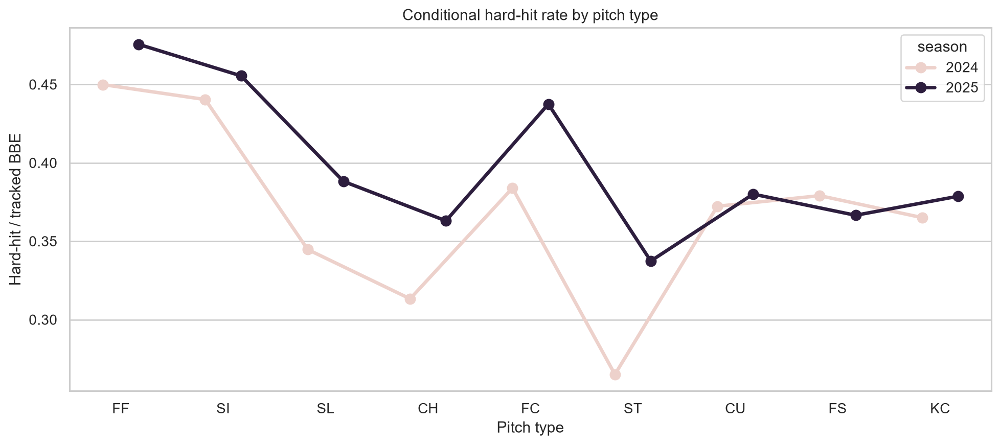

In [109]:
contact_count = batted.groupby(['season','pitch_type'],observed=True).agg(n=('launch_speed','size'), mean_ev=('launch_speed','mean'), hard_hits=('hard_hit','sum')).reset_index()
contact_count['hard_hit_rate'] = safe_div(contact_count.hard_hits,contact_count.n)
low, high = proportion_confint(contact_count.hard_hits.astype(int),contact_count.n.astype(int),method='wilson')
contact_count['low']=low;contact_count['high']=high
contact_count=save_evidence(contact_count,'contact_wilson_by_pitch_type')
q=contact_count.loc[contact_count.n.ge(75)].sort_values(['season','n'],ascending=[True,False]).copy()
display(q.head(25).round(3))
if len(q):
    fig,ax=plt.subplots(figsize=(11,5))
    sns.pointplot(data=q,x='pitch_type',y='hard_hit_rate',hue='season',errorbar=None,dodge=.35,ax=ax)
    ax.set(title='Conditional hard-hit rate by pitch type',xlabel='Pitch type',ylabel='Hard-hit / tracked BBE')
    fig.tight_layout();publish(fig,'v2_contact_by_pitch_and_year')


## 19.1 | Predicting exit velocity conditional on BBE

**Novel outcome and model family:** compare mean-only, regularized linear and nonlinear HistGradientBoosting **regressors** using common training/validation rows. Selection uses a chronological 2024 validation period; 2025 is a retrospective descriptive evaluation. All predictors are observed pitch descriptors available *by/after pitch release*, not contact outcomes.

,model,MAE,RMSE,R2
2,HistGradientBoostingRegressor,10.851,14.406,0.142
1,Ridge,11.758,15.321,0.029
0,DummyMean,11.983,15.553,-0.001


,model,n_test,MAE,RMSE,R2
0,HistGradientBoostingRegressor,9824,10.498,13.66,0.172


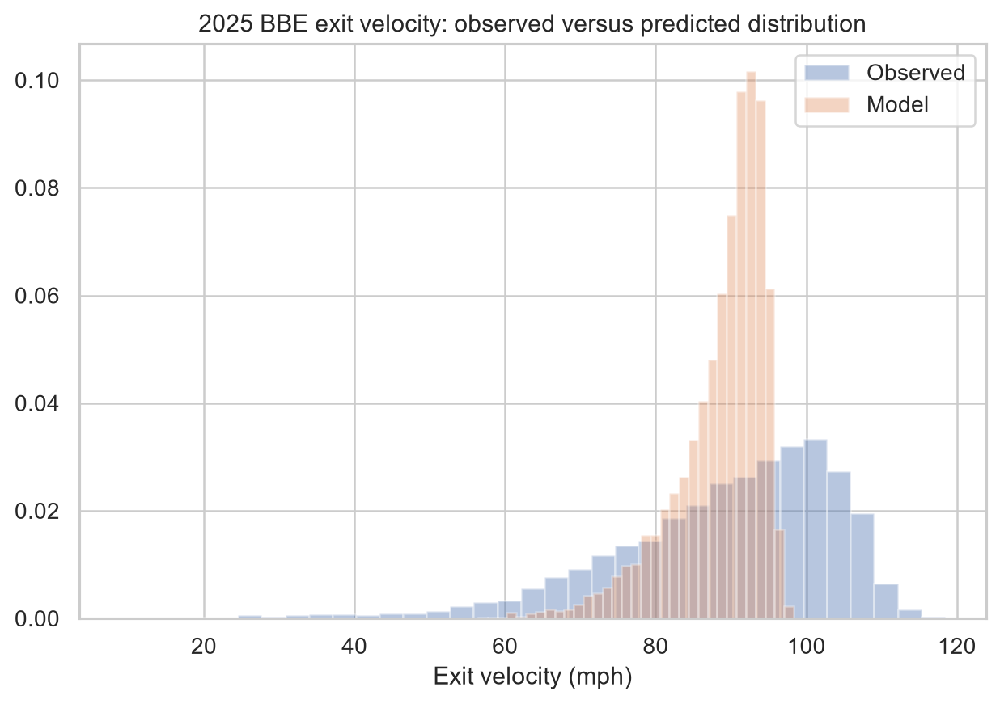

In [110]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

EV_COLS=[x for x in ['pitch_type','stand','p_throws','release_speed','release_spin_rate','pfx_x','pfx_z','plate_x','plate_z','balls','strikes'] if x in batted]
EV_CAT=[x for x in ['pitch_type','stand','p_throws'] if x in EV_COLS]
EV_NUM=[x for x in EV_COLS if x not in EV_CAT]

def ev_preprocessor():
    return ColumnTransformer([
        ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),EV_CAT),
        ('num',Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())]),EV_NUM)
    ],sparse_threshold=0)

def regression_scores(y,p):
    return {'MAE':mean_absolute_error(y,p),'RMSE':float(np.sqrt(mean_squared_error(y,p))),'R2':r2_score(y,p)}

tracked=batted.dropna(subset=['launch_speed','game_date']).sort_values('game_date').copy()
ev2024=tracked.loc[tracked.season.eq(2024)].copy()
ev2025=tracked.loc[tracked.season.eq(2025)].copy()
days=ev2024.game_date.drop_duplicates().sort_values()
if len(days)>=5 and len(ev2024)>100 and len(ev2025)>100:
    evcut=days.iloc[max(0,int(len(days)*.75)-1)]
    evtr=ev2024.loc[ev2024.game_date.le(evcut)]
    evva=ev2024.loc[ev2024.game_date.gt(evcut)]
    evmodels={'DummyMean':DummyRegressor(strategy='mean'), 'Ridge':Ridge(alpha=30),
              'HistGradientBoostingRegressor':HistGradientBoostingRegressor(max_iter=95,max_leaf_nodes=15,min_samples_leaf=30,random_state=42)}
    results=[]
    for name,algo in evmodels.items():
        pipe=Pipeline([('prep',ev_preprocessor()),('model',clone(algo))])
        pipe.fit(evtr[EV_COLS],evtr.launch_speed)
        pred=pipe.predict(evva[EV_COLS])
        results.append({'model':name,**regression_scores(evva.launch_speed,pred)})
    ev_validation=save_evidence(pd.DataFrame(results).sort_values('MAE'),'exit_velocity_2024_validation')
    display(ev_validation.round(3))
    ev_selected=ev_validation.iloc[0]['model']
    final_ev=Pipeline([('prep',ev_preprocessor()),('model',clone(evmodels[ev_selected]))])
    final_ev.fit(ev2024[EV_COLS],ev2024.launch_speed)
    test_preds=final_ev.predict(ev2025[EV_COLS])
    ev_holdout=save_evidence(pd.DataFrame([{'model':ev_selected,'n_test':len(ev2025),**regression_scores(ev2025.launch_speed,test_preds)}]),'exit_velocity_2025_holdout')
    display(ev_holdout.round(3))
    fig,ax=plt.subplots(figsize=(7,5))
    plot_ev=pd.DataFrame({'actual':ev2025.launch_speed.to_numpy(),'prediction':test_preds})
    ax.hist(plot_ev.actual, bins=35, density=True, alpha=.4, label='Observed')
    ax.hist(plot_ev.prediction, bins=35, density=True, alpha=.35, label='Model')
    ax.set(title='2025 BBE exit velocity: observed versus predicted distribution',xlabel='Exit velocity (mph)')
    ax.legend();fig.tight_layout();publish(fig,'v2_exit_velocity_predictions')
else:
    print('Insufficient matched time windows for exit-velocity regression.')


## 19.2 | Expected contact xwOBA is not a new independent outcome

Statcast `estimated_woba_using_speedangle` is derived from the contact measurement itself. Avoid predicting it from EV/launch angle and calling the result an independent discovery. Here it is used for **descriptive comparison only**, restricted to measured eligible contacts.

In [111]:
if 'estimated_woba_using_speedangle' in batted:
    expected=batted.copy()
    expected['contact_xwoba']=pd.to_numeric(expected.estimated_woba_using_speedangle,errors='coerce')
    evx=expected.loc[expected.contact_xwoba.notna()].groupby(['pitch_type','season'],observed=True).contact_xwoba.agg(n='size',mean='mean').reset_index()
    evx=save_evidence(evx,'observed_xwoba_contact')
    display(evx.loc[evx.n.ge(50)].sort_values('n',ascending=False).head(20).round(3))
else:
    print('Expected contact wOBA is unavailable in this export.')


,pitch_type,season,n,mean
13,FF,2025,2896,0.404
12,FF,2024,2673,0.391
20,SI,2024,1837,0.371
21,SI,2025,1788,0.351
23,SL,2025,1397,0.366
22,SL,2024,1367,0.364
0,CH,2024,1096,0.346
1,CH,2025,1063,0.360
10,FC,2024,793,0.378
11,FC,2025,749,0.375


# 20 | Prediction Reliability: Temporal Folds, Calibration and Player Coverage

The existing model uses measured pitch physical/location features. The following studies test robustness and heterogeneous performance. **Do not use 2025 test rows to select among new candidate algorithms or thresholds.**

,fold,model,train_n,validation_n,train_end,validation_end,ROC_AUC,PR_AUC,Brier,LogLoss
0,1,Logistic,14787,7035,2024-05-04,2024-05-06,0.6143,0.1512,0.0961,0.3382
1,1,HistGradientBoosting,14787,7035,2024-05-04,2024-05-06,0.7002,0.2038,0.0932,0.3219
2,2,Logistic,26251,6408,2024-05-07,2024-05-09,0.6012,0.1450,0.0978,0.3437
3,2,HistGradientBoosting,26251,6408,2024-05-07,2024-05-09,0.7179,0.2124,0.0934,0.3200
4,3,Logistic,36810,8844,2024-05-10,2024-05-12,0.6147,0.1395,0.0914,0.3247
5,3,HistGradientBoosting,36810,8844,2024-05-10,2024-05-12,0.7101,0.1967,0.0881,0.3062


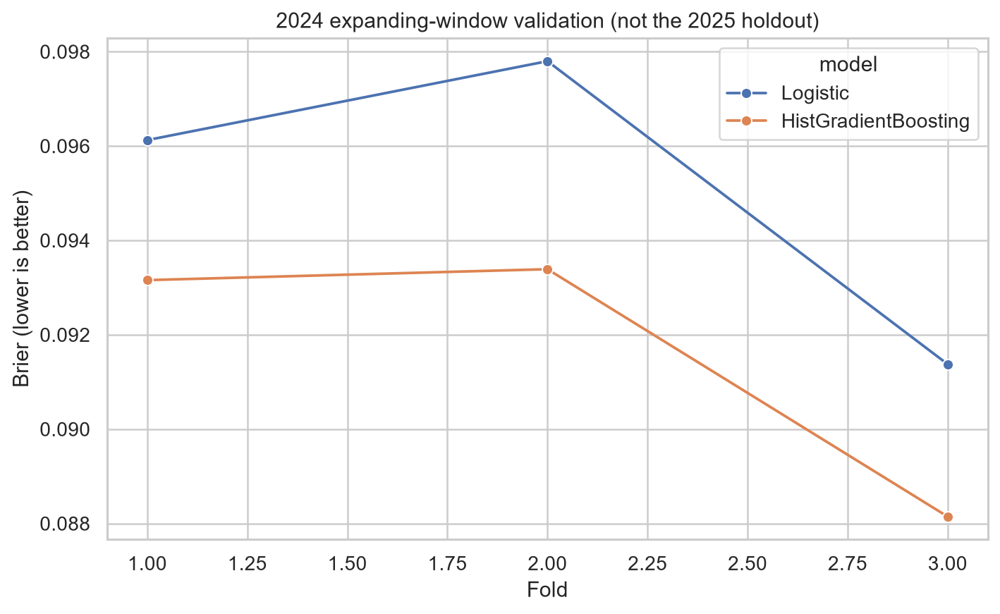

In [112]:
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

ordered_days=train_all.game_date.drop_duplicates().sort_values().tolist()
cv_rows=[]
fold_cutpoints=[.35,.55,.75]
for ix,fraction in enumerate(fold_cutpoints,1):
    cutoff_idx=min(len(ordered_days)-2,max(0,int(len(ordered_days)*fraction)-1))
    train_end=ordered_days[cutoff_idx]
    next_idx=min(len(ordered_days),max(cutoff_idx+1,cutoff_idx+3))
    val_end=ordered_days[next_idx-1]
    sub_train=train_all.loc[train_all.game_date.le(train_end)]
    sub_test=train_all.loc[(train_all.game_date.gt(train_end)) & (train_all.game_date.le(val_end))]
    if len(sub_train)<250 or len(sub_test)<100 or sub_train.whiff_ind.nunique()<2:
        continue
    for name,model in [('Logistic',LogisticRegression(max_iter=650)),
                       ('HistGradientBoosting',HistGradientBoostingClassifier(max_iter=75,max_leaf_nodes=16,random_state=42))]:
        fitted=Pipeline([('prep',make_preprocess()),('model',clone(model))])
        fitted.fit(sub_train[feature_cols],sub_train.whiff_ind.astype(int))
        pp=fitted.predict_proba(sub_test[feature_cols])[:,1]
        cv_rows.append({'fold':ix,'model':name,'train_n':len(sub_train),'validation_n':len(sub_test),
                        'train_end':pd.Timestamp(train_end).date().isoformat(),
                        'validation_end':pd.Timestamp(val_end).date().isoformat(),**score(sub_test.whiff_ind,pp)})
fold_results=save_evidence(pd.DataFrame(cv_rows), 'expanding_2024_validation')
display(fold_results.round(4))
if not fold_results.empty:
    fig,ax=plt.subplots(figsize=(8,5))
    sns.lineplot(data=fold_results,x='fold',y='Brier',hue='model',marker='o',ax=ax)
    ax.set(title='2024 expanding-window validation (not the 2025 holdout)',xlabel='Fold',ylabel='Brier (lower is better)')
    fig.tight_layout();publish(fig,'v2_expanding_cv_brier')


## 20.1 | 2025 holdout: previously observed vs newly observed batters and pitchers

These are subgroup *diagnostics only*, not model-selection metrics. Low support or only one outcome class makes some metrics undefined. New players are defined relative to observed 2024 training players, not MLB career debuts.

In [113]:
if 'hold_p' in globals() and len(hold_p)==len(hold):
    monitoring = hold[['game_pk','pitcher','batter','pitch_type','p_throws','stand']].copy()
    monitoring['y'] = np.asarray(hold_y, dtype=int)
    monitoring['pred'] = np.asarray(hold_p, dtype=float)
    monitoring['pitcher_seen_2024'] = monitoring.pitcher.isin(train_all.pitcher.unique())
    monitoring['batter_seen_2024'] = monitoring.batter.isin(train_all.batter.unique())
    eval_rows=[]
    for segmentation in ['pitcher_seen_2024','batter_seen_2024']:
        for group,part in monitoring.groupby(segmentation):
            if len(part) >= 50:
                met=score(part.y,part.pred)
                eval_rows.append({'segment':segmentation,'seen_in_2024':bool(group),'n':len(part),
                                  'rate':part.y.mean(),**met})
    group_reliability=save_evidence(pd.DataFrame(eval_rows),'holdout_seen_vs_unseen_players')
    display(group_reliability.round(4))
else:
    print('Holdout predictions unavailable.')


,segment,seen_in_2024,n,rate,ROC_AUC,PR_AUC,Brier,LogLoss
0,pitcher_seen_2024,False,20282,0.1026,0.7322,0.2178,0.0863,0.2985
1,pitcher_seen_2024,True,35064,0.1085,0.7332,0.2324,0.0901,0.3092
2,batter_seen_2024,False,13227,0.1164,0.7436,0.2588,0.0948,0.3203
3,batter_seen_2024,True,42119,0.1032,0.7292,0.2171,0.0868,0.3005


## 20.2 | Exploratory 2025 ranking discrimination: top-decile lift


,predicted_decile,n,events,rate,avg_pred,lift
0,1,5535,45,0.0081,0.0155,0.0765
1,2,5535,140,0.0253,0.0338,0.2379
2,3,5534,244,0.0441,0.0484,0.4147
3,4,5535,342,0.0618,0.0628,0.5812
4,5,5534,426,0.0770,0.0807,0.7241
5,6,5535,538,0.0972,0.0995,0.9143
6,7,5534,690,0.1247,0.1211,1.1728
7,8,5535,827,0.1494,0.1525,1.4054
8,9,5534,1111,0.2008,0.1976,1.8884
9,10,5535,1521,0.2748,0.2776,2.5848


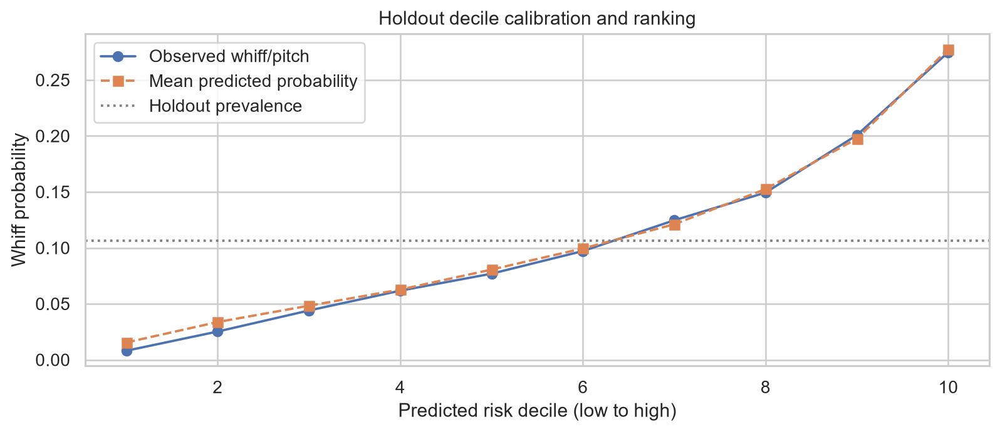

In [114]:
if 'hold_p' in globals() and len(hold_p)==len(hold):
    decile=pd.DataFrame({'y':np.asarray(hold_y,dtype=int),'prob':np.asarray(hold_p,dtype=float)})
    decile['predicted_decile']=pd.qcut(decile.prob.rank(method='first'),10,labels=False)+1
    gains=decile.groupby('predicted_decile').agg(n=('y','size'),events=('y','sum'),rate=('y','mean'),avg_pred=('prob','mean')).reset_index()
    overall=decile.y.mean()
    gains['lift']=gains.rate / overall if overall else np.nan
    save_evidence(gains,'holdout_decile_lift')
    display(gains.round(4))
    fig,ax=plt.subplots(figsize=(9,4))
    ax.plot(gains.predicted_decile,gains.rate,'o-',label='Observed whiff/pitch')
    ax.plot(gains.predicted_decile,gains.avg_pred,'s--',label='Mean predicted probability')
    ax.axhline(overall,linestyle=':',color='grey',label='Holdout prevalence')
    ax.set(xlabel='Predicted risk decile (low to high)',ylabel='Whiff probability',title='Holdout decile calibration and ranking')
    ax.legend();fig.tight_layout();publish(fig,'v2_holdout_decile_lift')


## 20.3 | Game-cluster bootstrap: difference from a prevalence baseline

Because pitches within a game are correlated, resample whole games rather than individual pitches. This interval quantifies repeated-sampling uncertainty **conditional on the trained model**; it does not account for training-set or season-to-season uncertainty.

,metric,observed,lower_95,upper_95,games
0,Brier improvement relative to train prevalence,0.00634,0.00577,0.00697,190


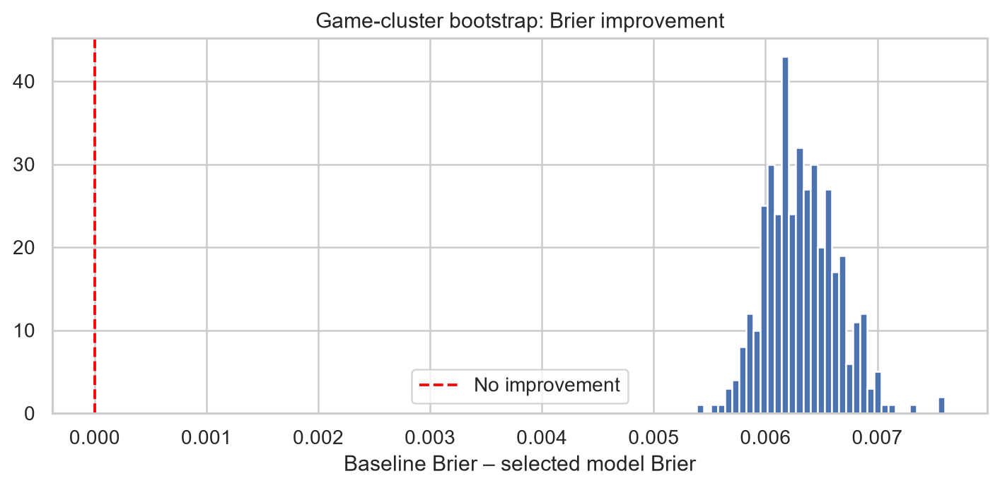

In [115]:
if 'hold_p' in globals() and len(hold_p)==len(hold):
    block=pd.DataFrame({'game':hold.game_pk.to_numpy(),'y':np.asarray(hold_y,dtype=float),'pred':np.asarray(hold_p,dtype=float)})
    train_rate=float(train_all.whiff_ind.mean())
    block['gain']=(block.y-train_rate)**2 - (block.y-block.pred)**2
    accum=block.groupby('game').gain.agg(total='sum',n='size')
    rng=np.random.default_rng(42)
    ids=np.arange(len(accum)); sampled=rng.integers(0,len(accum),size=(400,len(accum)))
    totals=accum.total.to_numpy()[sampled].sum(axis=1)
    denominators=accum.n.to_numpy()[sampled].sum(axis=1)
    boot_gain=totals/denominators
    interval=np.quantile(boot_gain,[.025,.975])
    gain_summary=save_evidence(pd.DataFrame([{'metric':'Brier improvement relative to train prevalence','observed':block.gain.mean(),
                                              'lower_95':interval[0],'upper_95':interval[1], 'games':len(accum)}]), 'game_bootstrap_brier_gain')
    display(gain_summary.round(5))
    fig,ax=plt.subplots(figsize=(8,4))
    ax.hist(boot_gain,bins=35)
    ax.axvline(0,color='red',linestyle='--',label='No improvement')
    ax.set(title='Game-cluster bootstrap: Brier improvement',xlabel='Baseline Brier – selected model Brier')
    ax.legend();fig.tight_layout();publish(fig,'v2_brier_improvement_bootstrap')


# 21 | Research Synthesis: Audit-Ready Conclusions

Numerical claims below are generated from the current execution where the needed intermediate results exist. Interpret predictions as observational and limited to May observation windows unless the study has been rerun with full-season data. Blank categories signal insufficient information, not zero effect.

In [116]:
conclusion_rows=[
    {'question':'Data coverage','evidence':f"{len(df):,} pitches and {df.game_pk.nunique():,} games across two observation windows",'caution':'Both years may contain only May 1–14'},
    {'question':'Contact quality','evidence':f"{len(batted):,} tracked in-play BBE; {batted.hard_hit.mean()*100:.1f}% hard-hit among measured BBE" if len(batted) else 'No tracked BBE', 'caution':'Conditional on observed BBE and tracked EV'},
    {'question':'Whiff prediction','evidence':f"{selected_name}: 2025 Brier {float(hold_metrics.iloc[0].Brier):.4f}, PR-AUC {float(hold_metrics.iloc[0].PR_AUC):.4f}", 'caution':'One calendar holdout; predictors include post-release measurements'},
]
if 'fold_results' in globals() and not fold_results.empty:
    agg=fold_results.groupby('model').Brier.agg(['mean','std'])
    for name, vals in agg.iterrows():
        conclusion_rows.append({'question':'2024 temporal stability', 'evidence':f"{name}: mean fold Brier {vals['mean']:.4f}", 'caution':'Three overlapping expanding-window learning samples'})
if 'ev_holdout' in globals():
    conclusion_rows.append({'question':'Exit velocity prediction','evidence':f"{ev_holdout.iloc[0]['model']}: 2025 RMSE {ev_holdout.iloc[0]['RMSE']:.2f} mph",'caution':'Only tracked in-play BBE; prediction conditioned on contact'})
research_conclusions=save_evidence(pd.DataFrame(conclusion_rows),'research_synthesis')
display(research_conclusions)
print('Research figures added:', len(list(FIGDIR.glob('v2_*.png'))))
print('Research tables:', len(list(EVIDENCE_DIR.glob('*.csv'))))


,question,evidence,caution
0,Data coverage,"109,346 pitches and 376 games across two obser...",Both years may contain only May 1–14
1,Contact quality,"19,288 tracked in-play BBE; 40.6% hard-hit amo...",Conditional on observed BBE and tracked EV
2,Whiff prediction,"HistGradientBoosting: 2025 Brier 0.0887, PR-AU...",One calendar holdout; predictors include post-...
3,2024 temporal stability,HistGradientBoosting: mean fold Brier 0.0916,Three overlapping expanding-window learning sa...
4,2024 temporal stability,Logistic: mean fold Brier 0.0951,Three overlapping expanding-window learning sa...
5,Exit velocity prediction,HistGradientBoostingRegressor: 2025 RMSE 13.66...,Only tracked in-play BBE; prediction condition...


Research figures added: 11
Research tables: 15


## 22 | Interpretation, Limitations & Deliverables
**Findings must be written from actual executed tables.** The following cell produces an evidence summary without inventing player rankings or causal claims.

In [117]:
print('STUDY SCOPE:', coverage.to_string())
print('\nSELECTED MODEL:', selected_name)
print('\nVALIDATION:', validation.round(4).to_string(index=False))
print('\nHOLDOUT:', hold_metrics.round(4).to_string(index=False))
print('\nKEY LIMITATIONS: observational data, pitch selection bias, repeated measures, two-week sample if SAMPLE_MODE, post-release predictors, different tracking coverage.')
print('\nPNG figures:', len(list(FIGDIR.glob('*.png'))), 'base figures and', len(list((ROOT/'outputs'/'comprehensive_research').glob('*.png'))), 'research figures')


STUDY SCOPE:         pitches  games  pitchers  batters first_date  last_date
season                                                         
2024      54000    186       451      433 2024-05-01 2024-05-14
2025      55346    190       457      433 2025-05-01 2025-05-14

SELECTED MODEL: HistGradientBoosting

VALIDATION:                model  ROC_AUC  PR_AUC  Brier  LogLoss
HistGradientBoosting   0.7275  0.2175 0.0911   0.3116
        RandomForest   0.7118  0.2187 0.0915   0.3171
    GradientBoosting   0.6869  0.2007 0.0930   0.3248
          ExtraTrees   0.6753  0.1899 0.0936   0.3271
            Logistic   0.6239  0.1530 0.0951   0.3343
         SGDLogistic   0.6196  0.1538 0.0952   0.3348
          Prevalence   0.5000  0.1086 0.0968   0.3435

HOLDOUT:                         model  ROC_AUC  PR_AUC  Brier  LogLoss
Selected HistGradientBoosting   0.7329  0.2269 0.0887   0.3053
    Train prevalence baseline   0.5000  0.1063 0.0950   0.3388

KEY LIMITATIONS: observational data, pitch selec

### Reporting questions and scientific limitations

**RQ1: Pitch design.** Report well-supported pitch families, their Whiff rates per swing, uncertainty, and within-pitcher confounding.

**RQ2: Hitter behavior.** Keep chase, contact, whiff and hard-hit populations separate; avoid definitive player weaknesses when counts are low.

**RQ3: Sequencing.** Treat pitch transitions as observational associations, not intervention effects.

**RQ4: Predictive validity.** Compare 2024 chronological validation with the previously inspected 2025 retrospective evaluation; report ROC-AUC, PR-AUC, Brier and calibration against the prevalence baseline. Do not claim that 2025/2026 remain untouched tests.

**Study boundary.** Results are limited to the sampled dates and measured variables; no causal coaching effects are established.


## Appendix | R statistical analysis integration
The R script provided in the ZIP reads the exported pitch-level data and can fit a mixed-effects logistic regression and generate ggplot charts. It runs separately from the Python notebook and is optional.

In [118]:
rdir=ROOT/'outputs'/'r_analysis';rdir.mkdir(parents=True,exist_ok=True)
fields=[x for x in ['game_date','season','game_pk','pitcher','batter','pitch_type','stand','p_throws','release_speed','release_spin_rate','plate_x','plate_z','balls','strikes','swing','whiff','launch_speed','launch_angle','delta_run_exp'] if x in df]
df[fields].to_csv(rdir/'statcast_r_input.csv',index=False)
print('R input:',rdir/'statcast_r_input.csv')

R input: I:\Potforlio\MLB Analytics\outputs\r_analysis\statcast_r_input.csv


## 23 | Multi-Stage Hitter Decision Models
**RQ23:** Does decomposing a whiff into the probability of swinging and the conditional probability of missing improve prediction? All model development uses a chronological **2024 training/validation split**. 2025 results are an *exploratory replication*, not a fresh locked test after the earlier analyses.

In [119]:
from sklearn.base import clone
from sklearn.metrics import brier_score_loss, average_precision_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from statsmodels.stats.proportion import proportion_confint
from scipy.special import expit
from collections import OrderedDict
V3_DIR = ROOT / 'outputs' / 'research_v3'
V3_DIR.mkdir(parents=True, exist_ok=True)
def v3_store(frame, filename):
    frame.to_csv(V3_DIR / f'{filename}.csv', index=False)
    display(frame.round(4))
    return frame
def v3_binary_scores(y, p, tag):
    y=np.asarray(y,dtype=int);p=np.clip(np.asarray(p,dtype=float),1e-7,1-1e-7)
    return dict(model=tag, n=len(y), event_rate=y.mean(), brier=brier_score_loss(y,p),
                pr_auc=average_precision_score(y,p),
                roc_auc=roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan)
def v3_lr():
    return Pipeline([('preprocess',make_preprocess()),
                     ('model',LogisticRegression(max_iter=850,C=.5))])
print('V3 outputs:',V3_DIR)

V3 outputs: I:\Potforlio\MLB Analytics\outputs\research_v3


,model,n,event_rate,brier,pr_auc,roc_auc
1,Direct logistic whiff,17190,0.1086,0.0951,0.1530,0.6240
0,Two-stage: swing × miss|swing,17190,0.1086,0.0957,0.1503,0.6176
2,2024 train prevalence,17190,0.1086,0.0968,0.1086,0.5000


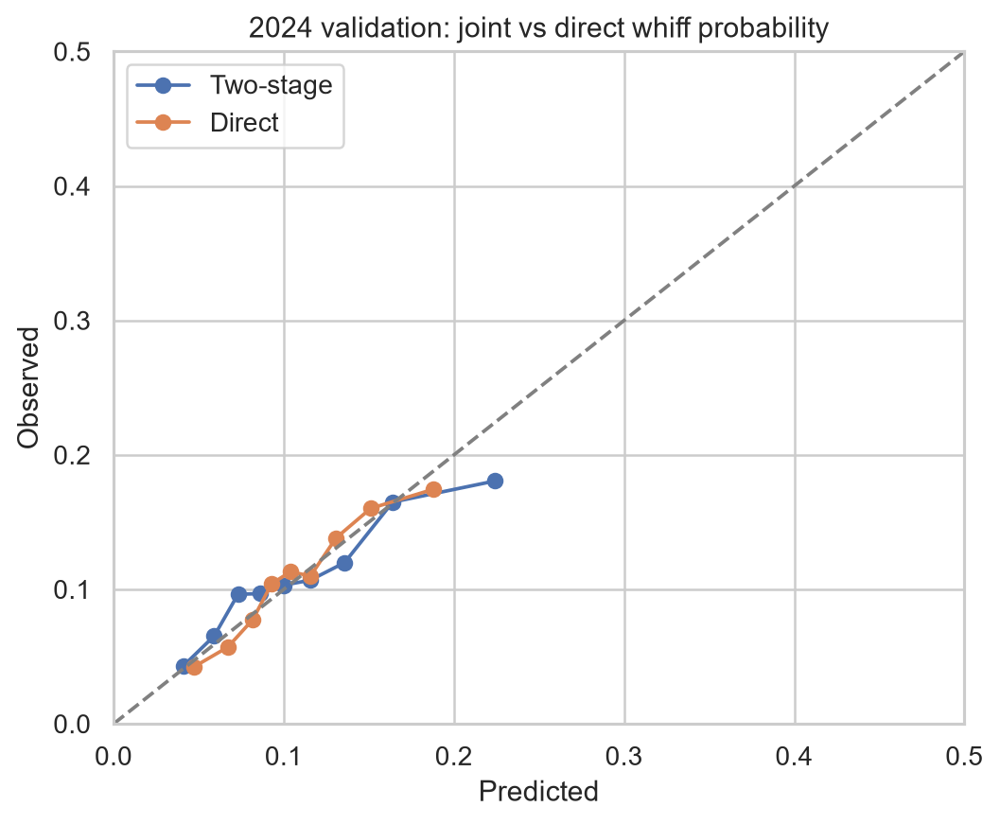

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/v3_23_2024_two_stage_calibration.png')

In [120]:
v3_sw_model=v3_lr().fit(tr[feature_cols],tr.swing_ind.astype(int))
v3_co_train=tr.loc[tr.swing_ind.eq(1)]
v3_co_model=v3_lr().fit(v3_co_train[feature_cols],v3_co_train.whiff_ind.astype(int))
v3_direct=v3_lr().fit(tr[feature_cols],tr.whiff_ind.astype(int))
v3_val_swing=v3_sw_model.predict_proba(va[feature_cols])[:,1]
v3_val_cond=v3_co_model.predict_proba(va[feature_cols])[:,1]
v3_val_joint=v3_val_swing*v3_val_cond
v3_val_direct=v3_direct.predict_proba(va[feature_cols])[:,1]
v3_two_stage=v3_store(pd.DataFrame([
    v3_binary_scores(va.whiff_ind,v3_val_joint,'Two-stage: swing × miss|swing'),
    v3_binary_scores(va.whiff_ind,v3_val_direct,'Direct logistic whiff'),
    v3_binary_scores(va.whiff_ind,np.full(len(va),tr.whiff_ind.mean()),'2024 train prevalence')
]).sort_values('brier'),'two_stage_2024_validation')
fig,ax=plt.subplots(figsize=(6,5))
for label,p in [('Two-stage',v3_val_joint),('Direct',v3_val_direct)]:
    true,mean=calibration_curve(va.whiff_ind,p,n_bins=9,strategy='quantile')
    ax.plot(mean,true,'o-',label=label)
ax.plot([0,.5],[0,.5],'--',color='gray');ax.set(xlim=(0,.5),ylim=(0,.5),
    title='2024 validation: joint vs direct whiff probability',xlabel='Predicted',ylabel='Observed')
ax.legend();fig.tight_layout();publish(fig,'v3_23_2024_two_stage_calibration')

In [121]:
v3_sw_full=v3_lr().fit(train_all[feature_cols],train_all.swing_ind.astype(int))
v3_cond_full=v3_lr().fit(train_all.loc[train_all.swing_ind.eq(1),feature_cols],
                        train_all.loc[train_all.swing_ind.eq(1),'whiff_ind'].astype(int))
v3_direct_full=v3_lr().fit(train_all[feature_cols],train_all.whiff_ind.astype(int))
v3_h_swing=v3_sw_full.predict_proba(hold[feature_cols])[:,1]
v3_h_cond=v3_cond_full.predict_proba(hold[feature_cols])[:,1]
v3_h_joint=v3_h_swing*v3_h_cond
v3_h_direct=v3_direct_full.predict_proba(hold[feature_cols])[:,1]
v3_store(pd.DataFrame([
    v3_binary_scores(hold.whiff_ind,v3_h_joint,'Two-stage 2025 exploratory'),
    v3_binary_scores(hold.whiff_ind,v3_h_direct,'Direct logistic 2025 exploratory'),
    v3_binary_scores(hold.whiff_ind,hold_p,'Previously selected HGB 2025')
]),'two_stage_2025_replication')
assert (df.whiff_ind <= df.swing_ind).all()

,model,n,event_rate,brier,pr_auc,roc_auc
0,Two-stage 2025 exploratory,55346,0.1063,0.0938,0.1520,0.6186
1,Direct logistic 2025 exploratory,55346,0.1063,0.0934,0.1524,0.6227
2,Previously selected HGB 2025,55346,0.1063,0.0887,0.2269,0.7329


### 23.1 | Contact damage per pitch is a separate population
**RQ23.1:** Separate the frequency of *tracked balls in play* from their conditional Hard-Hit rate. An observed Hard-Hit on a tracked BBE is not interchangeable with Hard-Hit probability per pitch. The second model targets **recorded hard-hit BBE per pitch**, not all unobserved contact quality.

,stage,n,events,rate
0,Tracked in-play contact / pitch,109346,19288,0.1764
1,Hard-hit / tracked in-play contact,19288,7837,0.4063
2,Tracked hard-hit / pitch,109346,7837,0.0717


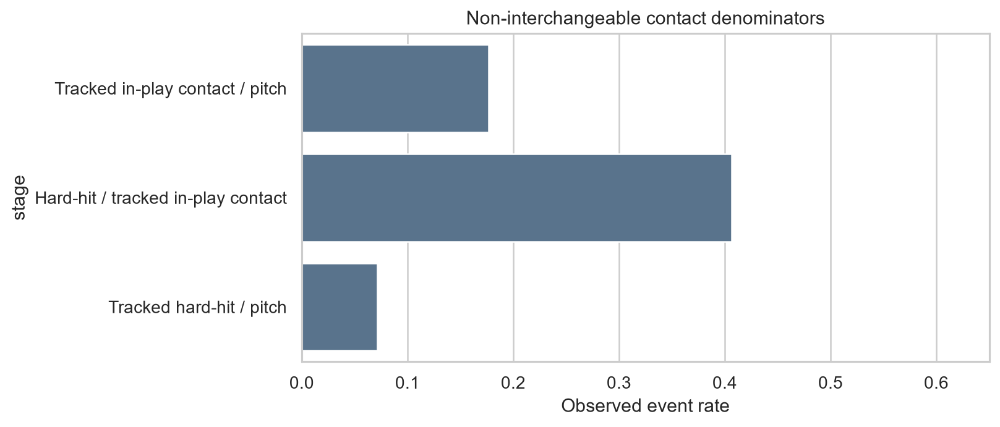

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/v3_23_contact_denominators.png')

In [122]:
v3_label_tracked = (df.type.eq('X') & df.launch_speed.notna())
v3_label_hit = (v3_label_tracked & df.launch_speed.ge(95))
v3_track_rate=float(v3_label_tracked.mean())
v3_hit_given_tracked=float(v3_label_hit.sum()/max(v3_label_tracked.sum(),1))
v3_audit=pd.DataFrame([
    {'stage':'Tracked in-play contact / pitch','n':len(df),'events':int(v3_label_tracked.sum()),'rate':v3_track_rate},
    {'stage':'Hard-hit / tracked in-play contact','n':int(v3_label_tracked.sum()),'events':int(v3_label_hit.sum()),'rate':v3_hit_given_tracked},
    {'stage':'Tracked hard-hit / pitch','n':len(df),'events':int(v3_label_hit.sum()),'rate':float(v3_label_hit.mean())},
])
v3_store(v3_audit,'contact_selection_denominator_chain')
fig,ax=plt.subplots(figsize=(9,4))
sns.barplot(data=v3_audit,x='rate',y='stage',color='#507395',ax=ax)
ax.set(xlabel='Observed event rate',title='Non-interchangeable contact denominators',xlim=(0,.65))
fig.tight_layout();publish(fig,'v3_23_contact_denominators')

In [123]:
v3_mtr=tr.copy();v3_mva=va.copy()
for frame in [v3_mtr,v3_mva]:
    frame['tracked_bbe']=(frame.type.eq('X') & frame.launch_speed.notna()).astype(int)
    frame['measured_hardhit']=(frame.tracked_bbe.eq(1)&frame.launch_speed.ge(95)).astype(int)
v3_t_model=v3_lr().fit(v3_mtr[feature_cols],v3_mtr.tracked_bbe)
v3_d_model=v3_lr().fit(v3_mtr.loc[v3_mtr.tracked_bbe.eq(1),feature_cols],
                         v3_mtr.loc[v3_mtr.tracked_bbe.eq(1),'measured_hardhit'])
v3_f_model=v3_lr().fit(v3_mtr[feature_cols],v3_mtr.measured_hardhit)
v3_product=(v3_t_model.predict_proba(v3_mva[feature_cols])[:,1]*
            v3_d_model.predict_proba(v3_mva[feature_cols])[:,1])
v3_direct_contact=v3_f_model.predict_proba(v3_mva[feature_cols])[:,1]
v3_store(pd.DataFrame([
    v3_binary_scores(v3_mva.measured_hardhit,v3_product,'Two-stage observed hard-hit'),
    v3_binary_scores(v3_mva.measured_hardhit,v3_direct_contact,'Direct observed hard-hit'),
    v3_binary_scores(v3_mva.measured_hardhit,np.full(len(v3_mva),v3_mtr.measured_hardhit.mean()),'Prevalence')
]),'measured_hardhit_2024_validation')

,model,n,event_rate,brier,pr_auc,roc_auc
0,Two-stage observed hard-hit,17190,0.0683,0.0631,0.0939,0.6104
1,Direct observed hard-hit,17190,0.0683,0.0631,0.0946,0.6119
2,Prevalence,17190,0.0683,0.0636,0.0683,0.5000


,model,n,event_rate,brier,pr_auc,roc_auc
0,Two-stage observed hard-hit,17190,0.068296,0.063090,0.093948,0.610411
1,Direct observed hard-hit,17190,0.068296,0.063081,0.094608,0.611945
2,Prevalence,17190,0.068296,0.063631,0.068296,0.500000


## 24 | Player Identity and Matchup Generalization
**RQ24:** Does knowing which batter and pitcher are involved improve measured Whiff prediction beyond physical pitch features? This is an **identity-ablation experiment**, not an estimate of causal player skill. Unseen identities are explicitly checked.

In [124]:
v3_base_cols=['pitch_type','stand','p_throws','balls','strikes','release_speed','release_spin_rate','pfx_x','pfx_z','plate_x','plate_z']
v3_base_cols=[x for x in v3_base_cols if x in df.columns]
v3_cat_base=[x for x in ['pitch_type','stand','p_throws'] if x in v3_base_cols]
v3_num_base=[x for x in v3_base_cols if x not in v3_cat_base]
v3_id_cols=['pitcher','batter']
def v3_identity_pipe(identities=False):
    categories=v3_cat_base+(v3_id_cols if identities else [])
    prep=ColumnTransformer([
        ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),
                         ('ohe',OneHotEncoder(handle_unknown='ignore'))]),categories),
        ('num',Pipeline([('imp',SimpleImputer(strategy='median')),
                         ('scale',StandardScaler())]),v3_num_base)
    ])
    return Pipeline([('prep',prep),('model',LogisticRegression(max_iter=700,C=.35))])
for block in [tr,va,train_all,hold]:
    for col in v3_id_cols:
        block[col]=block[col].astype('string').fillna('Unknown').astype(str)
v3_id_train=tr[v3_base_cols+v3_id_cols]
v3_id_val=va[v3_base_cols+v3_id_cols]
v3_identity_valid=[]
for use_ids in [False,True]:
    model=v3_identity_pipe(use_ids)
    model.fit(v3_id_train,tr.whiff_ind.astype(int))
    p=model.predict_proba(v3_id_val)[:,1]
    v3_identity_valid.append(v3_binary_scores(va.whiff_ind,p,'With IDs' if use_ids else 'Without IDs'))
v3_store(pd.DataFrame(v3_identity_valid).sort_values('brier'),'player_identity_2024_ablation')

,model,n,event_rate,brier,pr_auc,roc_auc
0,Without IDs,17190,0.1086,0.0951,0.1530,0.6240
1,With IDs,17190,0.1086,0.0956,0.1557,0.6251


,model,n,event_rate,brier,pr_auc,roc_auc
0,Without IDs,17190,0.108551,0.095101,0.153016,0.624037
1,With IDs,17190,0.108551,0.095594,0.155675,0.625095


In [125]:
v3_identity_test=[]
for use_ids in [False,True]:
    model=v3_identity_pipe(use_ids).fit(train_all[v3_base_cols+v3_id_cols],train_all.whiff_ind.astype(int))
    p=model.predict_proba(hold[v3_base_cols+v3_id_cols])[:,1]
    v3_identity_test.append(v3_binary_scores(hold.whiff_ind,p,'With IDs' if use_ids else 'Without IDs'))
    if use_ids: v3_ids_p=p
    else: v3_noids_p=p
v3_store(pd.DataFrame(v3_identity_test),'player_identity_2025_replication')
v3_horizon=hold[['pitcher','batter','game_pk']].copy()
for fld in ['pitcher','batter']:
    seen=v3_horizon[fld].isin(set(train_all[fld].astype(str)))
    rows=[]
    for flag in [True,False]:
        mask=np.asarray(seen.eq(flag))
        if mask.sum()>=100:
            rows.append({'field':fld,'observed_in_2024':flag,'n':int(mask.sum()),
                'Brier_no_ids':brier_score_loss(hold.whiff_ind.to_numpy()[mask],v3_noids_p[mask]),
                'Brier_ids':brier_score_loss(hold.whiff_ind.to_numpy()[mask],v3_ids_p[mask])})
    v3_store(pd.DataFrame(rows),f'identity_seen_unseen_{fld}')

,model,n,event_rate,brier,pr_auc,roc_auc
0,Without IDs,55346,0.1063,0.0934,0.1525,0.6228
1,With IDs,55346,0.1063,0.0937,0.1531,0.6191


,field,observed_in_2024,n,Brier_no_ids,Brier_ids
0,pitcher,True,35064,0.0949,0.0952
1,pitcher,False,20282,0.0908,0.0912


,field,observed_in_2024,n,Brier_no_ids,Brier_ids
0,batter,True,42119,0.0911,0.0914
1,batter,False,13227,0.1008,0.1010


### 24.1 | Context-adjusted observed-versus-expected whiffs
**RQ24.1:** Which observed 2025 hitters/pitchers diverged most from predicted whiff likelihood? Empirical-Bayes-style shrinkage reduces small-sample volatility. These residuals still reflect unmeasured contexts, not isolated player ability.

,pitcher,n,observed,expected,obs_minus_exp_pctpt,shrunk_pp
398,686752,275,18,34.2772,-5.9190,-3.4268
185,657240,111,3,13.3775,-9.3491,-3.3368
136,641816,266,24,37.3192,-5.0072,-2.8582
53,592791,272,19,32.2244,-4.8619,-2.8018
385,684007,84,8,15.7845,-9.2673,-2.7410
413,689147,97,5,12.9373,-8.1828,-2.6725
271,669358,262,19,31.0157,-4.5861,-2.6008
453,806188,98,2,9.7299,-7.8876,-2.5939
286,670102,168,12,21.3271,-5.5518,-2.5345
35,571760,182,9,18.4195,-5.1756,-2.4659


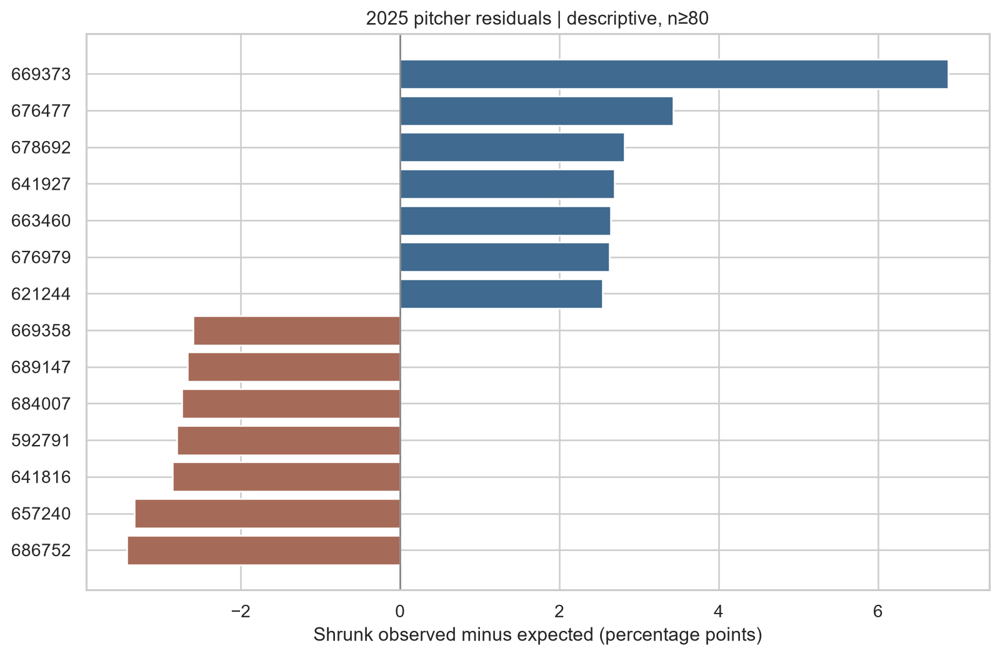

,batter,n,observed,expected,obs_minus_exp_pctpt,shrunk_pp
253,669364,216,4,23.7897,-9.1619,-4.7571
133,650333,212,2,20.9577,-8.9423,-4.6014
269,670623,216,6,23.8804,-8.2779,-4.2982
15,527038,195,8,23.4672,-7.9319,-3.9157
383,687401,133,4,16.6033,-9.4761,-3.7848
329,680757,245,9,24.5717,-6.3558,-3.4993
286,672695,219,9,23.3110,-6.5347,-3.4155
285,672580,238,13,27.8599,-6.2437,-3.3927
335,681082,247,12,26.9146,-6.0383,-3.3366
134,650402,204,11,23.9383,-6.3423,-3.2026


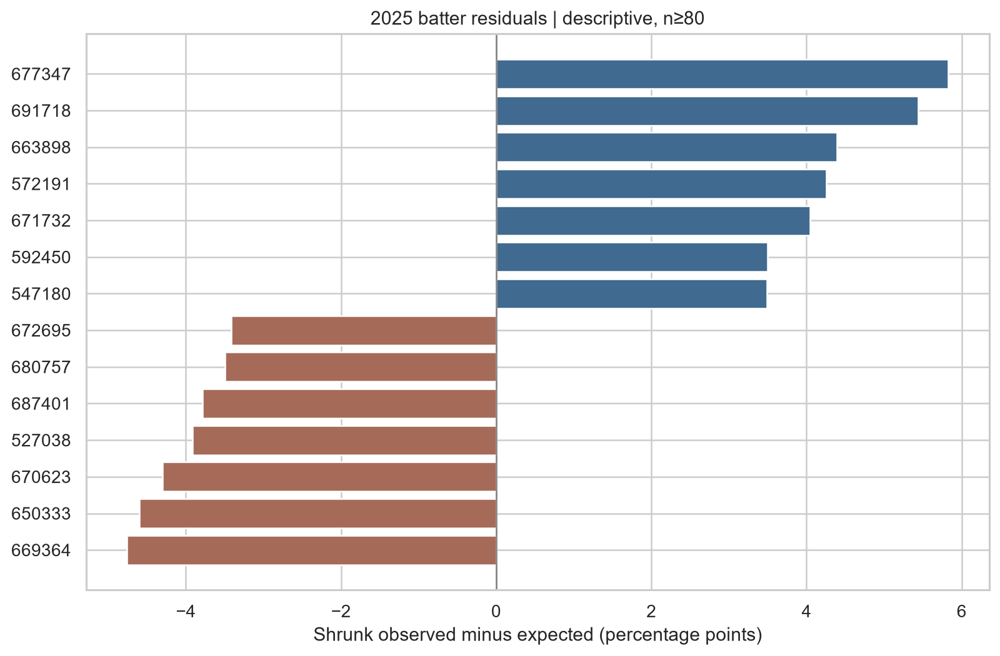

In [126]:
v3_res=hold[['batter','pitcher','game_pk']].copy()
v3_res['observed']=np.asarray(hold_y,dtype=int)
v3_res['expected']=np.asarray(hold_p,dtype=float)
for player in ['pitcher','batter']:
    x=v3_res.groupby(player).agg(n=('observed','size'),observed=('observed','sum'),expected=('expected','sum')).reset_index()
    x=x.query('n>=80').copy()
    if x.empty:continue
    x['obs_minus_exp_pctpt']=100*(x.observed-x.expected)/x.n
    x['shrunk_pp']=x.obs_minus_exp_pctpt*x.n/(x.n+200)
    x=x.sort_values('shrunk_pp')
    v3_store(pd.concat([x.head(12),x.tail(12)]),f'{player}_expected_whiff_residuals')
    fig,ax=plt.subplots(figsize=(9,6))
    view=pd.concat([x.head(7),x.tail(7)])
    ax.barh(view[player].astype(str),view.shrunk_pp,color=np.where(view.shrunk_pp>0,'#406a8f','#a66b58'))
    ax.axvline(0,color='gray',lw=1);ax.set(xlabel='Shrunk observed minus expected (percentage points)',
        title=f'2025 {player} residuals | descriptive, n≥80')
    fig.tight_layout();publish(fig,f'v3_24_{player}_residuals')

## 25 | Pitch Location Normalization and Batter Composition
**RQ25:** Do absolute pitch coordinates hide important differences in hitter-specific strike-zone height? Are hitter Whiff rates partly driven by the pitch families they face?

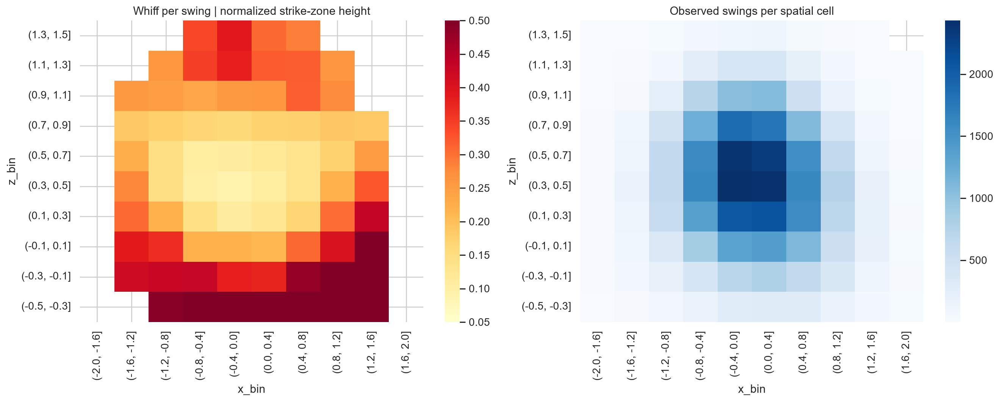

,z_bin,x_bin,n,k,rate_shrunk
0,"(-0.5, -0.3]","(-2.0, -1.6]",6,6,0.2615
1,"(-0.5, -0.3]","(-1.6, -1.2]",34,31,0.3934
2,"(-0.5, -0.3]","(-1.2, -0.8]",80,67,0.4929
3,"(-0.5, -0.3]","(-0.8, -0.4]",165,115,0.5159
4,"(-0.5, -0.3]","(-0.4, 0.0]",284,181,0.5279
...,...,...,...,...,...
94,"(1.3, 1.5]","(-0.4, 0.0]",88,52,0.3921
95,"(1.3, 1.5]","(0.0, 0.4]",111,43,0.3067
96,"(1.3, 1.5]","(0.4, 0.8]",45,20,0.2877
97,"(1.3, 1.5]","(0.8, 1.2]",13,5,0.2364


In [127]:
needed=['plate_x','plate_z','sz_top','sz_bot','stand','pitch_type']
if all(v in df.columns for v in needed):
    v3_geo=df[needed+['swing_ind','whiff_ind']].copy()
    for v in ['plate_x','plate_z','sz_top','sz_bot']:
        v3_geo[v]=pd.to_numeric(v3_geo[v],errors='coerce')
    v3_geo=v3_geo.loc[(v3_geo.sz_top-v3_geo.sz_bot).between(.8,4)].copy()
    v3_geo['relative_z']=(v3_geo.plate_z-v3_geo.sz_bot)/(v3_geo.sz_top-v3_geo.sz_bot)
    v3_geo=v3_geo.loc[v3_geo.plate_x.between(-2,2)&v3_geo.relative_z.between(-.5,1.5)]
    v3_geo['z_bin']=pd.cut(v3_geo.relative_z,np.linspace(-.5,1.5,11))
    v3_geo['x_bin']=pd.cut(v3_geo.plate_x,np.linspace(-2,2,11))
    v3_loc=(v3_geo.loc[v3_geo.swing_ind.eq(1)]
            .groupby(['z_bin','x_bin'],observed=True)
            .whiff_ind.agg(n='size',k='sum').reset_index())
    global_p=float(v3_geo.loc[v3_geo.swing_ind.eq(1),'whiff_ind'].mean())
    v3_loc['rate_shrunk']=(v3_loc.k+100*global_p)/(v3_loc.n+100)
    matrix=v3_loc.pivot(index='z_bin',columns='x_bin',values='rate_shrunk')
    size=v3_loc.pivot(index='z_bin',columns='x_bin',values='n')
    matrix=matrix.where(size>=35)
    fig,axes=plt.subplots(1,2,figsize=(15,6))
    sns.heatmap(matrix.iloc[::-1],cmap='YlOrRd',vmin=.05,vmax=.5,ax=axes[0]);axes[0].set(title='Whiff per swing | normalized strike-zone height')
    sns.heatmap(size.iloc[::-1],cmap='Blues',ax=axes[1]);axes[1].set(title='Observed swings per spatial cell')
    fig.tight_layout();publish(fig,'v3_25_normalized_zone_whiff_and_support')
    v3_store(v3_loc,'normalized_zone_whiff_cells')
else: print('No personalized strike-zone bounds; normalized plot skipped.')

,batter,swings,raw_whiff_pct,mix_standardized_whiff_pct,difference_pp
14,543760,245,22.4490,21.0699,-1.3791
25,592206,242,24.3802,22.3373,-2.0428
79,646240,241,26.1411,25.6387,-0.5024
78,645277,231,20.7792,21.0321,0.2529
215,681624,229,23.5808,22.5560,-1.0248
198,677594,229,23.1441,23.0830,-0.0611
11,521692,224,28.5714,27.0688,-1.5027
80,647304,224,19.1964,18.6548,-0.5416
71,642715,219,21.9178,22.4143,0.4965
23,572233,219,25.1142,24.4329,-0.6812


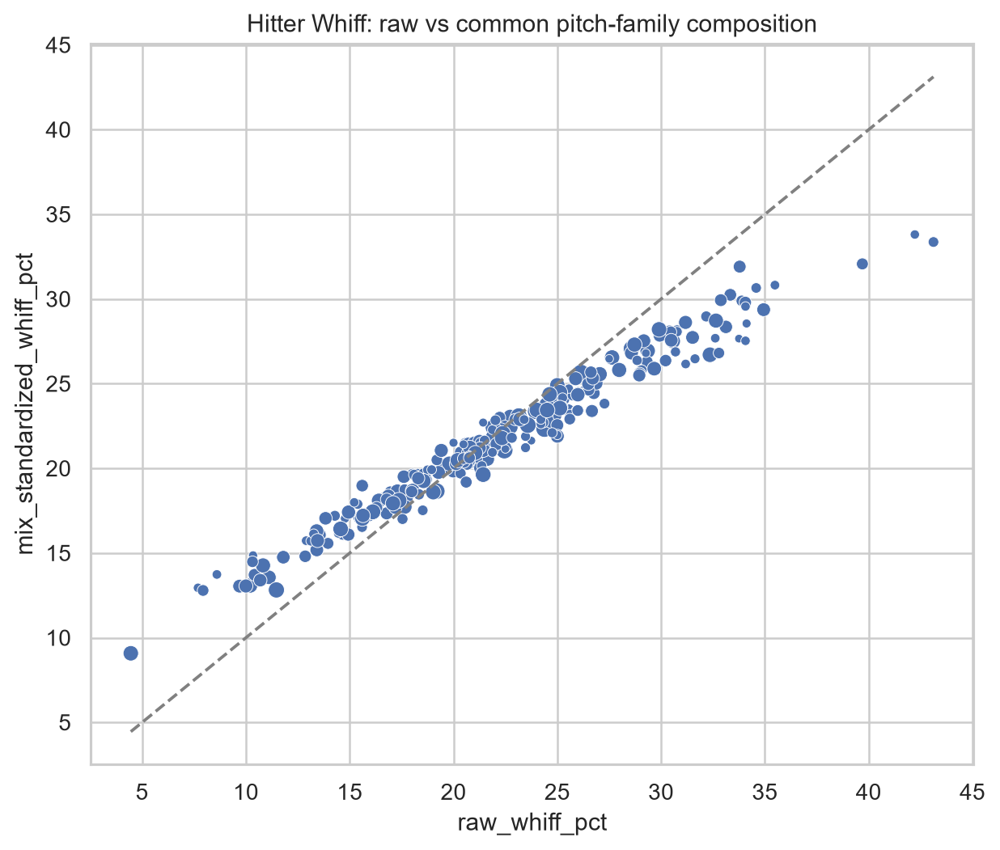

In [128]:
fast={'FF','SI','FC','FA'};breaking={'SL','ST','SV','CU','KC','CS'}
v3_swing=df.loc[df.swing_ind.eq(1),['batter','pitch_type','whiff_ind']].copy()
v3_swing['family']=np.select([v3_swing.pitch_type.isin(fast),v3_swing.pitch_type.isin(breaking)],
                              ['Fastball','Breaking'],default='Other')
reference=v3_swing.family.value_counts(normalize=True).reindex(['Fastball','Breaking','Other']).fillna(0)
grouped=v3_swing.groupby(['batter','family']).whiff_ind.agg(n='size',whiffs='sum').reset_index()
all_h=[]
for batter_id,g in grouped.groupby('batter'):
    g=g.set_index('family').reindex(reference.index)
    if g.n.notna().all() and (g.n>=10).all() and g.n.sum()>=80:
        raw_rate=g.whiffs.sum()/g.n.sum()
        smoothed=(g.whiffs+20*(v3_swing.whiff_ind.mean()))/(g.n+20)
        standardized=float((smoothed*reference).sum())
        all_h.append({'batter':batter_id,'swings':int(g.n.sum()),
                      'raw_whiff_pct':100*raw_rate,'mix_standardized_whiff_pct':100*standardized,
                      'difference_pp':100*(standardized-raw_rate)})
hitter_std=pd.DataFrame(all_h)
if not hitter_std.empty:
    v3_store(hitter_std.sort_values('swings',ascending=False).head(30),'hitter_pitch_family_standardization')
    fig,ax=plt.subplots(figsize=(7,6));sns.scatterplot(data=hitter_std,x='raw_whiff_pct',y='mix_standardized_whiff_pct',size='swings',legend=False,ax=ax)
    lo=min(hitter_std.raw_whiff_pct.min(),hitter_std.mix_standardized_whiff_pct.min())
    hi=max(hitter_std.raw_whiff_pct.max(),hitter_std.mix_standardized_whiff_pct.max())
    ax.plot([lo,hi],[lo,hi],'--',color='gray');ax.set(title='Hitter Whiff: raw vs common pitch-family composition')
    fig.tight_layout();publish(fig,'v3_25_hitter_standardization')
else: print('Insufficient three-family overlap among batters; no comparable standardized estimates.')

## 26 | Within-Plate-Appearance Dynamics and Context
**RQ26:** Does knowing the **previous pitch** improve the next-pitch Whiff model beyond the current pitch features? This is a matched population of *non-first pitches*, with explicitly lagged information.

In [129]:
v3_seq=df.sort_values(['game_pk','at_bat_number','pitch_number']).copy()
v3_pa=v3_seq.groupby(['game_pk','at_bat_number'],sort=False)
v3_seq['previous_type']=v3_pa.pitch_type.shift(1)
v3_seq['previous_velocity']=v3_pa.release_speed.shift(1)
v3_seq['repeat_type']=(v3_seq.pitch_type==v3_seq.previous_type).astype(int)
v3_seq['velocity_change']=v3_seq.release_speed-v3_seq.previous_velocity
v3_seq=v3_seq.loc[v3_seq.previous_type.notna()].copy()
v3_seq['previous_type']=v3_seq.previous_type.fillna('UNKNOWN').astype(str)
v3_seq['velocity_change']=pd.to_numeric(v3_seq.velocity_change,errors='coerce')
v3_st=v3_seq.loc[v3_seq.season.eq(2024)].copy()
v3_sv=v3_seq.loc[v3_seq.season.eq(2025)].copy()
v3_dts=v3_st.game_date.drop_duplicates().sort_values()
v3_cut=v3_dts.iloc[max(0,int(len(v3_dts)*.75)-1)]
v3_st0=v3_st.loc[v3_st.game_date.le(v3_cut)]
v3_st1=v3_st.loc[v3_st.game_date.gt(v3_cut)]
v3_lags=['previous_type','previous_velocity','repeat_type','velocity_change']
def v3_sequence_pipeline(with_lags=False):
    feat=feature_cols+(v3_lags if with_lags else [])
    cats=[x for x in ['pitch_type','stand','p_throws','previous_type'] if x in feat]
    nums=[x for x in feat if x not in cats]
    prep=ColumnTransformer([
        ('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),
                         ('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cats),
        ('num',Pipeline([('imp',SimpleImputer(strategy='median')),
                         ('scale',StandardScaler())]),nums)
    ],sparse_threshold=0)
    est=HistGradientBoostingClassifier(max_iter=90,max_leaf_nodes=18,min_samples_leaf=50,random_state=42)
    return Pipeline([('prep',prep),('model',est)]),feat
v3_sresults=[]
for lag in [False,True]:
    m,feat=v3_sequence_pipeline(lag)
    m.fit(v3_st0[feat],v3_st0.whiff_ind.astype(int))
    pred=m.predict_proba(v3_st1[feat])[:,1]
    v3_sresults.append(v3_binary_scores(v3_st1.whiff_ind,pred,'With previous pitch' if lag else 'Current pitch only'))
v3_store(pd.DataFrame(v3_sresults),'sequence_ablation_2024_validation')

,model,n,event_rate,brier,pr_auc,roc_auc
0,Current pitch only,12796,0.1174,0.0983,0.2157,0.7046
1,With previous pitch,12796,0.1174,0.0981,0.2191,0.7067


,model,n,event_rate,brier,pr_auc,roc_auc
0,Current pitch only,12796,0.11738,0.098259,0.215665,0.704627
1,With previous pitch,12796,0.11738,0.098129,0.219102,0.706749


In [130]:
v3_sresults=[]
for lag in [False,True]:
    m,feat=v3_sequence_pipeline(lag)
    m.fit(v3_st[feat],v3_st.whiff_ind.astype(int))
    pred=m.predict_proba(v3_sv[feat])[:,1]
    v3_sresults.append(v3_binary_scores(v3_sv.whiff_ind,pred,'With previous pitch' if lag else 'Current pitch only'))
v3_store(pd.DataFrame(v3_sresults),'sequence_ablation_2025_exploratory')
v3_transition=(v3_sv.groupby(['previous_type','pitch_type'])
               .agg(pitches=('whiff_ind','size'),swings=('swing_ind','sum'),whiffs=('whiff_ind','sum'))
               .reset_index())
v3_transition['whiff_given_swing']=v3_transition.whiffs/v3_transition.swings.replace(0,np.nan)
v3_store(v3_transition.loc[v3_transition.swings>=35].sort_values('pitches',ascending=False).head(40),
         'sequence_context_conditional_whiff')

,model,n,event_rate,brier,pr_auc,roc_auc
0,Current pitch only,40992,0.118,0.0974,0.2338,0.7221
1,With previous pitch,40992,0.118,0.0974,0.2358,0.7194


,previous_type,pitch_type,pitches,swings,whiffs,whiff_given_swing
54,FF,FF,5712,3012,544,0.1806
99,SI,SI,2311,1160,156,0.1345
112,SL,SL,2267,1266,445,0.3515
59,FF,SL,1936,1020,262,0.2569
107,SL,FF,1841,1017,180,0.1770
49,FF,CH,1388,716,181,0.2528
5,CH,FF,1331,734,129,0.1757
124,ST,ST,1148,575,163,0.2835
0,CH,CH,1138,642,169,0.2632
118,ST,FF,869,459,91,0.1983


,previous_type,pitch_type,pitches,swings,whiffs,whiff_given_swing
54,FF,FF,5712,3012,544,0.180611
99,SI,SI,2311,1160,156,0.134483
112,SL,SL,2267,1266,445,0.351501
59,FF,SL,1936,1020,262,0.256863
107,SL,FF,1841,1017,180,0.176991
49,FF,CH,1388,716,181,0.252793
5,CH,FF,1331,734,129,0.175749
124,ST,ST,1148,575,163,0.283478
0,CH,CH,1138,642,169,0.263240
118,ST,FF,869,459,91,0.198257


### 26.1 | Score context (optional Statcast fields)
**RQ26.1:** Does observed pitch behavior differ when the pitcher leads or trails? The pitcher is the home team in the top half of an inning and the away team in the bottom half. This is descriptive and adjusts neither opposition nor leverage.

,margin,n,swings,whiffs,whiff_per_swing
0,Down 3+,16661,7945,1695,0.2133
1,Down 1–2,21390,10296,2336,0.2269
2,Tied,31928,15114,3471,0.2297
3,Up 1–2,22054,10449,2377,0.2275
4,Up 3+,17313,8119,1873,0.2307


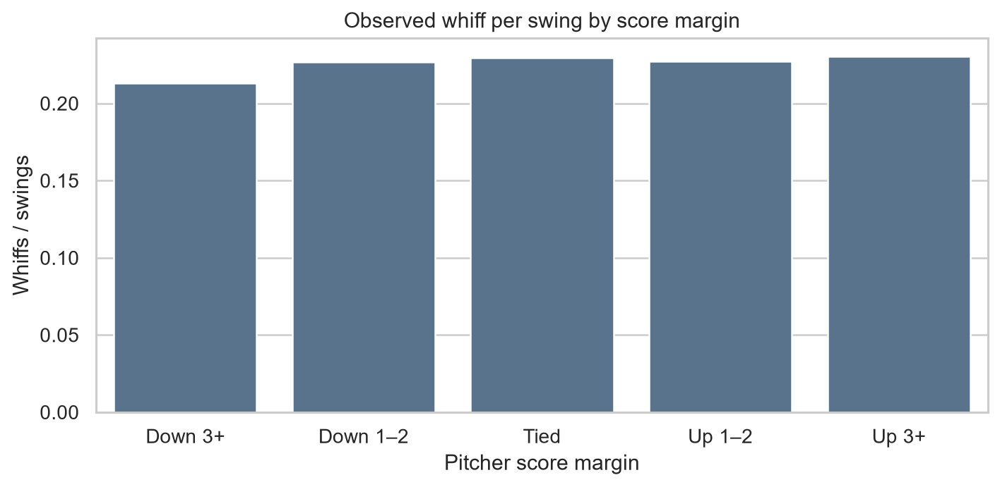

In [131]:
cols=['home_score','away_score','inning_topbot','pitch_type','swing_ind','whiff_ind','game_pk']
if all(x in df.columns for x in cols):
    v3_score=df[cols].copy()
    for col in ['home_score','away_score']:v3_score[col]=pd.to_numeric(v3_score[col],errors='coerce')
    v3_score['pitcher_lead']=np.where(v3_score.inning_topbot.eq('Top'),v3_score.home_score-v3_score.away_score,
                       v3_score.away_score-v3_score.home_score)
    v3_score['margin']=pd.cut(v3_score.pitcher_lead,[-100,-3,-1,0,2,100],labels=['Down 3+','Down 1–2','Tied','Up 1–2','Up 3+'])
    s=v3_score.groupby('margin',observed=True).agg(n=('whiff_ind','size'),swings=('swing_ind','sum'),whiffs=('whiff_ind','sum')).reset_index()
    s['whiff_per_swing']=s.whiffs/s.swings.replace(0,np.nan)
    v3_store(s,'pitcher_score_margin_observed_whiff')
    fig,ax=plt.subplots(figsize=(8,4));sns.barplot(data=s,x='margin',y='whiff_per_swing',color='#507395',ax=ax)
    ax.set(title='Observed whiff per swing by score margin',ylabel='Whiffs / swings',xlabel='Pitcher score margin')
    fig.tight_layout();publish(fig,'v3_26_score_state')
else:print('Score-state columns are not available; optional analysis skipped.')

## 27 | Model Uncertainty, Documentation and Responsible Interpretation
**RQ27:** Are headline rankings stable across games, and which results remain descriptive? A 2025 cluster-bootstrap interval is calculated for the observed **two-stage vs direct** diagnostic but is not a substitute for an untouched prospective test.

,metric,mean,lower_95,upper_95,games
0,Direct minus two-stage Brier (2025 exploratory),-0.0004,-0.0005,-0.0002,190


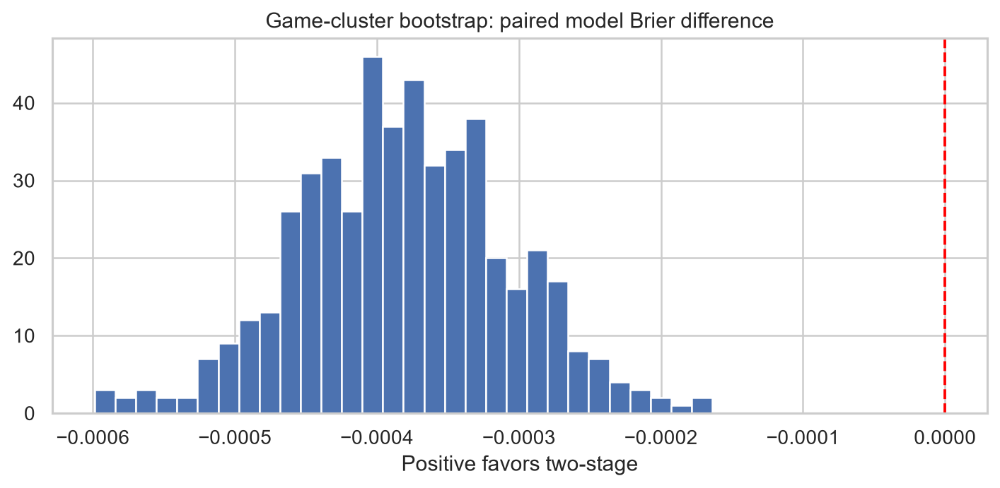

In [132]:
v3_diff=pd.DataFrame({'game':hold.game_pk.to_numpy(),'y':np.asarray(hold.whiff_ind,dtype=float),
                      'joint':np.asarray(v3_h_joint,dtype=float),'direct':np.asarray(v3_h_direct,dtype=float)})
v3_diff['gain']=(v3_diff.y-v3_diff.direct)**2-(v3_diff.y-v3_diff.joint)**2
g=v3_diff.groupby('game').gain.agg(total='sum',n='size')
if len(g)>10:
    rng=np.random.default_rng(44)
    idx=rng.integers(0,len(g),size=(500,len(g)))
    draws=g.total.to_numpy()[idx].sum(axis=1)/g.n.to_numpy()[idx].sum(axis=1)
    v3_boot=v3_store(pd.DataFrame([{'metric':'Direct minus two-stage Brier (2025 exploratory)',
                        'mean':v3_diff.gain.mean(),'lower_95':np.quantile(draws,.025),
                        'upper_95':np.quantile(draws,.975),'games':len(g)}]),'two_stage_game_cluster_uncertainty')
    fig,ax=plt.subplots(figsize=(8,4));ax.hist(draws,bins=30);ax.axvline(0,color='red',ls='--')
    ax.set(title='Game-cluster bootstrap: paired model Brier difference',xlabel='Positive favors two-stage')
    fig.tight_layout();publish(fig,'v3_27_two_stage_bootstrap')

In [133]:
import json
v3_manifest={
  'study':'MLB Pitch Intelligence | Research V3',
  'years':sorted(int(x) for x in df.season.unique()),
  'dates':{str(int(y)):[str(g.game_date.min().date()),str(g.game_date.max().date())] for y,g in df.groupby('season')},
  'sample_mode':bool(SAMPLE_MODE),'pitches':int(len(df)),
  'observed_tracked_bbe':int((df.type.eq('X') & df.launch_speed.notna()).sum()),
  'selected_base_model':str(selected_name),
  'holdout_brier':float(brier_score_loss(hold.whiff_ind,hold_p)),
  'experimental_sections':['stage-based outcomes','player ID ablation','normalized strike zone',
                           'pitch-family standardization','sequence ablation','score margin','game bootstrap'],
  'limitations':['Observational selection and repeated-game dependencies',
                 'Two May observation windows unless sample mode disabled',
                 'Post-release physical features, not a pre-pitch forecast',
                 '2025 results are exploratory after repeated model diagnostics']
}
(V3_DIR/'study_manifest.json').write_text(json.dumps(v3_manifest,indent=2),encoding='utf-8')
display(pd.DataFrame([{'item':k,'value':str(v)} for k,v in v3_manifest.items()]))
print('New V3 tables:',len(list(V3_DIR.glob('*.csv'))),'| manifest:',V3_DIR/'study_manifest.json')

,item,value
0,study,MLB Pitch Intelligence | Research V3
1,years,"[2024, 2025]"
2,dates,"{'2024': ['2024-05-01', '2024-05-14'], '2025':..."
3,sample_mode,True
4,pitches,109346
5,observed_tracked_bbe,19288
6,selected_base_model,HistGradientBoosting
7,holdout_brier,0.0886792173426099
8,experimental_sections,"['stage-based outcomes', 'player ID ablation',..."
9,limitations,['Observational selection and repeated-game de...


New V3 tables: 17 | manifest: I:\Potforlio\MLB Analytics\outputs\research_v3\study_manifest.json


### Research interpretation checklist
- **Association ≠ intervention.** Pitch movement, location, repertoire, and result are confounded by who selected the pitch, hitter characteristics, and game state.
- **Denominators differ.** Whiff/pitch, Whiff/swing, tracked BBE/pitch, and Hard-Hit/tracked BBE are distinct quantities.
- **Post-release inputs.** Physical characteristics and pitch location recorded after release make the leading Whiff model **explanatory**, not a real-time pre-release tactical recommender.
- **Player identity.** Improved discrimination from identifiers does not estimate intrinsic batter or pitcher skill without stronger hierarchical assumptions and cross-player testing.
- **Temporal evidence.** Training/validation use 2024 chronology. The already repeatedly inspected 2025 sample is an exploratory temporal replication; reserve an unseen season for future confirmatory validation.
- **Presentation.** A final report should select a few primary research questions, include uncertainty, and place exploratory models in appendices.

## Reproducibility checkpoint

Compare results only when target populations, denominators, model inputs and evaluation dates are the same. Figures and tables in the executed notebook reflect the user's saved run; the separate report provides the curated narrative.


---
# Part 28 | V4 Research Extensions: Prespecified Questions

This appendix is organized by distinct questions rather than by permutations of similar bar charts. Each rate uses the eligible event population (pitches, swings, out-of-zone pitches, or tracked balls in play) and minimum sample counts. Figures below use `publish()` to display inside the notebook and save a PNG simultaneously.

**Design restriction:** 2024 is the development period; all 2025 comparisons below are labeled exploratory because earlier project iterations already inspected them. Observational associations do not establish causal pitch-design effects.

In [134]:
from scipy.spatial.distance import jensenshannon
from scipy.stats import beta
from statsmodels.stats.proportion import proportion_confint
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.calibration import calibration_curve
from sklearn.base import clone
from sklearn.metrics import brier_score_loss, average_precision_score

V4_DIR = ROOT / 'outputs' / 'research_v4'
V4_DIR.mkdir(parents=True, exist_ok=True)

def v4_table(frame, slug, digits=3):
    frame.to_csv(V4_DIR / f'{slug}.csv', index=False)
    display(frame.round(digits))
    return frame

def v4_plot(fig, slug):
    return publish(fig, f'v4_{slug}')

print('V4 research outputs:', V4_DIR)

V4 research outputs: I:\Potforlio\MLB Analytics\outputs\research_v4


## 28.1 | Dataset eligibility and missingness by target population

**RQ:** Which observations are eligible for a Whiff, Chase or contact-quality analysis? Eligibility must be checked before comparing player or pitch populations. BBE tracking availability is **not** identical to the population of all pitches.

In [135]:
eligibility = []
for year, frame in df.groupby('season'):
    all_bbe = frame.type.eq('X')
    ev = pd.to_numeric(frame.launch_speed, errors='coerce')
    out = frame.zone_known & ~frame.in_zone
    eligibility.append({
        'season': int(year), 'all_pitches': len(frame),
        'swing_pitches': int(frame.swing_ind.sum()),
        'known_zone': int(frame.zone_known.sum()),
        'outside_zone': int(out.sum()),
        'in_play_bbe': int(all_bbe.sum()),
        'tracked_bbe': int((all_bbe & ev.notna()).sum()),
        'bbe_tracking_pct': float((all_bbe & ev.notna()).sum() / max(all_bbe.sum(), 1) * 100),
        'whiffs': int(frame.whiff_ind.sum())
    })
v4_eligibility = v4_table(pd.DataFrame(eligibility), 'target_eligibility')
assert (v4_eligibility.tracked_bbe <= v4_eligibility.in_play_bbe).all()
assert (v4_eligibility.whiffs <= v4_eligibility.swing_pitches).all()

,season,all_pitches,swing_pitches,known_zone,outside_zone,in_play_bbe,tracked_bbe,bbe_tracking_pct,whiffs
0,2024,54000,25669,54000,27197,9491,9464,99.716,5868
1,2025,55346,26254,55346,27312,9857,9824,99.665,5884


## 28.2 | Pitch repertoire drift between observation windows

**RQ:** Does the league pitch-type distribution change across the two May samples? Jensen–Shannon distance summarizes overall mix movement. A difference in the observed mixture may reflect which pitchers appeared, not an underlying league-wide trend.

,pitch_type,share_2024,share_2025,share_diff_pp
0,FC,0.080,0.069,-1.110
1,SI,0.164,0.157,-0.755
2,FF,0.311,0.318,0.654
3,ST,0.076,0.082,0.558
4,FS,0.031,0.036,0.552
5,CH,0.103,0.099,-0.420
6,SL,0.151,0.147,-0.404
7,KC,0.016,0.020,0.366
8,FO,0.000,0.003,0.257
9,SV,0.005,0.006,0.097


Jensen-Shannon distance (observed sample): 0.0472


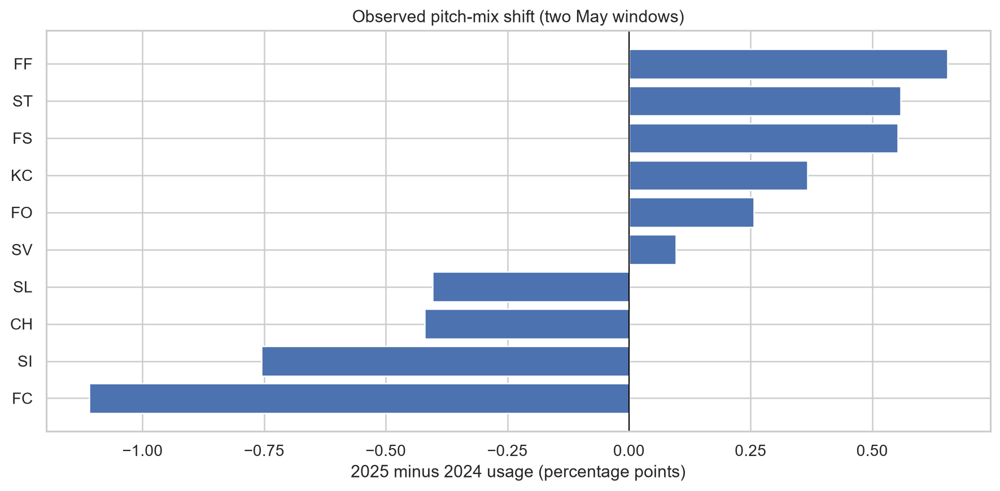

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/v4_pitch_mix_shift.png')

In [136]:
pitch_mix = pd.crosstab(df.season, df.pitch_type)
pitch_mix = pitch_mix.div(pitch_mix.sum(axis=1), axis=0)
common = pitch_mix.reindex(index=[2024, 2025], fill_value=0)
js_distance = float(jensenshannon(common.loc[2024].to_numpy(), common.loc[2025].to_numpy()))
changes = (common.loc[2025] - common.loc[2024]).sort_values(key=abs, ascending=False)
change_table = pd.DataFrame({'pitch_type': changes.index,
                             'share_2024': common.loc[2024, changes.index].to_numpy(),
                             'share_2025': common.loc[2025, changes.index].to_numpy(),
                             'share_diff_pp': changes.to_numpy() * 100})
v4_table(change_table.head(12), 'pitch_mix_shift')
print('Jensen-Shannon distance (observed sample):', round(js_distance, 4))
fig, ax = plt.subplots(figsize=(10, 5))
sel = change_table.head(10).sort_values('share_diff_pp')
ax.barh(sel.pitch_type, sel.share_diff_pp)
ax.axvline(0, color='black', lw=.8)
ax.set(xlabel='2025 minus 2024 usage (percentage points)',title='Observed pitch-mix shift (two May windows)')
fig.tight_layout();v4_plot(fig, 'pitch_mix_shift')

## 28.3 | Unsupervised pitch-shape archetypes

**RQ:** Which pitch shapes occur naturally from speed, spin and movement, rather than from official pitch labels? K-Means is fitted **only on 2024** and projected to 2025; clusters are descriptive categories, not performance rankings.

,season,shape_cluster,n,speed,spin,arm_break,vertical_break
0,2024,0,8885,80.854,2574.460,11.480,-4.902
1,2024,1,17620,94.326,2313.560,-7.159,15.970
2,2024,2,11174,86.714,2395.303,4.050,4.032
3,2024,3,10698,92.032,2117.933,-15.350,7.343
4,2024,4,5573,85.072,1512.893,-12.058,4.111
5,2025,0,9176,81.106,2616.626,11.170,-5.460
6,2025,1,18253,94.539,2322.859,-7.453,15.935
7,2025,2,11514,86.978,2403.563,3.965,3.938
8,2025,3,10821,92.403,2141.151,-15.607,6.606
9,2025,4,5557,84.808,1506.778,-12.263,3.655


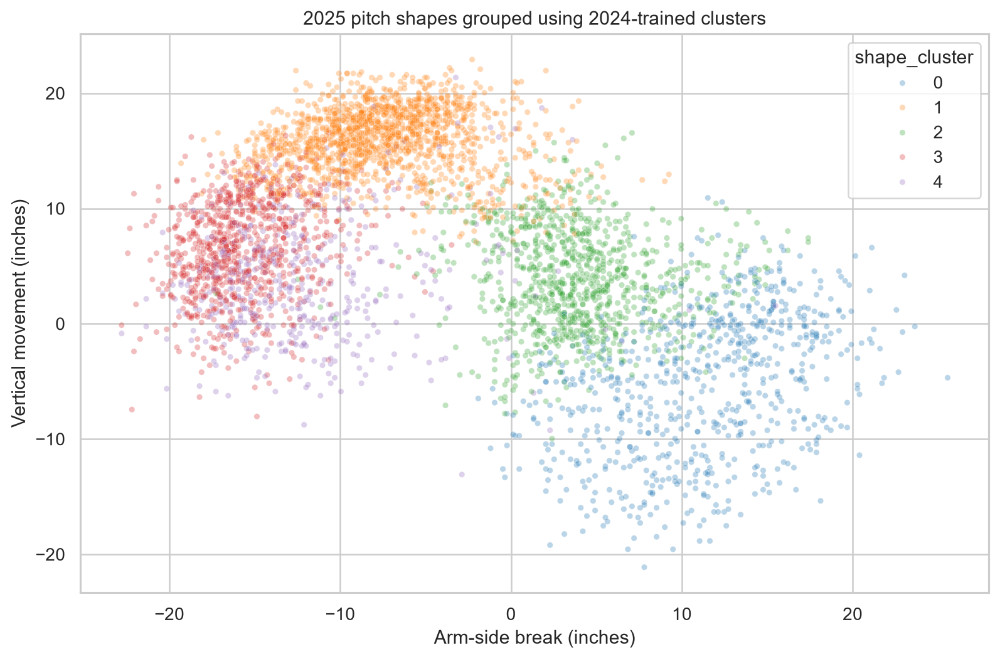

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/v4_shape_clusters.png')

In [137]:
shape_cols = ['release_speed', 'release_spin_rate', 'pfx_x', 'pfx_z']
shape = df.dropna(subset=shape_cols + ['pitch_type', 'p_throws']).copy()
shape = shape.loc[shape.p_throws.isin(['L','R'])]
shape['arm_break_in'] = shape.pfx_x * np.where(shape.p_throws.eq('R'), 12, -12)
shape['vertical_break_in'] = shape.pfx_z * 12
shape_vars = ['release_speed','release_spin_rate','arm_break_in','vertical_break_in']
fit_data = shape.loc[shape.season.eq(2024)].sample(
    n=min(14000, int(shape.season.eq(2024).sum())), random_state=42)
shape_scaler = StandardScaler().fit(fit_data[shape_vars])
shape_cluster = KMeans(n_clusters=5, n_init=10, random_state=42)
shape_cluster.fit(shape_scaler.transform(fit_data[shape_vars]))
shape['shape_cluster'] = shape_cluster.predict(shape_scaler.transform(shape[shape_vars]))
profiles = shape.groupby(['season','shape_cluster']).agg(
    n=('pitch_type','size'), speed=('release_speed','mean'),
    spin=('release_spin_rate','mean'), arm_break=('arm_break_in','mean'),
    vertical_break=('vertical_break_in','mean')).reset_index()
v4_table(profiles, 'unsupervised_pitch_shapes')
fig, ax = plt.subplots(figsize=(9, 6))
draw = shape.loc[shape.season.eq(2025)].sample(
    n=min(4500, int(shape.season.eq(2025).sum())), random_state=42)
sns.scatterplot(data=draw, x='arm_break_in', y='vertical_break_in',
                hue='shape_cluster', palette='tab10', alpha=.3, s=14, ax=ax)
ax.set(title='2025 pitch shapes grouped using 2024-trained clusters',
       xlabel='Arm-side break (inches)', ylabel='Vertical movement (inches)')
fig.tight_layout();v4_plot(fig, 'shape_clusters')

## 29 | Pitcher-Level Mechanics and Within-Game Variation

Unlike broad comparisons between different pitchers, within-pitcher and within-game contrasts reduce some composition confounding, although pitch choice, opponent and count remain uncontrolled.

third,game_pk,pitcher,Early,Late,late_minus_early_mph
69,745257,669302,93.130,86.215,-6.915
731,778033,607625,90.084,83.718,-6.366
746,778039,669194,94.157,88.125,-6.032
390,746890,669713,90.340,84.503,-5.837
553,777958,682243,92.630,86.923,-5.707
53,745183,458681,91.539,86.012,-5.526
245,746147,665795,92.311,86.795,-5.516
877,778096,605488,88.127,82.652,-5.475
733,778034,519242,89.278,84.197,-5.081
75,745264,693433,95.215,90.214,-5.001


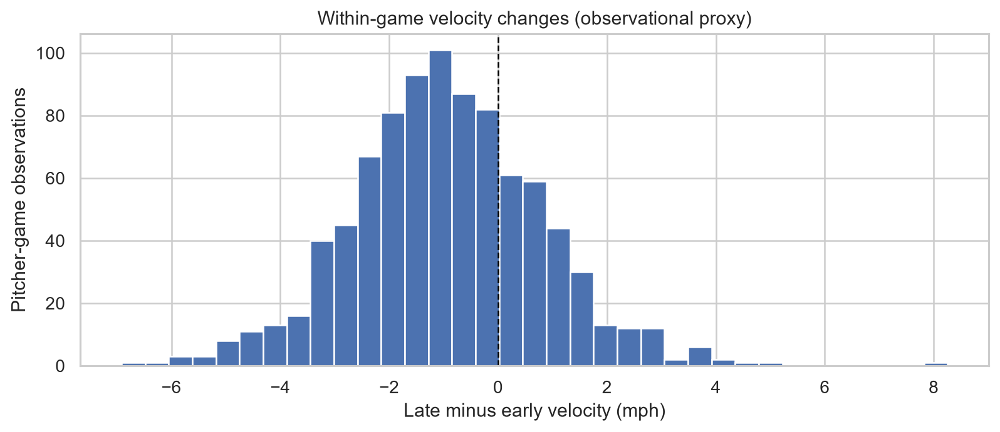

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/v4_within_game_velocity.png')

In [138]:
pg = df.loc[df.release_speed.notna()].sort_values(['game_pk','pitcher','at_bat_number','pitch_number']).copy()
pg['game_pitch_index'] = pg.groupby(['game_pk','pitcher']).cumcount() + 1
pg['game_pitch_n'] = pg.groupby(['game_pk','pitcher']).game_pitch_index.transform('max')
pg = pg.loc[pg.game_pitch_n >= 35]
pg['third'] = np.where(pg.game_pitch_index <= pg.game_pitch_n/3, 'Early',
                       np.where(pg.game_pitch_index > pg.game_pitch_n*2/3, 'Late', 'Middle'))
ends = pg.loc[pg.third.isin(['Early','Late'])].groupby(
    ['game_pk','pitcher','third']).release_speed.agg(['mean','size']).reset_index()
means = ends.pivot(index=['game_pk','pitcher'],columns='third',values='mean').dropna()
ns = ends.pivot(index=['game_pk','pitcher'],columns='third',values='size').reindex(means.index)
means = means.loc[(ns.Early >= 7) & (ns.Late >= 7)]
means['late_minus_early_mph'] = means.Late - means.Early
v4_table(means.reset_index().sort_values('late_minus_early_mph').head(20), 'within_game_velocity_change')
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(means.late_minus_early_mph, bins=35)
ax.axvline(0, color='black', ls='--', lw=1)
ax.set(xlabel='Late minus early velocity (mph)', ylabel='Pitcher-game observations',
       title='Within-game velocity changes (observational proxy)')
fig.tight_layout();v4_plot(fig, 'within_game_velocity')

## 29.1 | Release-point consistency by pitcher and pitch type

**RQ:** Do pitchers maintain repeatable release points across appearances? Standard deviations are only presented when release coordinates are available and groups are large enough.

,pitcher,pitch_type,n,x_sd,z_sd,velocity,radial_sd_proxy
2278,680885,FF,88,0.080,0.056,96.583,0.098
56,500779,CH,80,0.090,0.069,85.401,0.113
347,592351,FF,88,0.081,0.081,93.997,0.115
1470,663776,CH,94,0.098,0.069,82.611,0.120
2282,681035,FF,84,0.083,0.086,94.724,0.120
1474,663776,SL,94,0.102,0.064,87.741,0.121
1381,663436,FF,81,0.092,0.078,94.238,0.121
2768,801403,FF,86,0.112,0.048,97.301,0.122
1383,663436,SL,114,0.093,0.080,88.253,0.122
355,592662,FF,131,0.104,0.067,93.659,0.124


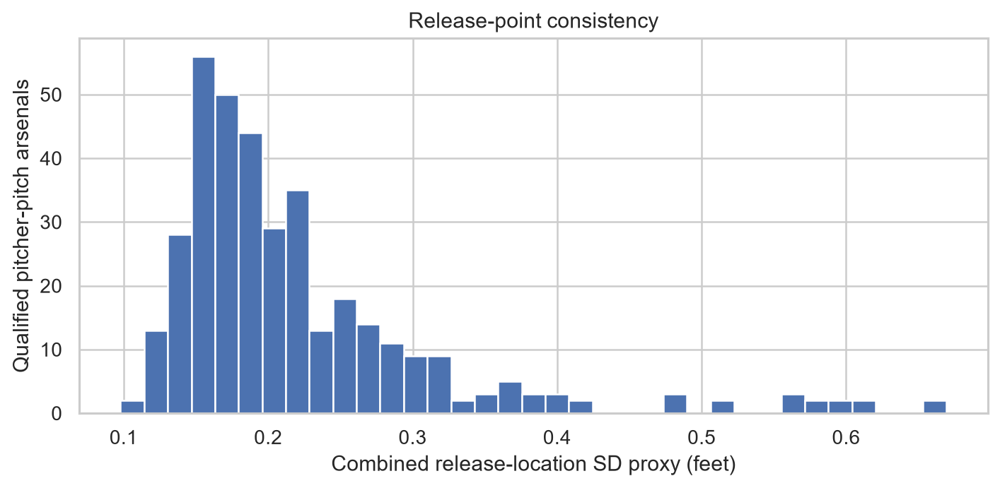

In [139]:
release_cols = ['release_pos_x','release_pos_z']
if all(col in df.columns for col in release_cols):
    release = df.dropna(subset=release_cols).groupby(['pitcher','pitch_type']).agg(
        n=('pitch_type','size'), x_sd=('release_pos_x','std'), z_sd=('release_pos_z','std'),
        velocity=('release_speed','mean')).reset_index()
    release = release.loc[release.n >= 80].copy()
    release['radial_sd_proxy'] = np.sqrt(release.x_sd**2 + release.z_sd**2)
    v4_table(release.sort_values('radial_sd_proxy').head(25), 'release_consistency')
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(release.radial_sd_proxy.dropna(),bins=35)
    ax.set(xlabel='Combined release-location SD proxy (feet)',
           ylabel='Qualified pitcher-pitch arsenals',title='Release-point consistency')
    fig.tight_layout();v4_plot(fig, 'release_consistency')
else:
    print('Release coordinates unavailable; analysis skipped.')

## 29.2 | Empirical-Bayes pitching Whiff rate

**RQ:** How much do small samples distort rankings? A common Beta prior shrinks pitcher Whiff/swing rates toward the observed league mean. Posterior intervals are descriptive and do not correct for opponent, count or pitch mix.

,pitcher,swings,whiffs,raw_rate,shrunk_rate,low_95,high_95
255,656302,293,108,0.369,0.332,0.287,0.380
406,669373,257,96,0.374,0.332,0.284,0.382
401,669276,104,45,0.433,0.332,0.269,0.397
476,676477,50,24,0.480,0.311,0.240,0.387
335,663893,58,26,0.448,0.308,0.238,0.382
26,519242,251,85,0.339,0.307,0.260,0.356
18,518585,98,38,0.388,0.306,0.244,0.372
618,695243,76,31,0.408,0.305,0.239,0.375
380,668674,78,31,0.397,0.301,0.236,0.371
507,678692,54,23,0.426,0.296,0.227,0.371


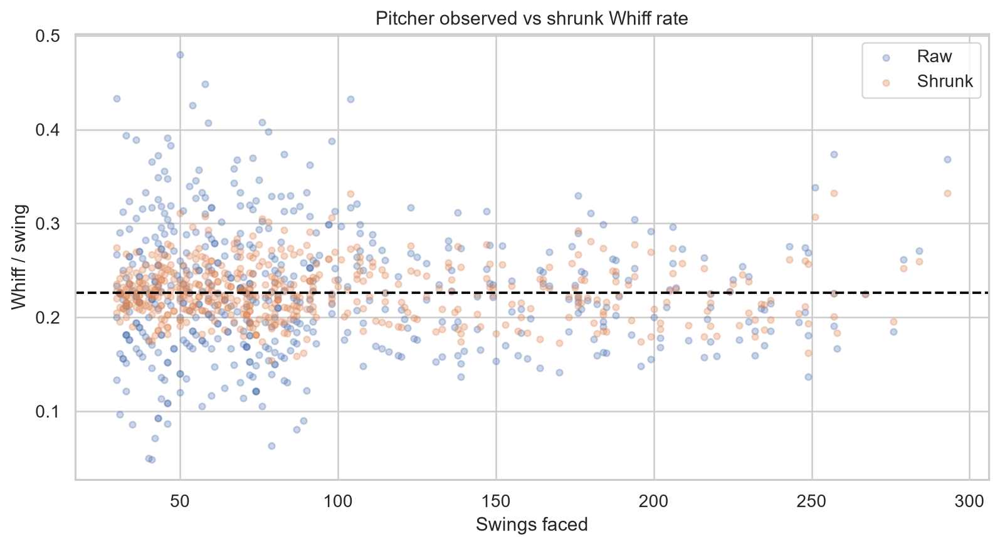

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/v4_pitcher_shrinkage.png')

In [140]:
ps = df.groupby('pitcher').agg(swings=('swing_ind','sum'), whiffs=('whiff_ind','sum')).reset_index()
ps = ps.loc[ps.swings >= 30].copy()
prior_mean = float(df.whiff_ind.sum()/max(df.swing_ind.sum(),1))
prior_strength = 100
ps['raw_rate'] = ps.whiffs / ps.swings
ps['shrunk_rate'] = (ps.whiffs + prior_mean*prior_strength)/(ps.swings + prior_strength)
ps['low_95'] = beta.ppf(.025, ps.whiffs + prior_mean*prior_strength,
                        ps.swings - ps.whiffs + (1-prior_mean)*prior_strength)
ps['high_95'] = beta.ppf(.975, ps.whiffs + prior_mean*prior_strength,
                         ps.swings - ps.whiffs + (1-prior_mean)*prior_strength)
v4_table(ps.sort_values('shrunk_rate',ascending=False).head(20), 'pitcher_shrunk_whiff')
fig, ax = plt.subplots(figsize=(9,5))
ax.scatter(ps.swings, ps.raw_rate, alpha=.3, s=16, label='Raw')
ax.scatter(ps.swings, ps.shrunk_rate, alpha=.3, s=16, label='Shrunk')
ax.axhline(prior_mean, color='black', ls='--')
ax.set(xlabel='Swings faced', ylabel='Whiff / swing',
       title='Pitcher observed vs shrunk Whiff rate')
ax.legend();fig.tight_layout();v4_plot(fig, 'pitcher_shrinkage')

## 30 | Hitter Recognition and Location Profiles

Hitter-specific decisions should be conditioned on pitch location and count rather than compared solely through an overall swing percentage.

strike_group,batter,0 strikes,2 strikes,two_minus_zero_pp
190,663527,0.022,0.625,60.278
203,663853,0.222,0.786,56.349
226,665828,0.250,0.783,53.261
110,624512,0.143,0.667,52.381
182,660688,0.148,0.667,51.852
336,678246,0.000,0.514,51.429
140,643396,0.171,0.677,50.599
286,670156,0.095,0.591,49.567
102,623912,0.278,0.769,49.145
22,543228,0.154,0.643,48.901


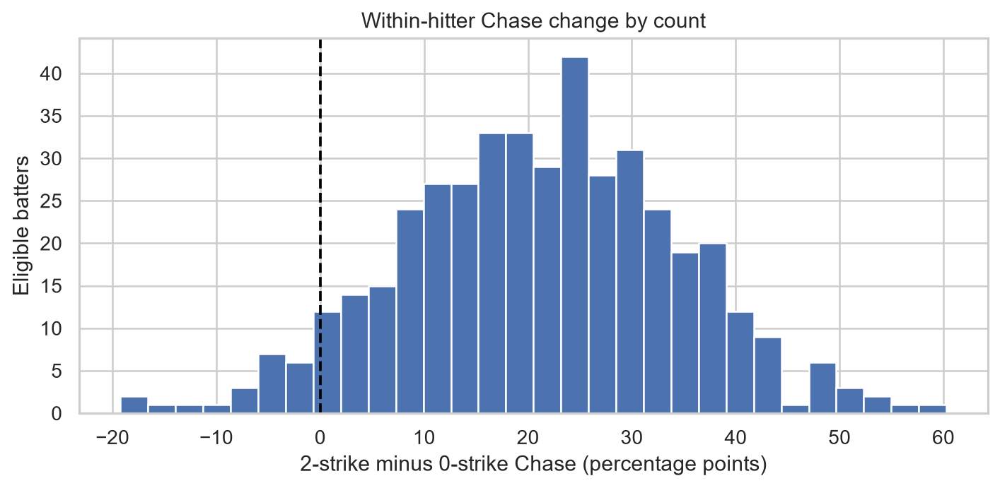

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/v4_within_hitter_chase.png')

In [141]:
ch = df.loc[df.zone_known & ~df.in_zone & df.strikes.isin([0,2])].copy()
ch['strike_group'] = ch.strikes.map({0:'0 strikes',2:'2 strikes'})
h = ch.groupby(['batter','strike_group']).swing_ind.agg(['size','sum','mean']).reset_index()
n = h.pivot(index='batter',columns='strike_group',values='size')
r = h.pivot(index='batter',columns='strike_group',values='mean')
valid = n.dropna().loc[lambda x: (x['0 strikes']>=12) & (x['2 strikes']>=12)].index
matched = r.loc[valid].copy()
matched['two_minus_zero_pp'] = (matched['2 strikes'] - matched['0 strikes'])*100
v4_table(matched.reset_index().sort_values('two_minus_zero_pp',ascending=False).head(20), 'matched_hitter_chase_by_count')
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(matched.two_minus_zero_pp,bins=30)
ax.axvline(0,ls='--',color='black')
ax.set(xlabel='2-strike minus 0-strike Chase (percentage points)',
       ylabel='Eligible batters',title='Within-hitter Chase change by count')
fig.tight_layout();v4_plot(fig,'within_hitter_chase')

## 30.1 | Contact quality by attack-zone location

**RQ:** Does observed hard-hit contact concentrate in different normalized height regions? Rates are conditional on tracked balls in play and therefore exclude misses, foul balls and untracked BBE.

,height_bin,x_bin,size,sum,mean
0,"(-0.401, 0.0]","(-2.001, -0.83]",79,10,0.127
1,"(-0.401, 0.0]","(-0.83, 0.0]",680,198,0.291
2,"(-0.401, 0.0]","(0.0, 0.83]",761,233,0.306
3,"(-0.401, 0.0]","(0.83, 2.0]",102,4,0.039
4,"(0.0, 0.33]","(-2.001, -0.83]",327,59,0.180
5,"(0.0, 0.33]","(-0.83, 0.0]",2614,1299,0.497
6,"(0.0, 0.33]","(0.0, 0.83]",2701,1185,0.439
7,"(0.0, 0.33]","(0.83, 2.0]",329,38,0.116
8,"(0.33, 0.67]","(-2.001, -0.83]",446,77,0.173
9,"(0.33, 0.67]","(-0.83, 0.0]",3306,1522,0.460


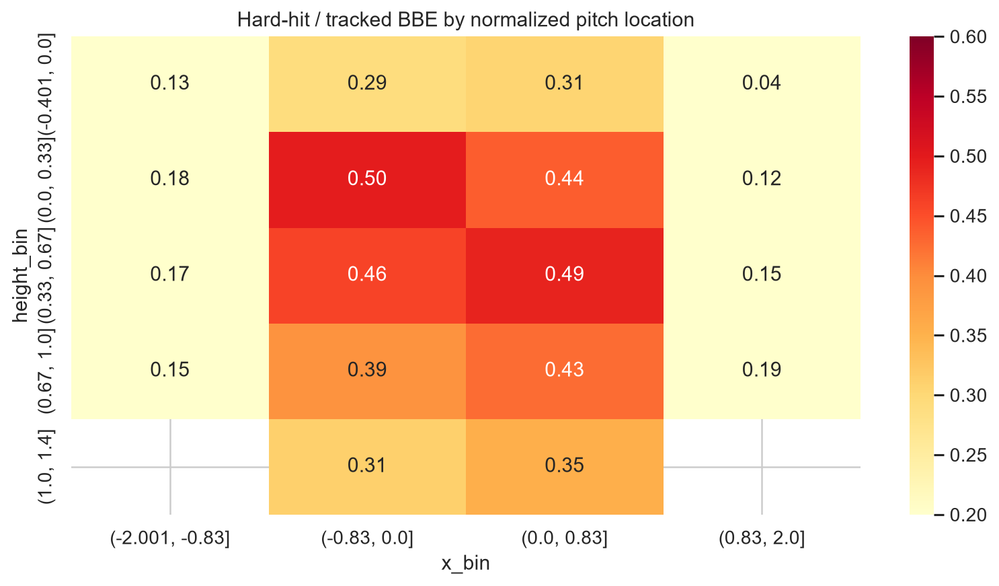

In [142]:
zone_bbe = batted.copy()
need_zone = {'sz_top','sz_bot','plate_z','plate_x'}
if need_zone.issubset(zone_bbe.columns):
    bot = pd.to_numeric(zone_bbe.sz_bot, errors='coerce')
    top = pd.to_numeric(zone_bbe.sz_top, errors='coerce')
    z = pd.to_numeric(zone_bbe.plate_z, errors='coerce')
    height = top-bot
    zone_bbe['normalized_z'] = (z-bot)/height.where(height>.3)
    zone_bbe = zone_bbe.loc[zone_bbe.normalized_z.between(-.4,1.4)]
    zone_bbe['height_bin']=pd.cut(zone_bbe.normalized_z,[-.4,0,.33,.67,1,1.4],include_lowest=True)
    zone_bbe['x_bin']=pd.cut(pd.to_numeric(zone_bbe.plate_x,errors='coerce'),[-2,-.83,0,.83,2],include_lowest=True)
    heat = zone_bbe.groupby(['height_bin','x_bin'],observed=True).hard_hit.agg(['size','sum','mean']).reset_index()
    heat.loc[heat['size']<40,'mean']=np.nan
    v4_table(heat,'bbe_hardhit_location')
    fig,ax=plt.subplots(figsize=(9,5))
    sns.heatmap(heat.pivot(index='height_bin',columns='x_bin',values='mean'),
                annot=True,fmt='.2f',cmap='YlOrRd',ax=ax,vmin=.2,vmax=.6)
    ax.set(title='Hard-hit / tracked BBE by normalized pitch location')
    fig.tight_layout();v4_plot(fig,'hardhit_location')
else:
    print('Strike-zone height fields unavailable; location analysis skipped.')

## 30.2 | Statcast contact categories where observed

If `launch_speed_angle` exists, the value 6 represents the public Statcast barrel quality category. Other categories and missing values must not be silently reclassified as barrels.

,pitch_type,size,sum,mean
6,FF,5590,587,0.105
11,SI,3644,241,0.066
12,SL,2775,226,0.081
0,CH,2164,168,0.078
5,FC,1549,124,0.080
13,ST,1402,108,0.077
2,CU,1005,83,0.083
8,FS,677,40,0.059
9,KC,295,12,0.041
14,SV,98,6,0.061


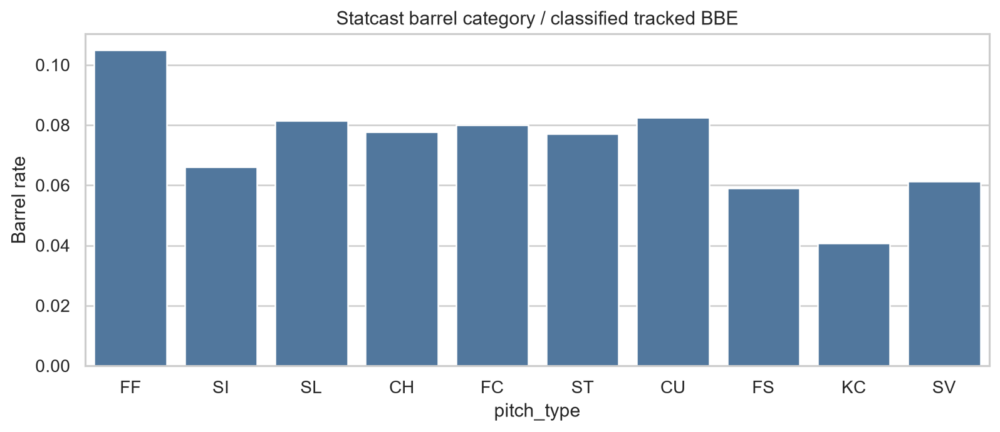

In [143]:
if 'launch_speed_angle' in batted.columns:
    barrels = batted.copy()
    barrels['quality_code'] = pd.to_numeric(barrels.launch_speed_angle,errors='coerce')
    barrels = barrels.loc[barrels.quality_code.notna()].copy()
    barrels['barrel'] = barrels.quality_code.eq(6).astype(int)
    by_type = barrels.groupby('pitch_type').barrel.agg(['size','sum','mean']).reset_index()
    by_type = by_type.loc[by_type['size']>=60].sort_values('size',ascending=False)
    v4_table(by_type,'barrel_by_pitch_type')
    fig,ax=plt.subplots(figsize=(9,4))
    sns.barplot(data=by_type.head(12),x='pitch_type',y='mean',color='#4477aa',ax=ax)
    ax.set(title='Statcast barrel category / classified tracked BBE',ylabel='Barrel rate')
    fig.tight_layout();v4_plot(fig,'barrel_rate')
else:
    print('Statcast launch_speed_angle unavailable; barrel analysis skipped.')

## 31 | Predictive Reliability and Time-Based Model Monitoring

The following are diagnostics of models chosen in earlier work. They do **not** constitute a fresh, untouched 2025 final evaluation. A properly prospective test requires later data that has not already informed model selection.

,week,n,observed_rate,predicted_rate,brier
0,2025-04-28/2025-05-04,16109,0.099,0.110,0.084
1,2025-05-05/2025-05-11,27220,0.107,0.108,0.090
2,2025-05-12/2025-05-18,12017,0.113,0.110,0.092


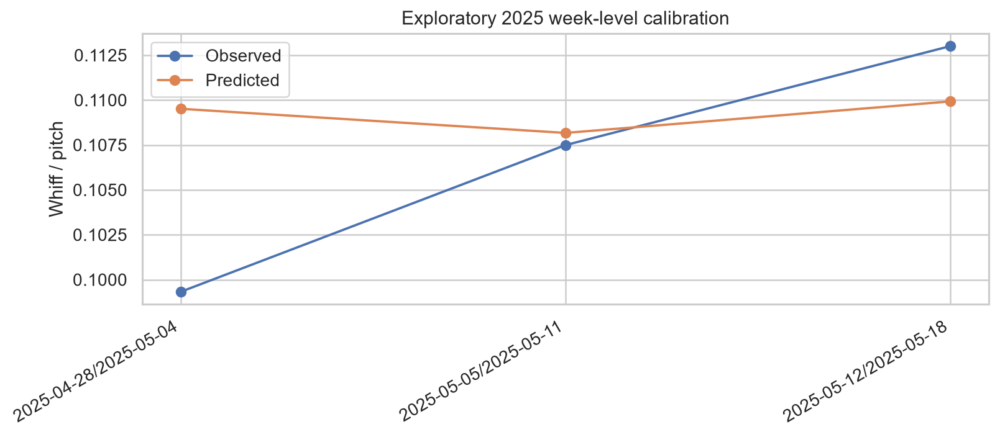

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/v4_weekly_calibration.png')

In [144]:
from sklearn.metrics import roc_auc_score, average_precision_score
obs=np.asarray(hold.whiff_ind,dtype=int)
pr=np.asarray(hold_p,dtype=float)
monitor=hold[['game_pk','game_date','pitch_type','stand','p_throws']].copy()
monitor['observed']=obs
monitor['predicted']=pr
monitor['brier_i']=(monitor.observed-monitor.predicted)**2
weekly=monitor.groupby(pd.to_datetime(monitor.game_date).dt.to_period('W').astype(str)).agg(
    n=('observed','size'),observed_rate=('observed','mean'),predicted_rate=('predicted','mean'),
    brier=('brier_i','mean')).reset_index().rename(columns={'game_date':'week'})
v4_table(weekly,'holdout_weekly_calibration')
fig, ax=plt.subplots(figsize=(9,4))
ax.plot(range(len(weekly)),weekly.observed_rate,marker='o',label='Observed')
ax.plot(range(len(weekly)),weekly.predicted_rate,marker='o',label='Predicted')
ax.set(xticks=range(len(weekly)),xticklabels=weekly.iloc[:,0].tolist(),
       ylabel='Whiff / pitch',title='Exploratory 2025 week-level calibration')
ax.legend();fig.autofmt_xdate();fig.tight_layout();v4_plot(fig,'weekly_calibration')

## 31.1 | Covariate stability across the two observation windows

Population Stability Index (PSI) can detect a shift in the **measured predictor distribution**, not explain what caused the shift. The 2024 quantile bins are fixed before evaluating 2025. Absolute PSI values are not universal significance tests.

In [145]:
def v4_psi(reference, current, bins=10):
    a=pd.to_numeric(reference,errors='coerce').dropna()
    b=pd.to_numeric(current,errors='coerce').dropna()
    if len(a)<100 or len(b)<100:return np.nan
    edges=np.unique(np.quantile(a,np.linspace(0,1,bins+1)))
    if len(edges)<3:return np.nan
    edges[0]=-np.inf; edges[-1]=np.inf
    ra=np.histogram(a,bins=edges)[0]/len(a)
    rb=np.histogram(b,bins=edges)[0]/len(b)
    ra=np.maximum(ra,1e-6);rb=np.maximum(rb,1e-6)
    return float(np.sum((rb-ra)*np.log(rb/ra)))
shift=[]
for col in ['release_speed','release_spin_rate','plate_x','plate_z','pfx_x','pfx_z']:
    if col in df.columns:
        shift.append({'feature':col,'psi':v4_psi(df.loc[df.season.eq(2024),col],
                                                 df.loc[df.season.eq(2025),col]),
                      'coverage_2024':df.loc[df.season.eq(2024),col].notna().mean(),
                      'coverage_2025':df.loc[df.season.eq(2025),col].notna().mean()})
v4_table(pd.DataFrame(shift).sort_values('psi',ascending=False),'covariate_drift')

,feature,psi,coverage_2024,coverage_2025
1,release_spin_rate,0.008,0.999,1.0
0,release_speed,0.008,1.000,1.0
4,pfx_x,0.004,1.000,1.0
5,pfx_z,0.003,1.000,1.0
3,plate_z,0.002,1.000,1.0
2,plate_x,0.001,1.000,1.0


,feature,psi,coverage_2024,coverage_2025
1,release_spin_rate,0.008005,0.999093,0.999783
0,release_speed,0.007534,0.999981,0.999765
4,pfx_x,0.003974,1.000000,1.000000
5,pfx_z,0.003334,1.000000,1.000000
3,plate_z,0.001754,1.000000,1.000000
2,plate_x,0.000740,1.000000,1.000000


## 31.2 | Hierarchical calibration audit: pitch type × count

**RQ:** Are probability errors concentrated in well-supported situations? Large calibration gaps in tiny subgroups are not interpreted as stable patterns.

,pitch_type,count,n,observed,predicted,gap_pp
85,FS,0-0,277,0.065,0.119,5.395
25,CU,1-2,423,0.118,0.162,4.353
8,CH,2-2,507,0.170,0.132,-3.799
102,KC,1-2,158,0.120,0.154,3.389
93,FS,2-2,234,0.201,0.169,-3.180
58,FC,2-1,236,0.089,0.120,3.104
138,ST,1-0,316,0.127,0.098,-2.843
140,ST,1-2,583,0.120,0.148,2.755
51,FC,0-0,1137,0.067,0.094,2.710
72,FF,3-0,404,0.005,0.031,2.650


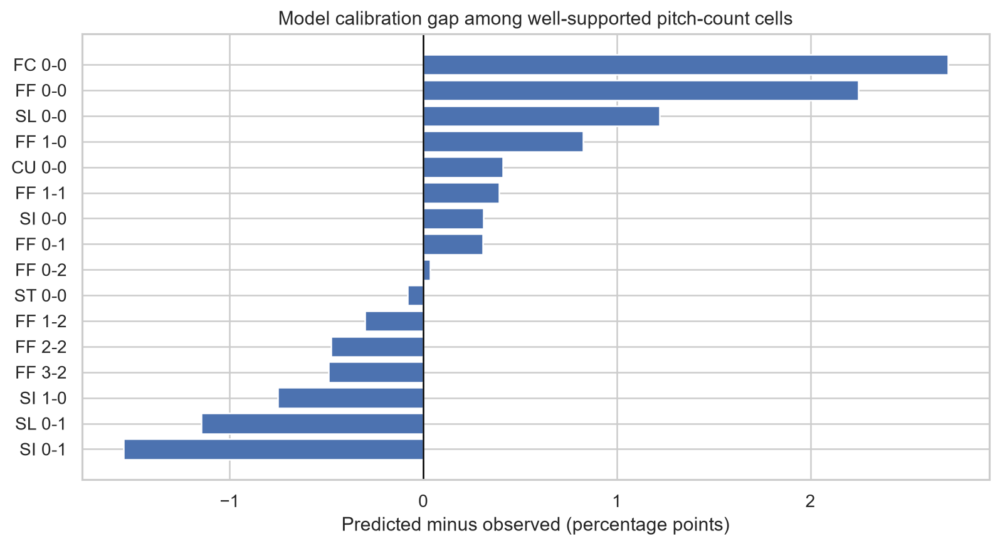

WindowsPath('I:/Potforlio/MLB Analytics/outputs/submission_figures/v4_calibration_by_pitch_count.png')

In [146]:
cal = hold[['pitch_type','balls','strikes','game_pk']].copy()
cal['observed']=obs
cal['predicted']=pr
cal['count']=cal.balls.astype(int).astype(str)+'-'+cal.strikes.astype(int).astype(str)
cal_table = cal.groupby(['pitch_type','count']).agg(
    n=('observed','size'),observed=('observed','mean'),predicted=('predicted','mean')).reset_index()
cal_table=cal_table.loc[cal_table.n>=140].copy()
cal_table['gap_pp']=(cal_table.predicted-cal_table.observed)*100
v4_table(cal_table.sort_values('gap_pp',key=abs,ascending=False).head(30),
         'pitch_count_calibration_gaps')
fig,ax=plt.subplots(figsize=(9,5))
top=cal_table.nlargest(16,'n').sort_values('gap_pp')
ax.barh(top.pitch_type+' '+top['count'],top.gap_pp)
ax.axvline(0,color='black',lw=1)
ax.set(title='Model calibration gap among well-supported pitch-count cells',
       xlabel='Predicted minus observed (percentage points)')
fig.tight_layout();v4_plot(fig,'calibration_by_pitch_count')

## 31.3 | New-model candidate: reduced-information spline logistic

Test on the **2024 validation period only**, using the same target but a different inductive bias: non-linear splines for velocity and vertical pitch location plus categorical pitch count/handedness. This is not selected using the previously inspected 2025 outcomes.

In [147]:
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
spline_cols = [v for v in ['release_speed','plate_z'] if v in feature_cols]
linear_cols = [v for v in ['release_spin_rate','pfx_x','pfx_z','plate_x','balls','strikes'] if v in feature_cols]
cat_cols_v4 = [v for v in ['pitch_type','stand','p_throws'] if v in feature_cols]
spline_pre=ColumnTransformer([
    ('spline',Pipeline([('impute',SimpleImputer(strategy='median')),
                        ('basis',SplineTransformer(n_knots=5,degree=3))]),spline_cols),
    ('continuous',Pipeline([('impute',SimpleImputer(strategy='median')),
                           ('scale',StandardScaler())]),linear_cols),
    ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                    ('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat_cols_v4)
])
spline_model=Pipeline([('pre',spline_pre),
                       ('classifier',LogisticRegression(C=.5,max_iter=1000))])
spline_model.fit(tr[feature_cols],tr.whiff_ind.astype(int))
spline_probs=spline_model.predict_proba(va[feature_cols])[:,1]
spline_comp=pd.DataFrame([
    {'model':'SplineLogistic',**score(va.whiff_ind,spline_probs)},
    {'model':'ExistingSelected2024',**score(va.whiff_ind,
        fits[selected_name].predict_proba(va[feature_cols])[:,1])}])
v4_table(spline_comp,'spline_vs_existing_2024_validation',4)

,model,ROC_AUC,PR_AUC,Brier,LogLoss
0,SplineLogistic,0.6399,0.1714,0.0944,0.3313
1,ExistingSelected2024,0.7828,0.3194,0.0863,0.2935


,model,ROC_AUC,PR_AUC,Brier,LogLoss
0,SplineLogistic,0.639916,0.171443,0.094435,0.331319
1,ExistingSelected2024,0.782843,0.319444,0.086296,0.293542


## 32 | Research Integrity and Deliverable Manifest

Final checks guard denominators, chronological ordering, missing fields, and clearly label the observation windows. Reported findings should be generated from **executed results**, not inferred from analysis titles.

In [148]:
checks={
    'unique_pitch_key': bool(~df.duplicated(['game_pk','at_bat_number','pitch_number']).any()),
    'whiff_subset_of_swing': bool((df.whiff_ind.fillna(0)<=df.swing_ind.fillna(0)).all()),
    'valid_bbe_hard_hit_denominator': bool((batted.hard_hit.astype(int).sum()<=len(batted))),
    'chronological_2024_validation': bool(tr.game_date.max()<va.game_date.min()),
    'holdout_occurs_after_train': bool(train_all.game_date.max()<hold.game_date.min()),
    'nonempty_games': bool(df.game_pk.nunique()>0)
}
assert all(checks.values()), f'Integrity gate failed: {checks}'
manifest=pd.DataFrame([{'check':k,'passed':v} for k,v in checks.items()])
v4_table(manifest,'integrity_gate')
import json
notes={
  'data_windows':{str(y):[str(g.game_date.min().date()),str(g.game_date.max().date())]
                   for y,g in df.groupby('season')},
  'n_pitches':int(len(df)), 'n_games':int(df.game_pk.nunique()),
  'original_selected_model':str(selected_name),
  'research_caveat':'2025 is exploratory after repeated inspection in prior iterations',
  'v4_appendix':'repertoire drift, pitch shape clustering, within-game variation, release consistency, player shrinkage, count-conditioned Chase, normalized location, barrel category, drift/calibration, spline candidate',
  'checks':checks
}
(V4_DIR/'study_manifest.json').write_text(json.dumps(notes,indent=2),encoding='utf-8')
print('V4 research outputs:',V4_DIR)

,check,passed
0,unique_pitch_key,True
1,whiff_subset_of_swing,True
2,valid_bbe_hard_hit_denominator,True
3,chronological_2024_validation,True
4,holdout_occurs_after_train,True
5,nonempty_games,True


V4 research outputs: I:\Potforlio\MLB Analytics\outputs\research_v4


## 33 | Analysis Integrity and Target-Population Audit

**Research question:** Which pitches are eligible for each baseball outcome? A missing exit velocity is not an unsuccessful hard hit. Track swing, observed in-play contact, hard hit, and called-strike populations separately. No imputation of missing outcomes.

In [149]:
from pathlib import Path
from statsmodels.stats.proportion import proportion_confint
V5_DIR = ROOT / 'outputs' / 'research_v5'
V5_DIR.mkdir(parents=True, exist_ok=True)

def v5_save(table, slug):
    table.to_csv(V5_DIR / f'{slug}.csv', index=False)
    display(table.head(25).round(4))
    return table

def v5_figure(fig, slug):
    return publish(fig, f'v5_{slug}')

outcome_populations = []
for year, part in df.groupby('season', observed=True):
    inplay = part['type'].eq('X')
    tracked = inplay & part['launch_speed'].notna()
    taken = part['swing_ind'].eq(0)
    outcome_populations.append({
        'season':int(year), 'pitches':len(part), 'swings':int(part.swing_ind.eq(1).sum()),
        'whiffs':int(part.whiff_ind.eq(1).sum()),
        'in_play_bbe':int(inplay.sum()), 'tracked_in_play_bbe':int(tracked.sum()),
        'hard_hit_tracked_bbe':int((tracked & part.launch_speed.ge(95)).sum()),
        'taken_pitches':int(taken.sum()), 'games':part.game_pk.nunique()
    })
population_audit=v5_save(pd.DataFrame(outcome_populations),'target_population_audit')
assert (population_audit['whiffs'] <= population_audit['swings']).all()
assert (population_audit['tracked_in_play_bbe'] <= population_audit['in_play_bbe']).all()

,season,pitches,swings,whiffs,in_play_bbe,tracked_in_play_bbe,hard_hit_tracked_bbe,taken_pitches,games
0,2024,54000,25669,5868,9491,9464,3689,28331,186
1,2025,55346,26254,5884,9857,9824,4148,29092,190


### 33.1 | Tracking selection and data quality by pitch family

**Denominator:** all `type == 'X'` batted-ball events. Coverage is measurement availability, not a measure of hitter quality.

,season,pitch_type,n,tracked,coverage
20,2025,FF,2920,2912,0.9973
6,2024,FF,2683,2678,0.9981
10,2024,SI,1856,1846,0.9946
24,2025,SI,1806,1798,0.9956
25,2025,SL,1408,1404,0.9972
11,2024,SL,1376,1372,0.9971
0,2024,CH,1100,1098,0.9982
14,2025,CH,1073,1066,0.9935
5,2024,FC,797,797,1.0000
19,2025,FC,753,752,0.9987


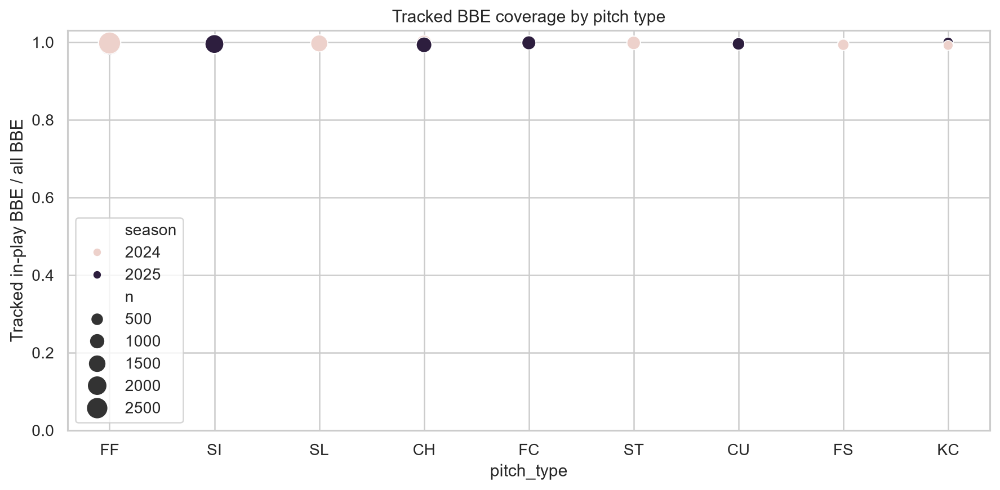

In [150]:
source_bbe=df.loc[df['type'].eq('X')].copy()
bbe_coverage=(source_bbe.groupby(['season','pitch_type'],observed=True)
    .agg(n=('type','size'),tracked=('launch_speed',lambda s:s.notna().sum()))
    .reset_index())
bbe_coverage['coverage']=bbe_coverage.tracked/bbe_coverage.n
bbe_coverage=v5_save(bbe_coverage.loc[bbe_coverage.n>=40].sort_values('n',ascending=False),'bbe_tracking_coverage_by_pitch')
valid= bbe_coverage.loc[bbe_coverage.n>=80]
if not valid.empty and valid.coverage.nunique()>1:
    fig,ax=plt.subplots(figsize=(10,5))
    sns.scatterplot(data=valid,x='pitch_type',y='coverage',hue='season',size='n',sizes=(50,260),ax=ax)
    ax.set(ylim=(0,1.03),title='Tracked BBE coverage by pitch type',ylabel='Tracked in-play BBE / all BBE')
    fig.tight_layout();v5_figure(fig,'bbe_tracking_coverage')
else:
    print('No informative coverage differences; retained as a table, not a redundant chart.')

## 34 | Called-Strike Geography and Plate Discipline

**Research question:** How does the recorded called-strike probability vary with normalized vertical and horizontal plate location, count and pitch type? This is descriptive **called-strike modeling**, not catcher framing or umpire bias measurement.

**Eligible population:** taken pitches explicitly described as `ball`, `blocked_ball`, or `called_strike`. Automatic balls/strikes and pitchouts are excluded for comparability.

In [151]:
taken_types={'ball','blocked_ball','called_strike'}
taken=df.loc[df.description.isin(taken_types)].copy()
for field in ['sz_bot','sz_top','plate_x','plate_z','balls','strikes']:
    taken[field]=pd.to_numeric(taken[field],errors='coerce')
taken=taken.dropna(subset=['plate_x','plate_z','sz_bot','sz_top']).copy()
taken=taken.loc[(taken.sz_top-taken.sz_bot).between(0.75,3.5)].copy()
taken['strike_call']=taken.description.eq('called_strike').astype(int)
taken['zone_height']=(taken.plate_z-taken.sz_bot)/(taken.sz_top-taken.sz_bot)
taken['plate_side']=taken.plate_x.abs()
taken_summary=taken.groupby(['season','strikes','balls'],observed=True).strike_call.agg(n='size',k='sum').reset_index()
taken_summary['rate']=taken_summary.k/taken_summary.n
v5_save(taken_summary,'called_strike_by_count')
print('Eligible taken pitches:',len(taken))

,season,strikes,balls,n,k,rate
0,2024,0,0,9412,4191,0.4453
1,2024,0,1,3003,1212,0.4036
2,2024,0,2,1031,471,0.4568
3,2024,0,3,504,334,0.6627
4,2024,1,0,3587,801,0.2233
5,2024,1,1,2428,621,0.2558
6,2024,1,2,1166,362,0.3105
7,2024,1,3,541,209,0.3863
8,2024,2,0,1842,116,0.0630
9,2024,2,1,2252,241,0.1070


Eligible taken pitches: 57135


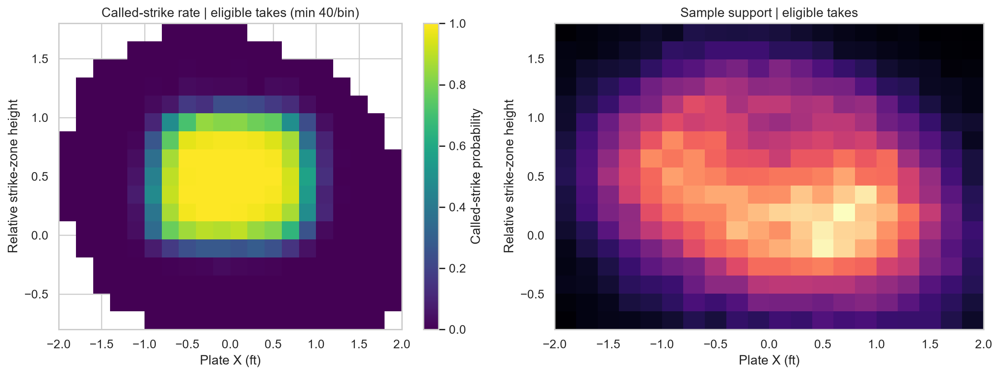

In [152]:
def v5_spatial_prob(data, event_col, min_n=50, xcol='plate_x', ycol='zone_height'):
    xedges=np.linspace(-2,2,21); yedges=np.linspace(-.8,1.8,18)
    sample=data.dropna(subset=[xcol,ycol,event_col]).copy()
    counts,_,_=np.histogram2d(sample[xcol],sample[ycol],bins=[xedges,yedges])
    positive,_,_=np.histogram2d(sample[xcol],sample[ycol],bins=[xedges,yedges],weights=sample[event_col])
    vals=np.divide(positive,counts,out=np.full_like(counts,np.nan),where=counts>=min_n)
    return vals.T,counts.T,xedges,yedges

if len(taken)>=300:
    z,support,xedges,yedges=v5_spatial_prob(taken,'strike_call',min_n=40)
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    im=axes[0].pcolormesh(xedges,yedges,z,cmap='viridis',vmin=0,vmax=1,shading='auto')
    fig.colorbar(im,ax=axes[0],label='Called-strike probability')
    axes[0].set(title='Called-strike rate | eligible takes (min 40/bin)',xlabel='Plate X (ft)',ylabel='Relative strike-zone height')
    axes[1].pcolormesh(xedges,yedges,support,cmap='magma',shading='auto')
    axes[1].set(title='Sample support | eligible takes',xlabel='Plate X (ft)',ylabel='Relative strike-zone height')
    fig.tight_layout();v5_figure(fig,'called_strike_spatial_and_support')

### 34.1 | A new prediction target: taken-pitch called strike

Models are compared only within 2024 using a chronological validation split. Variables include observed pitch location; therefore the task is **after-pitch classification**, not a pre-pitch umpire decision forecast. There is no catcher ID adjustment.

In [153]:
from sklearn.base import clone
from sklearn.metrics import brier_score_loss, average_precision_score
call_feat=['plate_x','zone_height','release_speed','balls','strikes','pitch_type','p_throws','stand']
call_cat=['pitch_type','p_throws','stand'];call_num=[c for c in call_feat if c not in call_cat]
call_pre=ColumnTransformer([
    ('n',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),call_num),
    ('c',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('ohe',OneHotEncoder(handle_unknown='ignore'))]),call_cat)
])
call24=taken.loc[taken.season.eq(2024)].sort_values('game_date').copy()
call_days=call24.game_date.drop_duplicates().sort_values()
if len(call_days)>=5 and call24.strike_call.nunique()==2:
    cut=call_days.iloc[max(0,int(len(call_days)*.75)-1)]
    ct,cv=call24.loc[call24.game_date.le(cut)],call24.loc[call24.game_date.gt(cut)]
    call_models={'Prevalence':DummyClassifier(strategy='prior'),
                 'Logistic':LogisticRegression(max_iter=500),
                 'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=90,max_leaf_nodes=15,min_samples_leaf=45,random_state=42)}
    call_results=[]
    for name,algo in call_models.items():
        pipe=Pipeline([('prep',clone(call_pre)),('classifier',clone(algo))])
        pipe.fit(ct[call_feat],ct.strike_call)
        pp=pipe.predict_proba(cv[call_feat])[:,1]
        call_results.append({'model':name,'n_validate':len(cv),**score(cv.strike_call,pp)})
    call_validation=v5_save(pd.DataFrame(call_results).sort_values('Brier'),'called_strike_model_validation_2024')
else:
    print('Insufficient 2024 taken-pitch data for model comparison.')

,model,n_validate,ROC_AUC,PR_AUC,Brier,LogLoss
2,HistGradientBoosting,8920,0.9827,0.9643,0.0476,0.1567
1,Logistic,8920,0.6919,0.4457,0.1947,0.5683
0,Prevalence,8920,0.5000,0.3136,0.2153,0.6221


## 35 | Hitter Contact Outcomes and Foul-Ball Defense

**Research question:** Can we distinguish whiffs, foul balls, and put-in-play contact among *swung-at* pitches? These are mutually exclusive **conditional on a swing** and must not be compared against all-pitch denominators.

In [154]:
swinging=df.loc[df.swing_ind.eq(1)].copy()
foul_events={'foul','foul_tip','foul_bunt','bunt_foul_tip','foul_pitchout'}
swinging['foul_event']=swinging.description.isin(foul_events).astype(int)
swinging['whiff_event']=swinging.whiff_ind.eq(1).astype(int)
swinging['inplay_event']=swinging.type.eq('X').astype(int)
swinging['other_event']=~swinging[['foul_event','whiff_event','inplay_event']].astype(bool).any(axis=1)
swing_funnel=(swinging.groupby(['season','pitch_type'],observed=True)
 .agg(swings=('swing_ind','size'),fouls=('foul_event','sum'),whiffs=('whiff_event','sum'),inplay=('inplay_event','sum'),other=('other_event','sum'))
 .reset_index())
for col in ['fouls','whiffs','inplay','other']:
    swing_funnel[f'{col}_pct']=swing_funnel[col]/swing_funnel.swings*100
v5_save(swing_funnel.loc[swing_funnel.swings>=100],'swing_outcome_funnel')
assert (swinging[['foul_event','whiff_event','inplay_event']].sum(axis=1)<=1).all(), 'Overlapping swing categories; inspect pitch descriptions' 

,season,pitch_type,swings,fouls,whiffs,inplay,other,fouls_pct,whiffs_pct,inplay_pct,other_pct
0,2024,CH,2764,922,742,1100,0,33.3575,26.8452,39.7974,0.0000
2,2024,CU,1343,466,361,515,1,34.6984,26.8801,38.3470,0.0745
5,2024,FC,2143,881,465,797,0,41.1106,21.6986,37.1909,0.0000
6,2024,FF,8157,3927,1544,2683,3,48.1427,18.9285,32.8920,0.0368
7,2024,FS,863,273,281,308,1,31.6338,32.5608,35.6895,0.1159
8,2024,KC,409,143,139,127,0,34.9633,33.9853,31.0513,0.0000
10,2024,SI,3997,1690,448,1856,3,42.2817,11.2084,46.4348,0.0751
11,2024,SL,4042,1339,1323,1376,4,33.1272,32.7313,34.0426,0.0990
12,2024,ST,1812,610,533,665,4,33.6645,29.4150,36.6998,0.2208
13,2024,SV,107,34,28,45,0,31.7757,26.1682,42.0561,0.0000


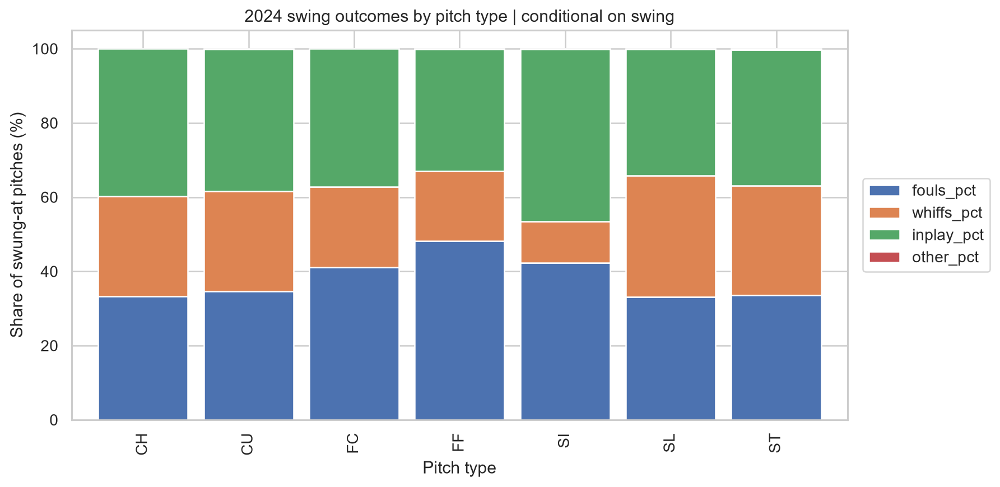

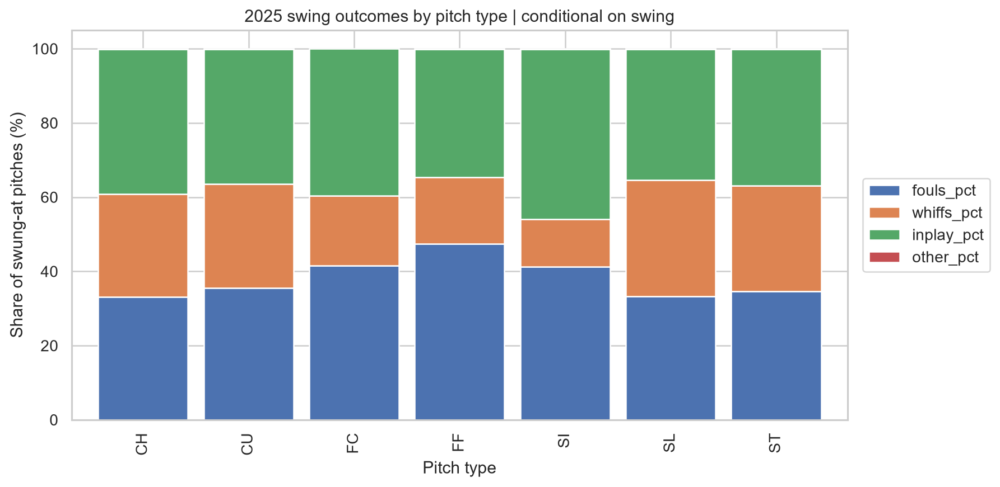

In [155]:
top_pitches=swinging.pitch_type.value_counts().head(7).index
funnel=swing_funnel.loc[swing_funnel.pitch_type.isin(top_pitches)].copy()
for yy,part in funnel.groupby('season'):
    panel=part.set_index('pitch_type')[[f'{x}_pct' for x in ['fouls','whiffs','inplay','other']]]
    fig,ax=plt.subplots(figsize=(10,5));panel.plot.bar(stacked=True,ax=ax,width=.85)
    ax.set(title=f'{yy} swing outcomes by pitch type | conditional on swing',ylabel='Share of swung-at pitches (%)',xlabel='Pitch type')
    ax.legend(loc='center left',bbox_to_anchor=(1.01,.5))
    fig.tight_layout();v5_figure(fig,f'swing_outcome_funnel_{yy}')

### 35.1 | Two-strike foul-ball behavior

Two-strike contact often extends a plate appearance. These comparisons are unadjusted; differences in pitcher quality, pitch selection and foul-bunt rules may explain part of the pattern.

,season,strikes,pitch_type,n,k,rate,lo,hi
0,2024,0,CH,668,215,0.3219,0.2875,0.3582
1,2024,0,CU,316,114,0.3608,0.3098,0.4151
4,2024,0,FC,752,304,0.4043,0.3698,0.4397
5,2024,0,FF,2544,1158,0.4552,0.4359,0.4746
6,2024,0,FS,143,46,0.3217,0.2506,0.4020
7,2024,0,KC,91,33,0.3626,0.2713,0.4651
9,2024,0,SI,1437,561,0.3904,0.3655,0.4159
10,2024,0,SL,1106,347,0.3137,0.2871,0.3417
11,2024,0,ST,379,132,0.3483,0.3021,0.3976
13,2024,1,CH,1061,336,0.3167,0.2894,0.3453


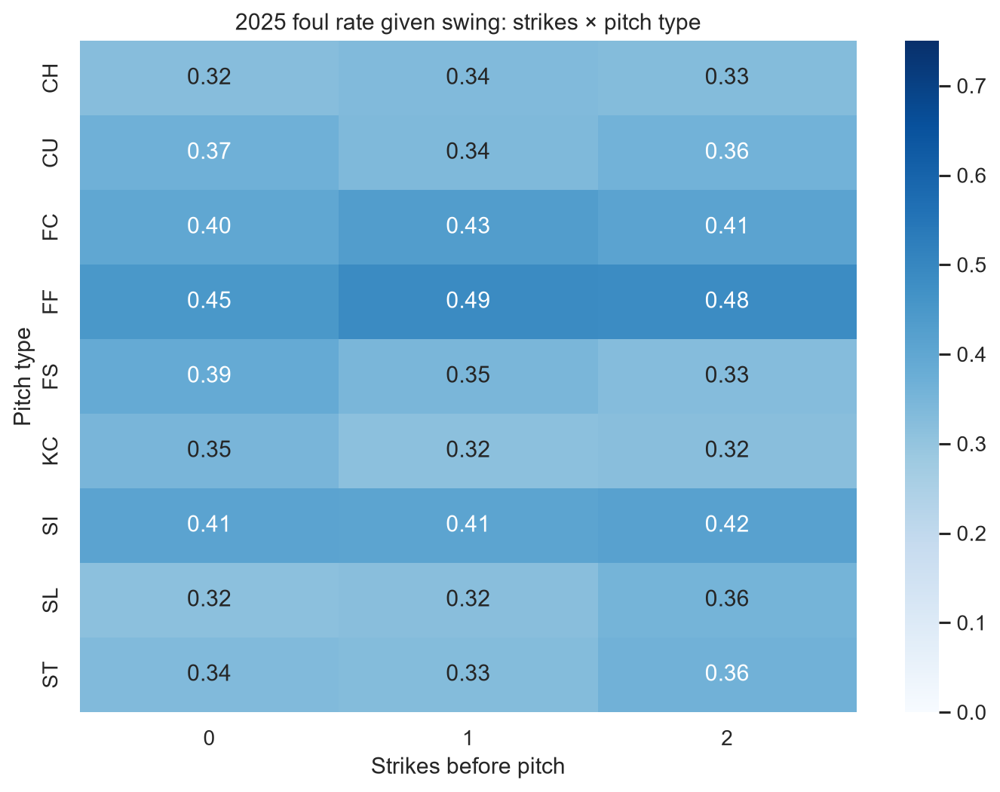

In [156]:
foul_counts=(swinging.groupby(['season','strikes','pitch_type'],observed=True)
   .foul_event.agg(n='size',k='sum').reset_index())
foul_counts=foul_counts.loc[foul_counts.n>=80].copy()
if len(foul_counts):
    foul_counts['rate']=foul_counts.k/foul_counts.n
    foul_counts['lo'],foul_counts['hi']=proportion_confint(foul_counts.k,foul_counts.n,method='wilson')
    v5_save(foul_counts,'foul_prob_by_strike_and_pitch')
    pivot=foul_counts.loc[foul_counts.season.eq(2025)].pivot(index='pitch_type',columns='strikes',values='rate')
    fig,ax=plt.subplots(figsize=(8,6))
    sns.heatmap(pivot,annot=True,fmt='.2f',cmap='Blues',vmin=0,vmax=.75,ax=ax)
    ax.set(title='2025 foul rate given swing: strikes × pitch type',xlabel='Strikes before pitch',ylabel='Pitch type')
    fig.tight_layout();v5_figure(fig,'foul_rates_pitch_by_strikes')

## 36 | Pitch Repertoire Separation and Batter Response

**Research question:** For pitchers with two frequently used pitch types, how far apart are their average pitch shapes? Compare physical separation and observed outcomes descriptively. Movement signs are normalized for pitcher handedness; Euclidean distance in z-scored features is an *arbitrary analytical index*, not a scouting-grade tunneling measure.

,pitcher,type_a,type_b,separation_z,n_pair,whiff_per_swing
108,656302,SL,FF,2.5386,537,0.3718
163,668881,FF,SL,2.7436,427,0.2704
10,519242,SL,FF,3.9724,422,0.3695
0,434378,FF,SL,2.3960,399,0.1990
59,607074,FF,SL,3.1181,389,0.2410
160,667755,SI,KC,3.8481,387,0.2768
141,663855,SI,ST,3.7610,387,0.2235
143,663903,SI,SL,2.7966,386,0.1726
147,664285,SI,CU,4.8145,386,0.2134
165,668933,FC,SL,2.1165,374,0.2308


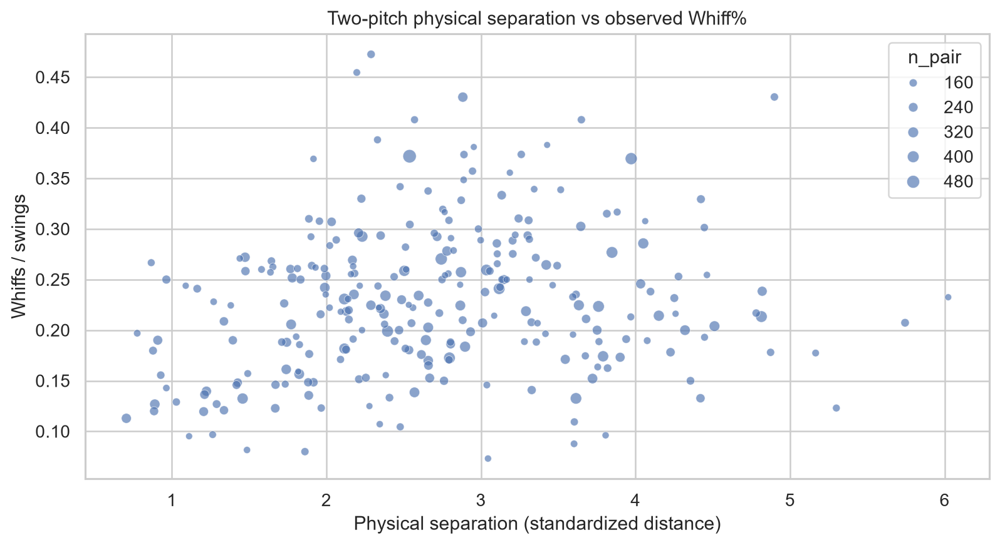

In [157]:
shape_base=df[['pitcher','pitch_type','p_throws','release_speed','release_spin_rate','pfx_x','pfx_z','swing_ind','whiff_ind']].dropna().copy()
shape_base=shape_base.loc[shape_base.p_throws.isin(['L','R'])].copy()
shape_base['arm_break']=np.where(shape_base.p_throws.eq('R'),1,-1)*shape_base.pfx_x*12
shape_base['vertical_break']=shape_base.pfx_z*12
shape_cols_v5=['release_speed','release_spin_rate','arm_break','vertical_break']
league_sd=shape_base[shape_cols_v5].std().replace(0,np.nan)
shape_means=shape_base.groupby(['pitcher','pitch_type']).agg(n=('whiff_ind','size'),swings=('swing_ind','sum'),whiffs=('whiff_ind','sum'),**{c:(c,'mean') for c in shape_cols_v5}).reset_index()
shapes=[]
for pitcher,group in shape_means.groupby('pitcher'):
    two=group.loc[group.n>=45].nlargest(2,'n')
    if len(two)!=2:continue
    distance=float(np.sqrt(((((two[shape_cols_v5].iloc[0]-two[shape_cols_v5].iloc[1])/league_sd)**2).sum())))
    shapes.append({'pitcher':pitcher,'type_a':two.iloc[0].pitch_type,'type_b':two.iloc[1].pitch_type,
                   'separation_z':distance,'n_pair':int(two.n.sum()),'whiff_per_swing':two.whiffs.sum()/max(1,two.swings.sum())})
separation=pd.DataFrame(shapes,columns=['pitcher','type_a','type_b','separation_z','n_pair','whiff_per_swing'])
if not separation.empty:
    separation=separation.sort_values('n_pair',ascending=False)
separation=v5_save(separation,'pitcher_two_pitch_separation')
if len(separation)>8:
    fig,ax=plt.subplots(figsize=(9,5))
    sns.scatterplot(data=separation,x='separation_z',y='whiff_per_swing',size='n_pair',alpha=.65,ax=ax)
    ax.set(title='Two-pitch physical separation vs observed Whiff%',xlabel='Physical separation (standardized distance)',ylabel='Whiffs / swings')
    fig.tight_layout();v5_figure(fig,'pitch_shape_separation_whiff')

### 36.1 | Location change after pitch repetition versus switching

This captures **plate location difference**, not complete pitch tunneling. Same-PA ordering is required. Subsequent swings are selected outcomes; no causal interpretation is implied.

,same_type,distance_bin,n,swings,whiffs,mean_velocity_delta,whiff_per_swing
0,False,"(-0.001, 0.4]",2374,1511,260,-0.0426,0.1721
1,False,"(0.4, 0.8]",6438,4051,731,-0.3237,0.1804
2,False,"(0.8, 1.2]",8935,5397,1049,-0.1327,0.1944
3,False,"(1.2, 2.0]",17878,9798,2187,0.0559,0.2232
4,False,"(2.0, 10.0]",16277,6551,1820,0.0933,0.2778
5,True,"(-0.001, 0.4]",2281,1440,339,0.1762,0.2354
6,True,"(0.4, 0.8]",5801,3602,761,0.1276,0.2113
7,True,"(0.8, 1.2]",6689,3899,874,0.1251,0.2242
8,True,"(1.2, 2.0]",9671,4883,1076,0.0902,0.2204
9,True,"(2.0, 10.0]",4740,1723,494,0.0011,0.2867


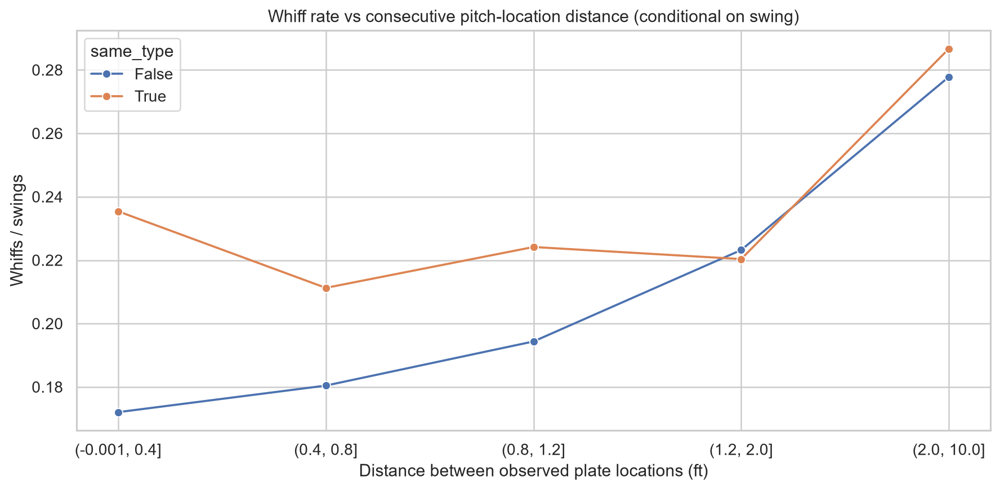

In [158]:
seq_loc=df.sort_values(['game_pk','at_bat_number','pitch_number']).copy()
lag_group=seq_loc.groupby(['game_pk','at_bat_number'],sort=False)
seq_loc['prev_pitch_type']=lag_group.pitch_type.shift(1)
seq_loc['prev_plate_x']=lag_group.plate_x.shift(1)
seq_loc['prev_plate_z']=lag_group.plate_z.shift(1)
seq_loc['prev_release_speed']=lag_group.release_speed.shift(1)
seq_loc=seq_loc.dropna(subset=['prev_pitch_type','prev_plate_x','prev_plate_z','plate_x','plate_z']).copy()
seq_loc['same_type']=seq_loc.pitch_type.eq(seq_loc.prev_pitch_type)
seq_loc['plate_distance_ft']=np.hypot(seq_loc.plate_x-seq_loc.prev_plate_x,seq_loc.plate_z-seq_loc.prev_plate_z)
seq_loc['velocity_delta']=seq_loc.release_speed-seq_loc.prev_release_speed
seq_loc['distance_bin']=pd.cut(seq_loc.plate_distance_ft,[0,.4,.8,1.2,2,10],include_lowest=True)
seq_data=(seq_loc.groupby(['same_type','distance_bin'],observed=True)
    .agg(n=('whiff_ind','size'),swings=('swing_ind','sum'),whiffs=('whiff_ind','sum'),mean_velocity_delta=('velocity_delta','mean')).reset_index())
seq_data['whiff_per_swing']=seq_data.whiffs/seq_data.swings.replace(0,np.nan)
v5_save(seq_data,'within_pa_location_change_and_whiff')
plot=seq_data.loc[seq_data.swings>=100].copy()
plot['distance_label']=plot['distance_bin'].astype(str)
if len(plot):
    fig,ax=plt.subplots(figsize=(10,5))
    sns.lineplot(data=plot,x='distance_label',y='whiff_per_swing',hue='same_type',marker='o',ax=ax)
    ax.set(title='Whiff rate vs consecutive pitch-location distance (conditional on swing)',ylabel='Whiffs / swings',xlabel='Distance between observed plate locations (ft)')
    fig.tight_layout();v5_figure(fig,'within_pa_location_change')

## 37 | Exit-Velocity Prediction Intervals

**Research question:** Can we estimate ranges, not just a point forecast, for exit velocity *conditional on a tracked in-play BBE*? Quantile regression offers an empirical 10–90% interval. Model development uses only 2024; the 2025 comparison is exploratory because that period has already been inspected.

In [159]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_pinball_loss
from sklearn.base import clone
quant_features=[c for c in ['pitch_type','stand','p_throws','balls','strikes','release_speed','release_spin_rate','pfx_x','pfx_z','plate_x','plate_z'] if c in batted]
quant_cat=[c for c in ['pitch_type','stand','p_throws'] if c in quant_features]
quant_num=[c for c in quant_features if c not in quant_cat]
def quant_pre():
    return ColumnTransformer([
       ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                        ('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),quant_cat),
       ('num',Pipeline([('impute',SimpleImputer(strategy='median')),
                        ('scale',StandardScaler())]),quant_num)
    ],sparse_threshold=0)
q2024=batted.loc[batted.season.eq(2024)].sort_values('game_date').copy()
q2025=batted.loc[batted.season.eq(2025)].sort_values('game_date').copy()
qdays=q2024.game_date.drop_duplicates().sort_values()
quantile_models={}
if len(qdays)>=5 and len(q2024)>=400 and len(q2025)>=100:
    qcut=qdays.iloc[max(0,int(len(qdays)*.75)-1)]
    qt=q2024.loc[q2024.game_date.le(qcut)]
    qv=q2024.loc[q2024.game_date.gt(qcut)]
    qrows=[]
    for tau in [.1,.5,.9]:
        algo=HistGradientBoostingRegressor(loss='quantile',quantile=tau,max_iter=85,
                                          max_leaf_nodes=15,min_samples_leaf=35,random_state=42)
        pipe=Pipeline([('prep',quant_pre()),('model',algo)])
        pipe.fit(qt[quant_features],qt.launch_speed)
        pp=pipe.predict(qv[quant_features]);quantile_models[tau]=pipe
        qrows.append({'quantile':tau,'n_validation':len(qv),'pinball_loss':mean_pinball_loss(qv.launch_speed,pp,alpha=tau)})
    q_validation=v5_save(pd.DataFrame(qrows),'ev_quantile_2024_validation')
    qlo=quantile_models[.1].predict(qv[quant_features]); qhi=quantile_models[.9].predict(qv[quant_features])
    low,high=np.minimum(qlo,qhi),np.maximum(qlo,qhi)
    print('2024 validation 80% interval coverage:',round(float(np.mean((qv.launch_speed>=low)&(qv.launch_speed<=high))),4))
else:
    print('Insufficient tracked 2024 BBE for quantile research.')

,quantile,n_validation,pinball_loss
0,0.1,2984,3.1096
1,0.5,2984,5.3060
2,0.9,2984,1.8750


2024 validation 80% interval coverage: 0.7359


,n,interval_coverage,mean_width_mph,median_prediction_MAE
0,9824,0.7389,29.4723,10.2997


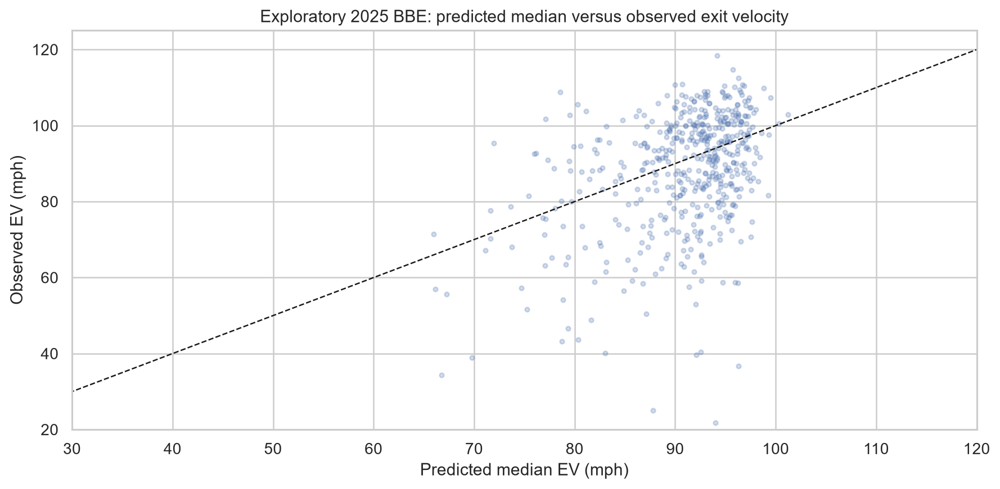

In [160]:
if len(quantile_models)==3:
    qexplore=[];prediction={}
    for tau in [.1,.5,.9]:
        prediction[tau]=quantile_models[tau].predict(q2025[quant_features])
        qexplore.append({'quantile':tau,'pinball_loss':mean_pinball_loss(q2025.launch_speed,prediction[tau],alpha=tau)})
    lower=np.minimum(prediction[.1],prediction[.9]);upper=np.maximum(prediction[.1],prediction[.9])
    eval_2025={'n':len(q2025),'interval_coverage':np.mean((q2025.launch_speed>=lower)&(q2025.launch_speed<=upper)),
               'mean_width_mph':np.mean(upper-lower),'median_prediction_MAE':np.mean(np.abs(q2025.launch_speed-prediction[.5]))}
    v5_save(pd.DataFrame([eval_2025]),'ev_quantile_2025_exploratory')
    draw=np.random.default_rng(42).choice(len(q2025),size=min(500,len(q2025)),replace=False)
    fig,ax=plt.subplots(figsize=(10,5))
    ax.scatter(prediction[.5][draw],q2025.launch_speed.to_numpy()[draw],s=10,alpha=.25)
    ax.plot([0,120],[0,120],'k--',lw=1)
    ax.set(xlim=(30,120),ylim=(20,125),xlabel='Predicted median EV (mph)',ylabel='Observed EV (mph)',
           title='Exploratory 2025 BBE: predicted median versus observed exit velocity')
    fig.tight_layout();v5_figure(fig,'ev_quantile_2025_scatter')

## 38 | Strictly Time-Ordered Probability Calibration

**Research question:** Can 2024-only calibration improve held-out probability accuracy? Data are split into early fit, middle calibration, and late evaluation. The same date never appears in two partitions. Isotonic regression can overfit short samples; report alongside a Platt logistic calibrator and raw probabilities. The 2025 window stays exploratory.

,method,n_eval,ROC_AUC,PR_AUC,Brier,LogLoss
0,Raw,17190,0.7172,0.2140,0.0914,0.3149
1,Platt,17190,0.7172,0.2140,0.0922,0.3205
2,Isotonic,17190,0.7157,0.2027,0.0914,0.3140


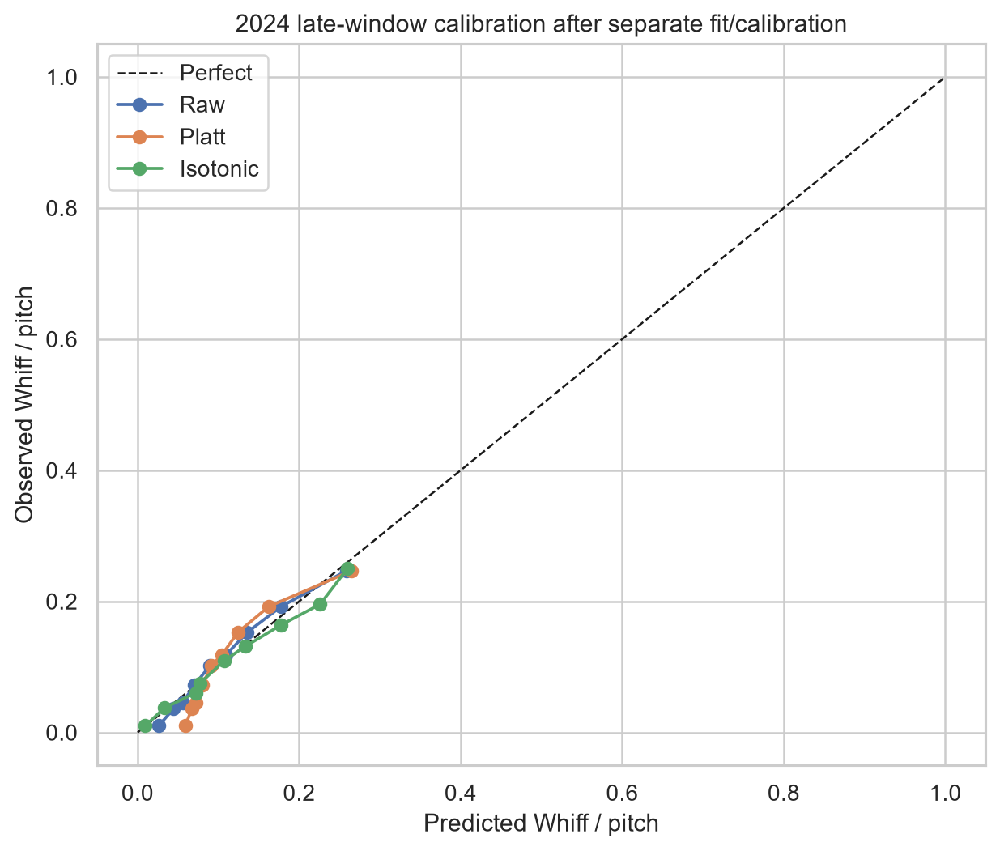

In [161]:
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from sklearn.base import clone
caldays=train_all.game_date.drop_duplicates().sort_values()
if len(caldays)>=9:
    cut_a=caldays.iloc[max(0,int(len(caldays)*.5)-1)]
    cut_b=caldays.iloc[max(1,int(len(caldays)*.75)-1)]
    cal_fit=train_all.loc[train_all.game_date<=cut_a]
    cal_cal=train_all.loc[(train_all.game_date>cut_a)&(train_all.game_date<=cut_b)]
    cal_eval=train_all.loc[train_all.game_date>cut_b]
    if len(cal_fit)>300 and len(cal_cal)>200 and len(cal_eval)>200:
        raw_model=Pipeline([('prep',make_preprocess()),('model',HistGradientBoostingClassifier(
            max_iter=90,max_leaf_nodes=18,min_samples_leaf=35,random_state=42))])
        raw_model.fit(cal_fit[feature_cols],cal_fit.whiff_ind.astype(int))
        p_cal=raw_model.predict_proba(cal_cal[feature_cols])[:,1]
        p_eval=raw_model.predict_proba(cal_eval[feature_cols])[:,1]
        platt=LogisticRegression(max_iter=500).fit(p_cal.reshape(-1,1),cal_cal.whiff_ind)
        isotonic=IsotonicRegression(out_of_bounds='clip').fit(p_cal,cal_cal.whiff_ind)
        calibrations={'Raw':p_eval,
                      'Platt':platt.predict_proba(p_eval.reshape(-1,1))[:,1],
                      'Isotonic':isotonic.predict(p_eval)}
        calibrated_v5=v5_save(pd.DataFrame([{'method':k,'n_eval':len(cal_eval),**score(cal_eval.whiff_ind,p)}
                              for k,p in calibrations.items()]),'nested_2024_calibration')
        fig,ax=plt.subplots(figsize=(7,6));ax.plot([0,1],[0,1],'k--',lw=1,label='Perfect')
        from sklearn.calibration import calibration_curve
        for k,p in calibrations.items():
            frac,pred=calibration_curve(cal_eval.whiff_ind,p,n_bins=9,strategy='quantile')
            ax.plot(pred,frac,marker='o',label=k)
        ax.set(xlabel='Predicted Whiff / pitch',ylabel='Observed Whiff / pitch',title='2024 late-window calibration after separate fit/calibration')
        ax.legend();fig.tight_layout();v5_figure(fig,'strict_2024_probability_calibration')
else:
    print('Too few dates for strict three-way calibration design.')

## 39 | Batter and Pitcher Reliability: Game-Clustered Residual Intervals

**Research question:** Which established players show consistent positive/negative *observed minus predicted* Whiff rates? This is descriptive model residual analysis. To account for within-game dependence, resample games rather than treating every pitch as independent. Interpretation is conditional on the existing model and 2025 exploratory sample.

,player_id,n,n_games,observed,expected,gap,role
0,455117,73,7,0.1781,0.1106,0.0675,batter
1,457705,177,13,0.0847,0.1173,-0.0325,batter
2,457759,86,8,0.0814,0.1004,-0.0190,batter
3,467793,209,12,0.0909,0.1030,-0.0121,batter
4,502054,83,5,0.0723,0.1133,-0.0410,batter
5,502671,178,12,0.0618,0.1202,-0.0584,batter
6,514888,160,11,0.0812,0.1054,-0.0241,batter
7,516782,73,6,0.0548,0.1007,-0.0460,batter
8,518595,95,7,0.1895,0.1286,0.0609,batter
9,518692,210,12,0.1429,0.1124,0.0304,batter


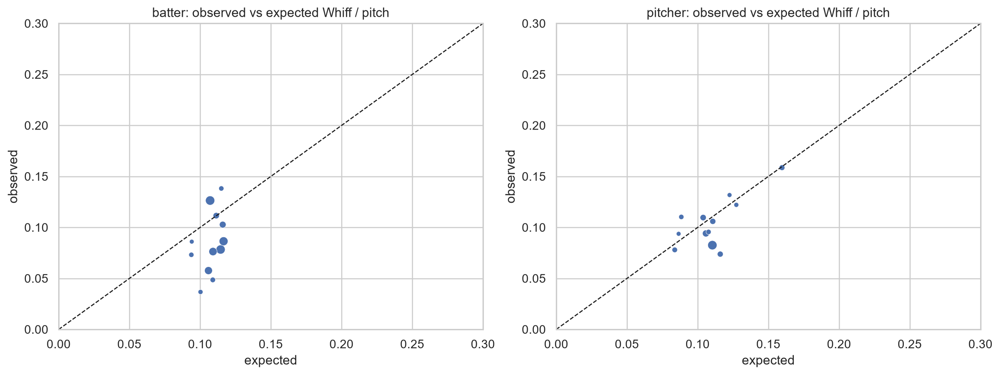

In [162]:
resid=hold[['game_pk','batter','pitcher','pitch_type']].copy()
resid['actual']=np.asarray(hold_y,dtype=float);resid['predicted']=np.asarray(hold_p,dtype=float)
resid['residual']=resid.actual-resid.predicted
player_rows=[]
for who in ['batter','pitcher']:
    summary=(resid.groupby(who).agg(n=('actual','size'),n_games=('game_pk','nunique'),observed=('actual','mean'),
                                     expected=('predicted','mean'),gap=('residual','mean')).reset_index())
    summary=summary.loc[(summary.n>=70)&(summary.n_games>=4)].copy()
    summary['role']=who
    player_rows.append(summary.rename(columns={who:'player_id'}))
player_residual=v5_save(pd.concat(player_rows,ignore_index=True),'player_observed_minus_expected_whiff')
if not player_residual.empty:
    top=player_residual.sort_values('n',ascending=False).groupby('role').head(12)
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    for ax,(role,g) in zip(axes,top.groupby('role')):
        sns.scatterplot(data=g,x='expected',y='observed',size='n',ax=ax,legend=False)
        ax.plot([0,1],[0,1],'k--',lw=1);ax.set(title=f'{role}: observed vs expected Whiff / pitch',xlim=(0,.30),ylim=(0,.30))
    fig.tight_layout();v5_figure(fig,'player_observed_vs_expected')

In [163]:
rng=np.random.default_rng(42)
keep=player_residual.loc[player_residual.n>=100].sort_values('n',ascending=False).groupby('role').head(5)
bootstrap_rows=[]
for row in keep.itertuples():
    part=resid.loc[resid[row.role].eq(row.player_id)]
    per_game=part.groupby('game_pk').residual.agg(total='sum',n='size')
    if len(per_game)<4:continue
    values=per_game[['total','n']].to_numpy()
    ids=rng.integers(0,len(values),size=(300,len(values)))
    samples=values[ids]
    gaps=samples[:,:,0].sum(axis=1)/samples[:,:,1].sum(axis=1)
    bootstrap_rows.append({'role':row.role,'player_id':row.player_id,'n_pitches':len(part),'n_games':len(per_game),
                           'gap':part.residual.mean(),'ci_025':np.quantile(gaps,.025),'ci_975':np.quantile(gaps,.975)})
player_ci=v5_save(pd.DataFrame(bootstrap_rows),'player_residual_game_bootstrap') if bootstrap_rows else pd.DataFrame()

,role,player_id,n_pitches,n_games,gap,ci_025,ci_975
0,batter,621566,269,13,0.0193,-0.0155,0.0544
1,batter,624413,268,13,-0.0361,-0.0609,-0.0035
2,batter,663697,266,13,-0.0301,-0.0541,-0.0067
3,batter,682998,262,14,-0.0328,-0.0762,0.0039
4,batter,665742,260,12,-0.0482,-0.0796,-0.0132
5,pitcher,695418,230,4,-0.0278,-0.0618,0.0532
6,pitcher,450203,170,4,-0.0117,-0.0614,0.0243
7,pitcher,671131,155,6,0.0058,-0.0237,0.0394
8,pitcher,806185,151,4,-0.0047,-0.0513,0.0254
9,pitcher,605130,149,7,-0.0422,-0.0583,-0.0261


## 40 | Research Interpretation and Reproducibility Gate

The next table distinguishes **executed estimates** from research limitations. The sample window is not representative of a full season; observational associations cannot establish causal coaching recommendations. In particular, 2025 has already been used repeatedly in iterative model development.

In [164]:
v5_checks={
    'pitch_keys_unique':not df.duplicated(['game_pk','at_bat_number','pitch_number']).any(),
    'whiffs_subset_of_swings':bool((df.whiff_ind<=df.swing_ind).all()),
    'hard_hit_conditioned_on_measured_bbe':bool((df.hard_hit.notna()==(df.type.eq('X')&df.launch_speed.notna())).all()),
    'validation_ordered':bool(tr.game_date.max()<va.game_date.min()),
    '2025_separate_from_2024':bool(train_all.game_date.max()<hold.game_date.min()),
    'selected_model_2024_only':bool(selected_name in validation.model.values),
    'two_weeks_only':bool(SAMPLE_MODE)
}
checks_df=pd.DataFrame([{'check':k,'value':bool(v)} for k,v in v5_checks.items()])
v5_save(checks_df,'research_integrity_gate')
assert all(v for k,v in v5_checks.items() if k!='two_weeks_only'),v5_checks
v5_study={
   'v5_version':'Research V5', 'source_notebook':'MLB_Pitch_Intelligence_Research_V4_Audited(1).ipynb',
   'years':sorted(df.season.dropna().astype(int).unique().tolist()),
   'date_span':{str(y):[str(p.game_date.min().date()),str(p.game_date.max().date())] for y,p in df.groupby('season')},
   'n_pitches':int(len(df)), 'n_games':int(df.game_pk.nunique()),
   'main_whiff_model':selected_name,
   'analysis_warning':'2025 estimates are exploratory because the period was repeatedly examined during prior model iterations.',
   'target_warning':'Exit velocity / hard-hit models condition on measured BBE; they do not quantify all-pitch hard-hit risk.'
}
import json
(V5_DIR/'study_manifest.json').write_text(json.dumps(v5_study,indent=2),encoding='utf-8')
print('Completed V5 integrity gate. Figures and tables:',V5_DIR)
print('Figures:',len(list(FIGDIR.glob('v5_*.png'))))
print('Tables:',len(list(V5_DIR.glob('*.csv'))))

,check,value
0,pitch_keys_unique,True
1,whiffs_subset_of_swings,True
2,hard_hit_conditioned_on_measured_bbe,True
3,validation_ordered,True
4,2025_separate_from_2024,True
5,selected_model_2024_only,True
6,two_weeks_only,True


Completed V5 integrity gate. Figures and tables: I:\Potforlio\MLB Analytics\outputs\research_v5
Figures: 10
Tables: 14


### Historical data provenance and BBE eligibility

Historical BBE and barrel calculations distinguish known launch-speed-angle classifications from unclassified events. An unclassified ball in play is not treated as a confirmed non-barrel. Data are collected and cached in date chunks. The executed sample-mode results use August 10–16 of each year, not full-season statistics.


# Division IV — Historical MLB Analysis (2015–2026)

*This division contains detailed technical experiments; the submission report selects the most defensible results.*

# Part 41 | Historical Statcast Research: 2015–2026

**Population:** Statcast regular-season pitches. `sample` mode downloads **August 10–16 each year** (including the shortened 2020 season); `full` mode requests regular-season date windows and excludes non-regular-season games. In sample mode, all trend analyses describe those August windows only. Technical tracking eras, changing pitch-type labels, rule changes and 2026 pitch-coordinate conventions limit direct year-to-year comparisons. Model-sample rows are a subset of the season aggregates.

In [165]:
"""Historical MLB pitch research tools (2015–2026). No downloads occur on import."""
from __future__ import annotations
from collections import defaultdict
from datetime import timedelta
from pathlib import Path
from time import sleep
import json
import numpy as np
import pandas as pd

YEARS = tuple(range(2015, 2027))
SWING = {'swinging_strike', 'swinging_strike_blocked', 'swinging_pitchout',
         'foul', 'foul_tip', 'hit_into_play', 'foul_bunt', 'missed_bunt',
         'bunt_foul_tip', 'foul_pitchout'}
WHIFF = {'swinging_strike', 'swinging_strike_blocked', 'swinging_pitchout', 'missed_bunt'}
CALLED = {'called_strike'}
KEY = ['game_pk', 'at_bat_number', 'pitch_number']
NUM = ['release_speed', 'release_spin_rate', 'pfx_x', 'pfx_z', 'plate_x', 'plate_z',
       'launch_speed', 'launch_angle', 'launch_speed_angle', 'balls', 'strikes',
       'sz_top', 'sz_bot', 'zone', 'delta_run_exp']
TEXT = ['description', 'pitch_type', 'p_throws', 'stand', 'type', 'game_type']
SAMPLE_FEATURES = ['pitch_type', 'stand', 'p_throws', 'balls', 'strikes', 'release_speed',
                   'release_spin_rate', 'pfx_x', 'pfx_z', 'plate_x', 'plate_z']
COUNTS = ['pitches', 'swings', 'whiffs', 'called', 'outzone', 'chases', 'bbe', 'bbe_ev',
          'hard_hits', 'barrels', 'barrel_n', 'vel_n', 'vel_sum', 'spin_n', 'spin_sum', 'ev_n', 'ev_sum',
          'movement_n', 'movement_sum', 'run_n', 'run_sum']
GROUPS = {'season': ['season'], 'pitch': ['season', 'pitch_type'],
          'throwing_arm': ['season', 'p_throws'],
          'pitch_arm': ['season', 'pitch_type', 'p_throws'],
          'matchup': ['season', 'stand', 'p_throws'],
          'count': ['season', 'balls', 'strikes'],
          'pitcher': ['season', 'pitcher'],
          'pitcher_pitch': ['season', 'pitcher', 'pitch_type'],
          'batter': ['season', 'batter'],
          'batter_pitch': ['season', 'batter', 'pitch_type'],
          'month': ['season', 'month']}


def season_window(year: int, mode: str = 'sample'):
    if year not in YEARS:
        raise ValueError('Supported standard Statcast research years: 2015–2026')
    if mode == 'sample':
        return pd.Timestamp(f'{year}-08-10'), pd.Timestamp(f'{year}-08-16')
    if mode == 'full':
        return pd.Timestamp(f'{year}-03-15'), pd.Timestamp(f'{year}-10-10')
    raise ValueError('mode must be sample or full')


def prepare_pitch_frame(raw: pd.DataFrame, year: int | None = None) -> pd.DataFrame:
    """Consistent denominators; does not drop rows for missing physical measures."""
    if raw is None or raw.empty:
        return pd.DataFrame()
    d = raw.copy()
    if 'game_type' in d:
        d = d.loc[d['game_type'].eq('R')].copy()
    if d.empty:
        return d
    if all(k in d for k in KEY):
        d = d.drop_duplicates(KEY).copy()
    if 'game_date' not in d:
        raise ValueError('game_date is required')
    d['game_date'] = pd.to_datetime(d['game_date'], errors='coerce')
    d = d[d['game_date'].notna()].copy()
    d['season'] = d['game_date'].dt.year.astype(int)
    if year is not None:
        d = d[d['season'].eq(year)].copy()
    if d.empty:
        return d
    for col in NUM:
        if col not in d:
            d[col] = np.nan
        d[col] = pd.to_numeric(d[col], errors='coerce')
    for col in TEXT:
        if col not in d:
            d[col] = pd.Series(pd.NA, index=d.index, dtype='object')
    for col in ['pitcher', 'batter', *KEY]:
        if col not in d:
            d[col] = pd.NA
    d['month'] = d['game_date'].dt.month
    desc = d['description'].fillna('')
    d['is_swing'] = desc.isin(SWING).astype('int8')
    d['is_whiff'] = desc.isin(WHIFF).astype('int8')
    d['is_called'] = desc.isin(CALLED).astype('int8')
    d['out_known'] = d['zone'].isin([*range(1, 10), 11, 12, 13, 14])
    in_zone = d['zone'].between(1, 9)
    fallback = d[['plate_x','plate_z','sz_top','sz_bot']].notna().all(axis=1)
    d['out_known'] = d['out_known'] | fallback
    # Do not override a valid Statcast zone with the geometric approximation.
    geo_out = (d['plate_x'].abs().gt(0.83) | d['plate_z'].lt(d['sz_bot']) |
               d['plate_z'].gt(d['sz_top']))
    outzone = pd.Series(False, index=d.index)
    outzone.loc[d['zone'].isin([11,12,13,14])] = True
    use_geo = ~d['zone'].isin([*range(1, 10), 11, 12, 13, 14]) & fallback
    outzone.loc[use_geo] = geo_out.loc[use_geo]
    d['outzone'] = d['out_known'] & outzone
    d['chase'] = (d['outzone'] & d['is_swing'].eq(1)).astype('int8')
    d['is_bbe'] = d['type'].eq('X').fillna(False).astype(bool)
    d['tracked_bbe'] = (d['is_bbe'] & d['launch_speed'].notna()).fillna(False).astype(bool)
    d['hard_hit'] = (d['tracked_bbe'] & d['launch_speed'].ge(95).fillna(False)).astype(bool)
    d['barrel_known'] = (d['tracked_bbe'] & d['launch_speed_angle'].notna()).astype(bool)
    d['barrel'] = (d['barrel_known'] & d['launch_speed_angle'].eq(6).fillna(False)).astype(bool)
    return d


def aggregate_pitch_frame(d: pd.DataFrame, grouping: list[str]) -> pd.DataFrame:
    if d is None or d.empty:
        return pd.DataFrame(columns=grouping + COUNTS)
    d = d.copy()
    d['pitches'] = 1
    d['swings'] = d['is_swing'].astype('int32')
    d['whiffs'] = d['is_whiff'].astype('int32')
    d['called'] = d['is_called'].astype('int32')
    d['outzone_n'] = d['outzone'].astype('int32')
    d['chases'] = d['chase'].astype('int32')
    d['bbe_n'] = d['is_bbe'].astype('int32')
    d['bbe_ev_n'] = d['tracked_bbe'].astype('int32')
    d['hard_hits'] = d['hard_hit'].astype('int32')
    d['barrels'] = d['barrel'].fillna(False).astype('int32')
    d['barrel_n'] = d['barrel_known'].astype('int32')
    d['vel_n'] = d['release_speed'].notna().astype('int32')
    d['vel_sum'] = d['release_speed'].fillna(0)
    d['spin_n'] = d['release_spin_rate'].notna().astype('int32')
    d['spin_sum'] = d['release_spin_rate'].fillna(0)
    d['ev_n'] = d['launch_speed'].where(d['is_bbe']).notna().astype('int32')
    d['ev_sum'] = d['launch_speed'].where(d['is_bbe']).fillna(0)
    d['movement_n'] = d['pfx_x'].notna().astype('int32')
    d['movement_sum'] = d['pfx_x'].fillna(0)
    d['run_n'] = d['delta_run_exp'].notna().astype('int32')
    d['run_sum'] = d['delta_run_exp'].fillna(0)
    metric_cols = ['pitches','swings','whiffs','called','outzone_n','chases','bbe_n','bbe_ev_n','hard_hits','barrels','barrel_n',
                   'vel_n','vel_sum','spin_n','spin_sum','ev_n','ev_sum','movement_n','movement_sum','run_n','run_sum']
    return d.groupby(grouping, observed=True, dropna=False)[metric_cols].sum().reset_index().rename(
        columns={'outzone_n':'outzone','bbe_n':'bbe','bbe_ev_n':'bbe_ev'})


def combine_aggregates(parts: list[pd.DataFrame], group: list[str]) -> pd.DataFrame:
    valid = [p for p in parts if p is not None and not p.empty]
    if not valid:
        return pd.DataFrame()
    z = pd.concat(valid, ignore_index=True)
    num = [x for x in COUNTS if x in z]
    return z.groupby(group, observed=True, dropna=False)[num].sum().reset_index()


def safe_ratio(a, b):
    return a / b.replace(0, np.nan)


def finalize_summary(t: pd.DataFrame) -> pd.DataFrame:
    if t.empty:
        return t
    t = t.copy()
    for name, numerator, denominator in [
        ('swing_rate','swings','pitches'), ('whiff_rate','whiffs','swings'),
        ('whiff_per_pitch','whiffs','pitches'), ('csw_rate',None,'pitches'),
        ('chase_rate','chases','outzone'), ('bbe_per_pitch','bbe','pitches'),
        ('hard_hit_rate','hard_hits','bbe_ev'), ('barrel_rate','barrels','barrel_n'),
        ('velocity','vel_sum','vel_n'), ('spin','spin_sum','spin_n'),
        ('exit_velocity','ev_sum','ev_n'), ('horizontal_break','movement_sum','movement_n'),
        ('run_expectancy_delta','run_sum','run_n')]:
        num = t['called'] + t['whiffs'] if name == 'csw_rate' else t[numerator]
        t[name] = safe_ratio(num, t[denominator])
    t['velocity_coverage'] = safe_ratio(t['vel_n'], t['pitches'])
    t['spin_coverage'] = safe_ratio(t['spin_n'], t['pitches'])
    t['bbe_ev_coverage'] = safe_ratio(t['bbe_ev'], t['bbe'])
    # Barrel availability requires separately audited launch_speed_angle coverage.
    return t


def project_year_metrics(t: pd.DataFrame) -> pd.DataFrame:
    return finalize_summary(t)


def _save_dataframe(frame: pd.DataFrame, base: Path) -> Path:
    base.parent.mkdir(parents=True, exist_ok=True)
    try:
        import pyarrow  # noqa: F401
        dest = base.with_suffix('.parquet')
        frame.to_parquet(dest, index=False)
    except ImportError:
        dest = base.with_suffix('.pkl.gz')
        frame.to_pickle(dest, compression='gzip')
    return dest


def _load_dataframe(base: Path) -> pd.DataFrame | None:
    p = base.with_suffix('.parquet')
    if p.exists():
        return pd.read_parquet(p)
    p = base.with_suffix('.pkl.gz')
    if p.exists():
        return pd.read_pickle(p, compression='gzip')
    return None


def _download_window(start: pd.Timestamp, end: pd.Timestamp, base: Path, downloader, retries=3, pause=1):
    previous = _load_dataframe(base)
    if previous is not None:
        return previous, False
    for attempt in range(retries):
        try:
            raw = downloader(start_dt=start.strftime('%Y-%m-%d'), end_dt=end.strftime('%Y-%m-%d'), verbose=False)
            if raw is None:
                raise RuntimeError('Downloader returned None')
            if len(raw):
                _save_dataframe(raw, base)
            return raw, True
        except Exception:
            if attempt == retries - 1:
                raise
            sleep(pause * (2 ** attempt))
    raise RuntimeError('Unreachable')


def collect_history(root: str | Path, years=YEARS, mode='sample', model_fraction=0.15,
                    max_model_rows_per_year=100_000, chunk_days=3, downloader=None, pause=0.6):
    """Download chunks and aggregate incrementally; return summary paths, not all raw pitches.

    Full seasons can take many hundreds of requests. A deterministic, uniformly randomized
    model sample is stored independently of the full-population aggregates.
    """
    if downloader is None:
        from pybaseball import statcast
        downloader = statcast
    if chunk_days < 1 or chunk_days > 3:
        raise ValueError('chunk_days must be 1–3 to avoid Savant query row limits')
    years = sorted(set(int(y) for y in years))
    if not years or not set(years).issubset(YEARS):
        raise ValueError('Select valid years from 2015 through 2026')
    if not 0 < model_fraction <= 1:
        raise ValueError('model_fraction must be in (0,1]')
    base = Path(root) / 'outputs' / 'history_2015_2026'
    raw_dir = base / 'raw_chunks'
    results_dir = base / ('sample' if mode == 'sample' else 'full')
    results_dir.mkdir(parents=True, exist_ok=True)
    parts = defaultdict(list)
    model_paths = {}
    qc = []
    for year in years:
        start, stop = season_window(year, mode)
        cursor = pd.Timestamp(start)
        stop = pd.Timestamp(stop)
        chunks = 0
        pitches = 0
        samples = []
        while cursor <= stop:
            last = min(cursor + timedelta(days=int(chunk_days) - 1), stop)
            basename = raw_dir / str(year) / f'{cursor:%Y%m%d}_{last:%Y%m%d}'
            chunk, from_api = _download_window(cursor, last, basename, downloader, pause=pause)
            d = prepare_pitch_frame(chunk, year)
            chunks += 1
            if not d.empty:
                pitches += len(d)
                for name, group in GROUPS.items():
                    parts[name].append(aggregate_pitch_frame(d, group))
                # Each pitch is independently sampled at the same fixed probability.
                # Samples are a modeling subset; full-population trends use only aggregates.
                select = d.sample(frac=model_fraction, random_state=year * 10000 + chunks)
                if len(select):
                    keep = [x for x in [*SAMPLE_FEATURES, 'season', 'game_date', 'game_pk', 'pitcher', 'batter',
                                        'is_whiff', 'is_swing', 'is_bbe', 'hard_hit', 'tracked_bbe'] if x in select]
                    samples.append(select[keep])
            cursor = pd.Timestamp(last) + timedelta(days=1)
            if from_api and pause:
                sleep(pause)
        sample = pd.concat(samples, ignore_index=True) if samples else pd.DataFrame()
        if len(sample) > max_model_rows_per_year:
            sample = sample.sample(max_model_rows_per_year, random_state=year).reset_index(drop=True)
        sample_path = results_dir / 'model_samples' / f'{year}'
        if not sample.empty:
            model_paths[year] = str(_save_dataframe(sample, sample_path))
        qc.append({'season':year, 'mode':mode, 'start':str(start.date()),'end':str(stop.date()),
                   'chunks':chunks,'pitches':pitches,'sampled_pitches':len(sample)})
        print(f'{year}: {pitches:,} regular-season pitches, {chunks} windows, {len(sample):,} modeling rows')
    summary_files = {}
    for name, group in GROUPS.items():
        finalized = finalize_summary(combine_aggregates(parts[name], group))
        output = results_dir / f'{name}.csv'
        finalized.to_csv(output, index=False)
        summary_files[name] = str(output)
    audit = pd.DataFrame(qc)
    audit.to_csv(results_dir / 'download_audit.csv', index=False)
    manifest = {'mode':mode, 'years':years, 'requested_dates':audit[['season','start','end']].to_dict(orient='records'),
                'full_population_aggregates':summary_files, 'model_sample_files':model_paths,
                'model_sample_fraction':model_fraction,
                'warning':'Sample mode means August 10–16 only each year; it is not a full-season sample. '
                          '2015–16 PitchF/X, 2017+ Statcast, 2020+ Hawk-Eye vary in measurement systems.'}
    (results_dir / 'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf8')
    return results_dir


def load_history(results_dir: str | Path) -> dict[str, pd.DataFrame]:
    p = Path(results_dir)
    return {k:pd.read_csv(p/f'{k}.csv') for k in GROUPS if (p/f'{k}.csv').exists()}


def build_pitch_model_frame(results_dir: str | Path, years=range(2020,2027)) -> pd.DataFrame:
    p = Path(results_dir) / 'model_samples'
    frames = []
    for y in years:
        obj = _load_dataframe(p / str(y))
        if obj is not None and len(obj):
            frames.append(obj)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


In [166]:
from pathlib import Path
import os, sys, json
ROOT = Path(r'I:\Potforlio\MLB Analytics')
if not (ROOT / 'src' / 'pipeline.py').exists():
    candidates = [Path.cwd(), Path.cwd().parent, Path.cwd() / 'MLB_Pitch_Intelligence_Longitudinal_V7_Reviewed']
    ROOT = next((p for p in candidates if (p / 'src' / 'pipeline.py').exists()), ROOT)
if not ROOT.exists():
    raise FileNotFoundError('Set ROOT to the existing MLB Analytics project folder.')
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Image
from scipy.spatial.distance import jensenshannon
from statsmodels.stats.proportion import proportion_confint
sns.set_theme(style='whitegrid')
HISTORY_MODE = 'sample'  # 'sample': August 10–16; 'full': complete regular seasons
HISTORY_YEARS = list(range(2015, 2027))
HISTORY_DIR = ROOT / 'outputs' / 'history_2015_2026' / HISTORY_MODE
HISTORY_FIG_DIR = HISTORY_DIR / 'figures'
HISTORY_FIG_DIR.mkdir(parents=True, exist_ok=True)
def show_and_save_history(fig, name):
    path = HISTORY_FIG_DIR / (name + '.png')
    fig.savefig(path, dpi=175, bbox_inches='tight')
    display(Image(filename=str(path)))
    plt.close(fig)
    return path
print('Historical module embedded in Notebook; history_tools/ is optional.')
print('Period:', HISTORY_YEARS[0], '-', HISTORY_YEARS[-1], '| mode:', HISTORY_MODE)
print('Data and plots:', HISTORY_DIR)


Historical module embedded in Notebook; history_tools/ is optional.
Period: 2015 - 2026 | mode: sample
Data and plots: I:\Potforlio\MLB Analytics\outputs\history_2015_2026\sample


## 41.1 | Historical data collection and coverage

Downloads use 1–3-day chunks and disk caching. MLB requests may be slow; do not parallelize thousands of calls. Existing downloaded chunks are reused. Each seasonal rate is aggregated from numerator and denominator totals rather than averaged across dates.

In [167]:
HISTORY_DIR = collect_history(
    ROOT, years=HISTORY_YEARS, mode=HISTORY_MODE,
    model_fraction=0.15, max_model_rows_per_year=60_000,
    chunk_days=3, pause=0.6
)
hist = load_history(HISTORY_DIR)
annual = hist['season'].sort_values('season').reset_index(drop=True)
pitch_history = hist['pitch'].copy()
print('Source:', HISTORY_DIR)
display(pd.read_csv(HISTORY_DIR / 'download_audit.csv'))

2015: 26,317 regular-season pitches, 3 windows, 3,948 modeling rows
2016: 28,606 regular-season pitches, 3 windows, 4,291 modeling rows
2017: 28,978 regular-season pitches, 3 windows, 4,347 modeling rows
2018: 28,129 regular-season pitches, 3 windows, 4,219 modeling rows
2019: 28,373 regular-season pitches, 3 windows, 4,256 modeling rows
2020: 26,270 regular-season pitches, 3 windows, 3,941 modeling rows
2021: 29,042 regular-season pitches, 3 windows, 4,356 modeling rows
2022: 28,103 regular-season pitches, 3 windows, 4,215 modeling rows
2023: 27,123 regular-season pitches, 3 windows, 4,069 modeling rows
2024: 27,152 regular-season pitches, 3 windows, 4,073 modeling rows
2025: 27,373 regular-season pitches, 3 windows, 4,106 modeling rows
2026: 27,132 regular-season pitches, 3 windows, 4,070 modeling rows
Source: I:\Potforlio\MLB Analytics\outputs\history_2015_2026\sample


,season,mode,start,end,chunks,pitches,sampled_pitches
0,2015,sample,2015-08-10,2015-08-16,3,26317,3948
1,2016,sample,2016-08-10,2016-08-16,3,28606,4291
2,2017,sample,2017-08-10,2017-08-16,3,28978,4347
3,2018,sample,2018-08-10,2018-08-16,3,28129,4219
4,2019,sample,2019-08-10,2019-08-16,3,28373,4256
5,2020,sample,2020-08-10,2020-08-16,3,26270,3941
6,2021,sample,2021-08-10,2021-08-16,3,29042,4356
7,2022,sample,2022-08-10,2022-08-16,3,28103,4215
8,2023,sample,2023-08-10,2023-08-16,3,27123,4069
9,2024,sample,2024-08-10,2024-08-16,3,27152,4073


,season,pitches,vel_n,spin_n,bbe,bbe_ev,velocity_coverage,spin_coverage,bbe_ev_coverage
0,2015,26317,26316,24607,4933,4813,1.000,0.935,0.976
1,2016,28606,28598,26564,5195,5057,1.000,0.929,0.973
2,2017,28978,28813,28241,5073,4999,0.994,0.975,0.985
3,2018,28129,27945,27549,5060,4983,0.993,0.979,0.985
4,2019,28373,28239,27697,4972,4919,0.995,0.976,0.989
5,2020,26270,26227,26129,4570,4501,0.998,0.995,0.985
6,2021,29042,28603,28552,5014,4956,0.985,0.983,0.988
7,2022,28103,27727,27027,4887,4836,0.987,0.962,0.990
8,2023,27123,27059,26973,4737,4731,0.998,0.994,0.999
9,2024,27152,27094,27079,4671,4659,0.998,0.997,0.997


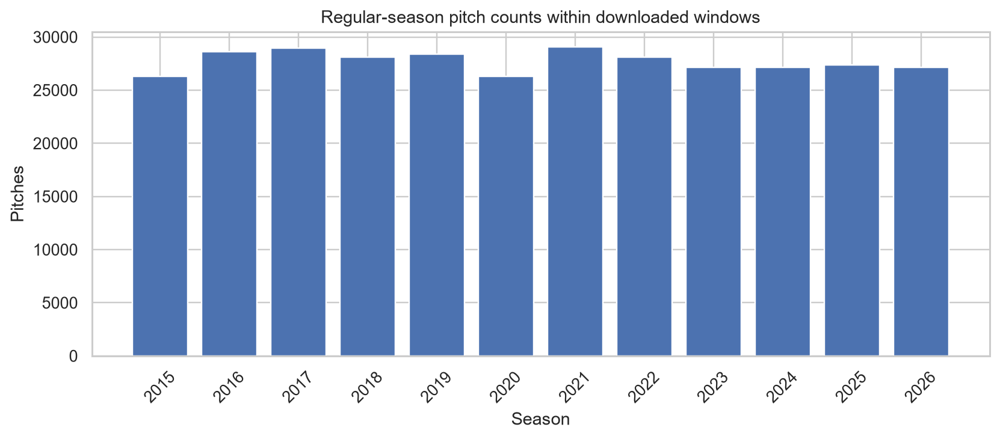

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_01_pitch_counts.png')

In [168]:
coverage_cols = ['season','pitches','vel_n','spin_n','bbe','bbe_ev','velocity_coverage','spin_coverage','bbe_ev_coverage']
display(annual[coverage_cols].round(3))
fig, ax = plt.subplots(figsize=(11,4))
ax.bar(annual.season.astype(str), annual.pitches)
ax.set(title='Regular-season pitch counts within downloaded windows', xlabel='Season', ylabel='Pitches')
ax.tick_params(axis='x', rotation=45)
show_and_save_history(fig, 'history_01_pitch_counts')

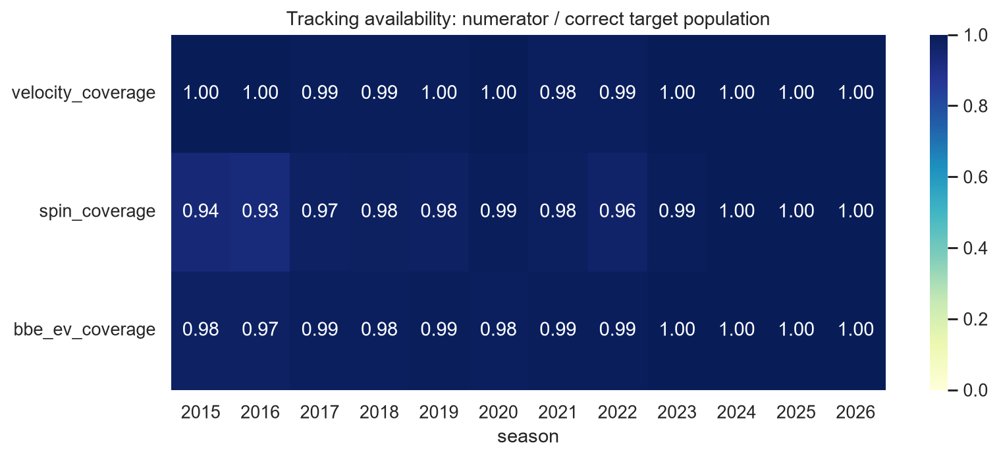

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_02_tracking_coverage.png')

In [169]:
coverage_map = annual.set_index('season')[['velocity_coverage','spin_coverage','bbe_ev_coverage']]
fig, ax = plt.subplots(figsize=(10,4))
sns.heatmap(coverage_map.T, annot=True, fmt='.2f', vmin=0, vmax=1, cmap='YlGnBu', ax=ax)
ax.set_title('Tracking availability: numerator / correct target population')
show_and_save_history(fig, 'history_02_tracking_coverage')

### Interpretation gate

A 2020 shortened season must not be compared using raw **counts** alone. In sample mode, all seasons represent August 10–16 rather than the season as a whole. Physical features must be checked for historical measurement changes and pitch classification drift. Bat tracking is a separate 2024+ data product and is **not** inferred from pitch-level CSV fields.

# Part 42 | Evolution of Pitch Design and League Strategy

**Questions:** How did pitch-type usage, velocity, spin, swing, whiff and chase rates change across years? Do comparisons survive weighting by event denominators?

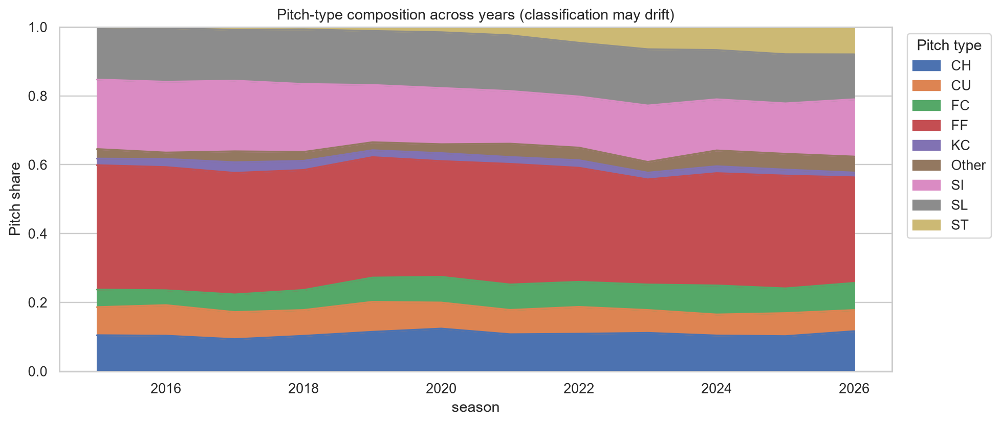

,season,family,pitches,share
3,2015,FF,9508,0.361
6,2015,SI,5316,0.202
7,2015,SL,4007,0.152
0,2015,CH,2752,0.105
1,2015,CU,2148,0.082
2,2015,FC,1345,0.051
5,2015,Other,731,0.028
4,2015,KC,502,0.019
8,2015,ST,8,0.000
12,2016,FF,10237,0.358


In [170]:
major = pitch_history.groupby('pitch_type')['pitches'].sum().nlargest(8).index.tolist()
pitch_mix = pitch_history.assign(family=lambda x: x.pitch_type.where(x.pitch_type.isin(major),'Other'))
pitch_mix = pitch_mix.groupby(['season','family'],as_index=False)['pitches'].sum()
pitch_mix['share'] = pitch_mix['pitches'] / pitch_mix.groupby('season')['pitches'].transform('sum')
fig, ax = plt.subplots(figsize=(12,5))
pitch_mix.pivot(index='season',columns='family',values='share').fillna(0).plot.area(ax=ax)
ax.set(title='Pitch-type composition across years (classification may drift)', ylabel='Pitch share', ylim=(0,1))
ax.legend(bbox_to_anchor=(1.01,1), loc='upper left', title='Pitch type')
show_and_save_history(fig,'history_03_pitch_mix')
display(pitch_mix.sort_values(['season','pitches'], ascending=[True,False]).head(30).round(3))

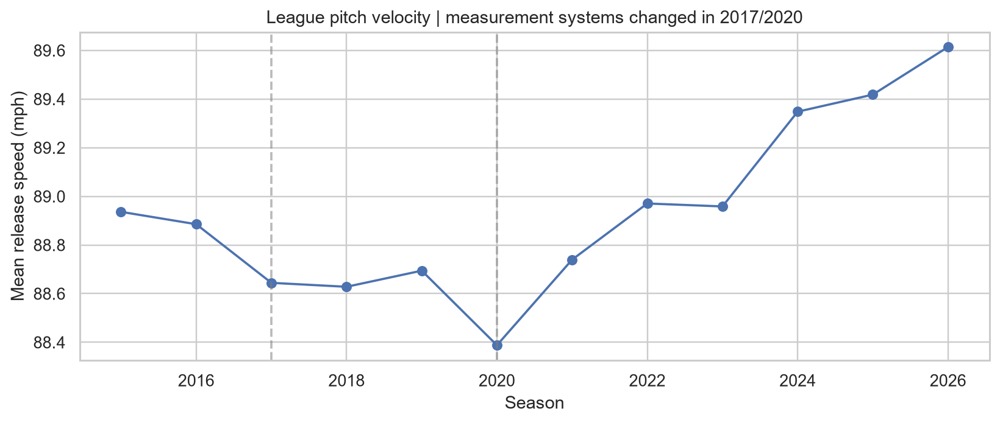

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_04_velocity_trend.png')

In [171]:
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(annual.season, annual.velocity, marker='o')
for year in [2017,2020]: ax.axvline(year, linestyle='--', color='gray', alpha=.55)
ax.set(title='League pitch velocity | measurement systems changed in 2017/2020',xlabel='Season',ylabel='Mean release speed (mph)')
show_and_save_history(fig,'history_04_velocity_trend')

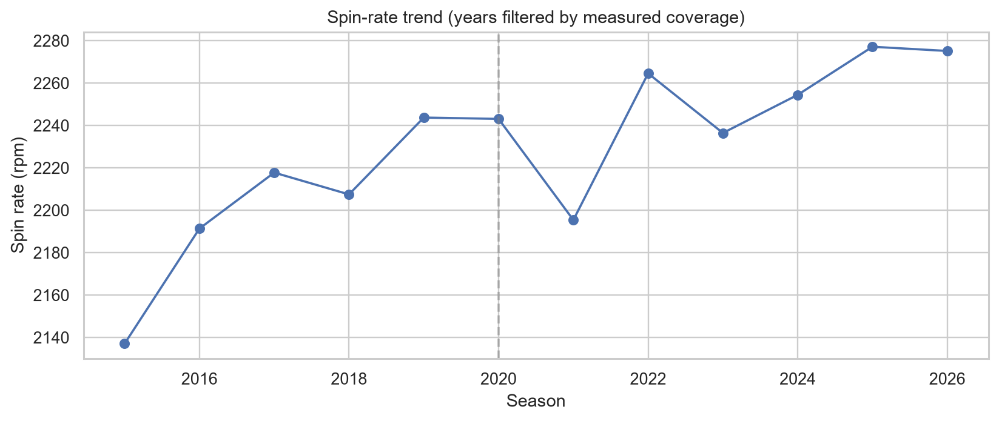

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_05_spin_trend.png')

In [172]:
fig, ax = plt.subplots(figsize=(11,4))
x=annual.loc[annual.spin_coverage>=.5]
ax.plot(x.season,x.spin,marker='o')
ax.axvline(2020,linestyle='--',color='gray',alpha=.5)
ax.set(title='Spin-rate trend (years filtered by measured coverage)',xlabel='Season',ylabel='Spin rate (rpm)')
show_and_save_history(fig,'history_05_spin_trend')

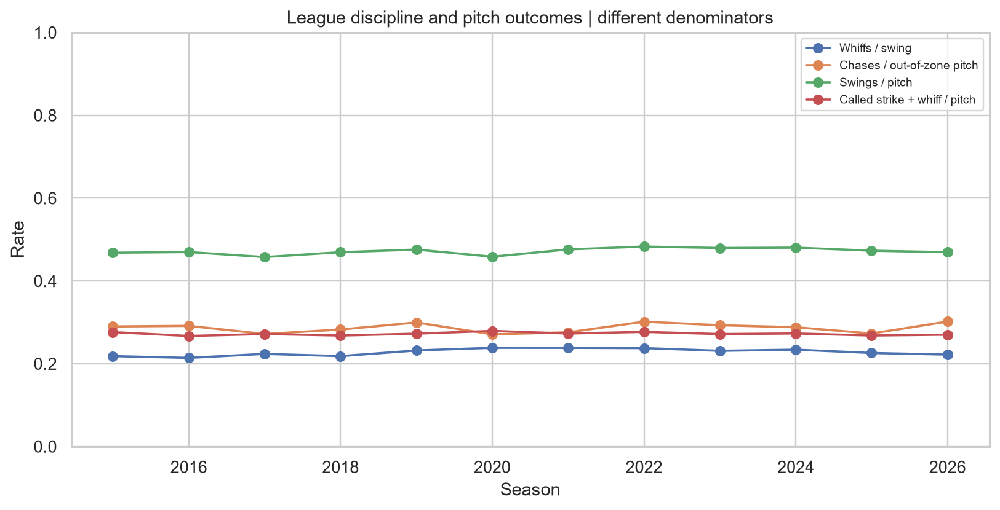

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_06_discipline_trends.png')

In [173]:
fig, ax = plt.subplots(figsize=(11,5))
for col, label in [('whiff_rate','Whiffs / swing'),('chase_rate','Chases / out-of-zone pitch'),
                   ('swing_rate','Swings / pitch'),('csw_rate','Called strike + whiff / pitch')]:
    ax.plot(annual.season,annual[col],marker='o',label=label)
ax.set(title='League discipline and pitch outcomes | different denominators',ylabel='Rate',xlabel='Season',ylim=(0,1))
ax.legend(fontsize=8)
show_and_save_history(fig,'history_06_discipline_trends')

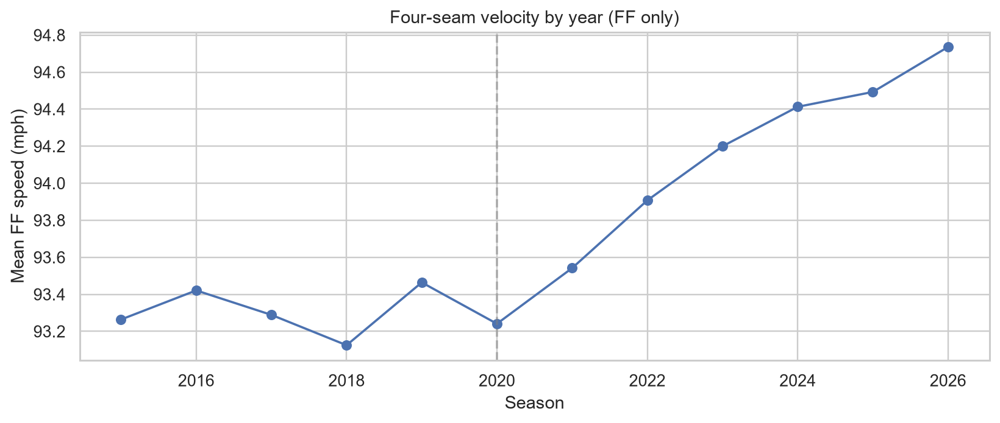

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_07_ff_velocity.png')

In [174]:
ff=pitch_history.query("pitch_type == 'FF' and vel_n >= 100").sort_values('season')
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(ff.season,ff.velocity,marker='o')
ax.axvline(2020,linestyle='--',color='gray',alpha=.5)
ax.set(title='Four-seam velocity by year (FF only)',xlabel='Season',ylabel='Mean FF speed (mph)')
show_and_save_history(fig,'history_07_ff_velocity')

,from,to,JS_distance
0,2015,2016,0.0452
1,2016,2017,0.0580
2,2017,2018,0.0306
3,2018,2019,0.0521
4,2019,2020,0.0303
5,2020,2021,0.0495
6,2021,2022,0.0541
7,2022,2023,0.0493
8,2023,2024,0.0497
9,2024,2025,0.0298


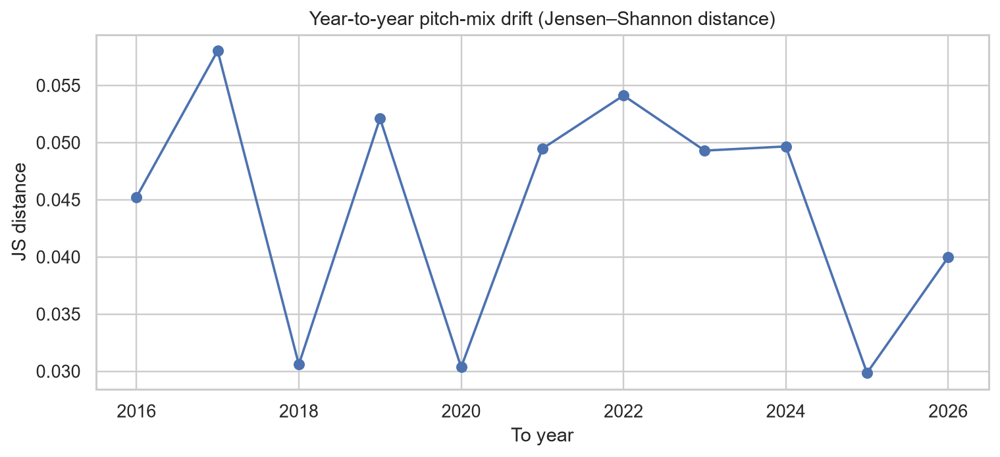

In [175]:
from scipy.stats import chi2_contingency
adjacent=[]
for a,b in zip(HISTORY_YEARS[:-1],HISTORY_YEARS[1:]):
    t=pitch_mix.pivot(index='season',columns='family',values='share').fillna(0)
    if a in t.index and b in t.index:
        adjacent.append({'from':a,'to':b,'JS_distance':float(jensenshannon(t.loc[a],t.loc[b],base=2))})
drift=pd.DataFrame(adjacent)
display(drift.round(4))
if len(drift):
    fig,ax=plt.subplots(figsize=(10,4));ax.plot(drift['to'],drift.JS_distance,marker='o')
    ax.set(title='Year-to-year pitch-mix drift (Jensen–Shannon distance)',xlabel='To year',ylabel='JS distance')
    show_and_save_history(fig,'history_08_pitch_mix_drift')

,season,observed_whiff_rate,fixed_2020_mix_whiff,covered_ref_weight
0,2015,0.2183,0.2220,1.0
1,2016,0.2141,0.2223,1.0
2,2017,0.2237,0.2326,1.0
3,2018,0.2184,0.2241,1.0
4,2019,0.2320,0.2342,1.0
5,2020,0.2385,0.2373,1.0
6,2021,0.2383,0.2378,1.0
7,2022,0.2377,0.2342,1.0
8,2023,0.2311,0.2270,1.0
9,2024,0.2339,0.2329,1.0


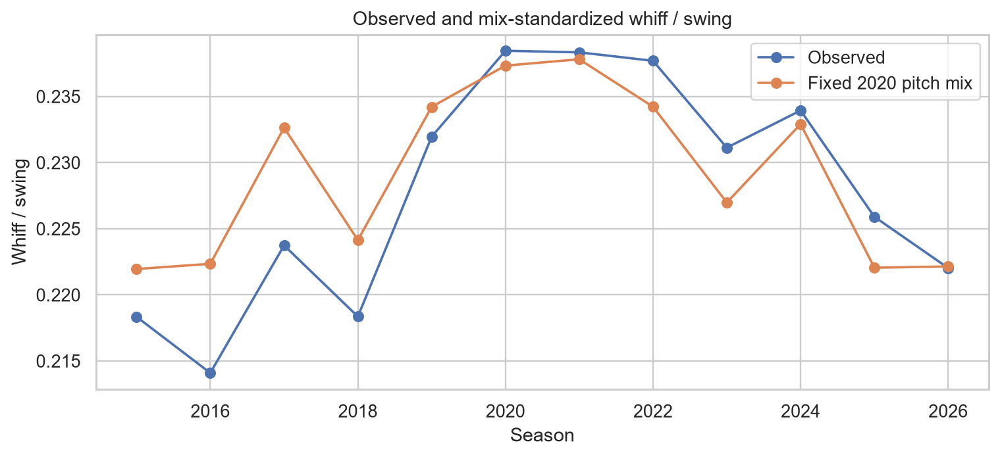

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_09_mix_standardized_whiff.png')

In [176]:
# A fixed reference pitch-type composition separates within-type changes from pitch-mix changes.
reference=pitch_mix.loc[pitch_mix.season.eq(2020),['family','share']].set_index('family')['share']
if reference.empty: reference=pitch_mix.groupby('family')['pitches'].sum().pipe(lambda s:s/s.sum())
comp=pitch_history.copy()
comp['family']=comp.pitch_type.where(comp.pitch_type.isin(major),'Other')
comp=comp.groupby(['season','family'],as_index=False)[['whiffs','swings']].sum()
comp['rate']=comp.whiffs/comp.swings.replace(0,np.nan)
fixed=[]
for y,g in comp.groupby('season'):
    m=g.set_index('family').rate.reindex(reference.index)
    ok=m.notna()
    fixed.append({'season':y,'observed_whiff_rate':annual.set_index('season').loc[y,'whiff_rate'],
                  'fixed_2020_mix_whiff':float(np.average(m[ok],weights=reference[ok])) if ok.any() else np.nan,
                  'covered_ref_weight':float(reference[ok].sum())})
standardized=pd.DataFrame(fixed);display(standardized.round(4))
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(standardized.season,standardized.observed_whiff_rate,marker='o',label='Observed')
ax.plot(standardized.season,standardized.fixed_2020_mix_whiff,marker='o',label='Fixed 2020 pitch mix')
ax.legend();ax.set(title='Observed and mix-standardized whiff / swing',xlabel='Season',ylabel='Whiff / swing')
show_and_save_history(fig,'history_09_mix_standardized_whiff')

# Part 43 | Longitudinal Hitter Analysis

**Questions:** Are observed changes in hitter whiff and chase rates due to different hitters entering MLB? How stable are individual players across seasons? Comparisons require adequate observed swings.

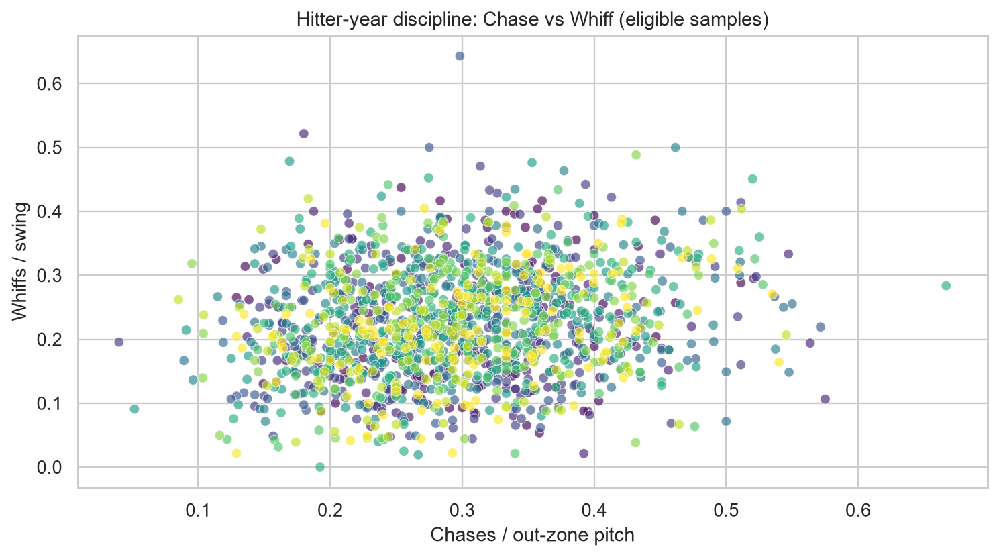

,eligible_hitters,median_chase,median_whiff
season,,,
2015,107,0.304348,0.227273
2016,141,0.309524,0.207547
2017,150,0.293611,0.218466
2018,126,0.277500,0.210420
2019,136,0.297560,0.225277
2020,108,0.282814,0.234043
2021,139,0.282609,0.228070
2022,138,0.301887,0.240690
2023,111,0.301887,0.223881


In [177]:
hitters=hist['batter'].copy()
eligible_hitters=hitters.query('swings >= 40 and outzone >= 40').copy()
fig,ax=plt.subplots(figsize=(10,5))
sns.scatterplot(data=eligible_hitters,x='chase_rate',y='whiff_rate',hue='season',palette='viridis',legend=False,alpha=.65,ax=ax)
ax.set(title='Hitter-year discipline: Chase vs Whiff (eligible samples)',xlabel='Chases / out-zone pitch',ylabel='Whiffs / swing')
show_and_save_history(fig,'history_10_hitter_chase_whiff')
display(eligible_hitters.groupby('season').agg(eligible_hitters=('batter','nunique'),median_chase=('chase_rate','median'),median_whiff=('whiff_rate','median')))

,paired_hitters,median_whiff_change
0,25,0.005968


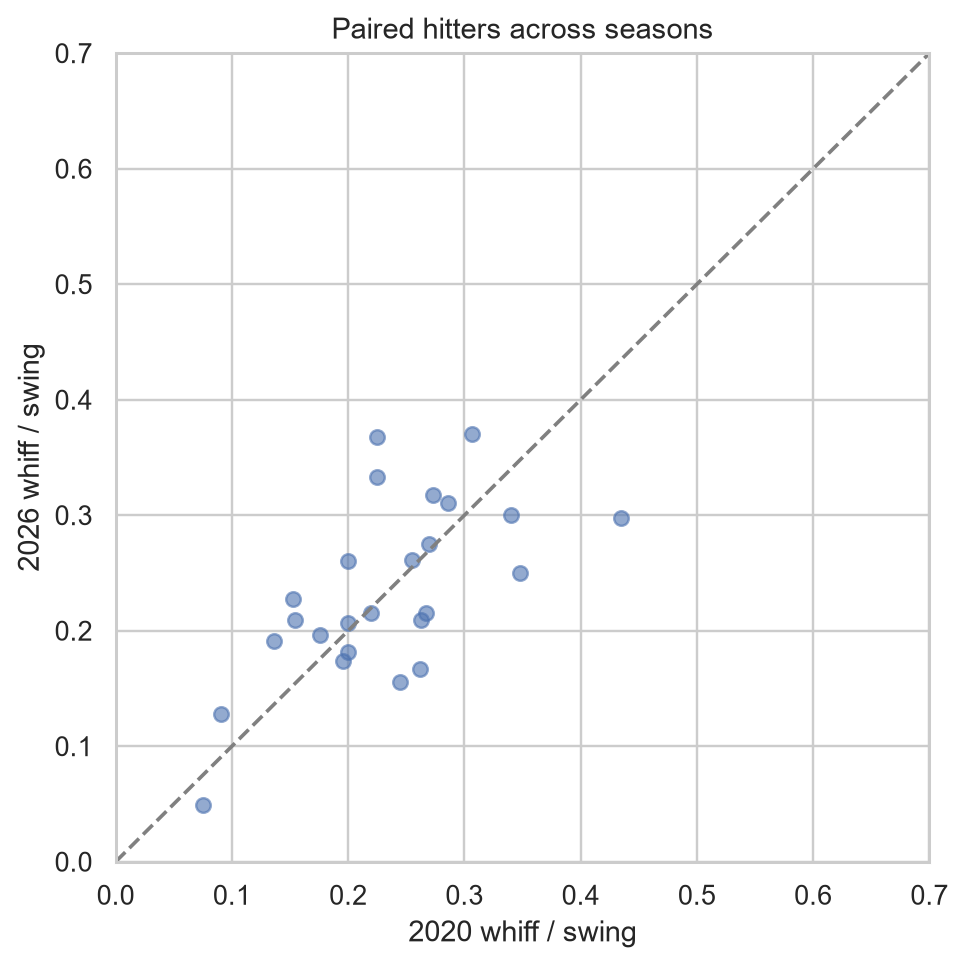

In [178]:
y1,y2=2020,2026
left=hitters.loc[(hitters.season.eq(y1)) & (hitters.swings>=40),['batter','whiff_rate','swings']].rename(columns={'whiff_rate':'early','swings':'n_early'})
right=hitters.loc[(hitters.season.eq(y2)) & (hitters.swings>=40),['batter','whiff_rate','swings']].rename(columns={'whiff_rate':'late','swings':'n_late'})
paired=left.merge(right,on='batter')
paired['delta']=paired.late-paired.early
display(pd.DataFrame({'paired_hitters':[len(paired)],'median_whiff_change':[paired.delta.median()]}) if len(paired) else pd.DataFrame({'note':['No batter met both period thresholds.']}))
if len(paired)>=5:
    fig,ax=plt.subplots(figsize=(6,6))
    ax.scatter(paired.early,paired.late,alpha=.6)
    ax.plot([0,1],[0,1],'--',color='gray')
    ax.set(xlim=(0,.7),ylim=(0,.7),xlabel=f'{y1} whiff / swing',ylabel=f'{y2} whiff / swing',title='Paired hitters across seasons')
    show_and_save_history(fig,'history_11_paired_hitters')

In [179]:
hp=hist['batter_pitch'].copy()
hp=hp.query('swings >= 30').sort_values('whiff_rate',ascending=False)
current=hp.loc[hp.season.eq(2026)]
display(current[['batter','pitch_type','swings','whiff_rate','chase_rate']].head(20).round(3))

,batter,pitch_type,swings,whiff_rate,chase_rate
32524,605137,FF,30,0.133,0.588


,from,to,n_prev,n_next,overlap,jaccard
0,2015,2016,121,153,65,0.311005
1,2016,2017,153,160,72,0.298755
2,2017,2018,160,146,76,0.330435
3,2018,2019,146,150,66,0.286957
4,2019,2020,150,124,61,0.286385
5,2020,2021,124,160,65,0.296804
6,2021,2022,160,153,62,0.247012
7,2022,2023,153,128,60,0.271493
8,2023,2024,128,138,63,0.310345
9,2024,2025,138,153,65,0.287611


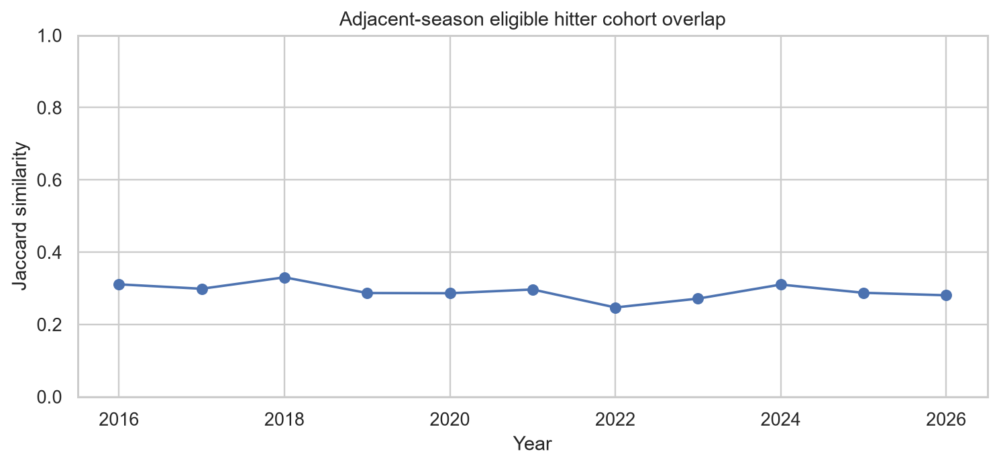

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_12_hitter_turnover.png')

In [180]:
cohorts={int(y):set(g.loc[g.swings>=40,'batter'].dropna().astype(str)) for y,g in hitters.groupby('season')}
turnover=[]
for prev,y in zip(HISTORY_YEARS[:-1],HISTORY_YEARS[1:]):
    a,b=cohorts.get(prev,set()),cohorts.get(y,set())
    turnover.append({'from':prev,'to':y,'n_prev':len(a),'n_next':len(b),
                     'overlap':len(a&b),'jaccard':len(a&b)/len(a|b) if a|b else np.nan})
turnover=pd.DataFrame(turnover);display(turnover)
fig,ax=plt.subplots(figsize=(10,4));ax.plot(turnover['to'],turnover.jaccard,marker='o')
ax.set(title='Adjacent-season eligible hitter cohort overlap',xlabel='Year',ylabel='Jaccard similarity',ylim=(0,1))
show_and_save_history(fig,'history_12_hitter_turnover')

# Part 44 | Longitudinal Pitcher & Pitch-Repertoire Research

**Question:** Are observed league-level trends present within the same pitchers, or largely due to changing pitcher composition? Small-count seasons are excluded from player trends.

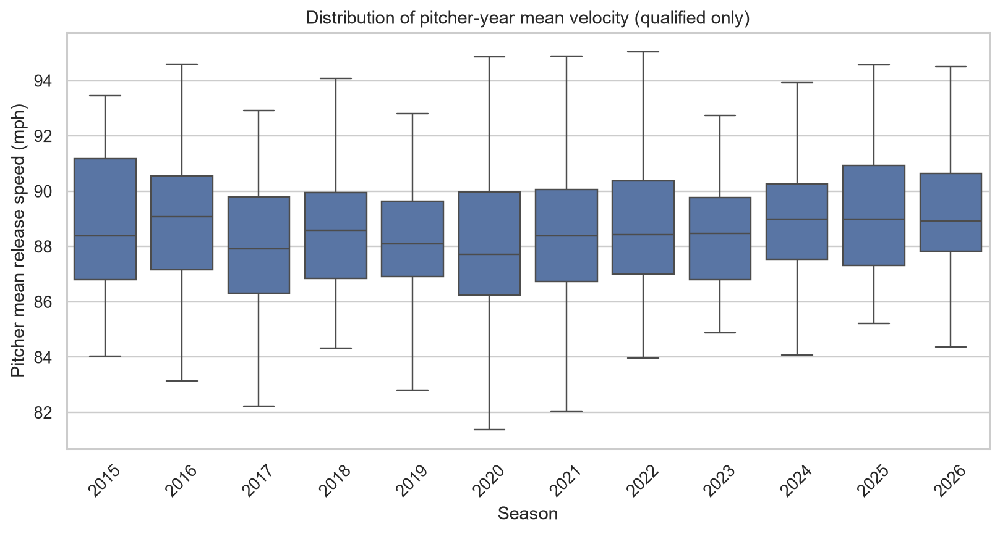

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_13_pitcher_year_velocity.png')

In [181]:
pitchers=hist['pitcher'].copy()
qual=pitchers.query('vel_n >= 100')
fig,ax=plt.subplots(figsize=(11,5))
sns.boxplot(data=qual,x='season',y='velocity',showfliers=False,ax=ax)
ax.set(title='Distribution of pitcher-year mean velocity (qualified only)',xlabel='Season',ylabel='Pitcher mean release speed (mph)')
ax.tick_params(axis='x',rotation=45)
show_and_save_history(fig,'history_13_pitcher_year_velocity')

,entropy,main_share,distinct_types
season,,,
2015,1.321,0.442,5.0
2016,1.295,0.463,5.0
2017,1.324,0.425,5.0
2018,1.294,0.457,5.0
2019,1.288,0.407,4.0
2020,1.296,0.441,5.0
2021,1.241,0.458,4.0
2022,1.284,0.402,4.0
2023,1.355,0.417,5.0


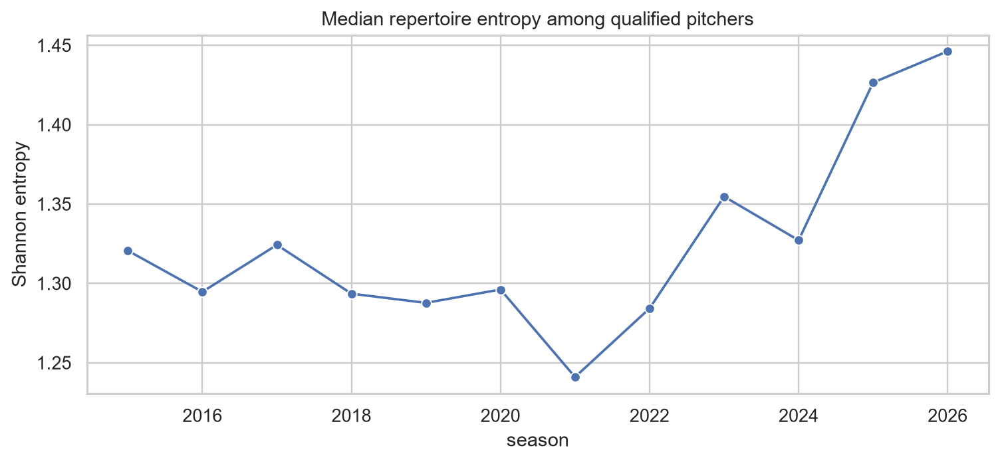

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_14_pitcher_entropy.png')

In [182]:
pmix=hist['pitcher_pitch'].copy()
pmix['share']=pmix.pitches/pmix.groupby(['season','pitcher']).pitches.transform('sum')
entropy=pmix.groupby(['season','pitcher']).agg(pitches=('pitches','sum'),
    entropy=('share',lambda z:float(-(z*np.log(z.clip(lower=1e-12))).sum())),
    main_share=('share','max'), distinct_types=('pitch_type','nunique')).reset_index()
entropy=entropy.query('pitches>=100')
display(entropy.groupby('season')[['entropy','main_share','distinct_types']].median().round(3))
fig,ax=plt.subplots(figsize=(10,4))
sns.lineplot(data=entropy.groupby('season',as_index=False).entropy.median(),x='season',y='entropy',marker='o',ax=ax)
ax.set(title='Median repertoire entropy among qualified pitchers',ylabel='Shannon entropy')
show_and_save_history(fig,'history_14_pitcher_entropy')

In [183]:
# Compare the SAME qualified FF pitchers in two observed seasons.
pff=hist['pitcher_pitch'].query("pitch_type=='FF' and vel_n>=50").copy()
a=pff.loc[pff.season.eq(2020),['pitcher','velocity']].rename(columns={'velocity':'v2020'})
b=pff.loc[pff.season.eq(2026),['pitcher','velocity']].rename(columns={'velocity':'v2026'})
match=a.merge(b,on='pitcher');match['delta']=match.v2026-match.v2020
print('Matched qualified FF pitchers:',len(match))
if len(match)>=5:
    fig,ax=plt.subplots(figsize=(6,6));ax.scatter(match.v2020,match.v2026,alpha=.7)
    bounds=[min(match.v2020.min(),match.v2026.min())-1,max(match.v2020.max(),match.v2026.max())+1]
    ax.plot(bounds,bounds,'--',color='gray');ax.set(xlabel='2020 FF mph',ylabel='2026 FF mph',title='Within-pitcher four-seam velocity comparison')
    show_and_save_history(fig,'history_15_matched_ff_pitchers')
else:
    print('Insufficient matched FF pitchers for reliable visualization.')

Matched qualified FF pitchers: 1
Insufficient matched FF pitchers for reliable visualization.


In [184]:
from statsmodels.stats.proportion import proportion_confint
pt=pitchers.query('swings>=80').copy()
if len(pt):
    lo,hi=proportion_confint(pt.whiffs,pt.swings,method='wilson')
    pt['ci_lo']=lo;pt['ci_hi']=hi;pt['ci_width']=hi-lo
    display(pt.groupby('season').agg(eligible=('pitcher','nunique'),median_ci_width=('ci_width','median')).round(3))

,eligible,median_ci_width
season,,
2015,22,0.162
2016,24,0.157
2017,35,0.168
2018,19,0.161
2019,30,0.167
2020,13,0.163
2021,19,0.172
2022,24,0.158
2023,16,0.163


# Part 45 | Batted-Ball Evolution, Rule Eras, and Context

**Important denominator:** Hard-hit rate and Barrel rate are conditional on measured in-play batted-ball events; they are not per-pitch event rates. MLB rule changes and Statcast tracking coverage differ by year. These observational comparisons cannot isolate rule effects.

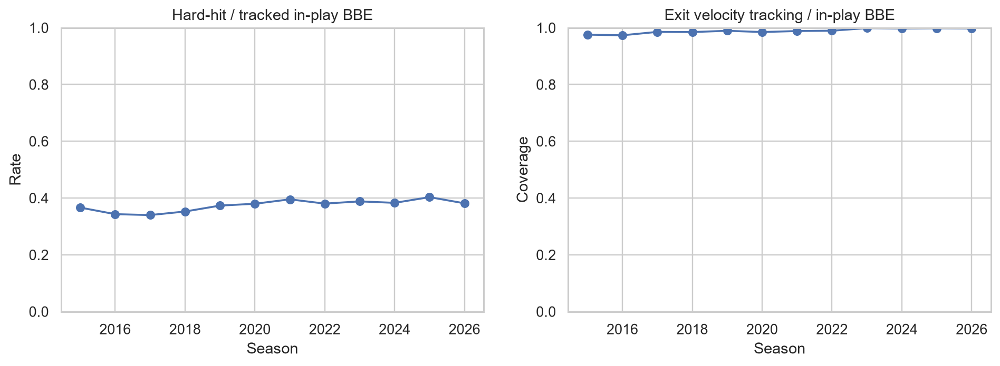

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_16_hardhit_and_coverage.png')

In [185]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].plot(annual.season,annual.hard_hit_rate,marker='o')
axes[1].plot(annual.season,annual.bbe_ev_coverage,marker='o')
axes[0].set(title='Hard-hit / tracked in-play BBE',xlabel='Season',ylabel='Rate',ylim=(0,1))
axes[1].set(title='Exit velocity tracking / in-play BBE',xlabel='Season',ylabel='Coverage',ylim=(0,1))
show_and_save_history(fig,'history_16_hardhit_and_coverage')

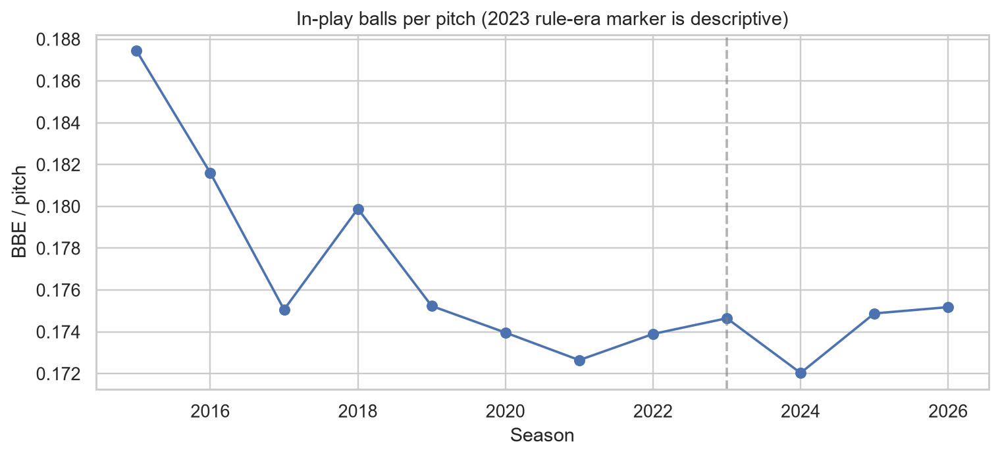

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_17_bbe_per_pitch.png')

In [186]:
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(annual.season,annual.bbe_per_pitch,marker='o')
ax.axvline(2023,color='gray',ls='--',alpha=.6)
ax.set(title='In-play balls per pitch (2023 rule-era marker is descriptive)',xlabel='Season',ylabel='BBE / pitch')
show_and_save_history(fig,'history_17_bbe_per_pitch')

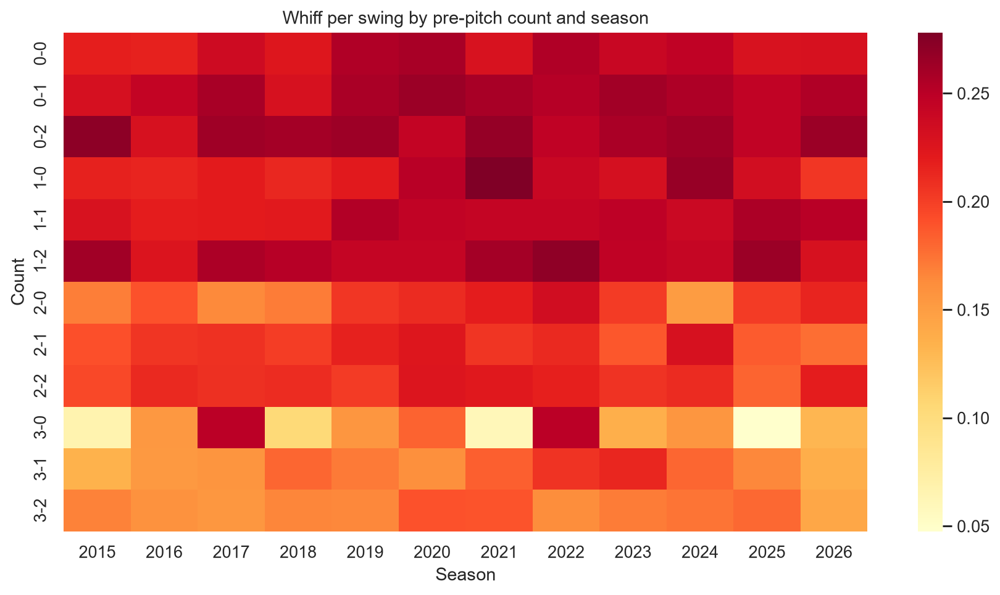

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_18_count_whiff_heatmap.png')

In [187]:
counts=hist['count'].copy()
counts['count_label']=counts.balls.astype('Int64').astype(str)+'-'+counts.strikes.astype('Int64').astype(str)
count_heat=counts.pivot_table(index='count_label',columns='season',values='whiff_rate')
order=[f'{b}-{s}' for b in range(4) for s in range(3)]
fig,ax=plt.subplots(figsize=(12,6))
sns.heatmap(count_heat.reindex(order),annot=False,cmap='YlOrRd',ax=ax)
ax.set(title='Whiff per swing by pre-pitch count and season',xlabel='Season',ylabel='Count')
show_and_save_history(fig,'history_18_count_whiff_heatmap')

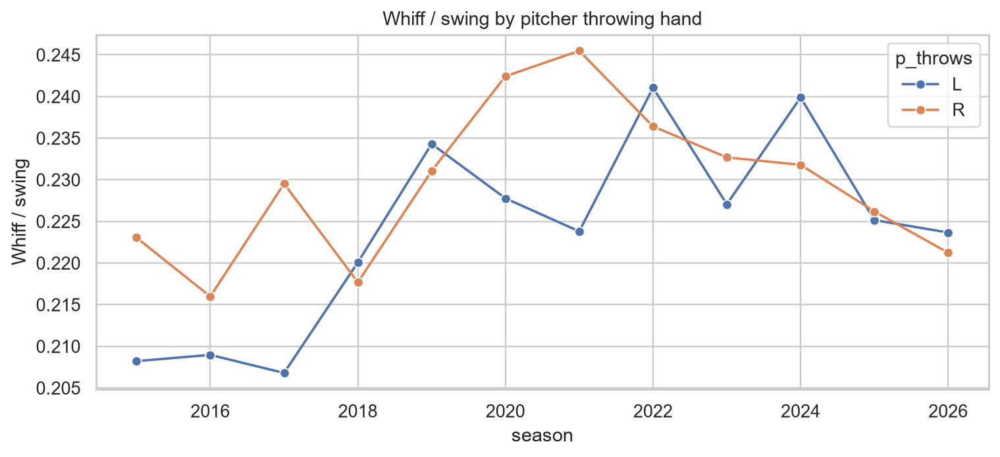

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_19_arm_whiff.png')

In [188]:
throw=hist['throwing_arm'].copy()
fig,ax=plt.subplots(figsize=(10,4))
sns.lineplot(data=throw, x='season',y='whiff_rate',hue='p_throws',marker='o',ax=ax)
ax.set(title='Whiff / swing by pitcher throwing hand',ylabel='Whiff / swing')
show_and_save_history(fig,'history_19_arm_whiff')

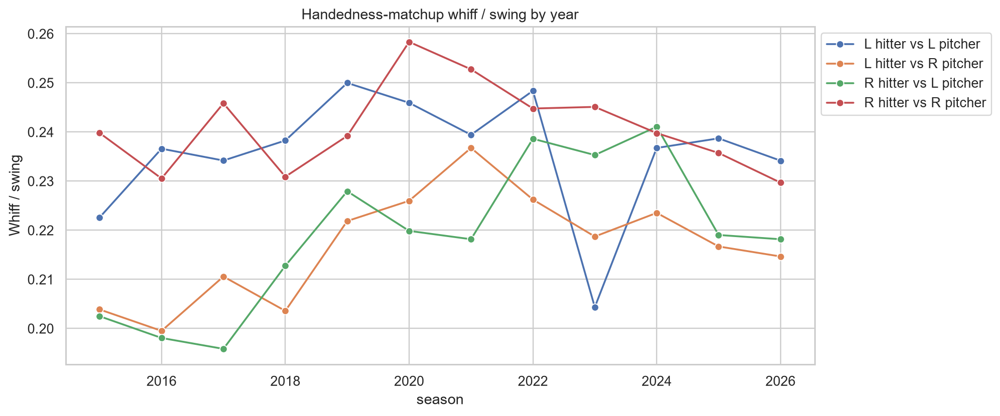

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_20_handedness_whiff.png')

In [189]:
matchup_history=hist['matchup'].query('pitches>=50').copy()
matchup_history['label']=matchup_history.stand.astype(str)+' hitter vs '+matchup_history.p_throws.astype(str)+' pitcher'
fig,ax=plt.subplots(figsize=(11,5))
sns.lineplot(data=matchup_history,x='season',y='whiff_rate',hue='label',marker='o',ax=ax)
ax.set(title='Handedness-matchup whiff / swing by year',ylabel='Whiff / swing')
ax.legend(bbox_to_anchor=(1,1),loc='upper left')
show_and_save_history(fig,'history_20_handedness_whiff')

# Part 46 | Measurement-Consistent Temporal Modeling (2020–2026)

**Design:** Train 2020–2024, validate/model-select 2025, evaluate the frozen choice in 2026 as an exploratory retrospective evaluation because earlier project iterations have already inspected 2026 results. Models use pitch-release and observed-location features; this is *not a before-the-pitch prediction*. 2025 was previously used in other notebook iterations and is validation, not an previously inspected evaluation. Data are a uniform random pitch sample only for modeling; full-population trend figures above use chunk aggregates. All results are observational.

In [190]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
MODEL_YEARS=list(range(2020,2027))
historical_model_data=build_pitch_model_frame(HISTORY_DIR, MODEL_YEARS)
model_features=['pitch_type','stand','p_throws','balls','strikes','release_speed',
                'release_spin_rate','pfx_x','pfx_z','plate_x','plate_z']
model_data=historical_model_data.dropna(subset=['is_whiff','game_date']).copy()
model_data['game_date']=pd.to_datetime(model_data['game_date'])
model_data['is_whiff']=model_data['is_whiff'].astype(int)
model_data=model_data.dropna(subset=['pitch_type','stand','p_throws'])
for c in model_features[3:]:model_data[c]=pd.to_numeric(model_data[c],errors='coerce')
training=model_data.loc[model_data.season.between(2020,2024)].copy()
validation_history=model_data.loc[model_data.season.eq(2025)].copy()
test_history=model_data.loc[model_data.season.eq(2026)].copy()
print('Historical modeling sample sizes:',len(training),len(validation_history),len(test_history))
if min(len(training),len(validation_history),len(test_history))<100 or min(training.is_whiff.nunique(),validation_history.is_whiff.nunique(),test_history.is_whiff.nunique())<2:
    raise ValueError('Insufficient model samples/classes. Expand HISTORY_MODE or download the missing years.')

Historical modeling sample sizes: 20500 4093 4056


In [191]:
cat=['pitch_type','stand','p_throws']
num=[x for x in model_features if x not in cat]
def create_history_model(kind):
    prep=ColumnTransformer([
        ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                        ('encode',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat),
        ('num',Pipeline([('impute',SimpleImputer(strategy='median')),
                        ('scale',StandardScaler())]),num)])
    estimators={
        'Dummy': DummyClassifier(strategy='prior'),
        'Logistic': LogisticRegression(max_iter=800),
        'HistGB': HistGradientBoostingClassifier(max_iter=130,max_leaf_nodes=17,min_samples_leaf=40,random_state=42),
        'RandomForest': RandomForestClassifier(n_estimators=100,max_depth=12,min_samples_leaf=35,n_jobs=-1,random_state=42)
    }
    return Pipeline([('prep',prep),('model',estimators[kind])])
def history_score(y,p):
    p=np.clip(np.asarray(p),1e-7,1-1e-7)
    return dict(ROC_AUC=roc_auc_score(y,p),PR_AUC=average_precision_score(y,p),
                Brier=brier_score_loss(y,p),LogLoss=log_loss(y,p,labels=[0,1]))
models_history={}
val_records=[]
for kind in ['Dummy','Logistic','HistGB','RandomForest']:
    fitted=create_history_model(kind)
    fitted.fit(training[model_features],training.is_whiff)
    pred=fitted.predict_proba(validation_history[model_features])[:,1]
    models_history[kind]=fitted
    val_records.append({'model':kind,**history_score(validation_history.is_whiff,pred)})
validation_results_history=pd.DataFrame(val_records).sort_values('Brier').reset_index(drop=True)
display(validation_results_history.round(4))
validation_results_history.to_csv(HISTORY_DIR/'historical_model_validation.csv',index=False)
selected_history_model=validation_results_history.loc[0,'model']
print('Selected on 2025 Brier only:',selected_history_model)

,model,ROC_AUC,PR_AUC,Brier,LogLoss
0,HistGB,0.7182,0.2195,0.0877,0.3053
1,RandomForest,0.7169,0.2204,0.0881,0.3089
2,Logistic,0.6423,0.1545,0.0912,0.3232
3,Dummy,0.5000,0.1038,0.0931,0.3339


Selected on 2025 Brier only: HistGB


In [192]:
# 2026 is evaluated retrospectively; the model was selected using 2025 metrics.
refit_data=pd.concat([training,validation_history],ignore_index=True)
frozen_history_model=create_history_model(selected_history_model)
frozen_history_model.fit(refit_data[model_features],refit_data.is_whiff)
prob_2026=frozen_history_model.predict_proba(test_history[model_features])[:,1]
base_2026=np.full(len(test_history),refit_data.is_whiff.mean())
final_2026=pd.DataFrame([
    {'model':selected_history_model,'segment':'2026','n':len(test_history),**history_score(test_history.is_whiff,prob_2026)},
    {'model':'Training prevalence','segment':'2026','n':len(test_history),**history_score(test_history.is_whiff,base_2026)}])
display(final_2026.round(4))
final_2026.to_csv(HISTORY_DIR/'historical_model_final_2026.csv',index=False)

,model,segment,n,ROC_AUC,PR_AUC,Brier,LogLoss
0,HistGB,2026,4056,0.7318,0.2158,0.0883,0.3057
1,Training prevalence,2026,4056,0.5000,0.1050,0.0940,0.3362


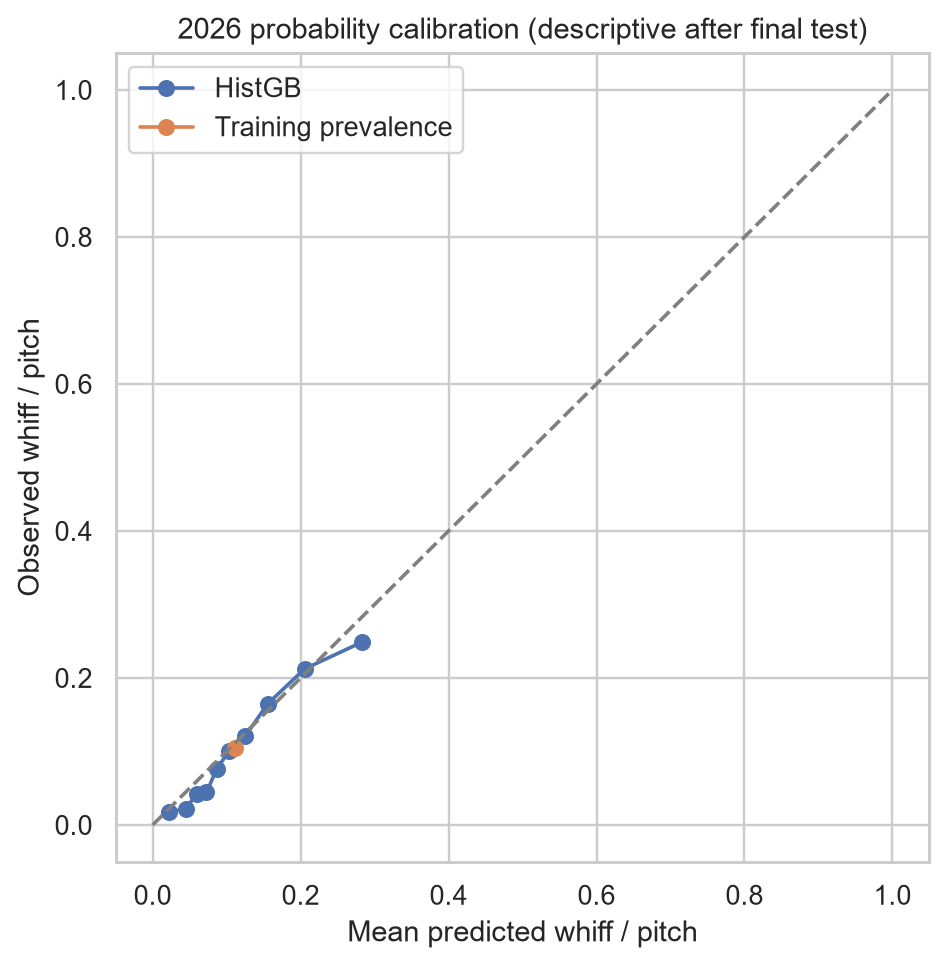

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_21_2026_calibration.png')

In [193]:
from sklearn.calibration import calibration_curve
fig,ax=plt.subplots(figsize=(6,6))
for label,probs in [(selected_history_model,prob_2026),('Training prevalence',base_2026)]:
    observed,predicted=calibration_curve(test_history.is_whiff,probs,n_bins=10,strategy='quantile')
    ax.plot(predicted,observed,'o-',label=label)
ax.plot([0,1],[0,1],'--',color='gray')
ax.set(title='2026 probability calibration (descriptive after final test)',xlabel='Mean predicted whiff / pitch',ylabel='Observed whiff / pitch')
ax.legend();show_and_save_history(fig,'history_21_2026_calibration')

In [194]:
# Performance in previously observed vs unseen batters is a diagnostic, not a new tuning criterion.
known=set(refit_data.batter.dropna().astype(str))
segment=test_history[['season','batter','pitch_type','p_throws','is_whiff']].copy()
segment['known_batter']=segment.batter.astype(str).isin(known)
segment['prediction']=prob_2026
records=[]
for label,g in segment.groupby('known_batter'):
    if len(g)>=50 and g.is_whiff.nunique()==2:
        records.append({'known_batter':label,'n':len(g),**history_score(g.is_whiff,g.prediction)})
segment_results=pd.DataFrame(records)
display(segment_results.round(4))
segment_results.to_csv(HISTORY_DIR/'historical_2026_known_batter.csv',index=False)

,known_batter,n,ROC_AUC,PR_AUC,Brier,LogLoss
0,False,784,0.7034,0.1899,0.0909,0.3150
1,True,3272,0.7387,0.2245,0.0877,0.3034


,train_through,validation,model,n,ROC_AUC,PR_AUC,Brier,LogLoss
0,2022,2023,Dummy,4053,0.5000,0.1160,0.1025,0.3589
1,2022,2023,Logistic,4053,0.6173,0.1643,0.1008,0.3507
2,2022,2023,HistGB,4053,0.7041,0.2239,0.0972,0.3325
3,2023,2024,Dummy,4063,0.5000,0.1189,0.1048,0.3649
4,2023,2024,Logistic,4063,0.6250,0.1616,0.1031,0.3556
5,2023,2024,HistGB,4063,0.7251,0.2332,0.0984,0.3336
6,2024,2025,Dummy,4093,0.5000,0.1038,0.0931,0.3339
7,2024,2025,Logistic,4093,0.6423,0.1545,0.0912,0.3232
8,2024,2025,HistGB,4093,0.7182,0.2195,0.0877,0.3053


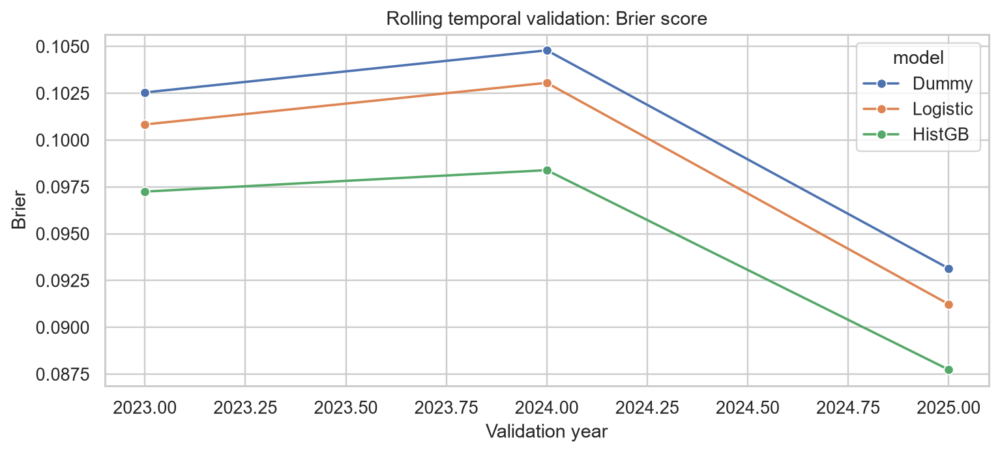

In [195]:
# Rolling-origin backtests; each fold trains only on strictly earlier years.
rolling=[]
for valyear in [2023,2024,2025]:
    train_fold=model_data.loc[model_data.season.between(2020,valyear-1)]
    validate_fold=model_data.loc[model_data.season.eq(valyear)]
    if len(train_fold)<100 or len(validate_fold)<100:continue
    for name in ['Dummy','Logistic','HistGB']:
        estimator=create_history_model(name)
        estimator.fit(train_fold[model_features],train_fold.is_whiff)
        p=estimator.predict_proba(validate_fold[model_features])[:,1]
        rolling.append({'train_through':valyear-1,'validation':valyear,'model':name,'n':len(validate_fold),
                        **history_score(validate_fold.is_whiff,p)})
rolling_scores=pd.DataFrame(rolling)
display(rolling_scores.round(4))
rolling_scores.to_csv(HISTORY_DIR/'rolling_origin_validation.csv',index=False)
if len(rolling_scores):
    fig,ax=plt.subplots(figsize=(10,4))
    sns.lineplot(data=rolling_scores,x='validation',y='Brier',hue='model',marker='o',ax=ax)
    ax.set(title='Rolling temporal validation: Brier score',xlabel='Validation year')
    show_and_save_history(fig,'history_22_rolling_brier')

# Part 47 | Statistical Uncertainty and Subgroup Stability

**Methods:** aggregate-level Wilson intervals (pitch independence assumption is approximate), game-cluster bootstrap for final-test Brier difference, and player-composition checks. These are not causal estimates.

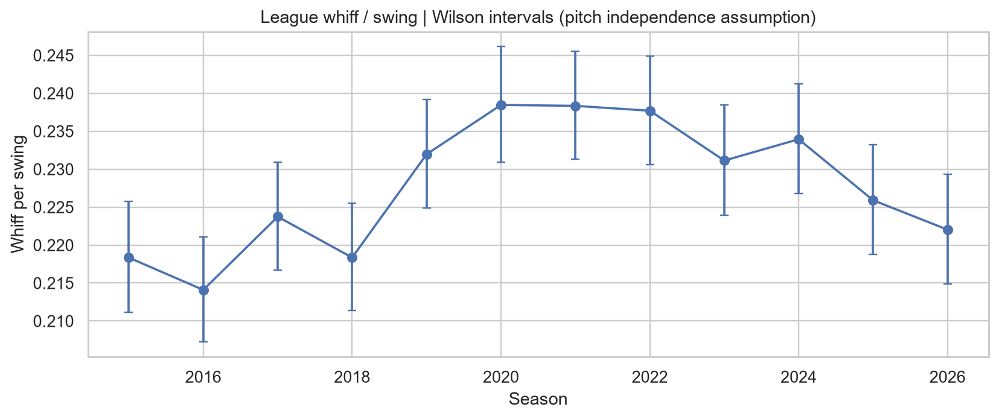

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/history_23_whiff_ci.png')

In [196]:
lo,hi=proportion_confint(annual.whiffs,annual.swings,method='wilson')
annual['whiff_ci_low']=lo;annual['whiff_ci_high']=hi
fig,ax=plt.subplots(figsize=(11,4))
ax.errorbar(annual.season,annual.whiff_rate,
            yerr=[annual.whiff_rate-lo,hi-annual.whiff_rate],fmt='o-',capsize=3)
ax.set(title='League whiff / swing | Wilson intervals (pitch independence assumption)',xlabel='Season',ylabel='Whiff per swing')
show_and_save_history(fig,'history_23_whiff_ci')

,gain_Brier,95pct_low,95pct_high,n_games
0,0.00569,0.00348,0.00753,93


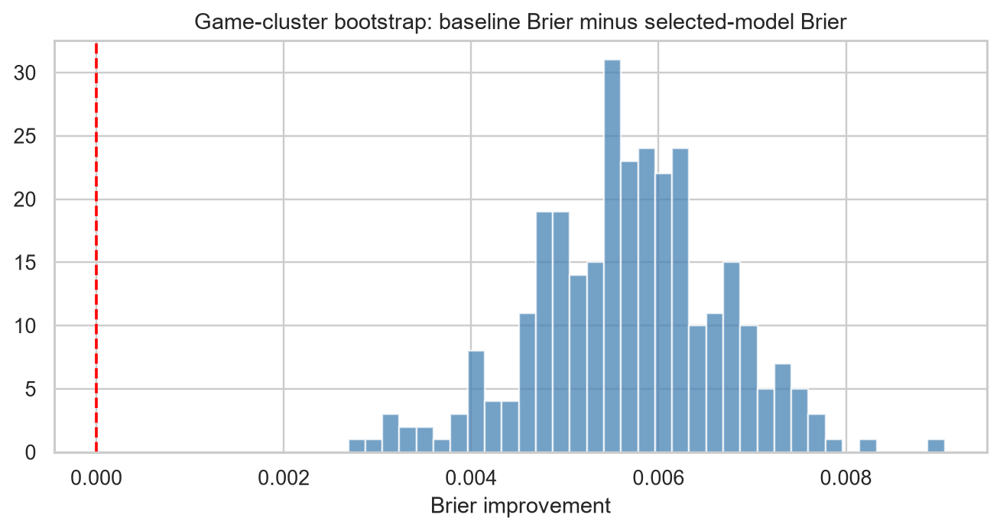

In [197]:
# Game-resampling respects some within-game dependence. Refit is NOT repeated.
base_brier=brier_score_loss(test_history.is_whiff,base_2026)
model_brier=brier_score_loss(test_history.is_whiff,prob_2026)
test_boot=test_history[['game_pk','is_whiff']].copy()
test_boot['sq_model']=(test_boot.is_whiff.to_numpy()-prob_2026)**2
test_boot['sq_baseline']=(test_boot.is_whiff.to_numpy()-base_2026)**2
by_game=test_boot.groupby('game_pk').agg(n=('is_whiff','size'),sum_m=('sq_model','sum'),sum_b=('sq_baseline','sum')).reset_index()
rng=np.random.default_rng(42)
bootstrap=[]
if len(by_game)>=10:
    vals=by_game[['n','sum_b','sum_m']].to_numpy()
    for _ in range(300):
        idx=rng.integers(0,len(vals),len(vals))
        s=vals[idx].sum(axis=0)
        bootstrap.append((s[1]-s[2])/s[0])
    conf=np.quantile(bootstrap,[.025,.975])
    display(pd.DataFrame([{'gain_Brier':base_brier-model_brier,'95pct_low':conf[0],'95pct_high':conf[1],
                           'n_games':len(by_game)}]).round(5))
    fig,ax=plt.subplots(figsize=(9,4));ax.hist(np.asarray(bootstrap,dtype=float),bins=35,color='steelblue',alpha=.75)
    ax.axvline(0,color='red',ls='--');ax.set(title='Game-cluster bootstrap: baseline Brier minus selected-model Brier',xlabel='Brier improvement')
    show_and_save_history(fig,'history_24_game_bootstrap')

# Part 48 | Research Summary, Data Contracts and Export

**Interpretation requirements:** historical rates are observational; the `sample` period is August 10–16 only; changes at tracking and rule boundaries may be artifacts; 2025 was used for model selection, while 2026 is now a retrospective exploratory evaluation; batting mechanics and defensive tracking require separate data products.

In [198]:
repro = {
    'study':'MLB Pitch Intelligence: Historical 2015–2026',
    'historical_years':HISTORY_YEARS,
    'mode':HISTORY_MODE,
    'population':'MLB regular season only',
    'model_population':'Uniformly randomized per-pitch samples per season, capped at 60000 per season',
    'historical_features':'Season-dependent availability; check coverage before comparisons',
    '2025':'Validation/model selection, previously inspected in earlier notebooks',
    '2026':'Final test, do not use for model tuning',
    'selected_model':selected_history_model,
    'graphs':len(list(HISTORY_FIG_DIR.glob('*.png')))
}
(HISTORY_DIR/'study_manifest.json').write_text(json.dumps(repro,indent=2),encoding='utf8')
annual.to_csv(HISTORY_DIR/'annual_research_summary.csv',index=False)
print('Historical research files:',HISTORY_DIR)
print('Figures:',len(list(HISTORY_FIG_DIR.glob('*.png'))))
display(pd.DataFrame([{'metric':'Years','value':f'{min(HISTORY_YEARS)}–{max(HISTORY_YEARS)}'},
                      {'metric':'Observed pitches','value':int(annual.pitches.sum())},
                      {'metric':'Mode','value':HISTORY_MODE},
                      {'metric':'2026 selected-model Brier','value':round(float(final_2026.iloc[0].Brier),5)}]))

Historical research files: I:\Potforlio\MLB Analytics\outputs\history_2015_2026\sample
Figures: 38


,metric,value
0,Years,2015–2026
1,Observed pitches,332598
2,Mode,sample
3,2026 selected-model Brier,0.08835


# Part 49 | Cross-Era Measurement Integrity
**Question:** are observed changes due to baseball performance or measurement/feature availability? 2015–2016 release velocity is back-adjusted from PitchFX and 2020 marks another tracking era. According to the MLB CSV documentation, from **2026** the `plate_x`/`plate_z` measurement reference moves from the front to the middle of the plate, alongside ABS changes. Avoid treating pre- and post-2026 raw location coordinates as geometrically interchangeable. The 2020 season began in late July, so the quick-sample window is uniformly **August 10–16** in all seasons. **No historical analysis can be interpreted until Part 41 successfully runs.**

,season,pitch_count,velocity_coverage,spin_coverage,batted_ball_ev_coverage,tracking_era,sample_window
0,2015,26317,1.000,0.935,0.976,2015-16,August 10–16
1,2016,28606,1.000,0.929,0.973,2015-16,August 10–16
2,2017,28978,0.994,0.975,0.985,2017-19,August 10–16
3,2018,28129,0.993,0.979,0.985,2017-19,August 10–16
4,2019,28373,0.995,0.976,0.989,2017-19,August 10–16
5,2020,26270,0.998,0.995,0.985,2020-25,August 10–16
6,2021,29042,0.985,0.983,0.988,2020-25,August 10–16
7,2022,28103,0.987,0.962,0.990,2020-25,August 10–16
8,2023,27123,0.998,0.994,0.999,2020-25,August 10–16
9,2024,27152,0.998,0.997,0.997,2020-25,August 10–16


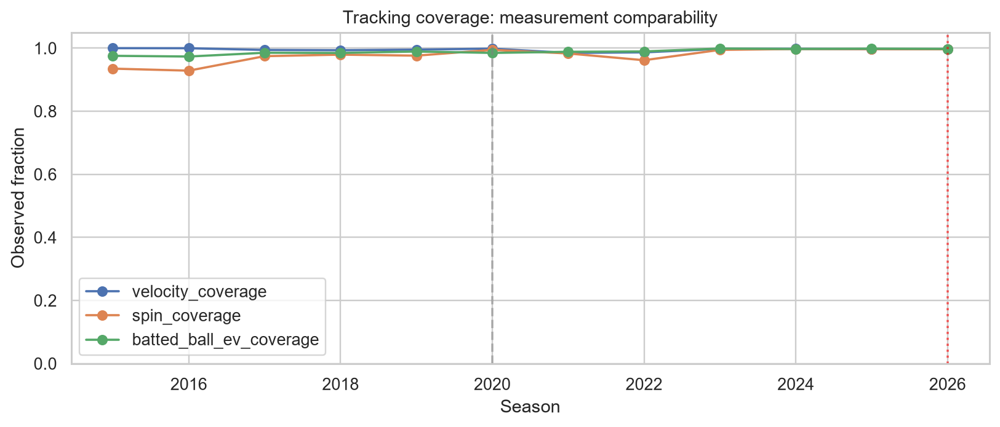

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/v7_01_measurement_coverage.png')

In [199]:
year_expected = set(HISTORY_YEARS)
year_observed = set(annual.season.astype(int).tolist())
missing_years = sorted(year_expected - year_observed)
if missing_years:
    raise ValueError(f'Missing seasons in historical summaries: {missing_years}. Check download_audit.csv and repeat collection.')
assert (annual.pitches > 0).all(), 'Every historical season must contain regular-season pitches.'
period_audit = pd.DataFrame({
    'season': annual.season.astype(int),
    'pitch_count': annual.pitches.astype(int),
    'velocity_coverage': annual.velocity_coverage,
    'spin_coverage': annual.spin_coverage,
    'batted_ball_ev_coverage': annual.bbe_ev_coverage,
    'tracking_era': pd.cut(annual.season, bins=[2014, 2016, 2019, 2025, 2026], labels=['2015-16','2017-19','2020-25','2026']),
    'sample_window': 'August 10–16' if HISTORY_MODE == 'sample' else 'Complete regular season'
})
display(period_audit.round(3))
period_audit.to_csv(HISTORY_DIR/'v7_measurement_and_coverage.csv',index=False)
fig, ax = plt.subplots(figsize=(11,4))
for col in ['velocity_coverage','spin_coverage','batted_ball_ev_coverage']:
    ax.plot(period_audit.season, period_audit[col], marker='o',label=col)
ax.set(xlabel='Season',ylabel='Observed fraction',title='Tracking coverage: measurement comparability',ylim=(0,1.05))
ax.axvline(2020,color='gray',ls='--',alpha=.5)
ax.axvline(2026,color='red',ls=':',alpha=.6)
ax.legend();show_and_save_history(fig,'v7_01_measurement_coverage')

# Part 50 | Pitch-Mix Standardization of Release Velocity
**Question:** when league velocity rises, how much reflects a change in pitch mix versus changes within individual pitch categories? Standardize each season to the **2021 pitch mix** using group counts and velocity sums. This is descriptive reweighting, not a causal decomposition. Missing types are explicitly assigned zero coverage rather than imputed.

,season,observed_velocity,fixed_2021_mix_velocity,reference_weight_covered
0,2015,88.936,88.744,0.999
1,2016,88.886,88.667,0.999
2,2017,88.645,88.490,0.999
3,2018,88.628,88.212,0.999
4,2019,88.695,88.340,0.998
5,2020,88.388,88.478,0.985
6,2021,88.740,88.740,0.985
7,2022,88.971,89.320,0.985
8,2023,88.959,89.480,1.000
9,2024,89.348,89.791,1.000


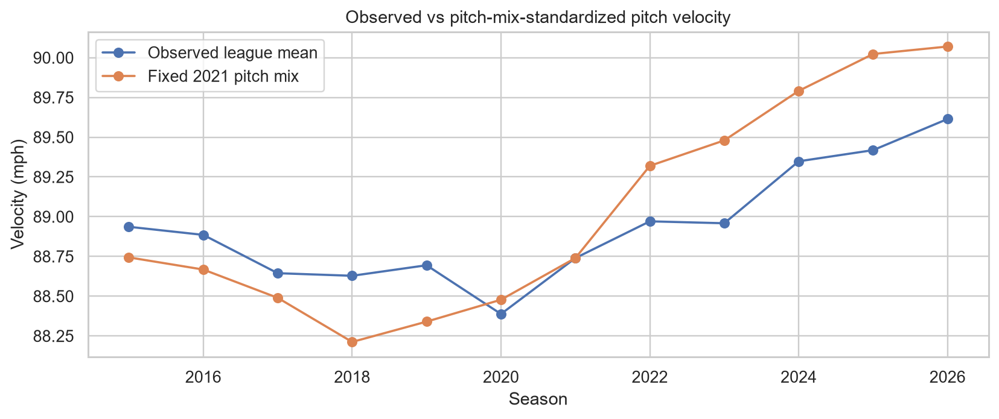

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/v7_02_velocity_standardization.png')

In [200]:
vel_pitch = pitch_history.copy()
vel_pitch['vel_mean'] = vel_pitch.vel_sum / vel_pitch.vel_n.replace(0,np.nan)
reference_vel = vel_pitch.loc[vel_pitch.season.eq(2021)].set_index('pitch_type').pitches
if reference_vel.empty:
    raise ValueError('A complete 2021 reference season is required for velocity standardization.')
reference_vel=reference_vel/reference_vel.sum()
rows=[]
for year, grp in vel_pitch.groupby('season'):
    v=grp.set_index('pitch_type').vel_mean.reindex(reference_vel.index)
    valid=v.notna();total=float(reference_vel[valid].sum())
    rows.append({'season':int(year), 'observed_velocity':float(annual.set_index('season').loc[year,'velocity']),
                 'fixed_2021_mix_velocity':float(np.average(v[valid],weights=reference_vel[valid])) if valid.any() else np.nan,
                 'reference_weight_covered':total})
vel_standardized=pd.DataFrame(rows).sort_values('season')
display(vel_standardized.round(3))
vel_standardized.to_csv(HISTORY_DIR/'v7_fixed_mix_velocity.csv',index=False)
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(vel_standardized.season,vel_standardized.observed_velocity,'o-',label='Observed league mean')
ax.plot(vel_standardized.season,vel_standardized.fixed_2021_mix_velocity,'o-',label='Fixed 2021 pitch mix')
ax.set(xlabel='Season',ylabel='Velocity (mph)',title='Observed vs pitch-mix-standardized pitch velocity')
ax.legend();show_and_save_history(fig,'v7_02_velocity_standardization')

# Part 51 | Matched Pitcher–Pitch-Type Development
**Question:** do the *same pitchers using the same named pitch types* change velocity between seasons? A stable pair comparison controls for the mixture of pitchers and pitch categories, but age, injuries and changing role still confound trends. Report sample sizes. In quick-sample mode, many pairings can be too sparse.

,pairs,median_change,mean_change
pitch_type,,,
FF,43,0.170,-0.075
SI,9,-0.631,-0.560
CH,5,-0.161,-0.586
FS,5,-0.839,-1.132
CU,3,-1.167,-1.431
SL,3,0.574,0.592
FC,2,1.134,1.134
KC,2,1.871,1.871
ST,1,-0.838,-0.838


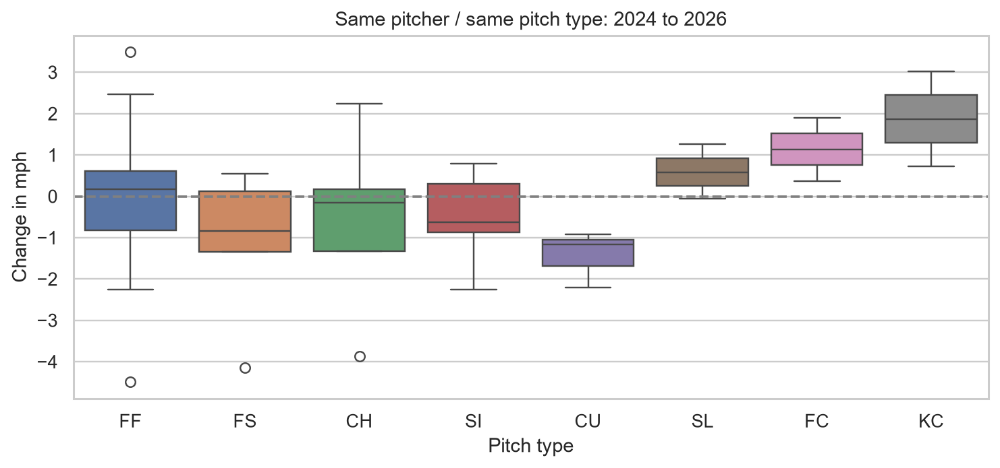

In [201]:
pitcher_type=hist['pitcher_pitch'].copy()
pitcher_type=pitcher_type.loc[pitcher_type.vel_n.ge(25)].copy()
pitcher_type['mean_vel']=pitcher_type.vel_sum/pitcher_type.vel_n
p0=pitcher_type.loc[pitcher_type.season.eq(2024),['pitcher','pitch_type','mean_vel','vel_n']].rename(columns={'mean_vel':'vel_2024','vel_n':'n_2024'})
p1=pitcher_type.loc[pitcher_type.season.eq(2026),['pitcher','pitch_type','mean_vel','vel_n']].rename(columns={'mean_vel':'vel_2026','vel_n':'n_2026'})
matched=p0.merge(p1,on=['pitcher','pitch_type'],how='inner')
matched['velocity_change']=matched.vel_2026-matched.vel_2024
matched=matched.sort_values('velocity_change')
if len(matched):
    display(matched.groupby('pitch_type').agg(pairs=('pitcher','size'),median_change=('velocity_change','median'),mean_change=('velocity_change','mean')).sort_values('pairs',ascending=False).round(3).head(12))
    matched.to_csv(HISTORY_DIR/'v7_paired_pitcher_pitch_velocity.csv',index=False)
    fig,ax=plt.subplots(figsize=(10,4))
    common=matched.pitch_type.value_counts().head(8).index
    sns.boxplot(data=matched[matched.pitch_type.isin(common)],x='pitch_type',y='velocity_change',hue='pitch_type',legend=False,ax=ax)
    ax.axhline(0,color='gray',ls='--');ax.set(title='Same pitcher / same pitch type: 2024 to 2026',ylabel='Change in mph',xlabel='Pitch type')
    show_and_save_history(fig,'v7_03_matched_pitcher_velocity')
else:
    print('No matched pitcher–pitch-type samples met thresholds. Expand to full-season mode.')

# Part 52 | Hitter Quality and Stability Across Years
**Question:** are persistent hitter swing/whiff differences visible across repeated seasons, rather than a single small-sample leaderboard? Estimate weighted player trends only for eligible seasons and visualize the number of repeated observations. Do not classify players as improving or declining without accounting for opponent and pitch-mix composition.

Hitters with at least 3 eligible seasons: 256


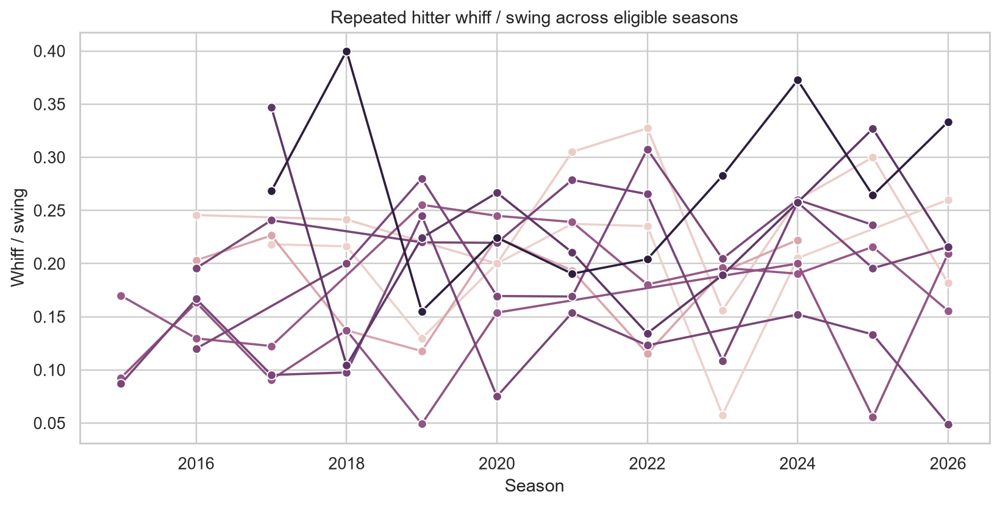

,seasons,total_swings
batter,,
621566,10,567
592518,11,548
518692,9,518
608070,11,515
608369,10,510
543760,9,506
607208,9,499
521692,9,477
646240,10,476


In [202]:
hitter_years=hist['batter'].copy()
hitter_years=hitter_years.loc[hitter_years.swings.ge(40)].copy()
hitter_years['whiff_rate']=hitter_years.whiffs/hitter_years.swings
stable=(hitter_years.groupby('batter').agg(seasons=('season','nunique'),total_swings=('swings','sum')).query('seasons >= 3').sort_values('total_swings',ascending=False))
print('Hitters with at least 3 eligible seasons:',len(stable))
if len(stable):
    h=hitter_years[hitter_years.batter.isin(stable.head(10).index)].copy()
    fig,ax=plt.subplots(figsize=(11,5))
    sns.lineplot(data=h,x='season',y='whiff_rate',hue='batter',estimator=None,units='batter',marker='o',ax=ax,legend=False)
    ax.set(title='Repeated hitter whiff / swing across eligible seasons',xlabel='Season',ylabel='Whiff / swing')
    show_and_save_history(fig,'v7_04_repeated_hitter_profiles')
    display(stable.head(15))
else:
    print('No hitters satisfy the 3-season denominator gate. This is expected for small samples.')

# Part 53 | Model Interpretation, Measurement Shift, and New Predictors
**Question:** how sensitive is the 2026 model evaluation to the cross-era change in pitch-location reference? The official Statcast documentation states that 2026 `plate_x` and `plate_z` reference the middle of the plate. **We do not adjust coordinates with an invented constant.** Instead compare a model trained on pre-release contextual variables only with the full-feature model as an *exploratory* diagnostic. This comparison must not be used to reselect models on 2026.

,model,Brier,PR_AUC
0,Pre-pitch context only,0.0933,0.1313
1,HistGB (measured physical + location),0.0883,0.2158


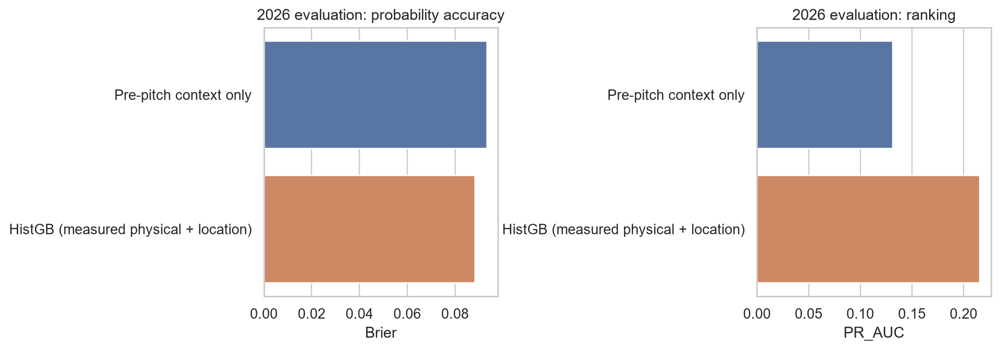

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/v7_05_model_information_sensitivity.png')

In [203]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, average_precision_score
from sklearn.preprocessing import OneHotEncoder
pre_cols=['stand','p_throws','balls','strikes']
pre_cat=['stand','p_throws'];pre_num=['balls','strikes']
pre_pipeline=Pipeline([
    ('features',ColumnTransformer([
        ('cat',Pipeline([('fill',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))]),pre_cat),
        ('num',Pipeline([('fill',SimpleImputer(strategy='median')),('scale',StandardScaler())]),pre_num)
    ])),
    ('model',LogisticRegression(max_iter=500))
])
pre_train=pd.concat([training,validation_history],ignore_index=True)
pre_pipeline.fit(pre_train[pre_cols],pre_train.is_whiff.astype(int))
pre_probs=pre_pipeline.predict_proba(test_history[pre_cols])[:,1]
model_2026_sensitivity=pd.DataFrame([
 {'model':'Pre-pitch context only','Brier':brier_score_loss(test_history.is_whiff,pre_probs),'PR_AUC':average_precision_score(test_history.is_whiff,pre_probs)},
 {'model':str(selected_history_model)+' (measured physical + location)','Brier':brier_score_loss(test_history.is_whiff,prob_2026),'PR_AUC':average_precision_score(test_history.is_whiff,prob_2026)}
])
display(model_2026_sensitivity.round(4))
model_2026_sensitivity.to_csv(HISTORY_DIR/'v7_location_reference_sensitivity.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
sns.barplot(data=model_2026_sensitivity,x='Brier',y='model',hue='model',legend=False,ax=axes[0])
sns.barplot(data=model_2026_sensitivity,x='PR_AUC',y='model',hue='model',legend=False,ax=axes[1])
axes[0].set(title='2026 evaluation: probability accuracy',ylabel='')
axes[1].set(title='2026 evaluation: ranking',ylabel='')
fig.tight_layout();show_and_save_history(fig,'v7_05_model_information_sensitivity')

,count,n,observed,predicted,brier,calibration_gap
0,0-0,1026,0.0760,0.0842,0.0657,0.0082
1,0-1,526,0.1122,0.1243,0.0947,0.0121
2,0-2,273,0.1575,0.1411,0.1263,-0.0164
3,1-0,407,0.0860,0.1114,0.0699,0.0254
4,1-1,395,0.1291,0.1340,0.1051,0.0048
5,1-2,399,0.1429,0.1503,0.1185,0.0075
6,2-0,138,0.0797,0.0793,0.0713,-0.0004
7,2-1,224,0.0759,0.1248,0.0697,0.0489
8,2-2,309,0.1683,0.1351,0.1341,-0.0332
11,3-2,229,0.0830,0.1272,0.0783,0.0443


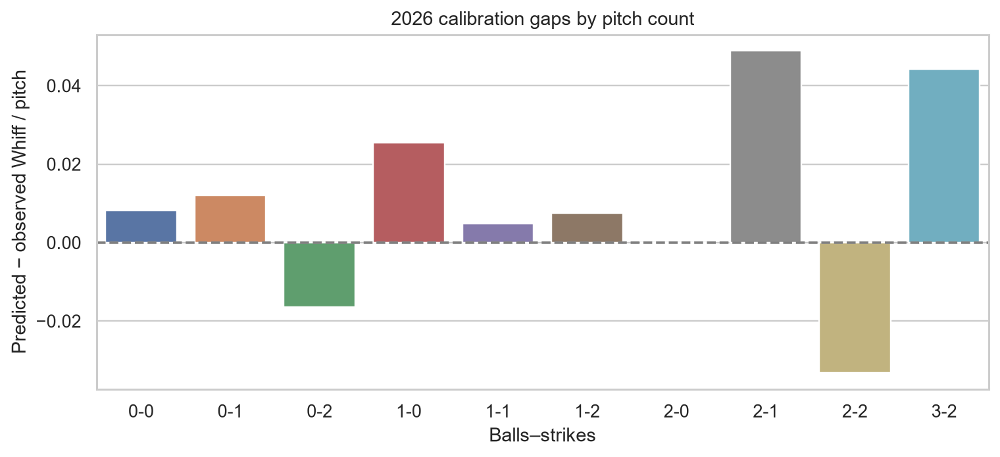

In [204]:
# Subgroup calibration is a post-hoc diagnostic, not a model-selection exercise.
seg=test_history[['season','pitch_type','balls','strikes','is_whiff']].copy()
seg['predicted']=prob_2026
seg['squared_error']=(seg.is_whiff-seg.predicted)**2
seg['count']=seg.balls.astype(int).astype(str)+'-'+seg.strikes.astype(int).astype(str)
segment_metrics=(seg.groupby(['count'],observed=True).agg(n=('is_whiff','size'),observed=('is_whiff','mean'),predicted=('predicted','mean'),brier=('squared_error','mean')).reset_index())
segment_metrics=segment_metrics[segment_metrics.n>=100]
segment_metrics['calibration_gap']=segment_metrics.predicted-segment_metrics.observed
display(segment_metrics.round(4))
segment_metrics.to_csv(HISTORY_DIR/'v7_2026_count_calibration.csv',index=False)
if len(segment_metrics):
    fig,ax=plt.subplots(figsize=(10,4))
    sns.barplot(data=segment_metrics,x='count',y='calibration_gap',hue='count',legend=False,ax=ax)
    ax.axhline(0,color='gray',ls='--');ax.set(title='2026 calibration gaps by pitch count',ylabel='Predicted − observed Whiff / pitch',xlabel='Balls–strikes')
    show_and_save_history(fig,'v7_06_2026_calibration_by_count')

# Part 54 | Research Integrity Checklist and Export
Final outputs must distinguish: (a) data present vs missing, (b) sampled-week vs full-season rates, (c) measurement-era shifts and classification changes, (d) within-player vs roster-composition differences, and (e) model validation on 2025 vs exploratory 2026 diagnostics. This Notebook alone does not establish causal effects of changing pitch selection. If 2026 results are inspected and the model is subsequently revised, reserve a later, genuinely unseen dataset for final evaluation.

In [205]:
v7_manifest={
 'historical_years': [int(x) for x in HISTORY_YEARS],
 'mode': HISTORY_MODE,
 'sample_window': 'August 10–16 every year' if HISTORY_MODE=='sample' else 'full regular seasons',
 'observed_years': sorted(int(x) for x in year_observed),
 'observed_pitches': int(annual.pitches.sum()),
 'model_training': '2020–2024',
 'model_validation': '2025 (previously inspected in earlier iterations)',
 'model_2026_evaluation': 'Exploratory once results have been consulted',
 '2026_plate_coordinates': 'middle of plate; prior years front of plate per MLB Statcast CSV documentation',
 'source': 'https://baseballsavant.mlb.com/csv-docs',
 'limitations': 'Observational; sample mode is not a full-season sample; tracking and pitch-type labels evolve.'
}
(HISTORY_DIR/'v7_research_manifest.json').write_text(json.dumps(v7_manifest,indent=2),encoding='utf8')
display(pd.DataFrame([{'item':k,'value':str(v)} for k,v in v7_manifest.items()]))
print('Figures saved:',len(list(HISTORY_FIG_DIR.glob('*.png'))),'at',HISTORY_FIG_DIR)

,item,value
0,historical_years,"[2015, 2016, 2017, 2018, 2019, 2020, 2021, 202..."
1,mode,sample
2,sample_window,August 10–16 every year
3,observed_years,"[2015, 2016, 2017, 2018, 2019, 2020, 2021, 202..."
4,observed_pitches,332598
5,model_training,2020–2024
6,model_validation,2025 (previously inspected in earlier iterations)
7,model_2026_evaluation,Exploratory once results have been consulted
8,2026_plate_coordinates,middle of plate; prior years front of plate pe...
9,source,https://baseballsavant.mlb.com/csv-docs


Figures saved: 38 at I:\Potforlio\MLB Analytics\outputs\history_2015_2026\sample\figures


## 55 | Historical data-contract and measurement audit

**RQ55:** Can every season and research denominator be verified before interpreting any trend? The 2026 location-reference change and earlier tracking-system changes prohibit naive cross-era location comparisons. This section uses aggregate data only.

,season,pitches,swings,whiffs,bbe,bbe_ev,barrel_n,barrels,vel_n,spin_n,whiff_events_valid,barrel_events_valid,barrel_denominator_valid,bbe_tracking_valid,spin_coverage,barrel_label_coverage,era
0,2015,26317,12320,2690,4933,4813,4813,309,26316,24607,True,True,True,True,0.935,1.000,2015-16
1,2016,28606,13438,2877,5195,5057,5057,311,28598,26564,True,True,True,True,0.929,1.000,2015-16
2,2017,28978,13261,2967,5073,4999,4999,315,28813,28241,True,True,True,True,0.975,1.000,2017-19
3,2018,28129,13203,2883,5060,4983,4979,296,27945,27549,True,True,True,True,0.979,0.999,2017-19
4,2019,28373,13498,3131,4972,4919,4919,383,28239,27697,True,True,True,True,0.976,1.000,2017-19
5,2020,26270,12044,2872,4570,4501,4501,343,26227,26129,True,True,True,True,0.995,1.000,2020-25
6,2021,29042,13829,3296,5014,4956,4956,391,28603,28552,True,True,True,True,0.983,1.000,2020-25
7,2022,28103,13576,3227,4887,4836,4836,347,27727,27027,True,True,True,True,0.962,1.000,2020-25
8,2023,27123,13010,3007,4737,4731,4731,355,27059,26973,True,True,True,True,0.994,1.000,2020-25
9,2024,27152,13046,3052,4671,4659,4659,364,27094,27079,True,True,True,True,0.997,1.000,2020-25


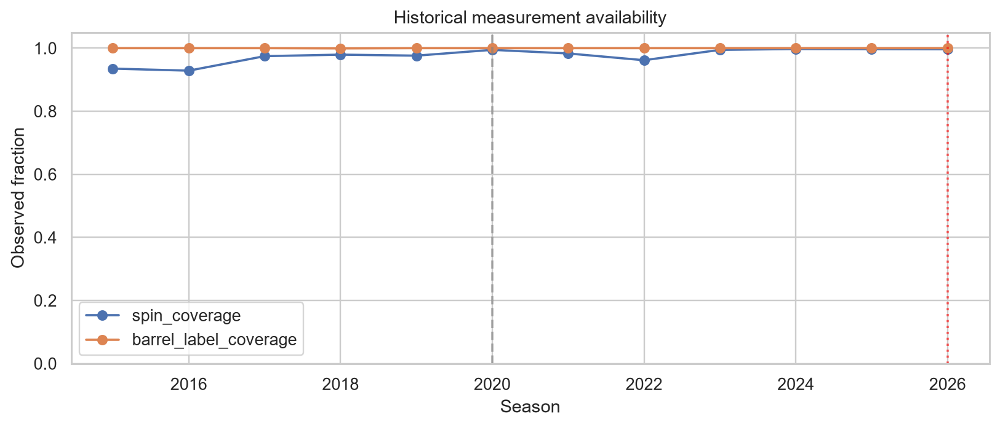

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/v8_01_measurement_denominator_audit.png')

In [206]:
from statsmodels.stats.proportion import proportion_confint
integrity = annual[['season','pitches','swings','whiffs','bbe','bbe_ev','barrel_n','barrels','vel_n','spin_n']].copy()
integrity['whiff_events_valid'] = integrity['whiffs'].le(integrity['swings'])
integrity['barrel_events_valid'] = integrity['barrels'].le(integrity['barrel_n'])
integrity['barrel_denominator_valid'] = integrity['barrel_n'].le(integrity['bbe_ev'])
integrity['bbe_tracking_valid'] = integrity['bbe_ev'].le(integrity['bbe'])
integrity['spin_coverage'] = integrity['spin_n'] / integrity['pitches'].replace(0,np.nan)
integrity['barrel_label_coverage'] = integrity['barrel_n'] / integrity['bbe_ev'].replace(0,np.nan)
integrity['era'] = pd.cut(integrity.season, bins=[2014,2016,2019,2025,2026],labels=['2015-16','2017-19','2020-25','2026'])
display(integrity.round(3))
if not integrity[['whiff_events_valid','barrel_events_valid','barrel_denominator_valid','bbe_tracking_valid']].all().all():
    raise AssertionError('A historical denominator invariant failed. Inspect raw chunks and summary tables.')
integrity.to_csv(HISTORY_DIR/'v8_denominator_audit.csv',index=False)
fig,ax=plt.subplots(figsize=(11,4))
for col in ['spin_coverage','barrel_label_coverage']:
    ax.plot(integrity.season,integrity[col],marker='o',label=col)
ax.axvline(2020,ls='--',color='gray',alpha=.6)
ax.axvline(2026,ls=':',color='red',alpha=.6)
ax.set(title='Historical measurement availability',xlabel='Season',ylabel='Observed fraction',ylim=(0,1.05))
ax.legend();show_and_save_history(fig,'v8_01_measurement_denominator_audit')

## 56 | Longitudinal pitch-family performance with a common composition

**RQ56:** Does the evolution of league whiff rate survive adjustments for pitch-family composition? Estimates are standardized to a fixed reference-season *swing* distribution, not causal effects.

,season,standardized_whiff,reference_coverage,whiff_rate
0,2015,0.2236,0.9768,0.2183
1,2016,0.2225,1.0000,0.2141
2,2017,0.2338,1.0000,0.2237
3,2018,0.2237,1.0000,0.2184
4,2019,0.2358,1.0000,0.2320
5,2020,0.2370,1.0000,0.2385
6,2021,0.2385,1.0000,0.2383
7,2022,0.2347,1.0000,0.2377
8,2023,0.2270,1.0000,0.2311
9,2024,0.2323,1.0000,0.2339


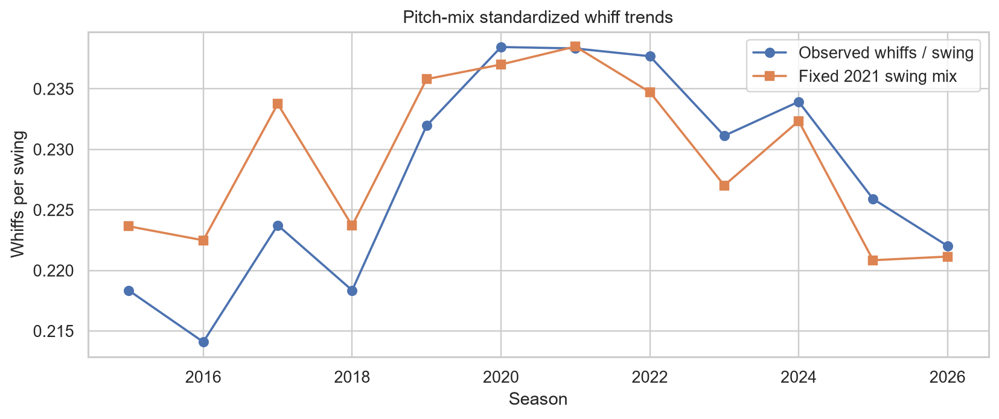

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/v8_02_pitch_mix_adjusted_whiff.png')

In [207]:
ref_year=2021
perf=pitch_history.loc[pitch_history.swings.ge(20)].copy()
major=perf.groupby('pitch_type').swings.sum().nlargest(8).index
perf['family']=perf.pitch_type.where(perf.pitch_type.isin(major),'Other')
perf=perf.groupby(['season','family'],as_index=False)[['swings','whiffs']].sum()
perf['whiff_rate']=perf.whiffs/perf.swings.replace(0,np.nan)
ref=perf.loc[perf.season.eq(ref_year)].set_index('family').swings
ref=ref/ref.sum() if ref.sum()>0 else ref
standardized=[]
for yr,g in perf.groupby('season'):
    rates=g.set_index('family').whiff_rate.reindex(ref.index)
    supported=rates.notna() & ref.gt(0)
    standardized.append({'season':int(yr),'standardized_whiff':float(np.average(rates[supported],weights=ref[supported])) if supported.any() else np.nan,
                         'reference_coverage':float(ref[supported].sum()) if supported.any() else 0})
standardized=pd.DataFrame(standardized)
standardized=standardized.merge(annual[['season','whiff_rate']],on='season',how='left')
display(standardized.round(4))
standardized.to_csv(HISTORY_DIR/'v8_pitch_mix_standardized_whiff.csv',index=False)
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(standardized.season,standardized.whiff_rate,marker='o',label='Observed whiffs / swing')
ax.plot(standardized.season,standardized.standardized_whiff,marker='s',label=f'Fixed {ref_year} swing mix')
ax.set(xlabel='Season',ylabel='Whiffs per swing',title='Pitch-mix standardized whiff trends')
ax.legend();show_and_save_history(fig,'v8_02_pitch_mix_adjusted_whiff')

## 57 | Pitcher repertoire concentration and temporal change

**RQ57:** Has reliance on a small number of pitch types changed across years? Use both Herfindahl concentration and Shannon entropy on observed repertoire. These are not measures of intrinsic pitch quality.

,season,players,median_HHI,median_entropy
0,2015,218,0.340,1.245
1,2016,252,0.363,1.155
2,2017,230,0.343,1.199
3,2018,245,0.362,1.169
4,2019,231,0.341,1.214
5,2020,225,0.348,1.183
6,2021,257,0.353,1.163
7,2022,242,0.333,1.229
8,2023,231,0.318,1.269
9,2024,256,0.316,1.276


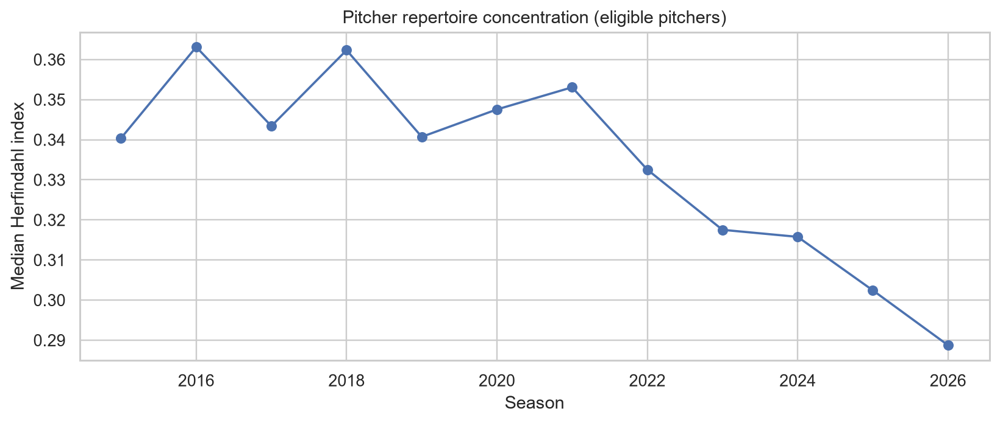

In [208]:
repertoire=hist['pitcher_pitch'].copy()
repertoire['pitches']=pd.to_numeric(repertoire.pitches,errors='coerce')
repertoire=repertoire[repertoire.pitches.gt(0)].copy()
repertoire['total']=repertoire.groupby(['season','pitcher']).pitches.transform('sum')
repertoire['share']=repertoire.pitches/repertoire.total
repertoire['hhi_term']=repertoire.share**2
repertoire['entropy_term']=-repertoire.share*np.log(repertoire.share.clip(lower=1e-10))
repertoire_by_player=repertoire.groupby(['season','pitcher'],as_index=False).agg(pitches=('pitches','sum'),HHI=('hhi_term','sum'),entropy=('entropy_term','sum'),n_types=('pitch_type','nunique'))
repertoire_by_player=repertoire_by_player[repertoire_by_player.pitches.ge(50)].copy()
repertoire_year=repertoire_by_player.groupby('season',as_index=False).agg(players=('pitcher','nunique'),median_HHI=('HHI','median'),median_entropy=('entropy','median'))
display(repertoire_year.round(3))
repertoire_year.to_csv(HISTORY_DIR/'v8_pitcher_repertoire_concentration.csv',index=False)
if not repertoire_year.empty:
    fig,ax=plt.subplots(figsize=(11,4))
    ax.plot(repertoire_year.season,repertoire_year.median_HHI,marker='o')
    ax.set(title='Pitcher repertoire concentration (eligible pitchers)',xlabel='Season',ylabel='Median Herfindahl index')
    show_and_save_history(fig,'v8_03_repertoire_concentration')

## 58 | Matched-pitcher evolution with eligibility gates

**RQ58:** Are observed velocity differences present within the same pitcher and named pitch type? Restrict to repeated players with sufficient tracked pitches. Avoid interpreting changes as individual development without accounting for injury and selection.

,pitch_type,pairs,median_change,mean_change
0,FF,21,-0.459,-0.573


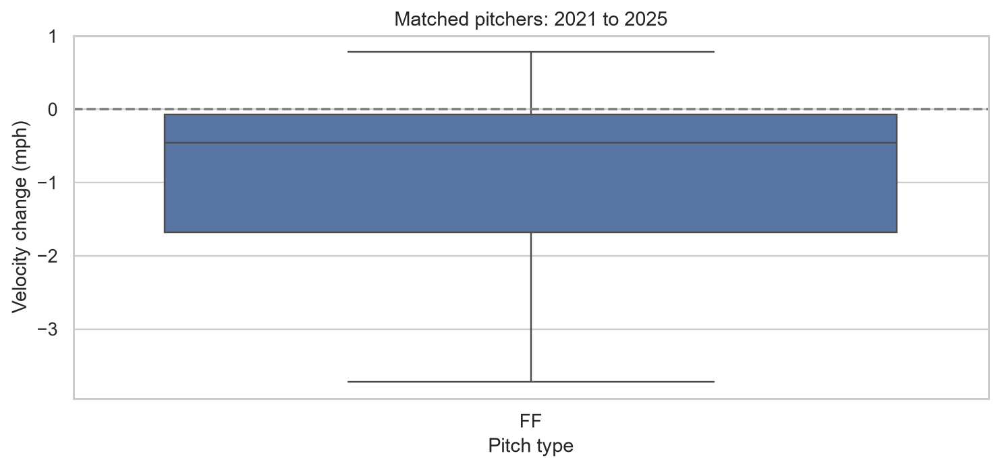

In [209]:
pt=hist['pitcher_pitch'].copy()
pt=pt.loc[pt.vel_n.ge(35)].copy()
pt['velocity']=pt.vel_sum/pt.vel_n
left=pt.loc[pt.season.eq(2021),['pitcher','pitch_type','velocity','vel_n']].rename(columns={'velocity':'base_velocity','vel_n':'base_n'})
right=pt.loc[pt.season.eq(2025),['pitcher','pitch_type','velocity','vel_n']].rename(columns={'velocity':'later_velocity','vel_n':'later_n'})
matched_pt=left.merge(right,on=['pitcher','pitch_type'])
matched_pt['change_mph']=matched_pt.later_velocity-matched_pt.base_velocity
pitcher_2021_2025=matched_pt.groupby('pitch_type',as_index=False).agg(pairs=('pitcher','size'),median_change=('change_mph','median'),mean_change=('change_mph','mean'))
pitcher_2021_2025=pitcher_2021_2025.query('pairs >= 5').sort_values('pairs',ascending=False)
display(pitcher_2021_2025.round(3))
pitcher_2021_2025.to_csv(HISTORY_DIR/'v8_matched_pitcher_velocity.csv',index=False)
if not pitcher_2021_2025.empty:
    kept=pitcher_2021_2025.pitch_type.head(8)
    fig,ax=plt.subplots(figsize=(10,4))
    sns.boxplot(data=matched_pt[matched_pt.pitch_type.isin(kept)],x='pitch_type',y='change_mph',hue='pitch_type',dodge=False,legend=False,showfliers=False,ax=ax)
    ax.axhline(0,ls='--',color='gray');ax.set(title='Matched pitchers: 2021 to 2025',ylabel='Velocity change (mph)',xlabel='Pitch type')
    show_and_save_history(fig,'v8_04_matched_pitcher_change')
else:
    print('Matched-pitcher comparison does not meet sample thresholds. Try full-season mode.')

## 59 | Batter stability and Bayesian shrinkage

**RQ59:** Which batter Whiff rates persist across seasons, and how much does low sample size distort individual rankings? Rates below are empirical-Bayes-smoothed descriptions, not estimates of a true hidden talent independent of pitch selection.

Batters with three or more eligible observed seasons: 524


,eligible_years,total_swings
batter,,
543760,12,611
518692,11,591
592518,12,585
621566,10,567
608070,12,547
596019,11,546
553993,12,540
514888,11,534
593428,12,529


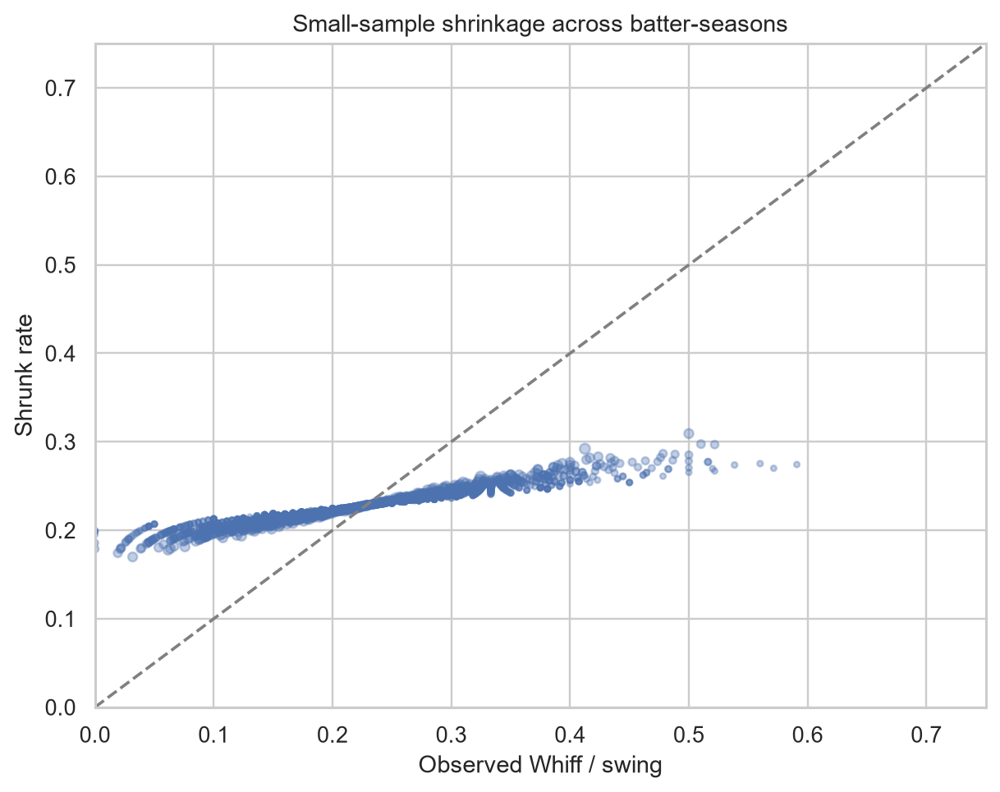

In [210]:
hitter_table=hist['batter'].copy()
hitter_table=hitter_table.loc[hitter_table.swings.ge(20)].copy()
league_prior=annual.whiffs.sum()/annual.swings.sum()
prior_strength=150
hitter_table['raw_whiff']=hitter_table.whiffs/hitter_table.swings
hitter_table['shrunk_whiff']=(hitter_table.whiffs+prior_strength*league_prior)/(hitter_table.swings+prior_strength)
hitter_table['shrinkage']=hitter_table.raw_whiff-hitter_table.shrunk_whiff
hitter_stability=hitter_table.groupby('batter').agg(eligible_years=('season','nunique'),total_swings=('swings','sum')).query('eligible_years >= 3').sort_values('total_swings',ascending=False)
print('Batters with three or more eligible observed seasons:',len(hitter_stability))
display(hitter_stability.head(12))
hitter_table.to_csv(HISTORY_DIR/'v8_batter_shrinkage.csv',index=False)
if not hitter_table.empty:
    fig,ax=plt.subplots(figsize=(8,6))
    ss=hitter_table.sample(n=min(2000,len(hitter_table)),random_state=42)
    ax.scatter(ss.raw_whiff,ss.shrunk_whiff,s=np.clip(ss.swings/3,8,70),alpha=.35)
    ax.plot([0,1],[0,1],ls='--',color='gray')
    ax.set(xlim=(0,.75),ylim=(0,.75),xlabel='Observed Whiff / swing',ylabel='Shrunk rate',title='Small-sample shrinkage across batter-seasons')
    show_and_save_history(fig,'v8_05_batter_shrinkage')

## 60 | Run-expectancy delta: availability and descriptive direction

**RQ60:** Are pitch-level run-expectancy changes recorded consistently? Analyze only available values and preserve the documented sign convention. This is not a causal pitch-value estimator.

,season,mean_coverage,pitch_types
0,2015,0.900,10
1,2016,1.000,8
2,2017,0.928,10
3,2018,0.938,9
4,2019,0.921,9
5,2020,1.000,9
6,2021,0.972,9
7,2022,0.985,10
8,2023,1.000,9
9,2024,1.000,9


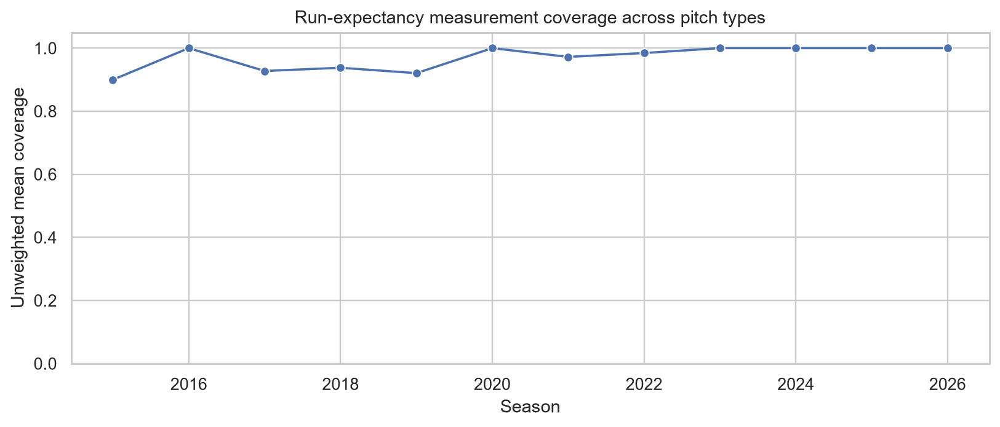

In [211]:
re=hist['pitch'].copy()
re['run_exp_observed_fraction']=re.run_n/re.pitches.replace(0,np.nan)
re['mean_delta_run_exp']=re.run_sum/re.run_n.replace(0,np.nan)
re=re.loc[re.pitches.ge(100)].copy()
re_summary=re.groupby('season',as_index=False).agg(mean_coverage=('run_exp_observed_fraction','mean'),pitch_types=('pitch_type','nunique'))
display(re_summary.round(3))
re.to_csv(HISTORY_DIR/'v8_run_expectancy_by_pitch.csv',index=False)
if not re.empty:
    fig,ax=plt.subplots(figsize=(11,4))
    sns.lineplot(data=re_summary,x='season',y='mean_coverage',marker='o',ax=ax)
    ax.set(title='Run-expectancy measurement coverage across pitch types',ylabel='Unweighted mean coverage',xlabel='Season',ylim=(0,1.05))
    show_and_save_history(fig,'v8_06_run_expectancy_coverage')

## 61 | Full-population trend versus modeling-sample selection

**RQ61:** How does the sampled modeling population compare with the historical aggregate population? A capped sample is not a substitute for full-population descriptive statistics.

,season,pitches,whiff_per_pitch,sample_rows,sample_whiff_per_pitch,sample_fraction,whiff_gap
0,2015,26317,0.1022,NaN,NaN,NaN,NaN
1,2016,28606,0.1006,NaN,NaN,NaN,NaN
2,2017,28978,0.1024,NaN,NaN,NaN,NaN
3,2018,28129,0.1025,NaN,NaN,NaN,NaN
4,2019,28373,0.1104,NaN,NaN,NaN,NaN
5,2020,26270,0.1093,3941.0,0.0997,0.15,-0.0096
6,2021,29042,0.1135,4356.0,0.1136,0.15,0.0001
7,2022,28103,0.1148,4215.0,0.1165,0.15,0.0017
8,2023,27123,0.1109,4069.0,0.1155,0.15,0.0046
9,2024,27152,0.1124,4073.0,0.1186,0.15,0.0062


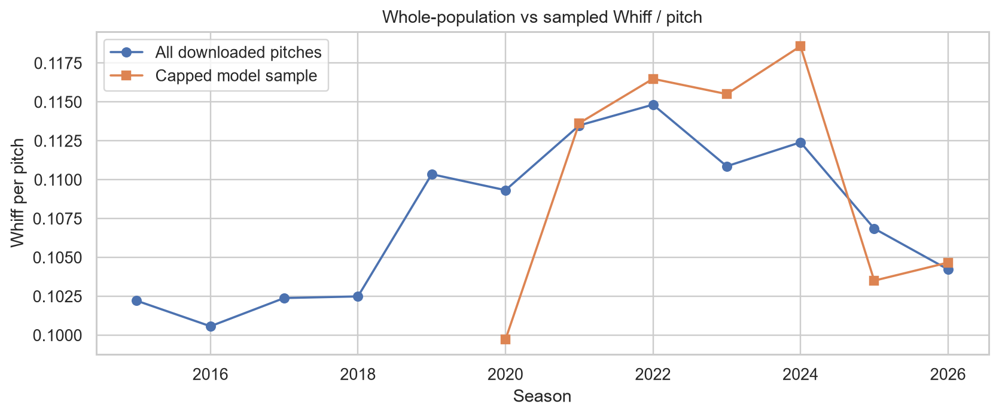

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/v8_07_sample_bias_audit.png')

In [212]:
sample_data=historical_model_data.copy()
sample_years=sample_data.groupby('season').agg(sample_rows=('is_whiff','size'),sample_whiff_per_pitch=('is_whiff','mean')).reset_index()
sample_audit=annual[['season','pitches','whiff_per_pitch']].merge(sample_years,on='season',how='left')
sample_audit['sample_fraction']=sample_audit.sample_rows/sample_audit.pitches.replace(0,np.nan)
sample_audit['whiff_gap']=sample_audit.sample_whiff_per_pitch-sample_audit.whiff_per_pitch
display(sample_audit.round(4))
sample_audit.to_csv(HISTORY_DIR/'v8_sampling_representativeness.csv',index=False)
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(sample_audit.season,sample_audit.whiff_per_pitch,marker='o',label='All downloaded pitches')
ax.plot(sample_audit.season,sample_audit.sample_whiff_per_pitch,marker='s',label='Capped model sample')
ax.set(title='Whole-population vs sampled Whiff / pitch',xlabel='Season',ylabel='Whiff per pitch')
ax.legend();show_and_save_history(fig,'v8_07_sample_bias_audit')

## 62 | Two information sets: pre-pitch vs measured trajectory

**RQ62:** How much apparent predictive improvement comes from post-release measurement? Keep 2026 as an exploratory external-year diagnostic once viewed. This is **not** a causal effect or pre-pitch recommendation tool.

,information,Brier,PR_AUC,Brier_improvement_vs_pre
0,Known before pitch (count and handedness),0.0933,0.1313,0.0000
1,Measured after release (physics and location),0.0883,0.2158,0.0049


,measured_minus_pre_Brier_gain,ci_low,ci_high,games
0,0.00494,0.00322,0.0069,93


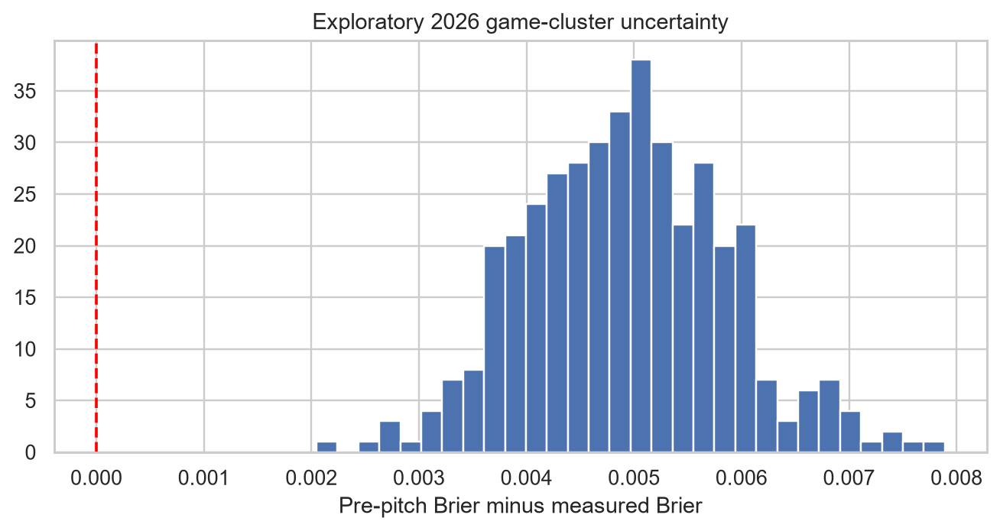

In [213]:
from sklearn.metrics import brier_score_loss, average_precision_score
from statsmodels.stats.proportion import proportion_confint
pre_only=brier_score_loss(test_history.is_whiff,pre_probs)
measured=brier_score_loss(test_history.is_whiff,prob_2026)
info_comparison=pd.DataFrame([
    {'information':'Known before pitch (count and handedness)', 'Brier':pre_only, 'PR_AUC':average_precision_score(test_history.is_whiff,pre_probs)},
    {'information':'Measured after release (physics and location)', 'Brier':measured, 'PR_AUC':average_precision_score(test_history.is_whiff,prob_2026)}
])
info_comparison['Brier_improvement_vs_pre']=pre_only-info_comparison.Brier
display(info_comparison.round(4))
info_comparison.to_csv(HISTORY_DIR/'v8_information_set_comparison.csv',index=False)
# Game-cluster bootstrap of fixed model predictions, without refitting.
err=test_history[['game_pk','is_whiff']].copy()
err['diff']=(err.is_whiff.to_numpy()-pre_probs)**2-(err.is_whiff.to_numpy()-prob_2026)**2
bg=err.groupby('game_pk',as_index=False).agg(diff_sum=('diff','sum'),n=('diff','size'))
rng=np.random.default_rng(2026)
ci=[]
if len(bg)>=10:
    arr=bg[['diff_sum','n']].to_numpy()
    for _ in range(400):
        boot=arr[rng.integers(0,len(arr),len(arr))].sum(axis=0)
        ci.append(boot[0]/boot[1])
    bounds=np.quantile(ci,[.025,.975])
    display(pd.DataFrame([{'measured_minus_pre_Brier_gain':pre_only-measured,'ci_low':bounds[0],'ci_high':bounds[1],'games':len(bg)}]).round(5))
    fig,ax=plt.subplots(figsize=(9,4));ax.hist(ci,bins=30)
    ax.axvline(0,ls='--',color='red');ax.set(xlabel='Pre-pitch Brier minus measured Brier',title='Exploratory 2026 game-cluster uncertainty')
    show_and_save_history(fig,'v8_08_information_gain_cluster_ci')

## 62.1 | Historical two-stage batter-decision model (2020–2026)

**RQ62.1:** Is a direct Whiff-per-pitch model more reliable than decomposing the outcome into **P(swing)** and **P(whiff | swing)**? This is a new historical modeling objective; it is not the earlier 2024–2025 two-week exercise. Features exclude plate coordinates to avoid the 2026 reference change. We train using 2020–2024, inspect 2025, and describe 2026 only as exploratory once viewed. No intervention claim follows from these predictions.


,period,pitches,Brier,PR_AUC,observed_whiff_per_pitch
0,2025 validation,4093,0.0914,0.1532,0.1038
1,2026 exploratory,4056,0.0923,0.1514,0.1050


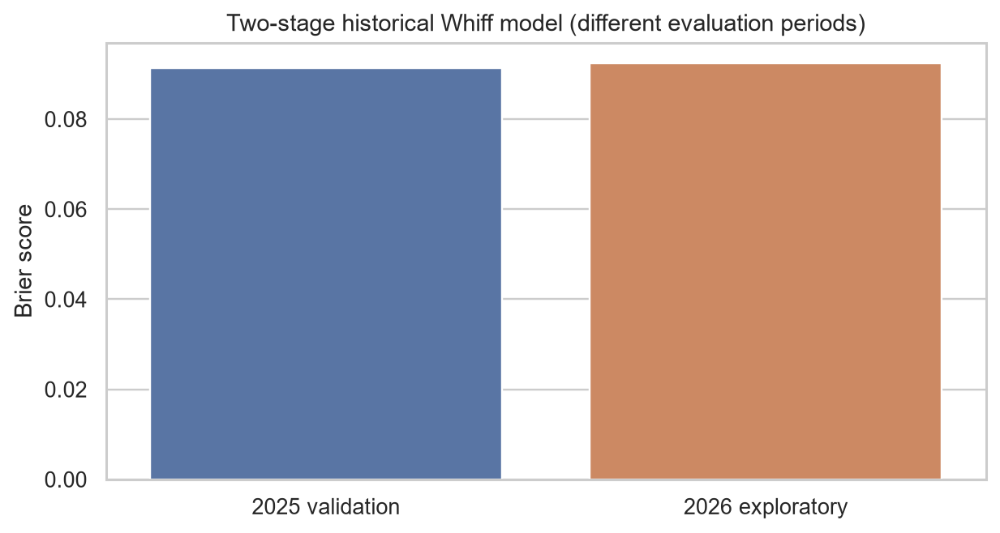

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/figures/v8_09_two_stage_brier.png')

In [214]:
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import brier_score_loss, average_precision_score

stage_features=['pitch_type','stand','p_throws','balls','strikes','release_speed','release_spin_rate','pfx_x','pfx_z']
stage_cat=['pitch_type','stand','p_throws']
stage_num=[x for x in stage_features if x not in stage_cat]

def make_two_stage_classifier():
    prep=ColumnTransformer([
      ('cat',Pipeline([('fill',SimpleImputer(strategy='most_frequent')),
                        ('encode',OneHotEncoder(handle_unknown='ignore'))]),stage_cat),
      ('num',Pipeline([('fill',SimpleImputer(strategy='median')),
                        ('scale',StandardScaler())]),stage_num)
    ])
    return Pipeline([('prepare',prep),('classifier',LogisticRegression(max_iter=900))])

stage_train=model_data.loc[model_data.season.between(2020,2024)].copy()
stage_val=model_data.loc[model_data.season.eq(2025)].copy()
stage_test=model_data.loc[model_data.season.eq(2026)].copy()
if min(len(stage_train),len(stage_val),len(stage_test))<100:
    raise ValueError('Not enough historical samples for two-stage modeling.')

stage_a=make_two_stage_classifier()
stage_b=make_two_stage_classifier()
stage_a.fit(stage_train[stage_features],stage_train.is_swing.astype(int))
train_swingers=stage_train.loc[stage_train.is_swing.eq(1)].copy()
if train_swingers.is_whiff.nunique()<2:
    raise ValueError('Insufficient conditional whiff outcomes in historical training data.')
stage_b.fit(train_swingers[stage_features],train_swingers.is_whiff.astype(int))

def two_stage_predict(frame):
    p_swing=stage_a.predict_proba(frame[stage_features])[:,1]
    p_whiff_given_swing=stage_b.predict_proba(frame[stage_features])[:,1]
    return p_swing*p_whiff_given_swing

stage_results=[]
for name,frame in [('2025 validation',stage_val),('2026 exploratory',stage_test)]:
    prob=two_stage_predict(frame)
    stage_results.append({'period':name,'pitches':len(frame),
                          'Brier':brier_score_loss(frame.is_whiff,prob),
                          'PR_AUC':average_precision_score(frame.is_whiff,prob),
                          'observed_whiff_per_pitch':frame.is_whiff.mean()})
stage_results=pd.DataFrame(stage_results)
display(stage_results.round(4))
stage_results.to_csv(HISTORY_DIR/'v8_two_stage_history_performance.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4))
sns.barplot(data=stage_results,x='period',y='Brier',hue='period',dodge=False,legend=False,ax=ax)
ax.set(title='Two-stage historical Whiff model (different evaluation periods)',xlabel='',ylabel='Brier score')
show_and_save_history(fig,'v8_09_two_stage_brier')

## 63 | Historical analysis manifest and evidence map

This manifest automatically documents what executed, when, and on which population. Predictions in 2026 become exploratory once examined and should not be reused for model tuning.

In [215]:
import json
v8_manifest={
    'analysis':'Historical Statcast 2015–2026 | V8 reviewed',
    'mode':HISTORY_MODE,
    'seasons_requested':list(map(int,HISTORY_YEARS)),
    'seasons_observed':sorted(map(int,annual.season.unique())),
    'total_observed_pitches':int(annual.pitches.sum()),
    'sample_scope':'August 10–16 of each year' if HISTORY_MODE=='sample' else 'Regular-season range',
    'training':'2020–2024',
    'validation':'2025 (previous analyses consulted)',
    'test':'2026 (exploratory after results are viewed)',
    'barrel_definition':'launch_speed_angle == 6 among tracked BBE with known launch_speed_angle',
    'tracking_caveat':'2015–2016, 2017–2019, 2020–2025, and 2026 measurement regimes are not fully comparable',
    'source_data':'Baseball Savant Statcast CSV via pybaseball',
    'limitations':'Observational, seasonal sampling, changing pitch classification and measurement; no causal optimization claims'
}
(HISTORY_DIR/'v8_evidence_manifest.json').write_text(json.dumps(v8_manifest,indent=2),encoding='utf8')
display(pd.DataFrame([{'field':k,'value':str(v)} for k,v in v8_manifest.items()]))
print('New historical figures:',len(list(HISTORY_FIG_DIR.glob('v8_*.png'))))

,field,value
0,analysis,Historical Statcast 2015–2026 | V8 reviewed
1,mode,sample
2,seasons_requested,"[2015, 2016, 2017, 2018, 2019, 2020, 2021, 202..."
3,seasons_observed,"[2015, 2016, 2017, 2018, 2019, 2020, 2021, 202..."
4,total_observed_pitches,332598
5,sample_scope,August 10–16 of each year
6,training,2020–2024
7,validation,2025 (previous analyses consulted)
8,test,2026 (exploratory after results are viewed)
9,barrel_definition,launch_speed_angle == 6 among tracked BBE with...


New historical figures: 9


## Study limitations and submission checklist

- Complete the **full** mode before presenting full-season trends; the quick sample is only August 10–16 every year.
- Inspect `download_audit.csv` for zero-row seasons, coverage tables, and `manifest.json` for date ranges.
- **2015–2016** pitch-speed and pitch tracking technology differs from 2017+, and **2020** represents another measurement change. Stratify rather than assuming identical measurements across eras.
- **2020** has a shortened regular season. Plot rates with denominators, not raw counts, for season comparisons.
- Classification codes (e.g. sweepers) evolve; a newly appearing code can represent a labeling change rather than a new pitch design.
- Models use physical/location features observed *during or after* a pitch; they do not predict decisions strictly before release.
- Current historical analysis does not include a complete 2024+ bat-tracking swing dataset; it requires separate source retrieval.
- Inspect `historical_model_final_2026.csv` once. After inspecting, further iteration on 2026 would make this an exploratory test rather than a independent evaluation until results are inspected and used for further iteration.
- Create a narrative for each result: research question, population, denominator, model assumption, evidence, baseball interpretation, limitations.

# Division V — Longitudinal Diagnostics & Model Stability

*This division contains detailed technical experiments; the submission report selects the most defensible results.*

# Part 64 | Expanded Research: Design, Coverage & Interpretability

The following chapters use the **already downloaded historical tables** (`hist`, `annual`, `pitch_history`) and the pitch-level modeling sample (`model_data`). No new remote downloads are necessary. Each figure is displayed in the notebook **and** saved as a PNG. Results are descriptive unless a holdout model is explicitly evaluated; no pitch-switch causal claims are made.

In [216]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wasserstein_distance, spearmanr
from statsmodels.stats.proportion import proportion_confint
from sklearn.metrics import brier_score_loss, average_precision_score, roc_auc_score

V9_DIR = HISTORY_DIR / 'research_v9'
V9_FIG = V9_DIR / 'figures'
V9_FIG.mkdir(parents=True, exist_ok=True)

def v9_figure(fig, filename):
    dest = V9_FIG / f'{filename}.png'
    fig.tight_layout()
    fig.savefig(dest, dpi=180, bbox_inches='tight')
    from IPython.display import Image, display
    display(Image(filename=str(dest)))
    plt.close(fig)
    return dest

def v9_table(table, filename):
    table.to_csv(V9_DIR / f'{filename}.csv', index=False)
    display(table.head(30) if len(table) > 30 else table)
    if len(table) > 30:
        print(f"Showing 30 of {len(table):,} rows; full table saved to CSV.")
    return table

def safe_rate(a, b):
    return a / b.replace(0, np.nan)

assert len(annual) == len(set(HISTORY_YEARS)), 'A requested season is absent from the historical aggregate.'
assert np.all(annual.pitches.gt(0)), 'Historical aggregation contains empty seasons.'
print('Research mode:', HISTORY_MODE)
print('Observed seasons:', int(annual.season.min()), '-', int(annual.season.max()))
print('Observed pitches:', int(annual.pitches.sum()))

Research mode: sample
Observed seasons: 2015 - 2026
Observed pitches: 332598


## RQ64.1 | Sampling scope and measurement support

For each season report pitch counts, hitter/pitcher eligibility, the tracking coverage and BBE support. A seven-day window must not be described as a full season or used to estimate season-wide incidence without explicit qualifications.

,season,pitches,swings,whiffs,bbe,bbe_ev,vel_n,spin_n,whiff_per_swing,bbe_tracking,velocity_tracking,spin_tracking,period
0,2015,26317,12320,2690,4933,4813,26316,24607,0.2183,0.9757,1.0000,0.9350,Aug 10–16 sample
1,2016,28606,13438,2877,5195,5057,28598,26564,0.2141,0.9734,0.9997,0.9286,Aug 10–16 sample
2,2017,28978,13261,2967,5073,4999,28813,28241,0.2237,0.9854,0.9943,0.9746,Aug 10–16 sample
3,2018,28129,13203,2883,5060,4983,27945,27549,0.2184,0.9848,0.9935,0.9794,Aug 10–16 sample
4,2019,28373,13498,3131,4972,4919,28239,27697,0.2320,0.9893,0.9953,0.9762,Aug 10–16 sample
5,2020,26270,12044,2872,4570,4501,26227,26129,0.2385,0.9849,0.9984,0.9946,Aug 10–16 sample
6,2021,29042,13829,3296,5014,4956,28603,28552,0.2383,0.9884,0.9849,0.9831,Aug 10–16 sample
7,2022,28103,13576,3227,4887,4836,27727,27027,0.2377,0.9896,0.9866,0.9617,Aug 10–16 sample
8,2023,27123,13010,3007,4737,4731,27059,26973,0.2311,0.9987,0.9976,0.9945,Aug 10–16 sample
9,2024,27152,13046,3052,4671,4659,27094,27079,0.2339,0.9974,0.9979,0.9973,Aug 10–16 sample


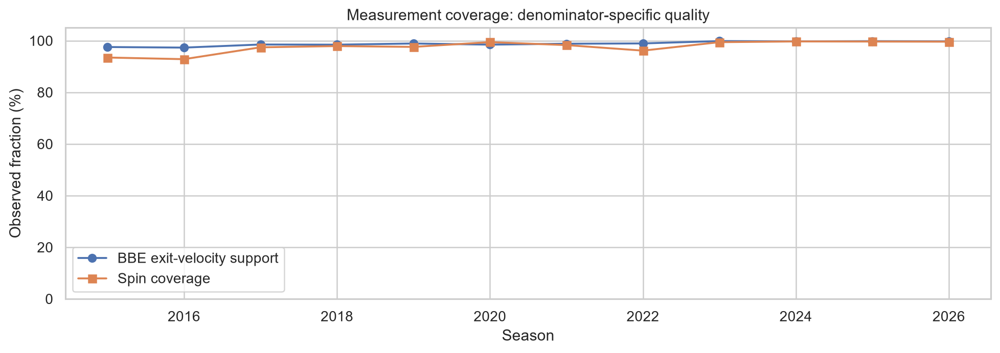

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/research_v9/figures/01_measurement_coverage.png')

In [217]:
scope = annual[['season','pitches','swings','whiffs','bbe','bbe_ev','vel_n','spin_n']].copy()
scope['whiff_per_swing'] = safe_rate(scope.whiffs, scope.swings)
scope['bbe_tracking'] = safe_rate(scope.bbe_ev, scope.bbe)
scope['velocity_tracking'] = safe_rate(scope.vel_n, scope.pitches)
scope['spin_tracking'] = safe_rate(scope.spin_n, scope.pitches)
scope['period'] = 'Aug 10–16 sample' if HISTORY_MODE == 'sample' else 'Full regular-season collection'
v9_table(scope.round(4), 'scope_and_measurement_support')
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(scope.season, scope.bbe_tracking*100, 'o-', label='BBE exit-velocity support')
ax.plot(scope.season, scope.spin_tracking*100, 's-', label='Spin coverage')
ax.set(xlabel='Season', ylabel='Observed fraction (%)',title='Measurement coverage: denominator-specific quality',ylim=(0,105))
ax.legend()
v9_figure(fig,'01_measurement_coverage')

## RQ64.2 | Uncertainty around historical swing-and-miss rates

Pitches within one game/player are not independent. Wilson intervals below are **binomial descriptive intervals**, not full cluster-robust research confidence intervals. Report them together with yearly opportunity counts and do not overinterpret small gaps.

,season,swings,whiffs,rate,low,high
0,2015,12320,2690,0.2183,0.2111,0.2257
1,2016,13438,2877,0.2141,0.2072,0.2211
2,2017,13261,2967,0.2237,0.2167,0.2309
3,2018,13203,2883,0.2184,0.2114,0.2255
4,2019,13498,3131,0.2320,0.2249,0.2392
5,2020,12044,2872,0.2385,0.2309,0.2462
6,2021,13829,3296,0.2383,0.2313,0.2455
7,2022,13576,3227,0.2377,0.2306,0.2449
8,2023,13010,3007,0.2311,0.2240,0.2385
9,2024,13046,3052,0.2339,0.2268,0.2413


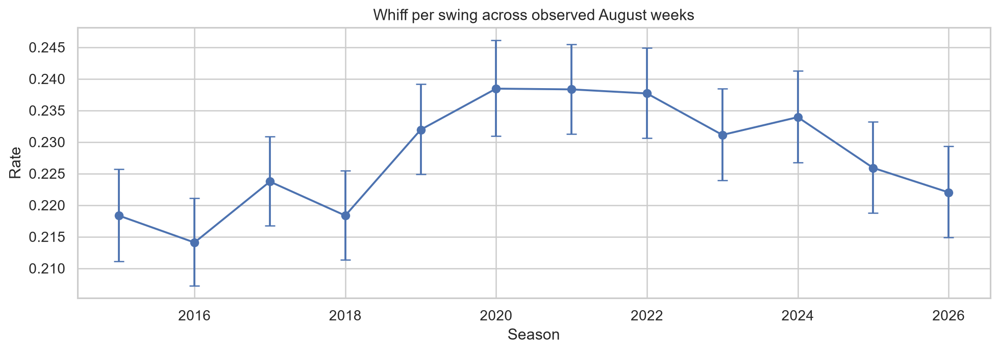

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/research_v9/figures/02_annual_whiff_uncertainty.png')

In [218]:
rates = annual[['season','swings','whiffs']].copy()
rates['rate'] = safe_rate(rates.whiffs,rates.swings)
low, high = proportion_confint(rates.whiffs, rates.swings,method='wilson')
rates['low'], rates['high'] = low, high
v9_table(rates.round(4),'annual_whiff_wilson')
fig,ax=plt.subplots(figsize=(11,4))
ax.errorbar(rates.season,rates.rate,yerr=[rates.rate-rates.low,rates.high-rates.rate],fmt='o-',capsize=4)
ax.set(title='Whiff per swing across observed August weeks',xlabel='Season',ylabel='Rate')
v9_figure(fig,'02_annual_whiff_uncertainty')

# Part 65 | Longitudinal Pitch-Selection and Count Context

**Question:** Are league-level strike-count outcomes stable, and how much might changing count distributions influence an annual Whiff trend? Conditioning on counts is descriptive; hitters and pitchers select pitches nonrandomly.

,season,strikes,swings,whiffs,rate
0,2015,0,3532,749,0.2121
1,2015,1,4228,910,0.2152
2,2015,2,4560,1031,0.2261
3,2016,0,3749,797,0.2126
4,2016,1,4559,1005,0.2204
5,2016,2,5130,1075,0.2096
6,2017,0,3774,840,0.2226
7,2017,1,4536,1028,0.2266
8,2017,2,4951,1099,0.2220
9,2018,0,3748,800,0.2134


Showing 30 of 36 rows; full table saved to CSV.


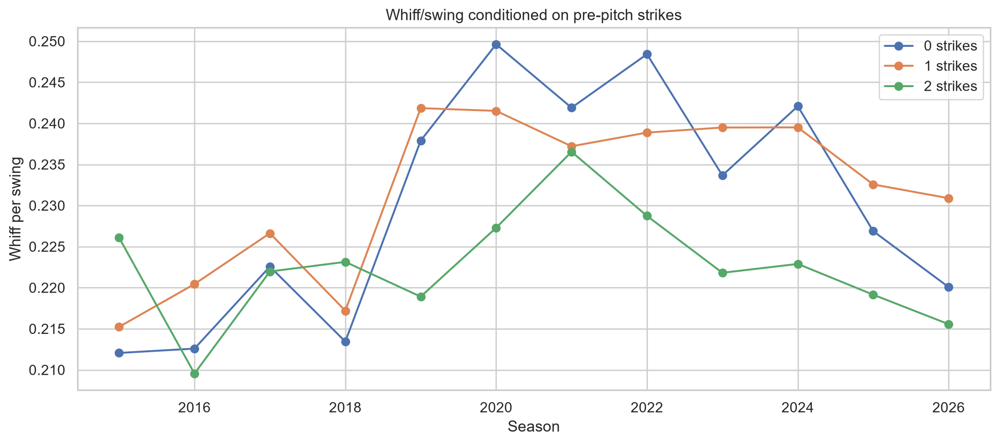

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/research_v9/figures/03_strike_count_whiff.png')

In [219]:
counts = hist['count'].copy()
counts = counts.loc[counts.strikes.isin([0,1,2]) & counts.swings.gt(0)].copy()
counts['whiff_rate'] = safe_rate(counts.whiffs, counts.swings)
count_wide = counts.pivot_table(index='season',columns='strikes',values='whiff_rate',aggfunc='mean')
count_support = counts.groupby(['season','strikes'],as_index=False)[['swings','whiffs']].sum()
count_support['rate'] = safe_rate(count_support.whiffs,count_support.swings)
v9_table(count_support.round(4), 'season_strike_count_whiff')
fig,ax=plt.subplots(figsize=(11,5))
for strike,g in count_support.groupby('strikes'):
    ax.plot(g.season,g.rate,marker='o',label=f'{int(strike)} strikes')
ax.set(title='Whiff/swing conditioned on pre-pitch strikes',xlabel='Season',ylabel='Whiff per swing')
ax.legend()
v9_figure(fig,'03_strike_count_whiff')

,season,fixed_2021_strike_mix,reference_coverage,whiff_rate
0,2015,0.2183,1.0,0.2183
1,2016,0.2141,1.0,0.2141
2,2017,0.2237,1.0,0.2237
3,2018,0.2183,1.0,0.2184
4,2019,0.2322,1.0,0.2320
5,2020,0.2386,1.0,0.2385
6,2021,0.2383,1.0,0.2383
7,2022,0.2379,1.0,0.2377
8,2023,0.2312,1.0,0.2311
9,2024,0.2341,1.0,0.2339


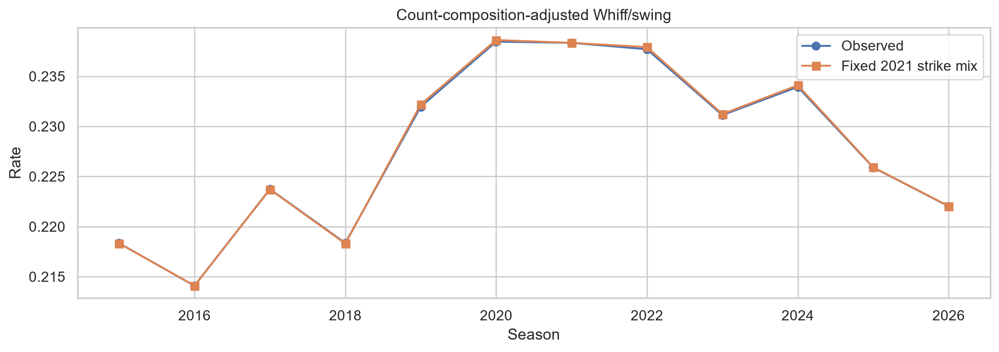

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/research_v9/figures/04_strike_mix_adjustment.png')

In [220]:
# Direct standardization: a fixed 2021 distribution of strike counts.
reference_count = count_support.loc[count_support.season.eq(2021)].set_index('strikes').swings
reference_count = reference_count / reference_count.sum()
standardized_count = []
for year, group in count_support.groupby('season'):
    r = group.set_index('strikes').rate.reindex(reference_count.index)
    observed = r.notna()
    standardized_count.append({
        'season':int(year),
        'fixed_2021_strike_mix':float(np.average(r[observed],weights=reference_count[observed])) if observed.any() else np.nan,
        'reference_coverage':float(reference_count[observed].sum())
    })
standardized_count = pd.DataFrame(standardized_count).merge(annual[['season','whiff_rate']],on='season')
v9_table(standardized_count.round(4),'count_standardized_whiff')
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(standardized_count.season,standardized_count.whiff_rate,'o-',label='Observed')
ax.plot(standardized_count.season,standardized_count.fixed_2021_strike_mix,'s-',label='Fixed 2021 strike mix')
ax.set(title='Count-composition-adjusted Whiff/swing',xlabel='Season',ylabel='Rate')
ax.legend();v9_figure(fig,'04_strike_mix_adjustment')

# Part 66 | Pitcher Repertoire Evolution: Matched Players

**Question:** Do individual pitchers change the share of fastballs they throw? Restrict to pitchers with sufficient observed pitches in *both* comparison years; changes may reflect role, injury or selection, not just strategy. In sample mode, some pitcher pairs will be ineligible.

,pitcher,share_2019,n_2019,share_2025,n_2025,share_change
0,434378,0.5286,210,0.5185,189,-0.0101
1,450203,0.5876,194,0.5051,99,-0.0826
2,477132,0.4667,90,0.3289,76,-0.1377
3,500779,0.5818,110,0.5618,89,-0.0200
4,506433,0.3804,92,0.5714,84,0.1910
5,518876,0.5408,98,0.5657,99,0.0248
6,527048,0.8523,88,0.6212,66,-0.2311
7,543243,0.4527,201,0.4889,180,0.0362
8,543294,0.5556,144,0.6047,86,0.0491
9,554430,0.8462,91,0.5444,180,-0.3017


Showing 30 of 39 rows; full table saved to CSV.


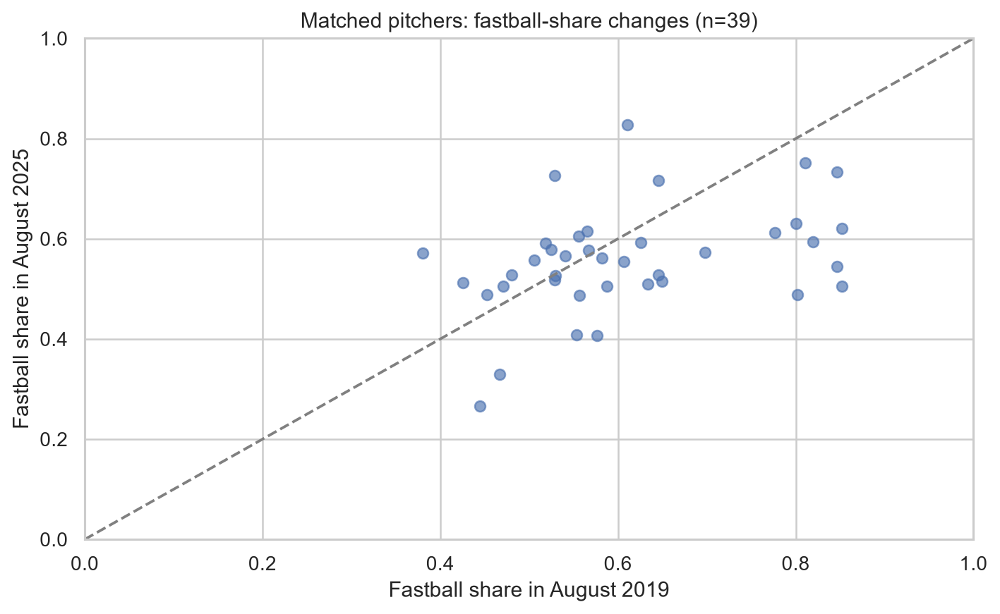

In [221]:
pitcher_family = hist['pitcher_pitch'][['season','pitcher','pitch_type','pitches']].copy()
pitcher_family['fastball'] = pitcher_family.pitch_type.isin(['FF','SI','FC'])
pitcher_family['fast_pitches'] = pitcher_family.pitches * pitcher_family.fastball.astype(int)
pitcher_year = pitcher_family.groupby(['season','pitcher'],as_index=False)[['pitches','fast_pitches']].sum()
pitcher_year['fast_share'] = safe_rate(pitcher_year.fast_pitches,pitcher_year.pitches)
pair_a = pitcher_year.loc[(pitcher_year.season==2019)&(pitcher_year.pitches>=65),['pitcher','fast_share','pitches']].rename(columns={'fast_share':'share_2019','pitches':'n_2019'})
pair_b = pitcher_year.loc[(pitcher_year.season==2025)&(pitcher_year.pitches>=65),['pitcher','fast_share','pitches']].rename(columns={'fast_share':'share_2025','pitches':'n_2025'})
matched_fast = pair_a.merge(pair_b,on='pitcher')
matched_fast['share_change'] = matched_fast.share_2025-matched_fast.share_2019
v9_table(matched_fast.round(4),'matched_pitcher_fastball_share_2019_2025')
if len(matched_fast)>=8:
    fig,ax=plt.subplots(figsize=(8,5))
    ax.scatter(matched_fast.share_2019,matched_fast.share_2025,alpha=.65)
    ax.plot([0,1],[0,1],'--',color='gray')
    ax.set(title=f'Matched pitchers: fastball-share changes (n={len(matched_fast)})',xlabel='Fastball share in August 2019',ylabel='Fastball share in August 2025',xlim=(0,1),ylim=(0,1))
    v9_figure(fig,'05_matched_pitcher_fastball_share')
else:
    print('Insufficient eligible matched pitchers; expand HISTORY_MODE rather than lowering thresholds.')

In [222]:
# Pitcher-level uncertainty: resample matched pitchers, not individual pitches.
if len(matched_fast)>=8:
    rng = np.random.default_rng(34)
    delta = matched_fast.share_change.to_numpy(dtype=float)
    bootstrap_means = np.array([rng.choice(delta,size=len(delta),replace=True).mean() for _ in range(1000)])
    v9_table(pd.DataFrame([{'eligible_pitchers':len(delta),'mean_change':float(delta.mean()),
        'bootstrap_low':float(np.quantile(bootstrap_means,.025)),
        'bootstrap_high':float(np.quantile(bootstrap_means,.975))}]).round(4),'matched_fastball_uncertainty')
else:
    print('Paired-player bootstrap skipped: not enough matched pitchers.')

,eligible_pitchers,mean_change,bootstrap_low,bootstrap_high
0,39,-0.0547,-0.0981,-0.0152


# Part 67 | Hitter Development Without Roster-Composition Confounding

**Question:** Do the same hitters exhibit changed Whiff/swing over multi-year periods? Compare shared hitters in two 3-season windows rather than shifting league rosters. The summary remains observational and eligible hitters are survivors, not a random cohort.

,batter,early_whiff,late_whiff,change_whiff
9,467793,0.1926,0.2182,0.0256
12,500743,0.1375,0.1524,0.0149
17,502671,0.2092,0.2500,0.0408
19,514888,0.2114,0.1818,-0.0296
21,518595,0.2907,0.3086,0.0179
22,518692,0.1913,0.1657,-0.0256
27,519317,0.2393,0.3333,0.0940
31,542303,0.2882,0.2759,-0.0124
43,543760,0.1613,0.2025,0.0412
44,543807,0.1969,0.2111,0.0143


Showing 30 of 51 rows; full table saved to CSV.


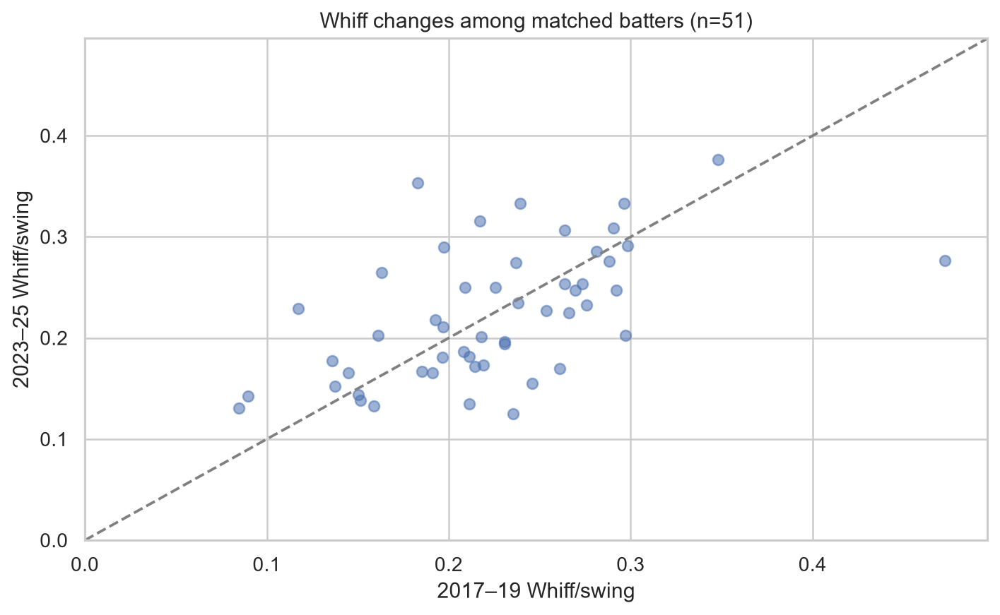

In [223]:
hitter_hist = hist['batter'][['season','batter','swings','whiffs','outzone','chases']].copy()
hitter_hist['period'] = np.select([
    hitter_hist.season.between(2017,2019),
    hitter_hist.season.between(2023,2025)
],['2017–2019','2023–2025'],default='Other')
hitter_hist = hitter_hist.loc[hitter_hist.period.ne('Other')]
period_h = hitter_hist.groupby(['batter','period'],as_index=False)[['swings','whiffs','outzone','chases']].sum()
hw = period_h.pivot(index='batter',columns='period',values=['swings','whiffs','outzone','chases'])
hw.columns = [f'{a}_{b}' for a,b in hw.columns]
hw = hw.dropna().reset_index()
hw = hw.loc[(hw['swings_2017–2019']>=75)&(hw['swings_2023–2025']>=75)].copy()
hw['early_whiff'] = hw['whiffs_2017–2019']/hw['swings_2017–2019']
hw['late_whiff'] = hw['whiffs_2023–2025']/hw['swings_2023–2025']
hw['change_whiff'] = hw.late_whiff-hw.early_whiff
v9_table(hw[['batter','early_whiff','late_whiff','change_whiff']].round(4),'matched_hitter_period_whiff')
if len(hw)>=8:
    fig,ax=plt.subplots(figsize=(8,5))
    ax.scatter(hw.early_whiff,hw.late_whiff,alpha=.55)
    lim=max(.4,float(hw[['early_whiff','late_whiff']].max().max()*1.05))
    ax.plot([0,lim],[0,lim],'--',color='gray')
    ax.set(xlim=(0,lim),ylim=(0,lim),title=f'Whiff changes among matched batters (n={len(hw)})',xlabel='2017–19 Whiff/swing',ylabel='2023–25 Whiff/swing')
    v9_figure(fig,'06_matched_hitter_whiff')
else:
    print('Matched hitter sample below display threshold; full-season data needed.')

,batter,early_posterior,late_posterior,posterior_change
9,467793,0.2076,0.2228,0.0152
12,500743,0.1877,0.1892,0.0015
17,502671,0.2165,0.2392,0.0226
19,514888,0.2188,0.1999,-0.0188
21,518595,0.2569,0.2640,0.0071
22,518692,0.2042,0.1888,-0.0154
27,519317,0.2340,0.2803,0.0463
31,542303,0.2659,0.2583,-0.0075
43,543760,0.1874,0.2121,0.0247
44,543807,0.2105,0.2199,0.0094


Showing 30 of 51 rows; full table saved to CSV.


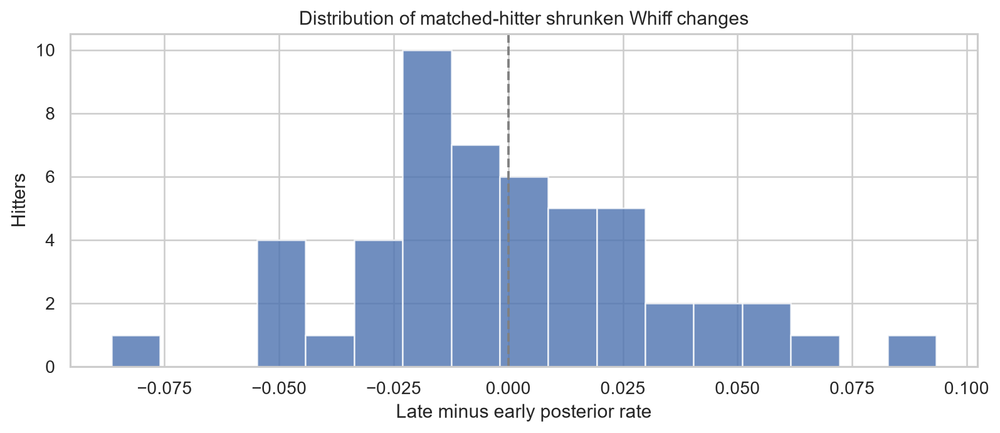

In [224]:
# Bayesian-shrunken estimates are descriptive stabilization, not a replacement for causal controls.
if len(hw):
    prior_mean = float(annual.whiffs.sum()/annual.swings.sum())
    strength = 100
    for period, side in [('2017–2019','early'),('2023–2025','late')]:
        hw[f'{side}_posterior'] = (hw[f'whiffs_{period}']+strength*prior_mean)/(hw[f'swings_{period}']+strength)
    hw['posterior_change'] = hw.late_posterior-hw.early_posterior
    v9_table(hw[['batter','early_posterior','late_posterior','posterior_change']].round(4),'matched_hitter_shrinkage')
    if len(hw)>=8:
        fig,ax=plt.subplots(figsize=(9,4))
        ax.hist(hw.posterior_change,bins=min(30,max(8,len(hw)//3)),alpha=.8)
        ax.axvline(0,color='gray',ls='--')
        ax.set(title='Distribution of matched-hitter shrunken Whiff changes',xlabel='Late minus early posterior rate',ylabel='Hitters')
        v9_figure(fig,'07_hitter_change_distribution')

# Part 68 | Platoon and Pitcher-Handedness Interactions

**Question:** How does Whiff/swing differ across the four handedness matchups over time? Aggregate rates use all observed pitches in the window; the exact matchup definition and minimum swing count are stated, and no interaction is interpreted as an experimental effect.

,season,matchup,swings,whiffs,whiff_rate
0,2015,L batter / L pitcher,1114,248,0.2226
1,2015,L batter / R pitcher,3919,799,0.2039
2,2015,R batter / L pitcher,2800,567,0.2025
3,2015,R batter / R pitcher,4487,1076,0.2398
4,2016,L batter / L pitcher,1027,243,0.2366
5,2016,L batter / R pitcher,4601,918,0.1995
6,2016,R batter / L pitcher,2605,516,0.1981
7,2016,R batter / R pitcher,5205,1200,0.2305
8,2017,L batter / L pitcher,965,226,0.2342
9,2017,L batter / R pitcher,4573,963,0.2106


Showing 30 of 48 rows; full table saved to CSV.


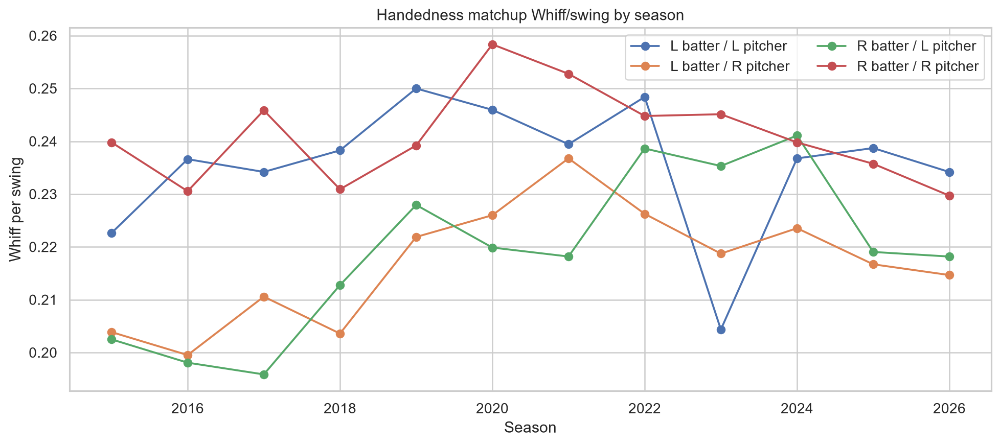

In [225]:
platoon = hist['matchup'][['season','stand','p_throws','swings','whiffs','pitches']].copy()
platoon=platoon.loc[platoon.swings.ge(30) & platoon.stand.isin(['L','R']) & platoon.p_throws.isin(['L','R'])].copy()
platoon['matchup'] = platoon.stand+' batter / '+platoon.p_throws+' pitcher'
platoon['whiff_rate'] = safe_rate(platoon.whiffs, platoon.swings)
v9_table(platoon[['season','matchup','swings','whiffs','whiff_rate']].round(4),'platoon_matchup_whiff')
if not platoon.empty:
    fig,ax=plt.subplots(figsize=(11,5))
    for matchup, subset in platoon.groupby('matchup'):
        ax.plot(subset.season,subset.whiff_rate,marker='o',label=matchup)
    ax.set(title='Handedness matchup Whiff/swing by season',xlabel='Season',ylabel='Whiff per swing')
    ax.legend(ncol=2)
    v9_figure(fig,'08_platoon_whiff_trend')

# Part 69 | Pitch-Environment Effects: Aggregation Bias

**Question:** Do physical features and Whiff/swing covary within pitch types and years? Fit a weighted linear descriptive model to pitch-type/year aggregates, controlling for classification and year. This is **not a pitch-level causal or predictive model**, and aggregate dependence limits standard-error interpretation.

,term,coefficient,ci_low,ci_high
0,Intercept,-0.72973,-2.66741,1.20796
1,C(pitch_type)[T.CU],0.08505,-0.06684,0.23694
2,C(pitch_type)[T.FC],-0.12708,-0.21520,-0.03896
3,C(pitch_type)[T.FF],-0.20968,-0.40582,-0.01354
4,C(pitch_type)[T.FS],0.03254,-0.01614,0.08122
5,C(pitch_type)[T.KC],0.08485,-0.01093,0.18063
6,C(pitch_type)[T.SI],-0.25694,-0.44045,-0.07343
7,C(pitch_type)[T.SL],0.03430,0.01685,0.05174
8,C(pitch_type)[T.ST],0.06251,-0.01740,0.14242
9,C(season)[T.2021],-0.00230,-0.02414,0.01954


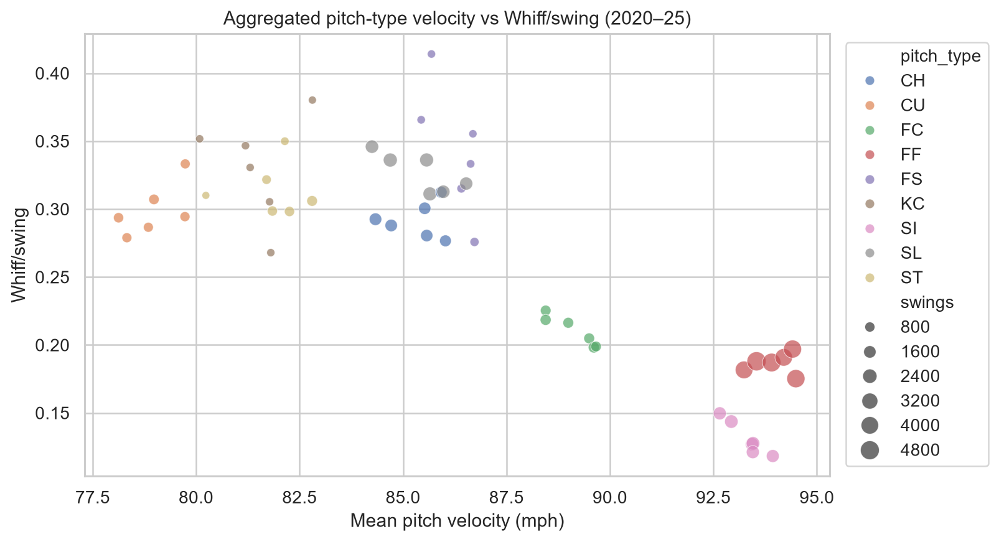

In [226]:
import statsmodels.formula.api as smf
phys = pitch_history[['season','pitch_type','pitches','swings','whiffs','vel_sum','vel_n','spin_sum','spin_n']].copy()
phys = phys.loc[phys.season.between(2020,2025) & phys.swings.ge(100) & phys.vel_n.ge(100)].copy()
phys['velocity'] = safe_rate(phys.vel_sum,phys.vel_n)
phys['spin'] = safe_rate(phys.spin_sum,phys.spin_n)
phys['whiff_rate'] = safe_rate(phys.whiffs,phys.swings)
common = phys.groupby('pitch_type').season.nunique().loc[lambda x:x>=3].index
phys = phys.loc[phys.pitch_type.isin(common)].dropna(subset=['velocity','whiff_rate'])
if len(phys)>12 and phys.pitch_type.nunique()>1:
    result_wls = smf.wls('whiff_rate ~ velocity + C(pitch_type) + C(season)', data=phys,weights=phys.swings).fit(cov_type='HC3')
    coef = pd.DataFrame({'term':result_wls.params.index,'coefficient':result_wls.params.values,
                         'ci_low':result_wls.conf_int().iloc[:,0].values,
                         'ci_high':result_wls.conf_int().iloc[:,1].values})
    v9_table(coef.round(5),'pitch_type_year_weighted_associations')
    fig,ax=plt.subplots(figsize=(9,5))
    sns.scatterplot(data=phys,x='velocity',y='whiff_rate',hue='pitch_type',size='swings',sizes=(25,150),alpha=.7,ax=ax)
    ax.set(title='Aggregated pitch-type velocity vs Whiff/swing (2020–25)',xlabel='Mean pitch velocity (mph)',ylabel='Whiff/swing')
    ax.legend(bbox_to_anchor=(1.01,1),loc='upper left')
    v9_figure(fig,'09_velocity_whiff_aggregates')
else:
    print('Aggregate regression skipped: insufficient pitch-year observations.')

# Part 70 | Modern-Era Input Distribution Shift (2020–2026)

**Question:** Does the 2026 evaluation population look different from the 2020–24 training population? Use one-dimensional Wasserstein distances scaled by training IQR. This flags marginal drift, not causal deterioration. Plate location changes in 2026 require independent interpretation.

,feature,period,reference_n,period_n,wasserstein,scaled_distance
0,release_speed,2025,20500,4093,0.8536,0.0938
1,release_speed,2026,20500,4056,0.7570,0.0832
2,release_spin_rate,2025,20362,4093,48.1071,0.1351
3,release_spin_rate,2026,20362,4055,46.0241,0.1293
4,pfx_x,2025,20500,4093,0.0477,0.0336
5,pfx_x,2026,20500,4056,0.0302,0.0213
6,pfx_z,2025,20500,4093,0.0318,0.0300
7,pfx_z,2026,20500,4056,0.0286,0.0269
8,plate_x,2025,20500,4093,0.0160,0.0142
9,plate_x,2026,20500,4056,0.0250,0.0221


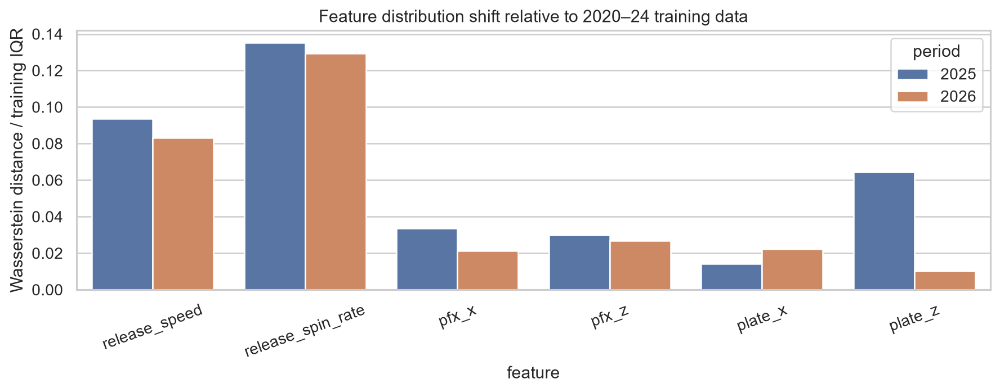

In [227]:
shift_fields = ['release_speed','release_spin_rate','pfx_x','pfx_z','plate_x','plate_z']
shift=[]
for field in shift_fields:
    ref = pd.to_numeric(training[field],errors='coerce').dropna().to_numpy(dtype=float)
    if len(ref)<100:continue
    scale = np.subtract(*np.quantile(ref,[.75,.25]))
    for year,part in [('2025',validation_history),('2026',test_history)]:
        values = pd.to_numeric(part[field],errors='coerce').dropna().to_numpy(dtype=float)
        if len(values)>=50:
            shift.append({'feature':field,'period':year,'reference_n':len(ref),'period_n':len(values),
                          'wasserstein':float(wasserstein_distance(ref,values)),
                          'scaled_distance':float(wasserstein_distance(ref,values)/scale) if scale>0 else np.nan})
shift_df=pd.DataFrame(shift)
v9_table(shift_df.round(4),'feature_shift_wasserstein')
if not shift_df.empty:
    fig,ax=plt.subplots(figsize=(10,4))
    sns.barplot(data=shift_df,x='feature',y='scaled_distance',hue='period',ax=ax)
    ax.tick_params(axis='x',rotation=20)
    ax.set(title='Feature distribution shift relative to 2020–24 training data',ylabel='Wasserstein distance / training IQR')
    v9_figure(fig,'10_covariate_shift')

# Part 71 | Model Feature Ablation and Nonlinear Benchmark

**Question:** What value do measured pitch physics and plate-location information add? Train on 2020–24, inspect 2025 and 2026 separately, and compare pre-pitch context, measured pitch physics without location, and physics **with** location. Because 2026 has been inspected, these are exploratory benchmarks rather than prospective final-test claims.

,feature_set,model,period,n,Brier,PR_AUC,ROC_AUC
0,Context,HistGB,2025 validation,4093,0.0913,0.1479,0.6326
1,Context,HistGB,2026 exploratory,4056,0.0921,0.1573,0.6360
2,Context,Logistic,2025 validation,4093,0.0916,0.1445,0.6259
3,Context,Logistic,2026 exploratory,4056,0.0921,0.1521,0.6408
4,Context + measured physics,HistGB,2025 validation,4093,0.0914,0.1503,0.6398
5,Context + measured physics,HistGB,2026 exploratory,4056,0.0927,0.1433,0.6255
6,Context + measured physics,Logistic,2025 validation,4093,0.0915,0.1508,0.6344
7,Context + measured physics,Logistic,2026 exploratory,4056,0.0923,0.1508,0.6374
8,Context + physics + location,HistGB,2025 validation,4093,0.0878,0.2155,0.7166
9,Context + physics + location,HistGB,2026 exploratory,4056,0.0887,0.2092,0.7262


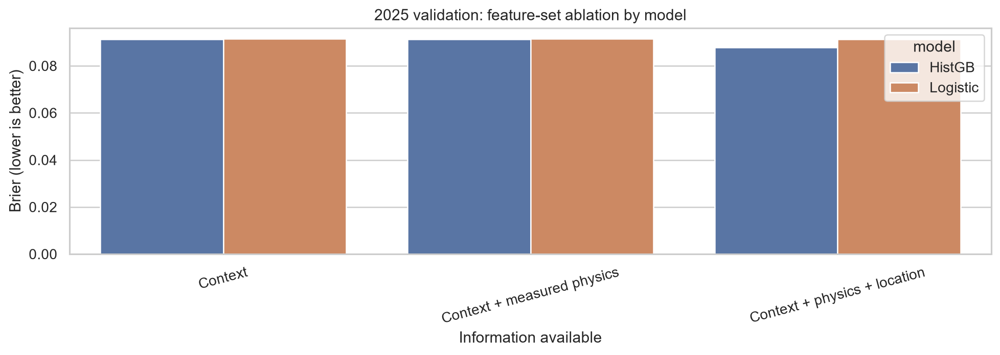

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/research_v9/figures/11_feature_set_ablation.png')

In [228]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, roc_auc_score, average_precision_score

feature_sets = {
    'Context': ['pitch_type','stand','p_throws','balls','strikes'],
    'Context + measured physics': ['pitch_type','stand','p_throws','balls','strikes','release_speed','release_spin_rate','pfx_x','pfx_z'],
    'Context + physics + location': ['pitch_type','stand','p_throws','balls','strikes','release_speed','release_spin_rate','pfx_x','pfx_z','plate_x','plate_z']
}
def v9_model(cols, kind='HistGB'):
    cats=[x for x in cols if x in ['pitch_type','stand','p_throws']]
    nums=[x for x in cols if x not in cats]
    prep=ColumnTransformer([
        ('cat',Pipeline([('fill',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cats),
        ('num',Pipeline([('fill',SimpleImputer(strategy='median')),('scale',StandardScaler())]),nums)
    ])
    estimator=(HistGradientBoostingClassifier(max_iter=90,max_leaf_nodes=13,min_samples_leaf=35,random_state=42)
               if kind=='HistGB' else LogisticRegression(max_iter=1000))
    return Pipeline([('prep',prep),('estimator',estimator)])

ablation=[]
for desc,cols in feature_sets.items():
    for kind in ['HistGB','Logistic']:
        estimator=v9_model(cols,kind)
        estimator.fit(training[cols],training.is_whiff)
        for name,segment in [('2025 validation',validation_history),('2026 exploratory',test_history)]:
            p=estimator.predict_proba(segment[cols])[:,1]
            ablation.append({'feature_set':desc,'model':kind,'period':name,'n':len(segment),
                            'Brier':brier_score_loss(segment.is_whiff,p),
                            'PR_AUC':average_precision_score(segment.is_whiff,p),
                            'ROC_AUC':roc_auc_score(segment.is_whiff,p)})
ablation_df=pd.DataFrame(ablation)
v9_table(ablation_df.round(4),'model_feature_ablation')
fig,ax=plt.subplots(figsize=(11,4))
sns.barplot(data=ablation_df.loc[ablation_df.period.eq('2025 validation')],x='feature_set',y='Brier',hue='model',errorbar=None,ax=ax)
ax.set(title='2025 validation: feature-set ablation by model',ylabel='Brier (lower is better)',xlabel='Information available')
ax.tick_params(axis='x',rotation=15)
v9_figure(fig,'11_feature_set_ablation')

# Part 72 | Model Reliability by Hitter and Pitch Type

**Question:** Does the frozen model make systematically biased predictions in material subgroups? Use only segments with at least 80 pitches. Subgroup gaps are descriptive post-evaluation diagnostics, not grounds for retroactive 2026 model selection.

,feature,group,n,observed_rate,predicted_rate,calibration_gap,Brier
11,p_throws,R,2737,0.1052,0.1156,-0.0103,0.0888
10,p_throws,L,1319,0.1046,0.1165,-0.0118,0.0875
3,pitch_type,FF,1306,0.0881,0.0977,-0.0097,0.0763
5,pitch_type,SI,665,0.0391,0.0699,-0.0308,0.0378
6,pitch_type,SL,518,0.1622,0.1557,0.0064,0.1233
0,pitch_type,CH,482,0.1515,0.1556,-0.0042,0.1234
7,pitch_type,ST,326,0.1411,0.1461,-0.0050,0.1241
2,pitch_type,FC,314,0.0955,0.1058,-0.0102,0.0874
1,pitch_type,CU,260,0.1038,0.1238,-0.0200,0.0831
4,pitch_type,FS,111,0.1351,0.1441,-0.0090,0.1089


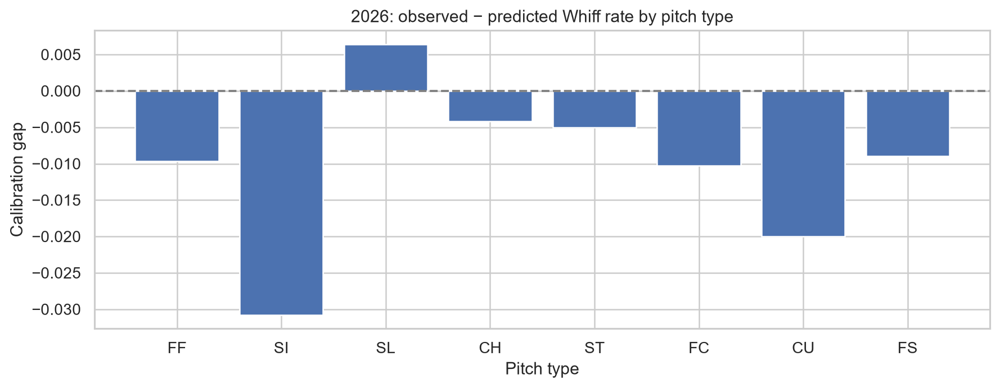

In [229]:
sub=test_history[['pitch_type','stand','p_throws','batter','pitcher','is_whiff','game_pk']].copy()
sub['prediction']=np.asarray(prob_2026,dtype=float)
sub['sq_error']=(sub.is_whiff-sub.prediction)**2
subgroup_rows=[]
for key in ['pitch_type','stand','p_throws']:
    for value,grp in sub.groupby(key):
        if len(grp)<80:continue
        subgroup_rows.append({'feature':key,'group':str(value),'n':len(grp),'observed_rate':grp.is_whiff.mean(),
                              'predicted_rate':grp.prediction.mean(),'calibration_gap':grp.is_whiff.mean()-grp.prediction.mean(),
                              'Brier':grp.sq_error.mean()})
subgroup_df=pd.DataFrame(subgroup_rows).sort_values(['feature','n'],ascending=[True,False])
v9_table(subgroup_df.round(4),'2026_subgroup_calibration')
if not subgroup_df.empty:
    frame=subgroup_df.loc[subgroup_df.feature.eq('pitch_type')].head(12)
    if len(frame):
        fig,ax=plt.subplots(figsize=(10,4))
        ax.bar(frame.group,frame.calibration_gap)
        ax.axhline(0,color='gray',ls='--')
        ax.set(title='2026: observed − predicted Whiff rate by pitch type',xlabel='Pitch type',ylabel='Calibration gap')
        v9_figure(fig,'12_subgroup_calibration')

,role,player_id,n,actual,expected,rate_gap,shrunk_gap
0,pitcher,656302,33,3,3.6508,-0.0197,-0.0049
1,pitcher,663554,30,2,2.8156,-0.0272,-0.0063
2,pitcher,663776,31,0,2.9259,-0.0944,-0.0223
3,pitcher,676440,32,1,3.3008,-0.0719,-0.0174
4,pitcher,677960,31,3,4.0869,-0.0351,-0.0083
5,pitcher,686613,30,2,3.2467,-0.0416,-0.0096
6,pitcher,687312,31,3,3.2188,-0.0071,-0.0017
7,pitcher,691587,33,7,4.7467,0.0683,0.0169
8,pitcher,701656,32,6,5.1442,0.0267,0.0065
9,pitcher,702070,37,6,3.5689,0.0657,0.0177


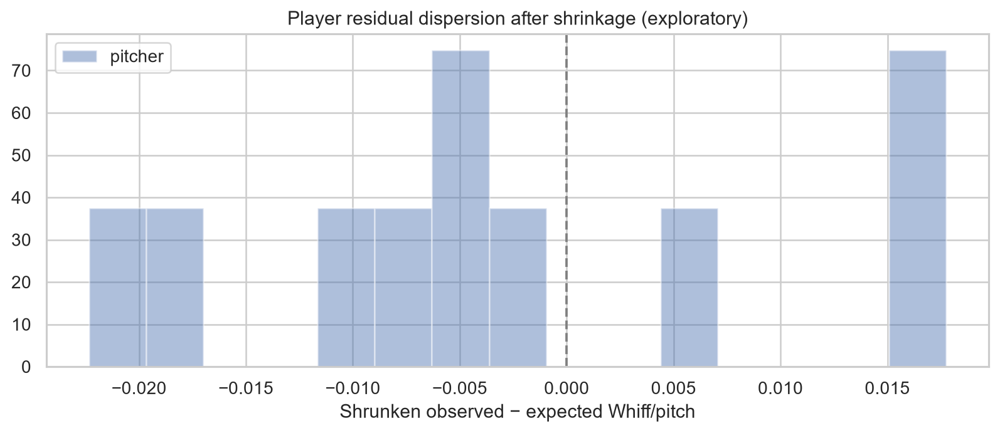

In [230]:
# Player-level empirical Bayes residuals: shrink noisy rate-minus-prediction contrasts.
player_residuals=[]
for col in ['pitcher','batter']:
    g=sub.groupby(col).agg(n=('is_whiff','size'),actual=('is_whiff','sum'),expected=('prediction','sum')).reset_index()
    g=g.loc[g.n.ge(30)].copy()
    g['rate_gap']=(g.actual-g.expected)/g.n
    g['shrunk_gap']=(g.actual-g.expected)/(g.n+100)
    g['role']=col
    g=g.rename(columns={col:'player_id'})
    player_residuals.append(g[['role','player_id','n','actual','expected','rate_gap','shrunk_gap']])
player_residuals=pd.concat(player_residuals,ignore_index=True) if player_residuals else pd.DataFrame()
v9_table(player_residuals.round(4),'player_expected_vs_observed_whiff')
if not player_residuals.empty:
    fig,ax=plt.subplots(figsize=(9,4))
    for role,g in player_residuals.groupby('role'):
        values=g['shrunk_gap'].dropna().to_numpy(dtype=float)
        if len(values)>=2:
            ax.hist(values,bins=15,alpha=.45,density=True,label=role)
    ax.axvline(0,color='gray',ls='--')
    ax.set(title='Player residual dispersion after shrinkage (exploratory)',xlabel='Shrunken observed − expected Whiff/pitch')
    ax.legend()
    v9_figure(fig,'13_player_expected_residuals')

# Part 73 | Time-Window Selection and Scientific Limits

Some changes may reflect the week sampled, the current roster, changes in tracking systems, and classification conventions. The historical data provide **August cross-sections**, not annual season estimates. Repeat analyses using `full` before presenting long-term league conclusions. Do not compare 2026 pitch-location distributions to past years without a coordinate-normalization strategy.

In [231]:
import json
ledger={
    'project':'MLB Statcast: Comprehensive Baseball Analytics & Predictive Modeling',
    'source':'Statcast regular-season pitch tracking via pybaseball',
    'year_range':[int(annual.season.min()),int(annual.season.max())],
    'mode':HISTORY_MODE,
    'denominator':'All pitch rates use their defined pitch/swing/out-of-zone/tracked-BBE opportunities',
    'sample_dates':'August 10–16 per season' if HISTORY_MODE=='sample' else 'Regular-season date ranges',
    'observed_pitches':int(annual.pitches.sum()),
    'new_figures':len(list(V9_FIG.glob('*.png'))),
    '2025':'Retrospective validation; prior iterations consulted results',
    '2026':'Exploratory post-hoc evaluation; not untouched final test',
    'tracking_changes':'Check measuring systems and variable definitions before across-era comparisons',
    'model_scope':'Selected feature sets include observed post-release pitch physics, not guaranteed pre-pitch predictions',
    'data_quality_note':'Matched player samples are survivor cohorts and cannot support population-wide aging claims',
}
(V9_DIR/'research_manifest.json').write_text(json.dumps(ledger,indent=2),encoding='utf-8')
v9_table(pd.DataFrame([{'field':k,'value':str(v)} for k,v in ledger.items()]),'research_evidence_ledger')
print('V9 figures available:', len(list(V9_FIG.glob('*.png'))))

,field,value
0,project,MLB Statcast: Comprehensive Baseball Analytics...
1,source,Statcast regular-season pitch tracking via pyb...
2,year_range,"[2015, 2026]"
3,mode,sample
4,denominator,All pitch rates use their defined pitch/swing/...
5,sample_dates,August 10–16 per season
6,observed_pitches,332598
7,new_figures,13
8,2025,Retrospective validation; prior iterations con...
9,2026,Exploratory post-hoc evaluation; not untouched...


V9 figures available: 13


# Part 74 | Research Summary & Submission Checklist

**Results must be written from the actual newly executed output** and include measured denominators, confidence/uncertainty, potential sampling bias, model validation period and limitations. Summary claims should distinguish season-wide evidence from the seven-day August cross-section.

1. Run Part 64 onward and check all new tables and inline charts.
2. Review `outputs/history_2015_2026/<mode>/research_v9`.
3. For final submission, run `HISTORY_MODE="full"` and verify all 12 seasons and coverage before describing full-season historical trends.
4. Treat the existing 2025–2026 comparisons as exploratory because these periods have already informed project revisions.
5. Report both positive and negative model results and avoid interpreting associations as interventions.

**No new performance numbers are prefilled in this section.**

# Division VI — Final Evidence Audit

The analyses below use results generated by the historical sections; they do not redownload data. This uploaded notebook includes the user's completed execution of these cells. The diagnostics are retrospective, and their figures are displayed inline and saved as PNG.

### Part 75 | Decomposing Whiff per Pitch

**RQ75.** Decompose Whiff per Pitch into swing frequency and Whiff conditional on swinging. This is an accounting identity, not a causal attribution.


,pitches,season,whiffs,swings,swing_per_pitch,whiff_per_swing,whiff_per_pitch,swing_contribution,conditional_whiff_contribution,observed_rate_difference
0,26317,2015,2690,12320,0.46814,0.21834,0.10222,0.00000,0.00000,0.00000
1,28606,2016,2877,13438,0.46976,0.21409,0.10057,0.00035,-0.00199,-0.00164
2,28978,2017,2967,13261,0.45762,0.22374,0.10239,-0.00232,0.00250,0.00017
3,28129,2018,2883,13203,0.46937,0.21836,0.10249,0.00027,0.00001,0.00028
4,28373,2019,3131,13498,0.47573,0.23196,0.11035,0.00171,0.00643,0.00814
5,26270,2020,2872,12044,0.45847,0.23846,0.10933,-0.00221,0.00932,0.00711
6,29042,2021,3296,13829,0.47617,0.23834,0.11349,0.00183,0.00944,0.01128
7,28103,2022,3227,13576,0.48308,0.23770,0.11483,0.00341,0.00921,0.01261
8,27123,2023,3007,13010,0.47967,0.23113,0.11087,0.00259,0.00606,0.00865
9,27152,2024,3052,13046,0.48048,0.23394,0.11240,0.00279,0.00740,0.01019


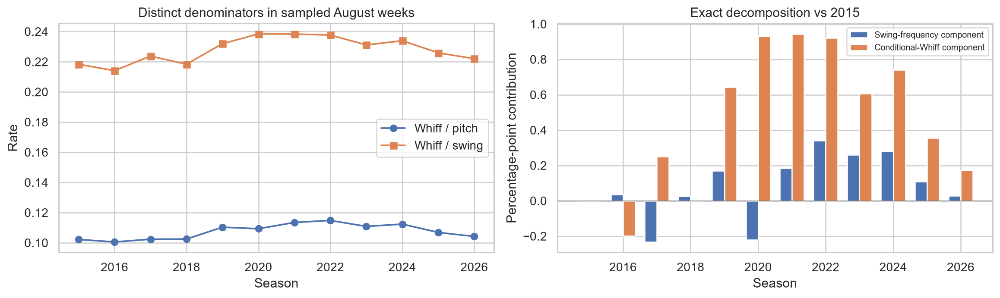

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/submission_v10/75_whiff_rate_decomposition.png')

In [232]:
import numpy as np

import pandas as pd

def whiff_identity_decomposition(annual: pd.DataFrame, reference_year: int=2015) -> pd.DataFrame:
    """Exact symmetric decomposition of whiffs/pitch = swings/pitch * whiffs/swing."""
    required = {'season', 'pitches', 'swings', 'whiffs'}
    missing = required.difference(annual.columns)
    if missing:
        raise ValueError(f'Missing columns: {sorted(missing)}')
    d = annual[list(required)].copy().sort_values('season')
    if d[['pitches', 'swings']].le(0).any().any():
        raise ValueError('Nonpositive pitch/swing denominator')
    if d.whiffs.gt(d.swings).any() or d.swings.gt(d.pitches).any():
        raise ValueError('Invalid event containment')
    d['swing_per_pitch'] = d.swings / d.pitches
    d['whiff_per_swing'] = d.whiffs / d.swings
    d['whiff_per_pitch'] = d.whiffs / d.pitches
    ref = d[d.season.eq(reference_year)]
    if len(ref) != 1:
        raise ValueError('Reference season missing or duplicated')
    s0, q0 = map(float, ref[['swing_per_pitch', 'whiff_per_swing']].iloc[0])
    s, q = (d['swing_per_pitch'], d['whiff_per_swing'])
    d['swing_contribution'] = (s - s0) * (q + q0) / 2
    d['conditional_whiff_contribution'] = (q - q0) * (s + s0) / 2
    d['observed_rate_difference'] = d.whiff_per_pitch - s0 * q0
    assert np.allclose(d.swing_contribution + d.conditional_whiff_contribution, d.observed_rate_difference, atol=1e-10)
    return d

def calibration_by_group(frame: pd.DataFrame, group: str, minimum_n: int=100) -> pd.DataFrame:
    """Descriptive model residuals with Poisson-binomial normal approximation + BH FDR."""
    from scipy.stats import norm
    from statsmodels.stats.multitest import multipletests
    if not {group, 'actual', 'probability'}.issubset(frame.columns):
        raise ValueError('Missing group, actual, or probability')
    rows = []
    for label, g in frame.groupby(group, dropna=True):
        n = len(g)
        if n < minimum_n:
            continue
        y = g.actual.to_numpy(dtype=float)
        p = g.probability.to_numpy(dtype=float)
        if not (np.isfinite(p).all() and (p >= 0).all() and (p <= 1).all()):
            raise ValueError('Probabilities must be finite and in [0, 1]')
        residual = float(y.sum() - p.sum())
        variance = float(np.sum(p * (1 - p)))
        z = residual / np.sqrt(variance) if variance > 0 else np.nan
        rows.append(dict(group=str(label), n=n, observed=float(y.mean()), expected=float(p.mean()), gap=residual / n, z=z, p_value=float(2 * norm.sf(abs(z))) if np.isfinite(z) else np.nan))
    result = pd.DataFrame(rows)
    if len(result):
        mask = result.p_value.notna()
        result['q_value'] = np.nan
        if mask.any():
            result.loc[mask, 'q_value'] = multipletests(result.loc[mask, 'p_value'], method='fdr_bh')[1]
        result = result.sort_values('n', ascending=False).reset_index(drop=True)
    return result

def season_integrity(annual: pd.DataFrame, expected_years=range(2015, 2027)) -> pd.DataFrame:
    """Enforce season counts and event denominator invariants."""
    a = annual.copy()
    for name in ('pitches', 'swings', 'whiffs', 'bbe', 'bbe_ev'):
        if name not in a:
            raise ValueError(f'Missing {name}')
    a['valid_events'] = a.pitches.ge(a.swings) & a.swings.ge(a.whiffs) & a.bbe.ge(a.bbe_ev) & a.pitches.ge(a.bbe)
    a['has_rows'] = a.pitches.gt(0)
    a['expected_year'] = a.season.isin(list(expected_years))
    a['bbe_ev_coverage'] = a.bbe_ev / a.bbe.replace(0, np.nan)
    return a[['season', 'pitches', 'valid_events', 'has_rows', 'expected_year', 'bbe_ev_coverage']]

V10_DIR = HISTORY_DIR / 'submission_v10'
V10_DIR.mkdir(parents=True, exist_ok=True)
def submission_plot(fig, name):
    from IPython.display import display, Image
    path = V10_DIR / f'{name}.png'
    fig.tight_layout(); fig.savefig(path,dpi=180,bbox_inches='tight')
    display(Image(filename=str(path)))
    plt.close(fig)
    return path
ident = whiff_identity_decomposition(annual, reference_year=2015)
display(ident.round(5))
ident.to_csv(V10_DIR/'whiff_decomposition.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(13,4))
axes[0].plot(ident.season,ident.whiff_per_pitch,marker='o',label='Whiff / pitch')
axes[0].plot(ident.season,ident.whiff_per_swing,marker='s',label='Whiff / swing')
axes[0].set(title='Distinct denominators in sampled August weeks',xlabel='Season',ylabel='Rate')
axes[0].legend()
axes[1].bar(ident.season-0.18,100*ident.swing_contribution,width=.36,label='Swing-frequency component')
axes[1].bar(ident.season+0.18,100*ident.conditional_whiff_contribution,width=.36,label='Conditional-Whiff component')
axes[1].axhline(0,color='gray',lw=.8)
axes[1].set(title='Exact decomposition vs 2015',xlabel='Season',ylabel='Percentage-point contribution')
axes[1].legend(fontsize=8)
submission_plot(fig,'75_whiff_rate_decomposition')

### Part 76 | Integrity gate and measurement eligibility

**RQ76.** Are historical denominators internally consistent, and which seasons have incomplete tracked BBE? Do not confuse high EV coverage with a guarantee of full-season representativeness.

In [233]:
integrity = season_integrity(annual)
display(integrity.round(4))
integrity.to_csv(V10_DIR/'integrity_by_year.csv',index=False)
assert integrity.valid_events.all() and integrity.has_rows.all(), 'Invalid event hierarchy or empty season'
assert set(integrity.season)==set(HISTORY_YEARS), 'Missing historical season'
print('PASS: every requested year has positive data and event denominators satisfy containment.')
print('Scope:',HISTORY_MODE, '| 2015–2026: August 10–16 per year' if HISTORY_MODE=='sample' else '| Full regular-season date windows')

,season,pitches,valid_events,has_rows,expected_year,bbe_ev_coverage
0,2015,26317,True,True,True,0.9757
1,2016,28606,True,True,True,0.9734
2,2017,28978,True,True,True,0.9854
3,2018,28129,True,True,True,0.9848
4,2019,28373,True,True,True,0.9893
5,2020,26270,True,True,True,0.9849
6,2021,29042,True,True,True,0.9884
7,2022,28103,True,True,True,0.9896
8,2023,27123,True,True,True,0.9987
9,2024,27152,True,True,True,0.9974


PASS: every requested year has positive data and event denominators satisfy containment.
Scope: sample | 2015–2026: August 10–16 per year


### Part 77 | Are pitch-type calibration gaps larger than chance variation?

**RQ77.** Quantify observed-minus-predicted Whiff gaps for 2026 pitch types. Report multiplicity-adjusted q-values rather than ranking noisy gaps. This is **post-hoc exploratory diagnostics**, not a new model-selection procedure. The Poisson-binomial approximation conditions on the model probabilities and does not fully account for within-game correlation.

,group,n,observed,expected,gap,z,p_value,q_value
0,FF,1306,0.0881,0.0977,-0.0097,-1.2007,0.2299,0.7970
1,SI,665,0.0391,0.0699,-0.0308,-3.1423,0.0017,0.0134
2,SL,518,0.1622,0.1557,0.0064,0.4174,0.6764,0.7970
3,CH,482,0.1515,0.1556,-0.0042,-0.2573,0.7970,0.7970
4,ST,326,0.1411,0.1461,-0.0050,-0.2632,0.7924,0.7970
5,FC,314,0.0955,0.1058,-0.0102,-0.6001,0.5485,0.7970
6,CU,260,0.1038,0.1238,-0.0200,-1.0253,0.3052,0.7970
7,FS,111,0.1351,0.1441,-0.0090,-0.2770,0.7818,0.7970


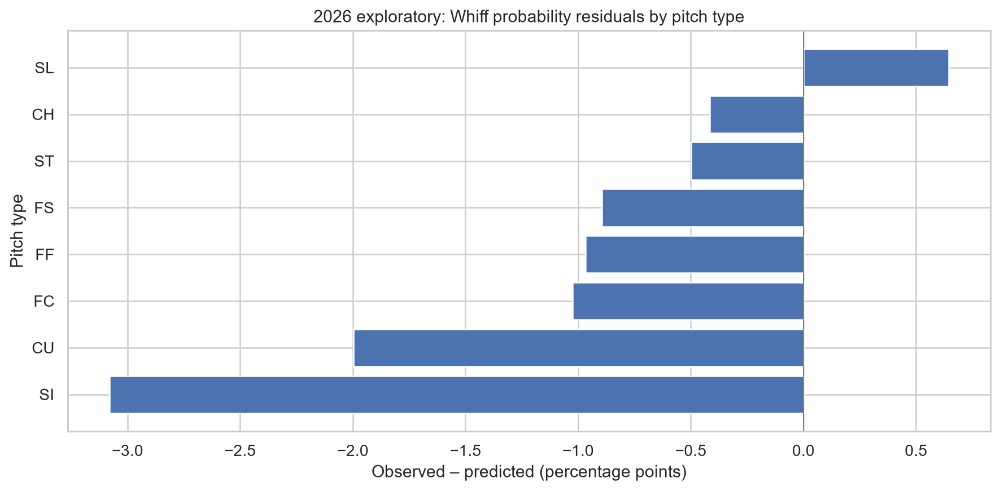

In [234]:
checks = test_history[['game_pk','pitch_type','stand','is_whiff']].copy()
checks['actual']=checks.is_whiff.astype(int).to_numpy()
checks['probability']=np.asarray(prob_2026,dtype=float)
calibration_pitch = calibration_by_group(checks,'pitch_type',minimum_n=100)
display(calibration_pitch.round(4))
calibration_pitch.to_csv(V10_DIR/'pitch_type_calibration_fdr.csv',index=False)
if not calibration_pitch.empty:
    p=calibration_pitch.sort_values('gap')
    fig,ax=plt.subplots(figsize=(10,5))
    ax.barh(p.group,100*p.gap)
    ax.axvline(0,color='gray',lw=.8)
    ax.set(title='2026 exploratory: Whiff probability residuals by pitch type',xlabel='Observed – predicted (percentage points)',ylabel='Pitch type')
    submission_plot(fig,'77_2026_pitch_type_calibration_gaps')

### Part 78 | Probability recalibration experiment on time-ordered data

**RQ78.** With the base model frozen after training on 2020–2024, can 2025 predictions estimate an isotonic or sigmoid calibration map that changes exploratory 2026 probability accuracy? This is a **retrospective comparison** because 2026 results have already been viewed. It is not a fresh independent test.

,calibration,n,Brier,PR_AUC,LogLoss
1,Sigmoid fitted on 2025,4056,0.0884,0.2177,0.3059
0,Uncalibrated (2020–24 fitted),4056,0.0886,0.2177,0.3068
2,Isotonic fitted on 2025,4056,0.0887,0.2078,0.3118


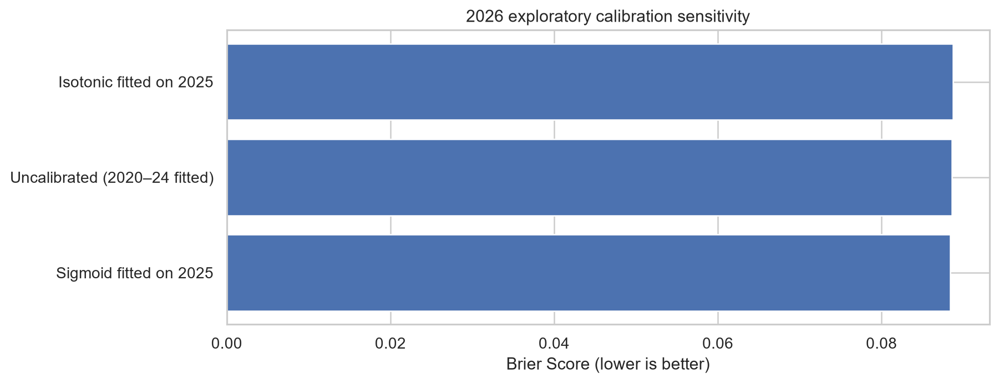

WindowsPath('I:/Potforlio/MLB Analytics/outputs/history_2015_2026/sample/submission_v10/78_retro_calibration.png')

In [235]:
from scipy.special import logit, expit
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, average_precision_score, log_loss
base_fit = models_history[selected_history_model]  # fitted only through 2024
p_cal = np.clip(base_fit.predict_proba(validation_history[model_features])[:,1],1e-5,1-1e-5)
p_future = np.clip(base_fit.predict_proba(test_history[model_features])[:,1],1e-5,1-1e-5)
y_cal = validation_history.is_whiff.to_numpy(dtype=int)
y_future = test_history.is_whiff.to_numpy(dtype=int)
sigmoid = LogisticRegression(max_iter=500).fit(logit(p_cal).reshape(-1,1),y_cal)
isotonic = IsotonicRegression(out_of_bounds='clip').fit(p_cal,y_cal)
variants = {'Uncalibrated (2020–24 fitted)':p_future,
            'Sigmoid fitted on 2025':sigmoid.predict_proba(logit(p_future).reshape(-1,1))[:,1],
            'Isotonic fitted on 2025':isotonic.predict(p_future)}
cal_rows=[]
for label,p in variants.items():
    cal_rows.append({'calibration':label,'n':len(y_future),
                     'Brier':brier_score_loss(y_future,p),
                     'PR_AUC':average_precision_score(y_future,p),
                     'LogLoss':log_loss(y_future,np.clip(p,1e-6,1-1e-6))})
cal_report=pd.DataFrame(cal_rows).sort_values('Brier')
display(cal_report.round(4))
cal_report.to_csv(V10_DIR/'retrospective_calibration_2026.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4))
ax.barh(cal_report.calibration,cal_report.Brier)
ax.set(title='2026 exploratory calibration sensitivity',xlabel='Brier Score (lower is better)')
submission_plot(fig,'78_retro_calibration')

### Part 79 | Scientific evidence ledger

This gate records how much data was truly analyzed and distinguishes **sample-week observations** from hypothetical season-wide claims. It does not label any season as an untouched test when its results have been inspected.

In [236]:
import json
submission_manifest = {
 'project':'MLB Statcast: Comprehensive Baseball Analytics & Predictive Modeling',
 'historical_mode':HISTORY_MODE,
 'historical_years':list(map(int,annual.season.tolist())),
 'observed_pitches':int(annual.pitches.sum()),
 'collection_dates':'August 10–16, each season' if HISTORY_MODE=='sample' else 'Full regular-season window per year',
 '2025_role':'Retrospective validation used during development',
 '2026_role':'Exploratory evaluation viewed during repeated revisions',
 'post_release_features':'Release speed/spin, trajectory and plate position are not known strictly before release',
 'measurement_break':'Statcast plate_x/plate_z reference changes in 2026; compare spatial features cautiously',
 'observational_limitation':'Pitch decisions are confounded; no causal recommendation asserted',
 'additional_figures':len(list(V10_DIR.glob('*.png')))
}
(V10_DIR/'submission_evidence_manifest.json').write_text(json.dumps(submission_manifest,indent=2),encoding='utf-8')
display(pd.DataFrame([{'field':k,'value':str(v)} for k,v in submission_manifest.items()]))

,field,value
0,project,MLB Statcast: Comprehensive Baseball Analytics...
1,historical_mode,sample
2,historical_years,"[2015, 2016, 2017, 2018, 2019, 2020, 2021, 202..."
3,observed_pitches,332598
4,collection_dates,"August 10–16, each season"
5,2025_role,Retrospective validation used during development
6,2026_role,Exploratory evaluation viewed during repeated ...
7,post_release_features,"Release speed/spin, trajectory and plate posit..."
8,measurement_break,Statcast plate_x/plate_z reference changes in ...
9,observational_limitation,Pitch decisions are confounded; no causal reco...


## Conclusions and next-stage research

The historical results are currently **seven-day cross-sectional comparisons**, not full-season averages. Hitter/pitcher trend estimates are susceptible to roster turnover and survivor effects; opponent quality, park, weather and tracking-era changes remain important confounders. Probability models trained with measured trajectory variables are descriptive **post-release** classifiers. The 2026 results shown in earlier versions have been inspected and are **exploratory**.

A defensible full-season submission requires: (1) `HISTORY_MODE="full"`, (2) validation of all twelve years and field coverage, (3) rerunning the technical notebook, (4) rewriting the summary using actual full-season output, and (5) reserving a newly untouched future period for any final performance claim. The standalone HTML report in the project root reports the completed sample-week study using executed results.